In [ ]:
# Bloque 0: Carga rápida de tablas procesadas del EDA
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
from IPython.display import display

directorio_actual = Path.cwd().resolve()
raiz_proyecto = next(
    (
        carpeta
        for carpeta in [directorio_actual, *directorio_actual.parents]
        if (carpeta / "data" / "raw" / "DATASET_RETO_AGRO_2026").is_dir()
        and (carpeta / "src").is_dir()
    ),
    directorio_actual.parent if directorio_actual.name == "notebooks" else directorio_actual,
)

carpeta_datos = raiz_proyecto / "data" / "raw" / "DATASET_RETO_AGRO_2026"
carpeta_procesados = raiz_proyecto / "data" / "processed"

def _buscar_tabla(nombre_archivo: str) -> Path:
    for carpeta in [carpeta_procesados, raiz_proyecto / "notebooks" / "01_eda_erick", raiz_proyecto / "notebooks", directorio_actual]:
        candidato = carpeta / nombre_archivo
        if candidato.is_file():
            return candidato
    coincidencias = sorted(raiz_proyecto.rglob(nombre_archivo))
    if coincidencias:
        return coincidencias[0]
    raise FileNotFoundError(f"No se encontró {nombre_archivo}. Ejecuta primero 01_eda_erick.ipynb.")

# 1. Cargar tablas maestras del ciclo (33 vars) y mensual (213 vars)
df_eda_parcela = pd.read_csv(_buscar_tabla("tabla_integrada_parcela_ciclo_2025.csv"))
df_parcela_meses = pd.read_csv(_buscar_tabla("tabla_parcela_meses_2025_sin_imputar.csv"))
diccionario_tabla_mensual = pd.read_csv(_buscar_tabla("diccionario_tabla_parcela_meses_2025.csv"))

columnas_predictoras_eda = [
    c for c in df_eda_parcela.columns
    if c not in ("ID_POLIGONO", "RENDIMIENTO_T_HA", "CONJUNTO")
    and not c.endswith("__meses_disponibles")
]

columnas_mediciones_candidatas = (
    diccionario_tabla_mensual.loc[
        diccionario_tabla_mensual["categoria"].isin(["estaticas", "clima_mensual", "indices_mensuales"]),
        "columna",
    ].tolist()
)

df_parcela_meses_base = df_parcela_meses.drop(
    columns=["AREA_HA", "CONJUNTO", "RENDIMIENTO_T_HA", "elevacion_m", "pendiente_grados"],
    errors="ignore",
).copy()

# 2. Cargar geometrías y tabla de rendimiento original
rutas_shapefile = sorted(carpeta_datos.rglob("Parcelas_Reto_AGC_CONJUNTO.shp"))
gdf_parcelas_original = gpd.read_file(rutas_shapefile[0]) if rutas_shapefile else None

ruta_rend = next(carpeta_datos.rglob("ID_area_rendimiento_70_30_Reto_AgroCebada.csv"), None)
if ruta_rend is not None:
    df_rendimiento_original = pd.read_csv(ruta_rend)
    df_rendimiento = df_rendimiento_original.drop(columns=["Unnamed: 4"], errors="ignore").copy()

# 3. Cargar tablas auxiliares si existen en data/processed/ (para bloques 56, 57, 60A, 63B y 65)
for nombre_var, archivo_pq in [
    ("df_base_mensual", "df_base_mensual.parquet"),
    ("df_clima_mensual", "df_clima_mensual.parquet"),
    ("df_basico_preparado", "df_basico_preparado.parquet"),
    ("df_pro_preparado", "df_pro_preparado.parquet"),
]:
    ruta_pq = carpeta_procesados / archivo_pq
    if ruta_pq.is_file():
        globals()[nombre_var] = pd.read_parquet(ruta_pq)

print(f"Raíz del proyecto: {raiz_proyecto}")
print(f"df_eda_parcela cargado: {df_eda_parcela.shape} | Predictoras ciclo: {len(columnas_predictoras_eda)}")
print(f"df_parcela_meses cargado: {df_parcela_meses.shape} | Predictoras mensuales: {len(columnas_mediciones_candidatas)}")


In [47]:
# Bloque 37: Alinear las representaciones del ciclo y mensual
# usando las mismas parcelas con rendimiento conocido.

columna_id = "ID_POLIGONO"
objetivo = "RENDIMIENTO_T_HA"

columnas_version_ciclo = list(columnas_predictoras_eda)
columnas_version_mensual = list(columnas_mediciones_candidatas)

for nombre, tabla in {
    "resumen del ciclo": df_eda_parcela,
    "meses separados": df_parcela_meses,
}.items():
    assert tabla[columna_id].notna().all(), (
        f"Hay identificadores vacíos en {nombre}."
    )
    assert tabla[columna_id].is_unique, (
        f"Hay parcelas repetidas en {nombre}."
    )

    assert tabla["CONJUNTO"].isin(
        ["ENTRENAMIENTO", "PREDICCION"]
    ).all(), f"Hay conjuntos inesperados en {nombre}."

    assert tabla.loc[
        tabla["CONJUNTO"].eq("ENTRENAMIENTO"), objetivo
    ].notna().all(), (
        f"Hay parcelas de entrenamiento sin rendimiento en {nombre}."
    )

    assert tabla.loc[
        tabla["CONJUNTO"].eq("PREDICCION"), objetivo
    ].isna().all(), (
        f"Hay parcelas de predicción con rendimiento en {nombre}."
    )

# Crear copias con un identificador de texto consistente.
tabla_ciclo_comparacion = df_eda_parcela.copy()
tabla_mensual_comparacion = df_parcela_meses.copy()

for tabla in [tabla_ciclo_comparacion, tabla_mensual_comparacion]:
    tabla[columna_id] = tabla[columna_id].astype(str)

ids_ciclo = set(
    tabla_ciclo_comparacion.loc[
        tabla_ciclo_comparacion[objetivo].notna(),
        columna_id
    ]
)

ids_mensuales = set(
    tabla_mensual_comparacion.loc[
        tabla_mensual_comparacion[objetivo].notna(),
        columna_id
    ]
)

assert ids_ciclo == ids_mensuales, (
    "Las versiones no tienen las mismas parcelas etiquetadas."
)

ids_comparacion = sorted(ids_ciclo)

datos_ciclo_comparacion = (
    tabla_ciclo_comparacion
    .set_index(columna_id)
    .loc[ids_comparacion]
)

datos_mensuales_comparacion = (
    tabla_mensual_comparacion
    .set_index(columna_id)
    .loc[ids_comparacion]
)

# Confirmar que ambas versiones contienen los mismos rendimientos.
pd.testing.assert_series_equal(
    datos_ciclo_comparacion[objetivo].astype(float),
    datos_mensuales_comparacion[objetivo].astype(float)
)

pd.testing.assert_series_equal(
    datos_ciclo_comparacion["CONJUNTO"].astype(str),
    datos_mensuales_comparacion["CONJUNTO"].astype(str)
)

# Excluir explícitamente identificadores, conjunto y objetivo.
columnas_prohibidas = {columna_id, "CONJUNTO", objetivo}

for columnas in [columnas_version_ciclo, columnas_version_mensual]:
    assert not columnas_prohibidas.intersection(columnas)
    assert len(columnas) == len(set(columnas))

X_ciclo = datos_ciclo_comparacion[
    columnas_version_ciclo
].apply(pd.to_numeric, errors="raise").astype(float)

X_mensual = datos_mensuales_comparacion[
    columnas_version_mensual
].apply(pd.to_numeric, errors="raise").astype(float)

y_comparacion = datos_ciclo_comparacion[objetivo].astype(float)

assert X_ciclo.index.equals(X_mensual.index)
assert X_ciclo.index.equals(y_comparacion.index)

resumen_alineacion = pd.DataFrame([
    {
        "version": "resumen_ciclo",
        "parcelas_etiquetadas": len(X_ciclo),
        "variables_candidatas": X_ciclo.shape[1],
        "celdas_NA": int(X_ciclo.isna().sum().sum()),
        "parcelas_con_algun_NA": int(
            X_ciclo.isna().any(axis=1).sum()
        ),
    },
    {
        "version": "meses_separados",
        "parcelas_etiquetadas": len(X_mensual),
        "variables_candidatas": X_mensual.shape[1],
        "celdas_NA": int(X_mensual.isna().sum().sum()),
        "parcelas_con_algun_NA": int(
            X_mensual.isna().any(axis=1).sum()
        ),
    },
])

print("Representaciones alineadas:")
display(resumen_alineacion)

print("\nPrimeras parcelas y rendimiento compartido:")
display(y_comparacion.head().to_frame())

print(
    "\nSe crearon X_ciclo, X_mensual y y_comparacion."
    "\nNo se imputaron valores ni se entrenaron modelos."
    "\nLas tablas originales permanecen sin cambios."
)


Representaciones alineadas:


,version,parcelas_etiquetadas,variables_candidatas,celdas_NA,parcelas_con_algun_NA
0,resumen_ciclo,138,33,0,0
1,meses_separados,138,213,7,7



Primeras parcelas y rendimiento compartido:


,RENDIMIENTO_T_HA
ID_POLIGONO,
AGC_001,3.50
AGC_002,4.63
AGC_004,3.00
AGC_005,5.16
AGC_006,4.49



Se crearon X_ciclo, X_mensual y y_comparacion.
No se imputaron valores ni se entrenaron modelos.
Las tablas originales permanecen sin cambios.


In [48]:
# Bloque 38: Crear particiones espaciales compartidas por ambas versiones.

import numpy as np
from sklearn.cluster import KMeans
from sklearn.model_selection import GroupKFold

semilla_validacion = 0
n_bloques_espaciales = 10
n_particiones_espaciales = 5

assert X_ciclo.index.equals(X_mensual.index)
assert X_ciclo.index.equals(y_comparacion.index)
assert y_comparacion.index.is_unique

# 1. Preparar una copia de las geometrías de las parcelas etiquetadas.
geometrias_validacion = (
    gdf_parcelas_original[["ID_POLIGON", "geometry"]]
    .rename(columns={"ID_POLIGON": "ID_POLIGONO"})
    .copy()
)

geometrias_validacion["ID_POLIGONO"] = (
    geometrias_validacion["ID_POLIGONO"].astype(str)
)

assert geometrias_validacion["ID_POLIGONO"].is_unique
assert geometrias_validacion.crs is not None

assert set(y_comparacion.index).issubset(
    set(geometrias_validacion["ID_POLIGONO"])
), "Faltan geometrías de alguna parcela etiquetada."

geometrias_validacion = (
    geometrias_validacion
    .set_index("ID_POLIGONO")
    .loc[y_comparacion.index]
    .copy()
)

assert geometrias_validacion.geometry.notna().all()
assert (~geometrias_validacion.geometry.is_empty).all()
assert geometrias_validacion.geometry.is_valid.all(), (
    "Hay geometrías inválidas; revisarlas antes de continuar."
)

# 2. Calcular centroides en coordenadas métricas.
crs_validacion = geometrias_validacion.estimate_utm_crs()

assert crs_validacion is not None, (
    "No se pudo determinar una proyección UTM."
)

geometrias_validacion_utm = geometrias_validacion.to_crs(
    crs_validacion
)

centroides_validacion = geometrias_validacion_utm.geometry.centroid

coordenadas_validacion = pd.DataFrame({
    "coord_x_m": centroides_validacion.x,
    "coord_y_m": centroides_validacion.y,
}, index=y_comparacion.index)

assert np.isfinite(coordenadas_validacion.to_numpy()).all()

# 3. Construir grupos sin utilizar rendimiento.
agrupador_espacial = KMeans(
    n_clusters=n_bloques_espaciales,
    n_init=10,
    random_state=semilla_validacion
)

grupos_espaciales = pd.Series(
    agrupador_espacial.fit_predict(coordenadas_validacion),
    index=y_comparacion.index,
    name="bloque_espacial"
)

assert grupos_espaciales.nunique() == n_bloques_espaciales

# 4. Materializar una sola lista de particiones para ambos modelos.
cv_espacial = GroupKFold(n_splits=n_particiones_espaciales)

particiones_espaciales = list(
    cv_espacial.split(
        X_ciclo,
        y_comparacion,
        groups=grupos_espaciales
    )
)

fold_validacion = pd.Series(
    -1,
    index=y_comparacion.index,
    name="fold_validacion"
)

veces_en_validacion = np.zeros(len(y_comparacion), dtype=int)
filas_resumen_particiones = []

for fold, (indices_train, indices_val) in enumerate(
    particiones_espaciales,
    start=1
):
    bloques_train = set(grupos_espaciales.iloc[indices_train])
    bloques_val = set(grupos_espaciales.iloc[indices_val])

    assert bloques_train.isdisjoint(bloques_val)
    assert set(indices_train).isdisjoint(indices_val)

    fold_validacion.iloc[indices_val] = fold
    veces_en_validacion[indices_val] += 1

    filas_resumen_particiones.append({
        "fold": fold,
        "parcelas_train": len(indices_train),
        "parcelas_validacion": len(indices_val),
        "bloques_train": len(bloques_train),
        "bloques_validacion": len(bloques_val),
        "NA_mensuales_train": int(
            X_mensual.iloc[indices_train].isna().sum().sum()
        ),
        "NA_mensuales_validacion": int(
            X_mensual.iloc[indices_val].isna().sum().sum()
        ),
    })

assert (veces_en_validacion == 1).all(), (
    "Cada parcela debe aparecer exactamente una vez en validación."
)

asignacion_validacion_espacial = (
    coordenadas_validacion
    .join(grupos_espaciales)
    .join(fold_validacion)
)

resumen_particiones_espaciales = pd.DataFrame(
    filas_resumen_particiones
)

resumen_bloques_espaciales = (
    asignacion_validacion_espacial
    .groupby(["bloque_espacial", "fold_validacion"])
    .size()
    .rename("parcelas")
    .reset_index()
)

print(f"Proyección utilizada: {crs_validacion}")

print("\nParticiones compartidas por ambas representaciones:")
display(resumen_particiones_espaciales)

print("\nTamaño de los grupos geográficos:")
display(resumen_bloques_espaciales)

print(
    "\nSe creó particiones_espaciales para reutilizarla en ambas versiones."
    "\nNo se añadieron coordenadas a los predictores."
    "\nNo se imputaron valores ni se entrenaron modelos de rendimiento."
)

Proyección utilizada: EPSG:32614

Particiones compartidas por ambas representaciones:


,fold,parcelas_train,parcelas_validacion,bloques_train,bloques_validacion,NA_mensuales_train,NA_mensuales_validacion
0,1,107,31,9,1,7,0
1,2,112,26,8,2,7,0
2,3,111,27,7,3,7,0
3,4,111,27,8,2,7,0
4,5,111,27,8,2,0,7



Tamaño de los grupos geográficos:


,bloque_espacial,fold_validacion,parcelas
0,0,5,11
1,1,2,23
2,2,5,16
3,3,4,20
4,4,2,3
5,5,3,21
6,6,1,31
7,7,3,4
8,8,4,7
9,9,3,2



Se creó particiones_espaciales para reutilizarla en ambas versiones.
No se añadieron coordenadas a los predictores.
No se imputaron valores ni se entrenaron modelos de rendimiento.


In [49]:
# Bloque 39: Comparar baseline y ambas representaciones
# utilizando las mismas particiones espaciales.

import numpy as np
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import make_pipeline

assert X_ciclo.index.equals(X_mensual.index)
assert X_ciclo.index.equals(y_comparacion.index)

configuracion_rf = {
    "n_estimators": 500,
    "min_samples_leaf": 3,
    "max_features": 0.5,
    "random_state": 0,
    "n_jobs": -1,
}

experimentos_comparacion = {
    "baseline_media": (
        X_ciclo,
        DummyRegressor(strategy="mean")
    ),
    "rf_resumen_ciclo": (
        X_ciclo,
        make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(**configuracion_rf)
        )
    ),
    "rf_meses_separados": (
        X_mensual,
        make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(**configuracion_rf)
        )
    ),
}

predicciones_oof_comparacion = pd.DataFrame(
    {"rendimiento_observado": y_comparacion}
)

filas_metricas_folds = []

for nombre, (X, modelo_base) in experimentos_comparacion.items():
    predicciones = np.full(len(y_comparacion), np.nan)

    for fold, (indices_train, indices_val) in enumerate(
        particiones_espaciales,
        start=1
    ):
        X_train = X.iloc[indices_train]
        X_val = X.iloc[indices_val]

        y_train = y_comparacion.iloc[indices_train]
        y_val = y_comparacion.iloc[indices_val]

        assert not X_train.isna().all(axis=0).any(), (
            f"Hay una columna completamente vacía en "
            f"{nombre}, fold {fold}."
        )

        modelo_fold = clone(modelo_base)
        modelo_fold.fit(X_train, y_train)

        pred_val = modelo_fold.predict(X_val)
        pred_train = modelo_fold.predict(X_train)

        predicciones[indices_val] = pred_val

        filas_metricas_folds.append({
            "modelo": nombre,
            "fold": fold,
            "n_train": len(indices_train),
            "n_validacion": len(indices_val),
            "MAE_val": mean_absolute_error(y_val, pred_val),
            "RMSE_val": (
                mean_squared_error(y_val, pred_val) ** 0.5
            ),
            "R2_val": r2_score(y_val, pred_val),
            "R2_train": r2_score(y_train, pred_train),
        })

    assert np.isfinite(predicciones).all(), (
        f"Faltan predicciones fuera de muestra para {nombre}."
    )

    predicciones_oof_comparacion[nombre] = predicciones
    print(f"Finalizado: {nombre}")

metricas_folds_comparacion = pd.DataFrame(filas_metricas_folds)

filas_resumen_modelos = []

for nombre in experimentos_comparacion:
    resultados = metricas_folds_comparacion.loc[
        metricas_folds_comparacion["modelo"].eq(nombre)
    ]

    pred_oof = predicciones_oof_comparacion[nombre]

    filas_resumen_modelos.append({
        "modelo": nombre,
        "MAE_OOF": mean_absolute_error(y_comparacion, pred_oof),
        "RMSE_OOF": (
            mean_squared_error(y_comparacion, pred_oof) ** 0.5
        ),
        "R2_OOF": r2_score(y_comparacion, pred_oof),
        "MAE_media_folds": resultados["MAE_val"].mean(),
        "RMSE_media_folds": resultados["RMSE_val"].mean(),
        "R2_media_folds": resultados["R2_val"].mean(),
        "R2_train_media_folds": resultados["R2_train"].mean(),
    })

resumen_modelos_comparacion = pd.DataFrame(filas_resumen_modelos)

rmse_baseline = resumen_modelos_comparacion.loc[
    resumen_modelos_comparacion["modelo"].eq("baseline_media"),
    "RMSE_OOF"
].iloc[0]

resumen_modelos_comparacion["reduccion_RMSE_vs_baseline_pct"] = (
    100 * (
        1 - resumen_modelos_comparacion["RMSE_OOF"] / rmse_baseline
    )
)

print("\nResumen de la comparación:")
display(resumen_modelos_comparacion)

print("\nResultados por partición:")
display(metricas_folds_comparacion)

print(
    "\nOOF: predicciones de parcelas no utilizadas para entrenar "
    "el modelo que las predice."
    "\nLa imputación por mediana se ajustó dentro de cada fold."
    "\nNo se aplicó Ridge ni se modificaron las tablas originales."
    "\nNo se entrenó todavía un modelo final para las 59 parcelas."
)

Finalizado: baseline_media
Finalizado: rf_resumen_ciclo
Finalizado: rf_meses_separados

Resumen de la comparación:


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,MAE_media_folds,RMSE_media_folds,R2_media_folds,R2_train_media_folds,reduccion_RMSE_vs_baseline_pct
0,baseline_media,0.857892,0.958918,-0.278494,0.864235,0.951172,-2.379805,0.000000,0.000000
1,rf_resumen_ciclo,0.595045,0.745641,0.226973,0.598872,0.731870,-1.107188,0.867958,22.241476
2,rf_meses_separados,0.504797,0.678088,0.360696,0.508737,0.667724,-0.830631,0.893659,29.286163



Resultados por partición:


,modelo,fold,n_train,n_validacion,MAE_val,RMSE_val,R2_val,R2_train
0,baseline_media,1,107,31,0.637715,0.715691,-0.709800,0.000000
1,baseline_media,2,112,26,0.833599,0.917811,-1.450597,0.000000
2,baseline_media,3,111,27,0.766446,0.878798,-1.064740,0.000000
3,baseline_media,4,111,27,0.955529,1.046108,-0.809372,0.000000
4,baseline_media,5,111,27,1.127888,1.197450,-7.864515,0.000000
5,rf_resumen_ciclo,1,107,31,0.433783,0.588355,-0.155506,0.896561
6,rf_resumen_ciclo,2,112,26,0.466655,0.603824,-0.060684,0.877080
7,rf_resumen_ciclo,3,111,27,0.507242,0.634444,-0.076150,0.868693
8,rf_resumen_ciclo,4,111,27,0.742875,0.841647,-0.171209,0.853822
9,rf_resumen_ciclo,5,111,27,0.843803,0.991082,-5.072388,0.843632



OOF: predicciones de parcelas no utilizadas para entrenar el modelo que las predice.
La imputación por mediana se ajustó dentro de cada fold.
No se aplicó Ridge ni se modificaron las tablas originales.
No se entrenó todavía un modelo final para las 59 parcelas.


In [50]:
# Bloque 40: Diagnosticar errores OOF por fold y disponibilidad de VI6T.

diagnostico_oof = (
    predicciones_oof_comparacion
    .join(asignacion_validacion_espacial[
        ["bloque_espacial", "fold_validacion"]
    ])
)

assert diagnostico_oof.index.equals(X_mensual.index)
assert diagnostico_oof["fold_validacion"].notna().all()

diagnostico_oof["tiene_NA_mensual"] = (
    X_mensual.isna().any(axis=1)
)

diagnostico_oof["error_mensual"] = (
    diagnostico_oof["rf_meses_separados"]
    - diagnostico_oof["rendimiento_observado"]
)

diagnostico_oof["error_absoluto_mensual"] = (
    diagnostico_oof["error_mensual"].abs()
)

# 1. Distribución del rendimiento y sesgo por fold.
filas_diagnostico_folds = []

for fold, (indices_train, indices_val) in enumerate(
    particiones_espaciales,
    start=1
):
    y_train = y_comparacion.iloc[indices_train]
    y_val = y_comparacion.iloc[indices_val]

    casos = diagnostico_oof.iloc[indices_val]

    filas_diagnostico_folds.append({
        "fold": fold,
        "n_validacion": len(casos),
        "rendimiento_medio_train": y_train.mean(),
        "rendimiento_medio_val": y_val.mean(),
        "rendimiento_std_val": y_val.std(ddof=0),
        "rendimiento_min_val": y_val.min(),
        "rendimiento_max_val": y_val.max(),
        "prediccion_media_mensual": (
            casos["rf_meses_separados"].mean()
        ),
        "sesgo_mensual_pred_menos_real": (
            casos["error_mensual"].mean()
        ),
    })

diagnostico_por_fold = pd.DataFrame(filas_diagnostico_folds)

# 2. Separar dentro del fold 5 los casos con y sin faltantes.
casos_fold_5 = diagnostico_oof.loc[
    diagnostico_oof["fold_validacion"].eq(5)
].copy()

filas_cobertura_fold_5 = []

for tiene_na, casos in casos_fold_5.groupby("tiene_NA_mensual"):
    errores = casos["error_mensual"]

    filas_cobertura_fold_5.append({
        "tiene_NA_mensual": tiene_na,
        "parcelas": len(casos),
        "rendimiento_medio": (
            casos["rendimiento_observado"].mean()
        ),
        "MAE_mensual": errores.abs().mean(),
        "RMSE_mensual": errores.pow(2).mean() ** 0.5,
        "sesgo_pred_menos_real": errores.mean(),
    })

diagnostico_cobertura_fold_5 = pd.DataFrame(
    filas_cobertura_fold_5
)

# 3. Identificar los mayores errores.
mayores_errores_mensuales = (
    diagnostico_oof
    .sort_values("error_absoluto_mensual", ascending=False)
    .head(15)
    .reset_index()
)

print("Distribución del rendimiento y sesgo por fold:")
display(diagnostico_por_fold)

print("\nFold 5: casos con y sin faltantes mensuales:")
display(diagnostico_cobertura_fold_5)

print("\nQuince mayores errores del modelo mensual:")
display(mayores_errores_mensuales)

print(
    "\nNo se entrenaron nuevos modelos ni se modificaron particiones."
    "\nLa comparación con/sin NA es descriptiva, no demuestra "
    "un efecto causal de los faltantes."
)


Distribución del rendimiento y sesgo por fold:


,fold,n_validacion,rendimiento_medio_train,rendimiento_medio_val,rendimiento_std_val,rendimiento_min_val,rendimiento_max_val,prediccion_media_mensual,sesgo_mensual_pred_menos_real
0,1,31,3.851776,4.312903,0.547335,2.15,5.01,4.392970,0.080066
1,2,26,3.822321,4.528462,0.586297,2.64,5.46,4.468351,-0.060110
2,3,27,3.831892,4.462963,0.611585,3.00,5.59,3.990900,-0.472063
3,4,27,4.092252,3.392593,0.777701,2.50,4.87,3.807634,0.415041
4,5,27,4.176036,3.048148,0.402189,2.00,3.70,3.658857,0.610709



Fold 5: casos con y sin faltantes mensuales:


,tiene_NA_mensual,parcelas,rendimiento_medio,MAE_mensual,RMSE_mensual,sesgo_pred_menos_real
0,False,20,3.03,0.674047,0.850573,0.543313
1,True,7,3.10,0.999310,1.121410,0.803271



Quince mayores errores del modelo mensual:


,ID_POLIGONO,rendimiento_observado,baseline_media,rf_resumen_ciclo,rf_meses_separados,bloque_espacial,fold_validacion,tiene_NA_mensual,error_mensual,error_absoluto_mensual
0,AGC_171,2.15,3.851776,4.121490,4.399210,6,1,False,2.249210,2.249210
1,AGC_034,2.00,4.176036,3.988908,4.055031,2,5,True,2.055031,2.055031
2,AGC_041,2.50,4.176036,4.104724,4.439811,2,5,False,1.939811,1.939811
3,AGC_015,2.64,3.822321,4.407169,4.537534,1,2,False,1.897534,1.897534
4,AGC_166,2.50,4.176036,4.119146,4.311044,2,5,False,1.811044,1.811044
5,AGC_162,5.59,3.831892,4.313171,3.959928,5,3,False,-1.630072,1.630072
6,AGC_024,3.03,3.851776,4.433263,4.457218,6,1,False,1.427218,1.427218
7,AGC_127,5.57,3.831892,4.286401,4.354369,5,3,False,-1.215631,1.215631
8,AGC_067,3.00,4.176036,4.557883,4.212525,2,5,True,1.212525,1.212525
9,AGC_078,3.00,4.176036,4.333634,4.192874,2,5,True,1.192874,1.192874



No se entrenaron nuevos modelos ni se modificaron particiones.
La comparación con/sin NA es descriptiva, no demuestra un efecto causal de los faltantes.


In [51]:
# Bloque 41: Comparar el modelo mensual con y sin VI6T.

import numpy as np
from sklearn.base import clone
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import make_pipeline

columnas_vi6t_mensual = [
    c for c in X_mensual.columns
    if c.startswith("basico_landsat__vi6t__media_mensual__")
]

assert len(columnas_vi6t_mensual) == 7, (
    "Se esperaban siete columnas mensuales de VI6T."
)

X_mensual_sin_vi6t = X_mensual.drop(
    columns=columnas_vi6t_mensual
).copy()

assert not X_mensual_sin_vi6t.isna().any().any(), (
    "Hay faltantes adicionales fuera de VI6T."
)

assert X_mensual_sin_vi6t.index.equals(y_comparacion.index)

modelo_sin_vi6t = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(**configuracion_rf)
)

pred_sin_vi6t = np.full(len(y_comparacion), np.nan)
filas_ablacion_folds = []

for fold, (indices_train, indices_val) in enumerate(
    particiones_espaciales,
    start=1
):
    modelo_fold = clone(modelo_sin_vi6t)

    modelo_fold.fit(
        X_mensual_sin_vi6t.iloc[indices_train],
        y_comparacion.iloc[indices_train]
    )

    pred_val = modelo_fold.predict(
        X_mensual_sin_vi6t.iloc[indices_val]
    )

    pred_sin_vi6t[indices_val] = pred_val

    observado = y_comparacion.iloc[indices_val]

    pred_con_vi6t = predicciones_oof_comparacion[
        "rf_meses_separados"
    ].iloc[indices_val]

    errores_sin = pred_val - observado.to_numpy()
    errores_con = pred_con_vi6t.to_numpy() - observado.to_numpy()

    filas_ablacion_folds.append({
        "fold": fold,
        "n_validacion": len(indices_val),
        "MAE_con_VI6T": np.abs(errores_con).mean(),
        "MAE_sin_VI6T": np.abs(errores_sin).mean(),
        "RMSE_con_VI6T": np.sqrt(np.mean(errores_con ** 2)),
        "RMSE_sin_VI6T": np.sqrt(np.mean(errores_sin ** 2)),
        "sesgo_con_VI6T": errores_con.mean(),
        "sesgo_sin_VI6T": errores_sin.mean(),
    })

assert np.isfinite(pred_sin_vi6t).all()

predicciones_oof_ablacion = pd.DataFrame({
    "observado": y_comparacion,
    "con_VI6T": predicciones_oof_comparacion[
        "rf_meses_separados"
    ],
    "sin_VI6T": pred_sin_vi6t,
})

filas_resumen_ablacion = []

for version, n_variables in [
    ("con_VI6T", X_mensual.shape[1]),
    ("sin_VI6T", X_mensual_sin_vi6t.shape[1]),
]:
    pred = predicciones_oof_ablacion[version]
    error = pred - y_comparacion

    filas_resumen_ablacion.append({
        "version": version,
        "variables": n_variables,
        "MAE_OOF": mean_absolute_error(y_comparacion, pred),
        "RMSE_OOF": mean_squared_error(
            y_comparacion, pred
        ) ** 0.5,
        "R2_OOF": r2_score(y_comparacion, pred),
        "sesgo_pred_menos_real": error.mean(),
    })

resumen_ablacion_vi6t = pd.DataFrame(filas_resumen_ablacion)
ablacion_vi6t_por_fold = pd.DataFrame(filas_ablacion_folds)

print("Comparación global con y sin VI6T:")
display(resumen_ablacion_vi6t)

print("\nComparación por fold:")
display(ablacion_vi6t_por_fold)

print(
    "\nNo se modificó la tabla mensual original."
    "\nSe mantuvieron parcelas, particiones y configuración del bosque."
    "\nNo se aplicó reconstrucción Ridge."
)

Comparación global con y sin VI6T:


,version,variables,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real
0,con_VI6T,213,0.504797,0.678088,0.360696,0.114991
1,sin_VI6T,206,0.510262,0.685927,0.345830,0.134418



Comparación por fold:


,fold,n_validacion,MAE_con_VI6T,MAE_sin_VI6T,RMSE_con_VI6T,RMSE_sin_VI6T,sesgo_con_VI6T,sesgo_sin_VI6T
0,1,31,0.355743,0.352799,0.560380,0.567503,0.080066,0.109389
1,2,26,0.440508,0.443436,0.612896,0.609772,-0.060110,-0.071006
2,3,27,0.513681,0.486559,0.639466,0.609128,-0.472063,-0.443356
3,4,27,0.475379,0.492739,0.597471,0.612504,0.415041,0.430896
4,5,27,0.758375,0.796630,0.928408,0.964745,0.610709,0.642264



No se modificó la tabla mensual original.
Se mantuvieron parcelas, particiones y configuración del bosque.
No se aplicó reconstrucción Ridge.


In [52]:
#Instalar XGBoost
import importlib.util
import subprocess
import sys

if importlib.util.find_spec("xgboost") is None:
    print("xgboost no está instalado. Instalándolo ahora...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "xgboost"]
    )

In [53]:
# Bloque 42: Evaluar XGBoost sobre ambas representaciones
# con las mismas particiones espaciales del bloque 38.

import numpy as np


import xgboost
from xgboost import XGBRegressor
from xgboost import XGBRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

# Si falta la biblioteca, instalarla en otra celda:
# %pip install xgboost

assert X_ciclo.index.equals(X_mensual.index)
assert X_ciclo.index.equals(y_comparacion.index)
assert y_comparacion.notna().all()

configuracion_xgb = {
    "objective": "reg:squarederror",
    "booster": "gbtree",
    "n_estimators": 400,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.7,
    "reg_lambda": 5.0,
    "random_state": 0,
    "n_jobs": -1,
    "missing": np.nan,
}

representaciones_xgb = {
    "xgb_resumen_ciclo": X_ciclo,
    "xgb_meses_separados": X_mensual,
}

predicciones_oof_xgb = pd.DataFrame(
    {"rendimiento_observado": y_comparacion}
)

filas_metricas_xgb = []

for nombre, X in representaciones_xgb.items():
    assert not np.isinf(X.to_numpy(dtype=float)).any(), (
        f"Hay valores infinitos en {nombre}."
    )

    predicciones = np.full(len(y_comparacion), np.nan)
    veces_predichas = np.zeros(len(y_comparacion), dtype=int)

    for fold, (indices_train, indices_val) in enumerate(
        particiones_espaciales,
        start=1
    ):
        X_train = X.iloc[indices_train]
        X_val = X.iloc[indices_val]

        y_train = y_comparacion.iloc[indices_train]
        y_val = y_comparacion.iloc[indices_val]

        modelo_fold = XGBRegressor(**configuracion_xgb)
        modelo_fold.fit(X_train, y_train)

        pred_val = modelo_fold.predict(X_val)
        pred_train = modelo_fold.predict(X_train)

        predicciones[indices_val] = pred_val
        veces_predichas[indices_val] += 1

        filas_metricas_xgb.append({
            "modelo": nombre,
            "fold": fold,
            "n_train": len(indices_train),
            "n_validacion": len(indices_val),
            "MAE_val": mean_absolute_error(y_val, pred_val),
            "RMSE_val": (
                mean_squared_error(y_val, pred_val) ** 0.5
            ),
            "R2_val": r2_score(y_val, pred_val),
            "R2_train": r2_score(y_train, pred_train),
            "sesgo_pred_menos_real": (
                pred_val - y_val.to_numpy()
            ).mean(),
        })

    assert (veces_predichas == 1).all()
    assert np.isfinite(predicciones).all()

    predicciones_oof_xgb[nombre] = predicciones
    print(f"Finalizado: {nombre}")

metricas_folds_xgb = pd.DataFrame(filas_metricas_xgb)

filas_resumen_xgb = []

for nombre in representaciones_xgb:
    resultados = metricas_folds_xgb.loc[
        metricas_folds_xgb["modelo"].eq(nombre)
    ]

    pred_oof = predicciones_oof_xgb[nombre]

    filas_resumen_xgb.append({
        "modelo": nombre,
        "MAE_OOF": mean_absolute_error(
            y_comparacion, pred_oof
        ),
        "RMSE_OOF": (
            mean_squared_error(y_comparacion, pred_oof) ** 0.5
        ),
        "R2_OOF": r2_score(y_comparacion, pred_oof),
        "MAE_media_folds": resultados["MAE_val"].mean(),
        "RMSE_media_folds": resultados["RMSE_val"].mean(),
        "R2_media_folds": resultados["R2_val"].mean(),
        "R2_train_media_folds": resultados["R2_train"].mean(),
    })

resumen_xgb = pd.DataFrame(filas_resumen_xgb)

rmse_baseline_comparacion = resumen_modelos_comparacion.loc[
    resumen_modelos_comparacion["modelo"].eq("baseline_media"),
    "RMSE_OOF"
].iloc[0]

resumen_xgb["reduccion_RMSE_vs_baseline_pct"] = (
    100 * (
        1 - resumen_xgb["RMSE_OOF"] / rmse_baseline_comparacion
    )
)

# Conservar por separado los resultados anteriores.
comparacion_rf_xgb = pd.concat(
    [resumen_modelos_comparacion, resumen_xgb],
    ignore_index=True
).sort_values("RMSE_OOF").reset_index(drop=True)

print(f"\nVersión de XGBoost: {xgboost.__version__}")

print("\nComparación global:")
display(comparacion_rf_xgb)

print("\nXGBoost: resultados por partición:")
display(metricas_folds_xgb)

print(
    "\nSe reutilizaron las mismas parcelas y particiones."
    "\nNo se imputaron valores ni se aplicó reconstrucción Ridge."
    "\nNo se usó validación para early stopping."
    "\nNo se entrenó un modelo final para las 59 parcelas."
)


Finalizado: xgb_resumen_ciclo
Finalizado: xgb_meses_separados

Versión de XGBoost: 3.4.1

Comparación global:


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,MAE_media_folds,RMSE_media_folds,R2_media_folds,R2_train_media_folds,reduccion_RMSE_vs_baseline_pct
0,xgb_meses_separados,0.473144,0.636959,0.435897,0.475430,0.634592,-0.499008,0.995824,33.575263
1,rf_meses_separados,0.504797,0.678088,0.360696,0.508737,0.667724,-0.830631,0.893659,29.286163
2,rf_resumen_ciclo,0.595045,0.745641,0.226973,0.598872,0.731870,-1.107188,0.867958,22.241476
3,xgb_resumen_ciclo,0.621767,0.781536,0.150754,0.622743,0.766162,-1.180263,0.985579,18.498136
4,baseline_media,0.857892,0.958918,-0.278494,0.864235,0.951172,-2.379805,0.000000,0.000000



XGBoost: resultados por partición:


,modelo,fold,n_train,n_validacion,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real
0,xgb_resumen_ciclo,1,107,31,0.540545,0.684198,-0.562635,0.988390,-0.115161
1,xgb_resumen_ciclo,2,112,26,0.428592,0.565755,0.068845,0.984020,-0.175452
2,xgb_resumen_ciclo,3,111,27,0.513213,0.667348,-0.190671,0.986178,-0.409282
3,xgb_resumen_ciclo,4,111,27,0.827026,0.951656,-0.497387,0.984584,0.701318
4,xgb_resumen_ciclo,5,111,27,0.804335,0.961851,-4.719466,0.984720,0.722403
5,xgb_meses_separados,1,107,31,0.389147,0.585799,-0.145488,0.997090,-0.004490
6,xgb_meses_separados,2,112,26,0.445699,0.625625,-0.138659,0.995928,-0.009433
7,xgb_meses_separados,3,111,27,0.502150,0.615897,-0.014154,0.996417,-0.440795
8,xgb_meses_separados,4,111,27,0.468412,0.577815,0.447983,0.995262,0.400700
9,xgb_meses_separados,5,111,27,0.571741,0.767825,-2.644720,0.994423,0.483488



Se reutilizaron las mismas parcelas y particiones.
No se imputaron valores ni se aplicó reconstrucción Ridge.
No se usó validación para early stopping.
No se entrenó un modelo final para las 59 parcelas.


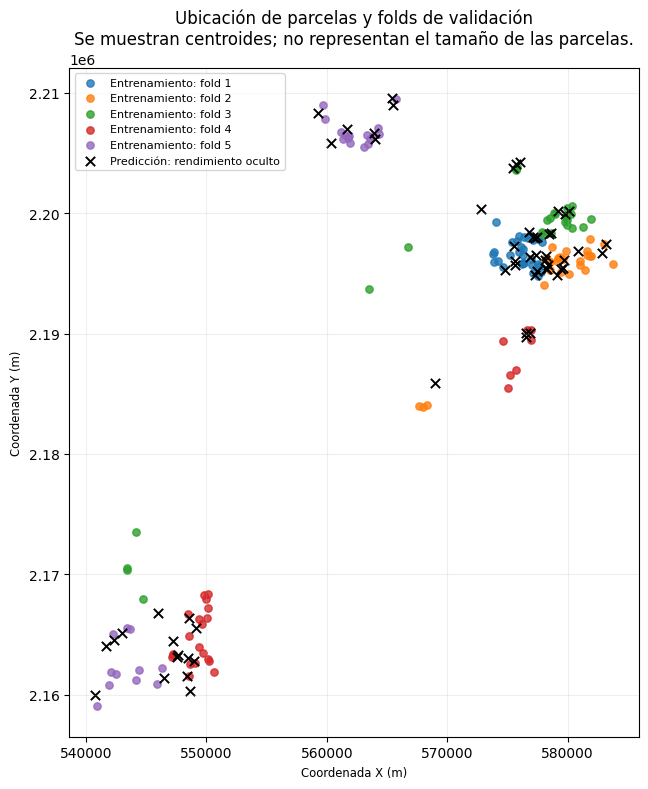

Referencia guardada en:
C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\referencia_modelos\bloque_43_20261018_230904_627365

Archivos generados:


,archivo,bytes
0,asignaciones_espaciales.csv,6872
1,configuracion.json,13677
2,mapa_folds_y_prediccion.png,142454
3,metricas_globales_y_promedios.csv,960
4,metricas_por_fold.csv,2856
5,predicciones_oof_y_folds.csv,18785
6,rendimientos_etiquetados.csv,1907
7,X_meses_separados_sin_imputar.csv,418634
8,X_resumen_ciclo.csv,87673



No se entrenaron modelos ni se modificaron las tablas originales.
Esta carpeta conserva los datos y resultados de la comparación actual.


In [54]:
# Bloque 43: Guardar la referencia actual y visualizar la distribución espacial.
# No entrena modelos ni modifica las tablas o particiones existentes.

from pathlib import Path
from datetime import datetime
import json
import hashlib
import platform

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import sklearn
import xgboost

# 1. Verificar alineación de los resultados existentes.
assert X_ciclo.index.equals(X_mensual.index)
assert X_mensual.index.equals(y_comparacion.index)

assert predicciones_oof_comparacion.index.equals(
    y_comparacion.index
)

assert predicciones_oof_xgb.index.equals(
    y_comparacion.index
)

assert asignacion_validacion_espacial.index.equals(
    y_comparacion.index
)

pd.testing.assert_series_equal(
    predicciones_oof_comparacion["rendimiento_observado"],
    y_comparacion,
    check_names=False
)

pd.testing.assert_series_equal(
    predicciones_oof_xgb["rendimiento_observado"],
    y_comparacion,
    check_names=False
)

# 2. Reunir predicciones OOF y asignaciones sin sobrescribir las anteriores.
referencia_oof = (
    predicciones_oof_comparacion
    .join(
        predicciones_oof_xgb.drop(
            columns="rendimiento_observado"
        ),
        validate="one_to_one"
    )
    .join(
        asignacion_validacion_espacial[[
            "bloque_espacial",
            "fold_validacion",
        ]],
        validate="one_to_one"
    )
)

referencia_oof["tiene_NA_mensual"] = (
    X_mensual.isna().any(axis=1)
)

referencia_oof["error_xgb_mensual"] = (
    referencia_oof["xgb_meses_separados"]
    - referencia_oof["rendimiento_observado"]
)

columnas_predicciones = [
    "baseline_media",
    "rf_resumen_ciclo",
    "rf_meses_separados",
    "xgb_resumen_ciclo",
    "xgb_meses_separados",
]

assert np.isfinite(
    referencia_oof[columnas_predicciones].to_numpy()
).all(), "Hay predicciones faltantes o no finitas."

referencia_oof.index.name = "ID_POLIGONO"

# 3. Asociar geometrías con conjunto y asignación de validación.
geometrias_referencia = (
    gdf_parcelas_original[["ID_POLIGON", "geometry"]]
    .rename(columns={"ID_POLIGON": "ID_POLIGONO"})
    .copy()
)

geometrias_referencia["ID_POLIGONO"] = (
    geometrias_referencia["ID_POLIGONO"].astype(str)
)

metadatos_referencia = df_parcela_meses[[
    "ID_POLIGONO",
    "CONJUNTO",
]].copy()

metadatos_referencia["ID_POLIGONO"] = (
    metadatos_referencia["ID_POLIGONO"].astype(str)
)

assert geometrias_referencia["ID_POLIGONO"].is_unique
assert metadatos_referencia["ID_POLIGONO"].is_unique

assert set(geometrias_referencia["ID_POLIGONO"]) == set(
    metadatos_referencia["ID_POLIGONO"]
)

geometrias_referencia = (
    geometrias_referencia
    .merge(
        metadatos_referencia,
        on="ID_POLIGONO",
        how="left",
        validate="one_to_one"
    )
    .merge(
        referencia_oof[[
            "bloque_espacial",
            "fold_validacion",
        ]].reset_index(),
        on="ID_POLIGONO",
        how="left",
        validate="one_to_one"
    )
)

es_entrenamiento = geometrias_referencia["CONJUNTO"].eq(
    "ENTRENAMIENTO"
)

es_prediccion = geometrias_referencia["CONJUNTO"].eq(
    "PREDICCION"
)

assert geometrias_referencia.loc[
    es_entrenamiento, "fold_validacion"
].notna().all()

assert geometrias_referencia.loc[
    es_prediccion, "fold_validacion"
].isna().all()

geometrias_referencia_utm = geometrias_referencia.to_crs(
    crs_validacion
)

centroides_referencia = (
    geometrias_referencia_utm.geometry.centroid
)

puntos_referencia = gpd.GeoDataFrame(
    geometrias_referencia_utm.drop(columns="geometry"),
    geometry=centroides_referencia,
    crs=crs_validacion
)

# 4. Crear una carpeta única para no sobrescribir resultados.
marca_tiempo = datetime.now().strftime("%Y%m%d_%H%M%S_%f")

carpeta_referencia = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_002"
    / "bloque_43_referencia_modelos"
    / f"bloque_43_{marca_tiempo}"
)

carpeta_referencia.mkdir(parents=True, exist_ok=False)

# 5. Guardar métricas, predicciones, asignaciones y matrices utilizadas.
comparacion_rf_xgb.to_csv(
    carpeta_referencia / "metricas_globales_y_promedios.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.concat(
    [metricas_folds_comparacion, metricas_folds_xgb],
    ignore_index=True
).to_csv(
    carpeta_referencia / "metricas_por_fold.csv",
    index=False,
    encoding="utf-8-sig"
)

referencia_oof.to_csv(
    carpeta_referencia / "predicciones_oof_y_folds.csv",
    index=True,
    encoding="utf-8-sig"
)

asignacion_validacion_espacial.to_csv(
    carpeta_referencia / "asignaciones_espaciales.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig"
)

X_ciclo.to_csv(
    carpeta_referencia / "X_resumen_ciclo.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig"
)

X_mensual.to_csv(
    carpeta_referencia / "X_meses_separados_sin_imputar.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig",
    na_rep=""
)

y_comparacion.to_frame().to_csv(
    carpeta_referencia / "rendimientos_etiquetados.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig"
)

configuracion_referencia = {
    "fecha": datetime.now().isoformat(),
    "etapa": "comparacion_exploratoria_configuracion_fija",
    "parcelas_etiquetadas": len(y_comparacion),
    "variables_resumen_ciclo": list(X_ciclo.columns),
    "variables_meses_separados": list(X_mensual.columns),
    "configuracion_random_forest": configuracion_rf,
    "configuracion_xgboost": {
        clave: (
            "NaN"
            if clave == "missing" and pd.isna(valor)
            else valor
        )
        for clave, valor in configuracion_xgb.items()
    },
    "crs_validacion": str(crs_validacion),
    "n_bloques": int(grupos_espaciales.nunique()),
    "n_folds": len(particiones_espaciales),
    "semilla_validacion": semilla_validacion,
    "versiones": {
        "python": platform.python_version(),
        "numpy": np.__version__,
        "pandas": pd.__version__,
        "geopandas": gpd.__version__,
        "scikit_learn": sklearn.__version__,
        "xgboost": xgboost.__version__,
    },
    "notas": [
        "No se guardaron modelos finales ni se volvieron a entrenar.",
        "Random Forest uso mediana ajustada dentro de cada fold.",
        "XGBoost uso manejo nativo de faltantes.",
        "No se aplico reconstruccion Ridge de VI6T.",
        "Estas particiones ya se utilizaron para comparaciones exploratorias.",
    ],
}

(carpeta_referencia / "configuracion.json").write_text(
    json.dumps(
        configuracion_referencia,
        indent=2,
        ensure_ascii=False,
        allow_nan=False
    ),
    encoding="utf-8"
)

# 6. Visualizar centroides: colores por fold y cruces para predicción.
fig, eje = plt.subplots(figsize=(10, 8))

puntos_train = puntos_referencia.loc[
    puntos_referencia["CONJUNTO"].eq("ENTRENAMIENTO")
]

for fold in sorted(puntos_train["fold_validacion"].unique()):
    puntos_train.loc[
        puntos_train["fold_validacion"].eq(fold)
    ].plot(
        ax=eje,
        markersize=28,
        alpha=0.8,
        label=f"Entrenamiento: fold {int(fold)}"
    )

puntos_referencia.loc[
    puntos_referencia["CONJUNTO"].eq("PREDICCION")
].plot(
    ax=eje,
    marker="x",
    color="black",
    markersize=45,
    linewidth=1.4,
    label="Predicción: rendimiento oculto"
)

eje.set_title(
    "Ubicación de parcelas y folds de validación\n"
    "Se muestran centroides; no representan el tamaño de las parcelas."
)
eje.set_xlabel("Coordenada X (m)")
eje.set_ylabel("Coordenada Y (m)")
eje.set_aspect("equal")
eje.legend(fontsize=8)
eje.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(
    carpeta_referencia / "mapa_folds_y_prediccion.png",
    dpi=180
)

plt.show()

# 7. Inventariar los archivos guardados y calcular sus huellas.
filas_archivos = []

for ruta in sorted(carpeta_referencia.iterdir()):
    if ruta.is_file():
        filas_archivos.append({
            "archivo": ruta.name,
            "bytes": ruta.stat().st_size,
            "sha256": hashlib.sha256(ruta.read_bytes()).hexdigest(),
        })

inventario_referencia = pd.DataFrame(filas_archivos)

assert inventario_referencia["bytes"].gt(0).all()

inventario_referencia.to_csv(
    carpeta_referencia / "inventario_archivos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Referencia guardada en:")
print(carpeta_referencia.resolve())

print("\nArchivos generados:")
display(inventario_referencia[["archivo", "bytes"]])

print(
    "\nNo se entrenaron modelos ni se modificaron las tablas originales."
    "\nEsta carpeta conserva los datos y resultados de la comparación actual."
)

In [55]:
# Bloque 44: Ajustar XGBoost mensual con validación espacial anidada.
# Conserva las particiones externas y no modifica la referencia del bloque 43.

from datetime import datetime
import json

import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from xgboost import XGBRegressor

assert X_mensual.index.equals(y_comparacion.index)
assert X_mensual.index.equals(grupos_espaciales.index)
assert X_mensual.index.equals(predicciones_oof_xgb.index)
assert y_comparacion.notna().all()
assert not np.isinf(X_mensual.to_numpy(dtype=float)).any()

# Búsqueda fijada antes de observar los resultados de este bloque.
espacio_busqueda_xgb = {
    "n_estimators": [200, 400, 600],
    "learning_rate": [0.02, 0.03, 0.05],
    "max_depth": [2, 3, 4],
    "min_child_weight": [3, 5, 10],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.5, 0.7, 1.0],
    "reg_lambda": [5.0, 10.0, 20.0],
    "reg_alpha": [0.0, 0.5, 2.0],
}

n_configuraciones_busqueda = 20
n_folds_internos = 3

carpeta_busqueda_anidada = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_002"
    / "bloque_44_validacion_anidada"
    / f"bloque_44_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_busqueda_anidada.mkdir(parents=True, exist_ok=False)

plan_busqueda = {
    "representacion": "meses_separados",
    "columnas": list(X_mensual.columns),
    "n_configuraciones": n_configuraciones_busqueda,
    "n_folds_internos": n_folds_internos,
    "n_folds_externos": len(particiones_espaciales),
    "criterio_seleccion": "menor RMSE medio de folds internos",
    "espacio_busqueda": espacio_busqueda_xgb,
    "semilla": 0,
    "notas": [
        "Sin early stopping.",
        "Sin reconstruccion Ridge ni imputacion previa.",
        "La seleccion previa de representacion y algoritmo fue exploratoria.",
    ],
}

(carpeta_busqueda_anidada / "plan_busqueda.json").write_text(
    json.dumps(plan_busqueda, indent=2, ensure_ascii=False),
    encoding="utf-8"
)

predicciones_anidadas = np.full(len(y_comparacion), np.nan)
veces_predichas_anidado = np.zeros(len(y_comparacion), dtype=int)
fold_externo_por_parcela = np.full(len(y_comparacion), -1)

resultados_folds_anidados = []
parametros_elegidos_anidados = []

for fold, (indices_train, indices_val) in enumerate(
    particiones_espaciales,
    start=1
):
    print(f"\nIniciando fold externo {fold}...", flush=True)

    X_train = X_mensual.iloc[indices_train]
    X_val = X_mensual.iloc[indices_val]

    y_train = y_comparacion.iloc[indices_train]
    y_val = y_comparacion.iloc[indices_val]

    grupos_train = grupos_espaciales.iloc[indices_train]
    grupos_val = grupos_espaciales.iloc[indices_val]

    assert set(grupos_train).isdisjoint(set(grupos_val))
    assert grupos_train.nunique() >= n_folds_internos

    # Índices internos relativos exclusivamente al entrenamiento externo.
    particiones_internas = list(
        GroupKFold(n_splits=n_folds_internos).split(
            X_train,
            y_train,
            groups=grupos_train
        )
    )

    for tr_interno, val_interno in particiones_internas:
        assert set(
            grupos_train.iloc[tr_interno]
        ).isdisjoint(
            set(grupos_train.iloc[val_interno])
        )

    estimador_busqueda = XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        random_state=0,
        n_jobs=-1,
        missing=np.nan
    )

    busqueda = RandomizedSearchCV(
        estimator=estimador_busqueda,
        param_distributions=espacio_busqueda_xgb,
        n_iter=n_configuraciones_busqueda,
        scoring="neg_root_mean_squared_error",
        cv=particiones_internas,
        refit=True,
        random_state=0,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
        verbose=0
    )

    # No se proporciona el conjunto externo a la búsqueda.
    busqueda.fit(X_train, y_train)

    mejor_modelo_fold = busqueda.best_estimator_

    pred_val = mejor_modelo_fold.predict(X_val)
    pred_train = mejor_modelo_fold.predict(X_train)

    predicciones_anidadas[indices_val] = pred_val
    veces_predichas_anidado[indices_val] += 1
    fold_externo_por_parcela[indices_val] = fold

    resultados_folds_anidados.append({
        "fold": fold,
        "n_train": len(indices_train),
        "n_validacion": len(indices_val),
        "RMSE_interno_seleccionado": -busqueda.best_score_,
        "MAE_val": mean_absolute_error(y_val, pred_val),
        "RMSE_val": mean_squared_error(y_val, pred_val) ** 0.5,
        "R2_val": r2_score(y_val, pred_val),
        "R2_train": r2_score(y_train, pred_train),
        "sesgo_pred_menos_real": (
            pred_val - y_val.to_numpy()
        ).mean(),
    })

    parametros_elegidos_anidados.append({
        "fold": fold,
        **busqueda.best_params_
    })

    # Guardar cada búsqueda para conservar el avance.
    pd.DataFrame(busqueda.cv_results_).to_csv(
        carpeta_busqueda_anidada / f"busqueda_interna_fold_{fold}.csv",
        index=False,
        encoding="utf-8-sig"
    )

    pd.DataFrame(resultados_folds_anidados).to_csv(
        carpeta_busqueda_anidada / "metricas_externas.csv",
        index=False,
        encoding="utf-8-sig"
    )

    pd.DataFrame(parametros_elegidos_anidados).to_csv(
        carpeta_busqueda_anidada / "parametros_por_fold.csv",
        index=False,
        encoding="utf-8-sig"
    )

    pd.DataFrame({
        "ID_POLIGONO": X_val.index,
        "rendimiento_observado": y_val.to_numpy(),
        "prediccion_xgb_anidado": pred_val,
    }).to_csv(
        carpeta_busqueda_anidada / f"predicciones_fold_{fold}.csv",
        index=False,
        encoding="utf-8-sig"
    )

    print(
        f"Fold {fold} terminado | "
        f"RMSE externo: {resultados_folds_anidados[-1]['RMSE_val']:.4f}",
        flush=True
    )

assert (veces_predichas_anidado == 1).all()
assert np.isfinite(predicciones_anidadas).all()

metricas_externas_anidadas = pd.DataFrame(
    resultados_folds_anidados
)

parametros_por_fold_anidado = pd.DataFrame(
    parametros_elegidos_anidados
)

oof_xgb_anidado = pd.DataFrame({
    "rendimiento_observado": y_comparacion,
    "xgb_fijo": predicciones_oof_xgb["xgb_meses_separados"],
    "xgb_anidado": predicciones_anidadas,
    "fold_validacion": fold_externo_por_parcela,
    "bloque_espacial": grupos_espaciales,
})

oof_xgb_anidado.index.name = "ID_POLIGONO"

# Comparación global: mismas parcelas y folds externos.
filas_comparacion_anidada = []

metricas_fijo = metricas_folds_xgb.loc[
    metricas_folds_xgb["modelo"].eq("xgb_meses_separados")
]

for nombre, metricas_folds in [
    ("xgb_fijo", metricas_fijo),
    ("xgb_anidado", metricas_externas_anidadas),
]:
    pred = oof_xgb_anidado[nombre]

    filas_comparacion_anidada.append({
        "procedimiento": nombre,
        "MAE_OOF": mean_absolute_error(y_comparacion, pred),
        "RMSE_OOF": mean_squared_error(y_comparacion, pred) ** 0.5,
        "R2_OOF": r2_score(y_comparacion, pred),
        "RMSE_media_folds": metricas_folds["RMSE_val"].mean(),
        "R2_media_folds": metricas_folds["R2_val"].mean(),
        "R2_train_media_folds": metricas_folds["R2_train"].mean(),
    })

comparacion_xgb_anidada = pd.DataFrame(
    filas_comparacion_anidada
)

oof_xgb_anidado.to_csv(
    carpeta_busqueda_anidada / "predicciones_oof.csv",
    index=True,
    encoding="utf-8-sig"
)

comparacion_xgb_anidada.to_csv(
    carpeta_busqueda_anidada / "comparacion_global.csv",
    index=False,
    encoding="utf-8-sig"
)

print("\nComparación del procedimiento fijo y el ajustado:")
display(comparacion_xgb_anidada)

print("\nResultados externos por fold:")
display(metricas_externas_anidadas)

print("\nParámetros elegidos dentro de cada entrenamiento:")
display(parametros_por_fold_anidado)

print(f"\nResultados guardados en: {carpeta_busqueda_anidada.resolve()}")
print("No se entrenó todavía un modelo final para las 59 parcelas.")


Iniciando fold externo 1...
Fold 1 terminado | RMSE externo: 0.6073

Iniciando fold externo 2...
Fold 2 terminado | RMSE externo: 0.6051

Iniciando fold externo 3...
Fold 3 terminado | RMSE externo: 0.5550

Iniciando fold externo 4...
Fold 4 terminado | RMSE externo: 0.6165

Iniciando fold externo 5...
Fold 5 terminado | RMSE externo: 0.7769

Comparación del procedimiento fijo y el ajustado:


,procedimiento,MAE_OOF,RMSE_OOF,R2_OOF,RMSE_media_folds,R2_media_folds,R2_train_media_folds
0,xgb_fijo,0.473144,0.636959,0.435897,0.634592,-0.499008,0.995824
1,xgb_anidado,0.484345,0.636049,0.437507,0.632166,-0.495956,0.917088



Resultados externos por fold:


,fold,n_train,n_validacion,RMSE_interno_seleccionado,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real
0,1,107,31,0.670194,0.465129,0.607283,-0.231051,0.974334,-0.114609
1,2,112,26,0.742644,0.446014,0.605147,-0.065338,0.805048,-0.105840
2,3,111,27,0.715934,0.430992,0.555000,0.176481,0.958388,-0.363996
3,4,111,27,0.640286,0.482255,0.616491,0.371612,0.869684,0.442609
4,5,111,27,0.672350,0.598760,0.776910,-2.731484,0.977984,0.524960



Parámetros elegidos dentro de cada entrenamiento:


,fold,subsample,reg_lambda,reg_alpha,n_estimators,min_child_weight,max_depth,learning_rate,colsample_bytree
0,1,0.7,20.0,0.0,400,10,2,0.05,0.5
1,2,0.7,20.0,0.5,200,10,3,0.02,0.7
2,3,0.8,10.0,2.0,600,10,4,0.03,1.0
3,4,1.0,20.0,0.0,400,3,2,0.02,0.7
4,5,1.0,20.0,0.5,600,3,4,0.02,1.0



Resultados guardados en: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\validacion_anidada\bloque_44_20261018_230905_417169
No se entrenó todavía un modelo final para las 59 parcelas.


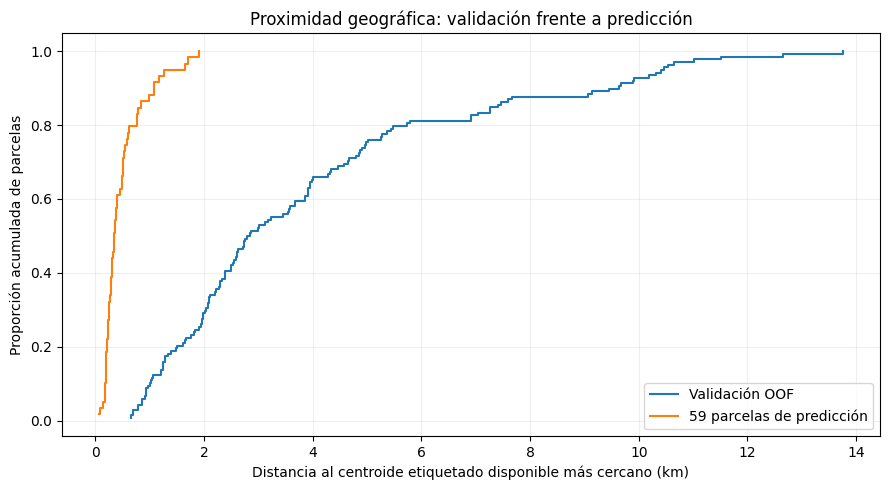

Distancias en metros:


,grupo,parcelas,min_m,p25_m,mediana_m,media_m,p75_m,p90_m,max_m
0,validacion_OOF,138,653.409363,1916.869224,2821.138793,3961.819787,4971.807972,9508.558444,13754.901512
1,prediccion_59,59,66.755524,225.850884,350.356668,494.504728,563.167852,1076.104075,1914.979447



Distancias de validación por fold:


,grupo,parcelas,min_m,p25_m,mediana_m,media_m,p75_m,p90_m,max_m
0,fold_1,31,653.409363,1130.615517,1953.569428,2077.548996,2466.644958,4006.679695,4474.381198
1,fold_2,26,788.134127,1310.989858,2073.077323,2587.562123,2783.190366,5444.741877,7593.914666
2,fold_3,27,653.409363,1962.754710,2609.428340,3316.538194,4604.639057,5805.576607,10539.464161
3,fold_4,27,1249.991277,3508.097086,3951.106917,4248.275234,5307.685255,6199.398651,7408.053693
4,fold_5,27,1249.991277,4355.769621,9452.641703,7807.427183,10356.282400,11214.802661,13754.901512



Diez parcelas de predicción más alejadas:


,distancia_m,vecino_etiquetado,supera_p90_distancia_OOF
ID_POLIGONO,,,
AGC_065,1914.979447,AGC_051,False
AGC_173,1698.680803,AGC_187,False
AGC_174,1642.768917,AGC_083,False
AGC_120,1258.655898,AGC_054,False
AGC_147,1169.518170,AGC_144,False
AGC_183,1086.046207,AGC_163,False
AGC_118,1073.618542,AGC_121,False
AGC_061,983.214766,AGC_074,False
AGC_011,835.702363,AGC_056,False



Parcelas de predicción que superan el p90 de distancia OOF: 0 de 59.

El p90 es una referencia descriptiva, no un umbral de confiabilidad.
No se utilizaron rendimientos para calcular las distancias.
No se modificaron modelos, predicciones ni particiones.

Archivos guardados en: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\diagnostico_espacial\bloque_45_20261018_231121_999627


In [56]:
# Bloque 45: Comparar proximidad geográfica en validación y predicción.
# Distancias entre centroides en EPSG:32614; no entre bordes de parcelas.

from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors

assert X_mensual.index.equals(y_comparacion.index)

# 1. Preparar los centroides ya construidos en el bloque 43.
puntos_distancias = puntos_referencia.copy()

assert puntos_distancias.crs is not None
assert puntos_distancias.crs.is_projected
assert str(puntos_distancias.crs) == str(crs_validacion)

puntos_distancias["ID_POLIGONO"] = (
    puntos_distancias["ID_POLIGONO"].astype(str)
)

assert puntos_distancias["ID_POLIGONO"].is_unique
assert puntos_distancias.geometry.notna().all()
assert (~puntos_distancias.geometry.is_empty).all()

puntos_distancias = puntos_distancias.set_index("ID_POLIGONO")

coordenadas_todas = pd.DataFrame({
    "x_m": puntos_distancias.geometry.x,
    "y_m": puntos_distancias.geometry.y,
})

assert np.isfinite(coordenadas_todas.to_numpy()).all()

ids_etiquetados_distancias = y_comparacion.index
ids_prediccion_distancias = puntos_distancias.index[
    puntos_distancias["CONJUNTO"].eq("PREDICCION")
]

assert len(ids_prediccion_distancias) == 59

assert set(ids_etiquetados_distancias) == set(
    puntos_distancias.index[
        puntos_distancias["CONJUNTO"].eq("ENTRENAMIENTO")
    ]
)

assert set(ids_etiquetados_distancias).isdisjoint(
    set(ids_prediccion_distancias)
)

coordenadas_etiquetadas = coordenadas_todas.loc[
    ids_etiquetados_distancias
]

# 2. Distancia OOF: solo a parcelas del entrenamiento del fold.
filas_distancias_oof = []

for fold, (indices_train, indices_val) in enumerate(
    particiones_espaciales,
    start=1
):
    ids_train = ids_etiquetados_distancias[indices_train]
    ids_val = ids_etiquetados_distancias[indices_val]

    assert set(ids_train).isdisjoint(set(ids_val))

    buscador = NearestNeighbors(
        n_neighbors=1,
        metric="euclidean"
    )

    buscador.fit(coordenadas_etiquetadas.loc[ids_train])

    distancias, vecinos = buscador.kneighbors(
        coordenadas_etiquetadas.loc[ids_val]
    )

    filas_distancias_oof.append(pd.DataFrame({
        "ID_POLIGONO": ids_val,
        "fold": fold,
        "distancia_m": distancias[:, 0],
        "vecino_entrenamiento": ids_train[
            vecinos[:, 0]
        ].to_numpy(),
    }))

distancias_oof = (
    pd.concat(filas_distancias_oof, ignore_index=True)
    .set_index("ID_POLIGONO")
    .loc[ids_etiquetados_distancias]
)

assert distancias_oof.index.is_unique
assert len(distancias_oof) == len(y_comparacion)

# 3. Distancia de predicción: a las 138 parcelas etiquetadas.
buscador_prediccion = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean"
)

buscador_prediccion.fit(coordenadas_etiquetadas)

distancias_pred, vecinos_pred = (
    buscador_prediccion.kneighbors(
        coordenadas_todas.loc[ids_prediccion_distancias]
    )
)

distancias_prediccion = pd.DataFrame({
    "ID_POLIGONO": ids_prediccion_distancias,
    "distancia_m": distancias_pred[:, 0],
    "vecino_etiquetado": ids_etiquetados_distancias[
        vecinos_pred[:, 0]
    ].to_numpy(),
}).set_index("ID_POLIGONO")

# 4. Resumir las distribuciones con las mismas unidades.
def resumir_distancias(nombre, serie):
    return {
        "grupo": nombre,
        "parcelas": len(serie),
        "min_m": serie.min(),
        "p25_m": serie.quantile(0.25),
        "mediana_m": serie.median(),
        "media_m": serie.mean(),
        "p75_m": serie.quantile(0.75),
        "p90_m": serie.quantile(0.90),
        "max_m": serie.max(),
    }

resumen_distancias = pd.DataFrame([
    resumir_distancias(
        "validacion_OOF",
        distancias_oof["distancia_m"]
    ),
    resumir_distancias(
        "prediccion_59",
        distancias_prediccion["distancia_m"]
    ),
])

resumen_distancias_por_fold = pd.DataFrame([
    resumir_distancias(
        f"fold_{fold}",
        casos["distancia_m"]
    )
    for fold, casos in distancias_oof.groupby("fold")
])

# Referencia descriptiva, no umbral de seguridad.
p90_distancia_oof = distancias_oof["distancia_m"].quantile(0.90)

distancias_prediccion["supera_p90_distancia_OOF"] = (
    distancias_prediccion["distancia_m"].gt(p90_distancia_oof)
)

prediccion_mas_alejada = (
    distancias_prediccion
    .sort_values("distancia_m", ascending=False)
    .head(10)
)

# 5. Guardar en una carpeta nueva.
carpeta_distancias = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_002"
    / "bloque_45_diagnostico_espacial"
    / f"bloque_45_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_distancias.mkdir(parents=True, exist_ok=False)

resumen_distancias.to_csv(
    carpeta_distancias / "resumen_distancias.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_distancias_por_fold.to_csv(
    carpeta_distancias / "resumen_distancias_por_fold.csv",
    index=False,
    encoding="utf-8-sig"
)

distancias_oof.to_csv(
    carpeta_distancias / "distancias_oof_por_parcela.csv",
    index=True,
    encoding="utf-8-sig"
)

distancias_prediccion.to_csv(
    carpeta_distancias / "distancias_prediccion_por_parcela.csv",
    index=True,
    encoding="utf-8-sig"
)

# 6. Visualizar distribuciones acumuladas.
fig, eje = plt.subplots(figsize=(9, 5))

for nombre, serie in [
    ("Validación OOF", distancias_oof["distancia_m"]),
    ("59 parcelas de predicción", distancias_prediccion["distancia_m"]),
]:
    valores_km = np.sort(serie.to_numpy()) / 1000
    proporcion = np.arange(1, len(valores_km) + 1) / len(valores_km)

    eje.step(
        valores_km,
        proporcion,
        where="post",
        label=nombre
    )

eje.set_xlabel("Distancia al centroide etiquetado disponible más cercano (km)")
eje.set_ylabel("Proporción acumulada de parcelas")
eje.set_title("Proximidad geográfica: validación frente a predicción")
eje.grid(alpha=0.2)
eje.legend()

fig.tight_layout()
fig.savefig(
    carpeta_distancias / "distribucion_distancias.png",
    dpi=180
)

plt.show()

print("Distancias en metros:")
display(resumen_distancias)

print("\nDistancias de validación por fold:")
display(resumen_distancias_por_fold)

print("\nDiez parcelas de predicción más alejadas:")
display(prediccion_mas_alejada)

print(
    "\nParcelas de predicción que superan el p90 de distancia OOF: "
    f"{int(distancias_prediccion['supera_p90_distancia_OOF'].sum())}"
    f" de {len(distancias_prediccion)}."
)

print(
    "\nEl p90 es una referencia descriptiva, no un umbral de confiabilidad."
    "\nNo se utilizaron rendimientos para calcular las distancias."
    "\nNo se modificaron modelos, predicciones ni particiones."
)

print(f"\nArchivos guardados en: {carpeta_distancias.resolve()}")

In [57]:
# Bloque 46: Diagnosticar rangos y similitud entre predictores.
# No entrena modelos de rendimiento ni modifica las tablas.

from datetime import datetime

import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors

# 1. Preparar las mismas columnas para las 59 parcelas.
tabla_similitud = df_parcela_meses.copy()
tabla_similitud["ID_POLIGONO"] = (
    tabla_similitud["ID_POLIGONO"].astype(str)
)

assert tabla_similitud["ID_POLIGONO"].is_unique

tabla_similitud = tabla_similitud.set_index("ID_POLIGONO")

X_prediccion_diagnostico = (
    tabla_similitud.loc[
        tabla_similitud["CONJUNTO"].eq("PREDICCION"),
        X_mensual.columns
    ]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

assert len(X_prediccion_diagnostico) == 59
assert X_mensual.index.equals(y_comparacion.index)
assert set(X_mensual.index).isdisjoint(
    set(X_prediccion_diagnostico.index)
)

assert not np.isinf(
    X_prediccion_diagnostico.to_numpy()
).any()

# 2. Comparar con los rangos observados de las 138 etiquetadas.
minimos_etiquetados = X_mensual.min()
maximos_etiquetados = X_mensual.max()

fuera_inferior = X_prediccion_diagnostico.lt(
    minimos_etiquetados, axis="columns"
)
fuera_superior = X_prediccion_diagnostico.gt(
    maximos_etiquetados, axis="columns"
)

fuera_rango = fuera_inferior | fuera_superior

resumen_rangos_variables = pd.DataFrame({
    "min_etiquetadas": minimos_etiquetados,
    "max_etiquetadas": maximos_etiquetados,
    "prediccion_debajo_min": fuera_inferior.sum(),
    "prediccion_encima_max": fuera_superior.sum(),
    "prediccion_fuera_rango": fuera_rango.sum(),
    "NA_prediccion": X_prediccion_diagnostico.isna().sum(),
})

resumen_rangos_variables.index.name = "variable"

resumen_rangos_parcelas = pd.DataFrame({
    "variables_fuera_rango": fuera_rango.sum(axis=1),
    "variables_faltantes": (
        X_prediccion_diagnostico.isna().sum(axis=1)
    ),
})

# Detalle de cada valor fuera del rango observado.
filas_fuera_rango = []

for id_parcela in X_prediccion_diagnostico.index:
    variables = fuera_rango.columns[
        fuera_rango.loc[id_parcela].to_numpy()
    ]

    for variable in variables:
        filas_fuera_rango.append({
            "ID_POLIGONO": id_parcela,
            "variable": variable,
            "valor_prediccion": (
                X_prediccion_diagnostico.loc[id_parcela, variable]
            ),
            "min_etiquetadas": minimos_etiquetados[variable],
            "max_etiquetadas": maximos_etiquetados[variable],
        })

detalle_fuera_rango = pd.DataFrame(
    filas_fuera_rango,
    columns=[
        "ID_POLIGONO",
        "variable",
        "valor_prediccion",
        "min_etiquetadas",
        "max_etiquetadas",
    ]
)

# 3. Elegir columnas completas y no constantes para distancias.
# La selección se basa solo en las 138 parcelas etiquetadas.
columnas_distancia_predictora = X_mensual.columns[
    X_mensual.notna().all(axis=0)
    & X_mensual.nunique(dropna=True).gt(1)
].tolist()

columnas_excluidas_distancia = [
    c for c in X_mensual.columns
    if c not in columnas_distancia_predictora
]

assert len(columnas_distancia_predictora) > 0

assert X_prediccion_diagnostico[
    columnas_distancia_predictora
].notna().all().all(), (
    "Hay faltantes en predicción dentro de las columnas elegidas. "
    "Revisarlos antes de calcular distancias."
)

# Escala común para este diagnóstico descriptivo.
# Se ajusta con las 138 etiquetadas, nunca con las 59 de predicción.
# No se utiliza para recalcular métricas OOF ni entrenar XGBoost.
escalador_diagnostico = StandardScaler()

Z_etiquetadas = escalador_diagnostico.fit_transform(
    X_mensual[columnas_distancia_predictora]
)

Z_prediccion = escalador_diagnostico.transform(
    X_prediccion_diagnostico[columnas_distancia_predictora]
)

factor_dimension = np.sqrt(len(columnas_distancia_predictora))

# 4. Referencia de validación: vecinos fuera del entrenamiento reservado.
distancia_predictora_oof = np.full(len(X_mensual), np.nan)

for indices_train, indices_val in particiones_espaciales:
    buscador = NearestNeighbors(
        n_neighbors=1,
        metric="euclidean"
    ).fit(Z_etiquetadas[indices_train])

    distancias, _ = buscador.kneighbors(
        Z_etiquetadas[indices_val]
    )

    distancia_predictora_oof[indices_val] = (
        distancias[:, 0] / factor_dimension
    )

assert np.isfinite(distancia_predictora_oof).all()

# 5. Predicción: vecino más similar entre las 138 etiquetadas.
buscador_predictores = NearestNeighbors(
    n_neighbors=1,
    metric="euclidean"
).fit(Z_etiquetadas)

distancias_predictores, vecinos_predictores = (
    buscador_predictores.kneighbors(Z_prediccion)
)

p90_distancia_predictora_oof = np.quantile(
    distancia_predictora_oof, 0.90
)

diagnostico_predictores_parcela = (
    resumen_rangos_parcelas.copy()
)

diagnostico_predictores_parcela["distancia_estandarizada"] = (
    distancias_predictores[:, 0] / factor_dimension
)

diagnostico_predictores_parcela["vecino_similar_etiquetado"] = (
    X_mensual.index[vecinos_predictores[:, 0]].to_numpy()
)

diagnostico_predictores_parcela["supera_p90_referencia_OOF"] = (
    diagnostico_predictores_parcela[
        "distancia_estandarizada"
    ].gt(p90_distancia_predictora_oof)
)

diagnostico_predictores_parcela.index.name = "ID_POLIGONO"

# Incorporar la distancia geográfica del bloque 45.
diagnostico_predictores_parcela = (
    diagnostico_predictores_parcela
    .join(
        distancias_prediccion[["distancia_m"]].rename(
            columns={"distancia_m": "distancia_geografica_m"}
        ),
        validate="one_to_one"
    )
)

assert diagnostico_predictores_parcela[
    "distancia_geografica_m"
].notna().all()

def resumen_distancia_predictora(nombre, valores):
    serie = pd.Series(np.asarray(valores))

    return {
        "grupo": nombre,
        "parcelas": len(serie),
        "mediana": serie.median(),
        "media": serie.mean(),
        "p90": serie.quantile(0.90),
        "max": serie.max(),
    }

resumen_similitud = pd.DataFrame([
    resumen_distancia_predictora(
        "referencia_OOF",
        distancia_predictora_oof
    ),
    resumen_distancia_predictora(
        "prediccion_59",
        diagnostico_predictores_parcela[
            "distancia_estandarizada"
        ]
    ),
])

resumen_alertas_similitud = pd.DataFrame([{
    "variables_modelo": X_mensual.shape[1],
    "variables_usadas_en_distancias": (
        len(columnas_distancia_predictora)
    ),
    "parcelas_con_valores_fuera_rango": int(
        resumen_rangos_parcelas["variables_fuera_rango"].gt(0).sum()
    ),
    "celdas_fuera_rango": int(fuera_rango.sum().sum()),
    "celdas_NA_prediccion": int(
        X_prediccion_diagnostico.isna().sum().sum()
    ),
    "parcelas_superan_p90_referencia": int(
        diagnostico_predictores_parcela[
            "supera_p90_referencia_OOF"
        ].sum()
    ),
}])

parcelas_mas_diferentes = (
    diagnostico_predictores_parcela
    .sort_values("distancia_estandarizada", ascending=False)
    .head(10)
)

variables_con_alertas = (
    resumen_rangos_variables.loc[
        resumen_rangos_variables["prediccion_fuera_rango"].gt(0)
    ]
    .sort_values("prediccion_fuera_rango", ascending=False)
)

# 6. Guardar sin sobrescribir resultados anteriores.
carpeta_similitud = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_002"
    / "bloque_46_diagnostico_predictores"
    / f"bloque_46_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_similitud.mkdir(parents=True, exist_ok=False)

diagnostico_predictores_parcela.to_csv(
    carpeta_similitud / "diagnostico_por_parcela.csv",
    encoding="utf-8-sig"
)

resumen_rangos_variables.to_csv(
    carpeta_similitud / "rangos_por_variable.csv",
    encoding="utf-8-sig"
)

detalle_fuera_rango.to_csv(
    carpeta_similitud / "detalle_fuera_rango.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_similitud.to_csv(
    carpeta_similitud / "resumen_distancias_predictoras.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({
    "variable": columnas_distancia_predictora,
    "media_etiquetadas": escalador_diagnostico.mean_,
    "escala_etiquetadas": escalador_diagnostico.scale_,
}).to_csv(
    carpeta_similitud / "columnas_y_escalas_distancia.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Resumen del diagnóstico:")
display(resumen_alertas_similitud)

print("\nDistancias estandarizadas, sin unidades físicas:")
display(resumen_similitud)

print("\nDiez parcelas de predicción más diferentes:")
display(parcelas_mas_diferentes)

print("\nVariables con más parcelas fuera del rango observado:")
display(variables_con_alertas.head(15))

print("\nColumnas excluidas solo del cálculo de distancias:")
print(columnas_excluidas_distancia)

print(
    "\nNo se modificaron las 213 variables del modelo."
    "\nNo se imputaron valores ni se calcularon rendimientos."
    "\nEl p90 es descriptivo; no define un área formal de aplicabilidad."
)

print(f"\nResultados guardados en: {carpeta_similitud.resolve()}")

Resumen del diagnóstico:


,variables_modelo,variables_usadas_en_distancias,parcelas_con_valores_fuera_rango,celdas_fuera_rango,celdas_NA_prediccion,parcelas_superan_p90_referencia
0,213,211,27,167,1,3



Distancias estandarizadas, sin unidades físicas:


,grupo,parcelas,mediana,media,p90,max
0,referencia_OOF,138,0.814319,0.842905,1.047018,1.390643
1,prediccion_59,59,0.643961,0.661497,0.873603,1.241502



Diez parcelas de predicción más diferentes:


,variables_fuera_rango,variables_faltantes,distancia_estandarizada,vecino_similar_etiquetado,supera_p90_referencia_OOF,distancia_geografica_m
ID_POLIGONO,,,,,,
AGC_029,9,0,1.241502,AGC_001,True,782.019260
AGC_120,7,0,1.189150,AGC_152,True,1258.655898
AGC_003,5,0,1.165845,AGC_045,True,382.677014
AGC_173,0,0,0.998530,AGC_137,False,1698.680803
AGC_118,2,1,0.988146,AGC_176,False,1073.618542
AGC_043,14,0,0.902477,AGC_168,False,350.356668
AGC_036,11,0,0.866385,AGC_002,False,295.393297
AGC_031,0,0,0.842871,AGC_012,False,181.340240
AGC_065,13,0,0.833963,AGC_180,False,1914.979447



Variables con más parcelas fuera del rango observado:


,min_etiquetadas,max_etiquetadas,prediccion_debajo_min,prediccion_encima_max,prediccion_fuera_rango,NA_prediccion
variable,,,,,,
basico_sentinel_2__msi__media_mensual__2025_08,0.371143,1.062833,0,4,4,0
basico_sentinel_2__ndwi__media_mensual__2025_08,-0.019200,0.465143,4,0,4,0
basico_landsat__vi6t__media_mensual__2025_04,-0.659800,-0.599833,1,2,3,0
basico_sentinel_2__ndvi__media_mensual__2025_08,0.291500,0.751571,2,1,3,0
basico_sentinel_2__dswi3__media_mensual__2025_08,1.787333,3.133800,1,2,3,0
basico_sentinel_2__emsi__media_mensual__2025_08,0.175333,0.808571,0,3,3,0
basico_sentinel_2__ndti__media_mensual__2025_04,0.050714,0.165500,2,1,3,0
basico_sentinel_2__mra__media_mensual__2025_08,0.023500,0.038286,2,1,3,0
pro_planet__lai__media_mensual__2025_05,0.541353,1.171842,3,0,3,0



Columnas excluidas solo del cálculo de distancias:
['basico_landsat__vi6t__media_mensual__2025_07', 'basico_landsat__vi6t__media_mensual__2025_09']

No se modificaron las 213 variables del modelo.
No se imputaron valores ni se calcularon rendimientos.
El p90 es descriptivo; no define un área formal de aplicabilidad.

Resultados guardados en: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\diagnostico_predictores\bloque_46_20261018_231122_347561


In [58]:
# Bloque 47: Sensibilidad de las predicciones a rangos y faltantes.
# No modifica los datos originales ni sustituye la evaluación OOF.

from datetime import datetime
import json

import numpy as np
import pandas as pd
from sklearn.base import clone
from xgboost import XGBRegressor


# ============================================================
# 1. MODELO BASE EXPLÍCITO: XGBoost mensual fijo validado.
# No depende de la variable temporal modelo_fold.
# ============================================================

configuracion_xgb_fijo_47 = {
    "objective": "reg:squarederror",
    "booster": "gbtree",
    "n_estimators": 400,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.7,
    "reg_lambda": 5.0,
    "random_state": 0,
    "n_jobs": -1,
    "missing": np.nan,
}

MODELO_BASE_47 = XGBRegressor(**configuracion_xgb_fijo_47)

modelo_sensibilidad_47 = clone(MODELO_BASE_47)
parametros_47 = modelo_sensibilidad_47.get_params(deep=False)

# ============================================================
# 2. COPIAS DE TRABAJO Y COMPROBACIONES.
# ============================================================

X_train_47 = X_mensual.copy().astype(float)
y_train_47 = y_comparacion.copy()
X_pred_47 = X_prediccion_diagnostico.copy().astype(float)

assert X_train_47.index.equals(y_train_47.index), (
    "Los índices de X e y no coinciden."
)
assert X_train_47.columns.equals(X_pred_47.columns), (
    "Las columnas de entrenamiento y predicción no coinciden."
)

assert X_train_47.columns.is_unique
assert X_train_47.index.is_unique
assert X_pred_47.index.is_unique

assert len(X_train_47) == 138
assert len(X_pred_47) == 59
assert X_train_47.shape[1] == 213

assert set(X_train_47.index).isdisjoint(X_pred_47.index)

assert not np.isinf(X_train_47.to_numpy()).any()
assert not np.isinf(X_pred_47.to_numpy()).any()
assert np.isfinite(np.asarray(y_train_47, dtype=float)).all()

columnas_contexto_47 = [
    "distancia_estandarizada",
    "vecino_similar_etiquetado",
    "supera_p90_referencia_OOF",
    "distancia_geografica_m",
]

assert diagnostico_predictores_parcela.index.is_unique
assert set(columnas_contexto_47).issubset(
    diagnostico_predictores_parcela.columns
)

diagnostico_47 = diagnostico_predictores_parcela.reindex(
    X_pred_47.index
)

assert diagnostico_47[columnas_contexto_47].notna().all().all(), (
    "Falta información del bloque 46 para alguna parcela."
)


# ============================================================
# 3. REFERENCIAS CALCULADAS SOLO CON LAS 138 ETIQUETADAS.
# ============================================================

minimos_47 = X_train_47.min()
maximos_47 = X_train_47.max()
medianas_47 = X_train_47.median()

if medianas_47.isna().any():
    raise ValueError(
        "Hay columnas completamente vacías en entrenamiento."
    )

mascara_fuera_47 = (
    X_pred_47.lt(minimos_47, axis="columns")
    | X_pred_47.gt(maximos_47, axis="columns")
)

mascara_na_47 = X_pred_47.isna()


# ============================================================
# 4. CONSTRUIR LOS CUATRO ESCENARIOS.
# ============================================================

# Base: conserva valores originales y faltantes.
# Límites: recorta solo valores fuera del mínimo–máximo observado.
# Mediana: sustituye solo los faltantes.
# Combinado: aplica ambas modificaciones.

X_limites_47 = X_pred_47.clip(
    lower=minimos_47,
    upper=maximos_47,
    axis="columns"
)

X_mediana_47 = X_pred_47.fillna(medianas_47)
X_combinado_47 = X_limites_47.fillna(medianas_47)

assert X_limites_47.isna().equals(X_pred_47.isna())
assert not X_mediana_47.isna().any().any()
assert not X_combinado_47.isna().any().any()

escenarios_47 = {
    "base": X_pred_47,
    "limites": X_limites_47,
    "mediana": X_mediana_47,
    "combinado": X_combinado_47,
}


# ============================================================
# 5. ENTRENAR UNA SOLA VEZ Y PREDECIR LOS CUATRO ESCENARIOS.
# ============================================================

modelo_sensibilidad_47.fit(X_train_47, y_train_47)

resultado_sensibilidad_47 = pd.DataFrame(
    index=X_pred_47.index
)
resultado_sensibilidad_47.index.name = "ID_POLIGONO"

for nombre_escenario_47, matriz_47 in escenarios_47.items():
    prediccion_47 = np.asarray(
        modelo_sensibilidad_47.predict(matriz_47),
        dtype=float
    ).reshape(-1)

    assert len(prediccion_47) == len(X_pred_47)
    assert np.isfinite(prediccion_47).all()

    resultado_sensibilidad_47[
        f"pred_{nombre_escenario_47}"
    ] = prediccion_47


# ============================================================
# 6. DIFERENCIAS RESPECTO A LA PREDICCIÓN BASE.
# ============================================================

# Solo distingue cambios numéricos de diferencias prácticamente nulas.
# No representa un umbral de importancia agronómica.
TOLERANCIA_NUMERICA_47 = 1e-6

for nombre_escenario_47 in ("limites", "mediana", "combinado"):
    delta_47 = (
        resultado_sensibilidad_47[f"pred_{nombre_escenario_47}"]
        - resultado_sensibilidad_47["pred_base"]
    )

    resultado_sensibilidad_47[
        f"delta_{nombre_escenario_47}"
    ] = delta_47

    resultado_sensibilidad_47[
        f"abs_delta_{nombre_escenario_47}"
    ] = delta_47.abs()

columnas_delta_abs_47 = [
    "abs_delta_limites",
    "abs_delta_mediana",
    "abs_delta_combinado",
]

resultado_sensibilidad_47["max_cambio_absoluto"] = (
    resultado_sensibilidad_47[columnas_delta_abs_47].max(axis=1)
)

resultado_sensibilidad_47["variables_fuera_rango"] = (
    mascara_fuera_47.sum(axis=1)
)

resultado_sensibilidad_47["variables_faltantes"] = (
    mascara_na_47.sum(axis=1)
)

resultado_sensibilidad_47["celdas_modificadas_limites"] = (
    X_pred_47.ne(X_limites_47)
    & ~(X_pred_47.isna() & X_limites_47.isna())
).sum(axis=1)

assert resultado_sensibilidad_47[
    "celdas_modificadas_limites"
].equals(
    resultado_sensibilidad_47["variables_fuera_rango"]
)

resultado_sensibilidad_47 = resultado_sensibilidad_47.join(
    diagnostico_47[columnas_contexto_47],
    validate="one_to_one"
)

# Comprobar que las parcelas sin cambios de entrada conservan predicción.
sin_fuera_rango_47 = ~mascara_fuera_47.any(axis=1)
sin_na_47 = ~mascara_na_47.any(axis=1)

assert np.allclose(
    resultado_sensibilidad_47.loc[
        sin_fuera_rango_47, "pred_base"
    ],
    resultado_sensibilidad_47.loc[
        sin_fuera_rango_47, "pred_limites"
    ],
    rtol=0,
    atol=TOLERANCIA_NUMERICA_47
)

assert np.allclose(
    resultado_sensibilidad_47.loc[
        sin_na_47, "pred_base"
    ],
    resultado_sensibilidad_47.loc[
        sin_na_47, "pred_mediana"
    ],
    rtol=0,
    atol=TOLERANCIA_NUMERICA_47
)


# ============================================================
# 7. RESUMEN GLOBAL DE SENSIBILIDAD.
# ============================================================

filas_resumen_47 = []

for nombre_escenario_47 in ("limites", "mediana", "combinado"):
    delta_47 = resultado_sensibilidad_47[
        f"delta_{nombre_escenario_47}"
    ]
    absoluto_47 = delta_47.abs()

    filas_resumen_47.append({
        "escenario_vs_base": nombre_escenario_47,
        "parcelas_con_cambio": int(
            absoluto_47.gt(TOLERANCIA_NUMERICA_47).sum()
        ),
        "delta_medio": delta_47.mean(),
        "cambio_absoluto_medio": absoluto_47.mean(),
        "cambio_absoluto_mediano": absoluto_47.median(),
        "p90_cambio_absoluto": absoluto_47.quantile(0.90),
        "max_cambio_absoluto": absoluto_47.max(),
    })

resumen_sensibilidad_47 = pd.DataFrame(filas_resumen_47)


# ============================================================
# 8. RESUMEN POR TIPO DE ALERTA.
# ============================================================

# Los grupos pueden solaparse.
grupos_47 = {
    "todas": pd.Series(True, index=X_pred_47.index),
    "con_fuera_rango": (
        resultado_sensibilidad_47["variables_fuera_rango"].gt(0)
    ),
    "con_NA": (
        resultado_sensibilidad_47["variables_faltantes"].gt(0)
    ),
    "superan_p90_predictor": (
        resultado_sensibilidad_47["supera_p90_referencia_OOF"]
    ),
}

filas_grupos_47 = []

for nombre_grupo_47, mascara_grupo_47 in grupos_47.items():
    subset_47 = resultado_sensibilidad_47.loc[mascara_grupo_47]
    cambios_47 = subset_47["max_cambio_absoluto"]

    filas_grupos_47.append({
        "grupo": nombre_grupo_47,
        "parcelas": len(subset_47),
        "parcelas_con_algun_cambio": int(
            cambios_47.gt(TOLERANCIA_NUMERICA_47).sum()
        ),
        "max_cambio_medio": cambios_47.mean(),
        "max_cambio_observado": cambios_47.max(),
    })

resumen_grupos_47 = pd.DataFrame(filas_grupos_47)


# ============================================================
# 9. TABLAS DE PARCELAS PRIORITARIAS Y MAYORES CAMBIOS.
# ============================================================

mascara_prioritaria_47 = (
    resultado_sensibilidad_47["supera_p90_referencia_OOF"]
    | resultado_sensibilidad_47["variables_faltantes"].gt(0)
)

columnas_revision_47 = [
    "pred_base",
    "pred_limites",
    "pred_mediana",
    "pred_combinado",
    "delta_limites",
    "delta_mediana",
    "delta_combinado",
    "max_cambio_absoluto",
    "variables_fuera_rango",
    "variables_faltantes",
    "distancia_estandarizada",
    "supera_p90_referencia_OOF",
    "distancia_geografica_m",
]

parcelas_prioritarias_47 = (
    resultado_sensibilidad_47.loc[
        mascara_prioritaria_47,
        columnas_revision_47
    ]
    .sort_values("distancia_estandarizada", ascending=False)
)

mayores_cambios_47 = (
    resultado_sensibilidad_47
    .sort_values("max_cambio_absoluto", ascending=False)
    .head(10)[columnas_revision_47]
)


# ============================================================
# 10. REGISTRAR LAS CELDAS MODIFICADAS EN CADA ESCENARIO.
# ============================================================

filas_modificaciones_47 = []

for nombre_escenario_47 in ("limites", "mediana", "combinado"):
    matriz_47 = escenarios_47[nombre_escenario_47]

    mascara_cambio_47 = (
        X_pred_47.ne(matriz_47)
        & ~(X_pred_47.isna() & matriz_47.isna())
    )

    posiciones_47 = np.argwhere(
        mascara_cambio_47.to_numpy()
    )

    for fila_47, columna_47 in posiciones_47:
        filas_modificaciones_47.append({
            "escenario": nombre_escenario_47,
            "ID_POLIGONO": X_pred_47.index[fila_47],
            "variable": X_pred_47.columns[columna_47],
            "valor_original": X_pred_47.iat[fila_47, columna_47],
            "valor_escenario": matriz_47.iat[fila_47, columna_47],
            "min_entrenamiento": minimos_47.iloc[columna_47],
            "max_entrenamiento": maximos_47.iloc[columna_47],
            "mediana_entrenamiento": medianas_47.iloc[columna_47],
        })

detalle_modificaciones_47 = pd.DataFrame(
    filas_modificaciones_47,
    columns=[
        "escenario",
        "ID_POLIGONO",
        "variable",
        "valor_original",
        "valor_escenario",
        "min_entrenamiento",
        "max_entrenamiento",
        "mediana_entrenamiento",
    ]
)


# ============================================================
# 11. GUARDAR RESULTADOS SIN SOBRESCRIBIR LOS ANTERIORES.
# ============================================================

carpeta_sensibilidad_47 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_002"
    / "bloque_47_sensibilidad_predicciones"
    / f"bloque_47_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_sensibilidad_47.mkdir(
    parents=True,
    exist_ok=False
)

resultado_sensibilidad_47.to_csv(
    carpeta_sensibilidad_47 / "sensibilidad_por_parcela.csv",
    encoding="utf-8-sig"
)

resumen_sensibilidad_47.to_csv(
    carpeta_sensibilidad_47 / "resumen_sensibilidad.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_grupos_47.to_csv(
    carpeta_sensibilidad_47 / "resumen_por_alerta.csv",
    index=False,
    encoding="utf-8-sig"
)

detalle_modificaciones_47.to_csv(
    carpeta_sensibilidad_47 / "detalle_modificaciones.csv",
    index=False,
    encoding="utf-8-sig"
)

pd.DataFrame({
    "min_entrenamiento": minimos_47,
    "max_entrenamiento": maximos_47,
    "mediana_entrenamiento": medianas_47,
}).to_csv(
    carpeta_sensibilidad_47 / "referencias_entrenamiento.csv",
    encoding="utf-8-sig"
)

modelo_sensibilidad_47.save_model(
    str(carpeta_sensibilidad_47 / "modelo_sensibilidad.json")
)

with (
    carpeta_sensibilidad_47 / "parametros_modelo.json"
).open("w", encoding="utf-8") as archivo_47:
    json.dump(
        parametros_47,
        archivo_47,
        ensure_ascii=False,
        indent=2,
        default=str
    )


# ============================================================
# 12. CREAR TXT PARA COMPARTIR.
# ============================================================

ruta_reporte_47 = (
    carpeta_sensibilidad_47 / "revision_bloque_47.txt"
)

secciones_reporte_47 = [
    ("RESUMEN DE SENSIBILIDAD", resumen_sensibilidad_47, False),
    (
        "RESUMEN POR ALERTA: GRUPOS SOLAPADOS",
        resumen_grupos_47,
        False
    ),
    ("PARCELAS PRIORITARIAS", parcelas_prioritarias_47, True),
    ("DIEZ MAYORES CAMBIOS", mayores_cambios_47, True),
]

with ruta_reporte_47.open("w", encoding="utf-8") as archivo_47:
    archivo_47.write(
        "MODELO BASE: configuración de modelo_fold.\n"
        "Ajuste: 138 parcelas etiquetadas y 213 variables.\n"
        "Predicción: 59 parcelas.\n\n"
        "Deltas = predicción del escenario - predicción base.\n"
        "Unidades: las mismas de y_comparacion.\n"
        "No son errores observados ni intervalos de confianza.\n"
        "La tolerancia numérica no es un umbral agronómico.\n\n"
    )

    archivo_47.write("PARAMETROS DEL MODELO\n\n")
    archivo_47.write(
        json.dumps(
            parametros_47,
            ensure_ascii=False,
            indent=2,
            default=str
        )
    )
    archivo_47.write("\n\n")

    for titulo_47, tabla_47, incluir_indice_47 in secciones_reporte_47:
        archivo_47.write(titulo_47 + "\n\n")
        archivo_47.write(
            tabla_47.to_string(
                index=incluir_indice_47,
                float_format=lambda valor: f"{valor:.6f}"
            )
        )
        archivo_47.write("\n\n")


# ============================================================
# 13. MOSTRAR RESULTADOS.
# ============================================================

print("RESUMEN DE SENSIBILIDAD")
display(resumen_sensibilidad_47)

print("\nRESUMEN POR ALERTA: LOS GRUPOS PUEDEN SOLAPARSE")
display(resumen_grupos_47)

print("\nPARCELAS PRIORITARIAS")
display(parcelas_prioritarias_47)

print("\nDIEZ MAYORES CAMBIOS")
display(mayores_cambios_47)

print(
    "\nLos deltas están en las mismas unidades de y_comparacion."
    "\nNo se modificaron los datos originales ni modelo_fold."
    "\nNo se eligió automáticamente ningún escenario."
    "\nNo se recalcularon métricas OOF."
    "\nNo se generó un archivo de entrega definitivo."
)

print(f"\nResultados guardados en: {carpeta_sensibilidad_47.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_47.resolve()}")

RESUMEN DE SENSIBILIDAD


,escenario_vs_base,parcelas_con_cambio,delta_medio,cambio_absoluto_medio,cambio_absoluto_mediano,p90_cambio_absoluto,max_cambio_absoluto
0,limites,0,0.00000,0.00000,0.0,0.0,0.000000
1,mediana,1,-0.00029,0.00029,0.0,0.0,0.017081
2,combinado,1,-0.00029,0.00029,0.0,0.0,0.017081



RESUMEN POR ALERTA: LOS GRUPOS PUEDEN SOLAPARSE


,grupo,parcelas,parcelas_con_algun_cambio,max_cambio_medio,max_cambio_observado
0,todas,59,1,0.000290,0.017081
1,con_fuera_rango,27,1,0.000633,0.017081
2,con_NA,1,1,0.017081,0.017081
3,superan_p90_predictor,3,0,0.000000,0.000000



PARCELAS PRIORITARIAS


,pred_base,pred_limites,pred_mediana,pred_combinado,delta_limites,delta_mediana,delta_combinado,max_cambio_absoluto,variables_fuera_rango,variables_faltantes,distancia_estandarizada,supera_p90_referencia_OOF,distancia_geografica_m
ID_POLIGONO,,,,,,,,,,,,,
AGC_029,3.067672,3.067672,3.067672,3.067672,0.0,0.000000,0.000000,0.000000,9,0,1.241502,True,782.019260
AGC_120,3.344105,3.344105,3.344105,3.344105,0.0,0.000000,0.000000,0.000000,7,0,1.189150,True,1258.655898
AGC_003,3.283666,3.283666,3.283666,3.283666,0.0,0.000000,0.000000,0.000000,5,0,1.165845,True,382.677014
AGC_118,2.911017,2.911017,2.893937,2.893937,0.0,-0.017081,-0.017081,0.017081,2,1,0.988146,False,1073.618542



DIEZ MAYORES CAMBIOS


,pred_base,pred_limites,pred_mediana,pred_combinado,delta_limites,delta_mediana,delta_combinado,max_cambio_absoluto,variables_fuera_rango,variables_faltantes,distancia_estandarizada,supera_p90_referencia_OOF,distancia_geografica_m
ID_POLIGONO,,,,,,,,,,,,,
AGC_118,2.911017,2.911017,2.893937,2.893937,0.0,-0.017081,-0.017081,0.017081,2,1,0.988146,False,1073.618542
AGC_011,4.653302,4.653302,4.653302,4.653302,0.0,0.000000,0.000000,0.000000,0,0,0.557988,False,835.702363
AGC_003,3.283666,3.283666,3.283666,3.283666,0.0,0.000000,0.000000,0.000000,5,0,1.165845,True,382.677014
AGC_025,3.029202,3.029202,3.029202,3.029202,0.0,0.000000,0.000000,0.000000,0,0,0.527166,False,398.122304
AGC_027,2.920834,2.920834,2.920834,2.920834,0.0,0.000000,0.000000,0.000000,1,0,0.550559,False,523.825133
AGC_028,4.534313,4.534313,4.534313,4.534313,0.0,0.000000,0.000000,0.000000,0,0,0.535115,False,203.516585
AGC_029,3.067672,3.067672,3.067672,3.067672,0.0,0.000000,0.000000,0.000000,9,0,1.241502,True,782.019260
AGC_030,2.953633,2.953633,2.953633,2.953633,0.0,0.000000,0.000000,0.000000,0,0,0.782916,False,504.624855
AGC_031,4.323507,4.323507,4.323507,4.323507,0.0,0.000000,0.000000,0.000000,0,0,0.842871,False,181.340240



Los deltas están en las mismas unidades de y_comparacion.
No se modificaron los datos originales ni modelo_fold.
No se eligió automáticamente ningún escenario.
No se recalcularon métricas OOF.
No se generó un archivo de entrega definitivo.

Resultados guardados en: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\sensibilidad_predicciones\bloque_47_20261018_231123_204163

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\sensibilidad_predicciones\bloque_47_20261018_231123_204163\revision_bloque_47.txt


In [59]:
# Bloque 48: Exportar los rendimientos estimados de las 59 parcelas.
# Utiliza las predicciones base calculadas en el bloque 47.
# No vuelve a entrenar ni modifica las predicciones.

from datetime import datetime

import numpy as np
import pandas as pd


# ============================================================
# 1. RECUPERAR LAS PREDICCIONES BASE Y VALIDAR IDENTIFICADORES.
# ============================================================

assert resultado_sensibilidad_47.index.is_unique, (
    "Hay identificadores duplicados en los resultados."
)

assert X_prediccion_diagnostico.index.is_unique, (
    "Hay identificadores duplicados en las parcelas de predicción."
)

assert len(resultado_sensibilidad_47) == 59
assert len(X_prediccion_diagnostico) == 59

assert set(resultado_sensibilidad_47.index) == set(
    X_prediccion_diagnostico.index
), "Los identificadores no coinciden con las 59 parcelas objetivo."

# Mantener el orden de las parcelas utilizado en el bloque 46.
predicciones_entrega_48 = (
    resultado_sensibilidad_47["pred_base"]
    .reindex(X_prediccion_diagnostico.index)
    .copy()
)

assert predicciones_entrega_48.notna().all()
assert np.isfinite(
    predicciones_entrega_48.to_numpy(dtype=float)
).all()


# ============================================================
# 2. CONSTRUIR LA TABLA DE ENTREGA.
# ============================================================

entrega_rendimientos_59 = pd.DataFrame({
    "ID_PARCELA": predicciones_entrega_48.index.astype(str),
    "RENDIMIENTO": predicciones_entrega_48.to_numpy(dtype=float),
})

assert entrega_rendimientos_59.shape == (59, 2)
assert entrega_rendimientos_59.columns.tolist() == [
    "ID_PARCELA",
    "RENDIMIENTO",
]
assert entrega_rendimientos_59["ID_PARCELA"].is_unique
assert entrega_rendimientos_59["ID_PARCELA"].str.strip().ne("").all()
assert entrega_rendimientos_59["RENDIMIENTO"].notna().all()


# ============================================================
# 3. GUARDAR EN UNA CARPETA NUEVA.
# ============================================================

carpeta_entrega_48 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_002"
    / "bloque_48_entrega_predicciones_xgb"
    / f"bloque_48_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_entrega_48.mkdir(
    parents=True,
    exist_ok=False
)

ruta_entrega_48 = (
    carpeta_entrega_48 / "rendimientos_59_parcelas.csv"
)

# Separador: coma.
# Decimal: punto.
# Sin columna de índice adicional.
# Se conserva la precisión disponible de las predicciones.
entrega_rendimientos_59.to_csv(
    ruta_entrega_48,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 4. VOLVER A LEER EL CSV PARA VERIFICAR LA EXPORTACIÓN.
# ============================================================

verificacion_entrega_48 = pd.read_csv(
    ruta_entrega_48,
    encoding="utf-8-sig",
    dtype={"ID_PARCELA": str}
)

assert verificacion_entrega_48.shape == (59, 2)

assert verificacion_entrega_48.columns.tolist() == [
    "ID_PARCELA",
    "RENDIMIENTO",
]

assert verificacion_entrega_48["ID_PARCELA"].equals(
    entrega_rendimientos_59["ID_PARCELA"]
)

assert np.allclose(
    verificacion_entrega_48["RENDIMIENTO"].to_numpy(),
    entrega_rendimientos_59["RENDIMIENTO"].to_numpy(),
    rtol=0,
    atol=1e-10
)

assert ruta_entrega_48.is_file()
assert ruta_entrega_48.stat().st_size > 0


# ============================================================
# 5. MOSTRAR LAS 59 ESTIMACIONES Y SU RESUMEN.
# ============================================================

print("RENDIMIENTOS ESTIMADOS DE LAS 59 PARCELAS")

with pd.option_context(
    "display.max_rows", 59,
    "display.float_format", "{:.6f}".format
):
    display(entrega_rendimientos_59)

print("\nRESUMEN DE LOS RENDIMIENTOS ESTIMADOS")
display(
    entrega_rendimientos_59["RENDIMIENTO"]
    .describe()
    .to_frame(name="RENDIMIENTO")
)

print("\nArchivo verificado: 59 filas y 2 columnas.")
print("Se utilizaron las predicciones base del bloque 47.")
print("No se aplicaron recortes, imputaciones ni redondeos adicionales.")
print("Las unidades son las mismas de y_comparacion.")
print(f"\nCSV de entrega: {ruta_entrega_48.resolve()}")

RENDIMIENTOS ESTIMADOS DE LAS 59 PARCELAS


,ID_PARCELA,RENDIMIENTO
0,AGC_003,3.283666
1,AGC_011,4.653302
2,AGC_016,4.164595
3,AGC_025,3.029202
4,AGC_027,2.920834
5,AGC_028,4.534313
6,AGC_029,3.067672
7,AGC_030,2.953633
8,AGC_031,4.323507
9,AGC_036,4.462224



RESUMEN DE LOS RENDIMIENTOS ESTIMADOS


,RENDIMIENTO
count,59.000000
mean,3.902387
std,0.699534
min,2.705523
25%,3.108545
50%,4.166242
75%,4.457060
max,5.119641



Archivo verificado: 59 filas y 2 columnas.
Se utilizaron las predicciones base del bloque 47.
No se aplicaron recortes, imputaciones ni redondeos adicionales.
Las unidades son las mismas de y_comparacion.

CSV de entrega: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\entrega_predicciones\bloque_48_20261018_231123_301525\rendimientos_59_parcelas.csv


In [60]:
# Bloque 49: Comparar una MLP pequeña con ciclo y meses separados.
# Reutiliza la validación espacial del bloque 38.
# No modifica modelos anteriores ni las 59 predicciones exportadas.

from datetime import datetime
import json
import platform
import warnings

import numpy as np
import pandas as pd
import sklearn

from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. CONFIGURACIÓN FIJA ANTES DE OBSERVAR LOS RESULTADOS.
# ============================================================

configuracion_mlp_49 = {
    "hidden_layer_sizes": (8,),
    "activation": "tanh",
    "solver": "lbfgs",
    "alpha": 1.0,
    "max_iter": 2000,
    "max_fun": 30000,
    "tol": 1e-6,
    "early_stopping": False,
    "random_state": 0,
}

representaciones_mlp_49 = {
    "mlp_resumen_ciclo": X_ciclo.copy(),
    "mlp_meses_separados": X_mensual.copy(),
}

y_mlp_49 = y_comparacion.copy().astype(float)


# ============================================================
# 2. COMPROBAR ALINEACIÓN Y PARTICIONES.
# ============================================================

assert len(y_mlp_49) == 138
assert y_mlp_49.index.is_unique
assert np.isfinite(y_mlp_49.to_numpy()).all()

assert len(particiones_espaciales) == 5
assert grupos_espaciales.index.equals(y_mlp_49.index)

for nombre_49, matriz_49 in representaciones_mlp_49.items():
    assert matriz_49.index.equals(y_mlp_49.index), (
        f"Los índices no coinciden en {nombre_49}."
    )
    assert matriz_49.columns.is_unique

    representaciones_mlp_49[nombre_49] = (
        matriz_49
        .apply(pd.to_numeric, errors="raise")
        .astype(float)
    )

    assert not np.isinf(
        representaciones_mlp_49[nombre_49].to_numpy()
    ).any(), f"Hay valores infinitos en {nombre_49}."

assert representaciones_mlp_49[
    "mlp_resumen_ciclo"
].shape == (138, 33)

assert representaciones_mlp_49[
    "mlp_meses_separados"
].shape == (138, 213)

cobertura_validacion_49 = np.zeros(len(y_mlp_49), dtype=int)
asignacion_fold_49 = np.full(len(y_mlp_49), -1, dtype=int)

for fold_49, (train_49, val_49) in enumerate(
    particiones_espaciales,
    start=1
):
    train_49 = np.asarray(train_49)
    val_49 = np.asarray(val_49)

    assert len(train_49) > 0 and len(val_49) > 0
    assert len(np.unique(train_49)) == len(train_49)
    assert len(np.unique(val_49)) == len(val_49)

    assert set(train_49).isdisjoint(set(val_49))
    assert set(train_49) | set(val_49) == set(
        range(len(y_mlp_49))
    )

    assert set(
        grupos_espaciales.iloc[train_49]
    ).isdisjoint(
        set(grupos_espaciales.iloc[val_49])
    ), f"Hay grupos espaciales compartidos en fold {fold_49}."

    cobertura_validacion_49[val_49] += 1
    asignacion_fold_49[val_49] = fold_49

assert (cobertura_validacion_49 == 1).all(), (
    "Cada parcela debe aparecer una vez en validación."
)


# ============================================================
# 3. EVALUAR AMBAS REDES CON LAS MISMAS PARTICIONES.
# ============================================================

predicciones_oof_mlp_49 = pd.DataFrame({
    "rendimiento_observado": y_mlp_49,
    "fold_validacion": asignacion_fold_49,
})

predicciones_oof_mlp_49.index.name = "ID_POLIGONO"

filas_metricas_mlp_49 = []
filas_avisos_mlp_49 = []

for nombre_49, matriz_49 in representaciones_mlp_49.items():
    predicciones_49 = np.full(len(y_mlp_49), np.nan)

    for fold_49, (train_49, val_49) in enumerate(
        particiones_espaciales,
        start=1
    ):
        X_train_49 = matriz_49.iloc[train_49]
        X_val_49 = matriz_49.iloc[val_49]

        y_train_49 = y_mlp_49.iloc[train_49]
        y_val_49 = y_mlp_49.iloc[val_49]

        assert not X_train_49.isna().all(axis=0).any(), (
            f"Hay una columna completamente vacía en "
            f"{nombre_49}, fold {fold_49}."
        )

        # Un pipeline nuevo por fold.
        # Mediana y escalador se ajustan solo con entrenamiento.
        red_fold_49 = Pipeline([
            ("imputacion", SimpleImputer(strategy="median")),
            ("escala", StandardScaler()),
            ("red", MLPRegressor(**configuracion_mlp_49)),
        ])

        print(
            f"Entrenando {nombre_49} | fold {fold_49}/5...",
            flush=True
        )

        with warnings.catch_warnings(record=True) as avisos_49:
            warnings.simplefilter("always")
            red_fold_49.fit(X_train_49, y_train_49)

        avisos_convergencia_49 = 0

        for aviso_49 in avisos_49:
            es_convergencia_49 = issubclass(
                aviso_49.category,
                ConvergenceWarning
            )

            avisos_convergencia_49 += int(es_convergencia_49)

            filas_avisos_mlp_49.append({
                "modelo": nombre_49,
                "fold": fold_49,
                "categoria": aviso_49.category.__name__,
                "es_convergencia": es_convergencia_49,
                "mensaje": str(aviso_49.message),
            })

        pred_val_49 = red_fold_49.predict(X_val_49)
        pred_train_49 = red_fold_49.predict(X_train_49)

        assert np.isfinite(pred_val_49).all()
        assert np.isfinite(pred_train_49).all()

        predicciones_49[val_49] = pred_val_49

        estimador_red_49 = red_fold_49.named_steps["red"]

        n_parametros_49 = int(
            sum(c.size for c in estimador_red_49.coefs_)
            + sum(b.size for b in estimador_red_49.intercepts_)
        )

        filas_metricas_mlp_49.append({
            "modelo": nombre_49,
            "fold": fold_49,
            "n_train": len(train_49),
            "n_validacion": len(val_49),
            "variables": matriz_49.shape[1],
            "parametros_red": n_parametros_49,
            "MAE_val": mean_absolute_error(
                y_val_49, pred_val_49
            ),
            "RMSE_val": np.sqrt(
                mean_squared_error(y_val_49, pred_val_49)
            ),
            "R2_val": r2_score(y_val_49, pred_val_49),
            "R2_train": r2_score(
                y_train_49, pred_train_49
            ),
            "sesgo_pred_menos_real": (
                pred_val_49 - y_val_49.to_numpy()
            ).mean(),
            "iteraciones": int(estimador_red_49.n_iter_),
            "avisos_convergencia": avisos_convergencia_49,
            "avisos_totales": len(avisos_49),
        })

    assert np.isfinite(predicciones_49).all()
    predicciones_oof_mlp_49[nombre_49] = predicciones_49

metricas_folds_mlp_49 = pd.DataFrame(filas_metricas_mlp_49)

avisos_mlp_49 = pd.DataFrame(
    filas_avisos_mlp_49,
    columns=[
        "modelo",
        "fold",
        "categoria",
        "es_convergencia",
        "mensaje",
    ]
)


# ============================================================
# 4. RESUMEN GLOBAL DE LAS REDES.
# ============================================================

filas_resumen_mlp_49 = []

for nombre_49 in representaciones_mlp_49:
    pred_oof_49 = predicciones_oof_mlp_49[nombre_49]

    resultados_fold_49 = metricas_folds_mlp_49.loc[
        metricas_folds_mlp_49["modelo"].eq(nombre_49)
    ]

    filas_resumen_mlp_49.append({
        "modelo": nombre_49,
        "MAE_OOF": mean_absolute_error(
            y_mlp_49, pred_oof_49
        ),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(y_mlp_49, pred_oof_49)
        ),
        "R2_OOF": r2_score(y_mlp_49, pred_oof_49),
        "sesgo_pred_menos_real": (
            pred_oof_49 - y_mlp_49
        ).mean(),
        "R2_train_media_folds": (
            resultados_fold_49["R2_train"].mean()
        ),
        "folds_con_aviso_convergencia": int(
            resultados_fold_49[
                "avisos_convergencia"
            ].gt(0).sum()
        ),
    })

resumen_mlp_49 = pd.DataFrame(filas_resumen_mlp_49)


# ============================================================
# 5. RECUPERAR REFERENCIAS OOF SIN VOLVER A ENTRENARLAS.
# ============================================================

assert predicciones_oof_comparacion.index.equals(
    y_mlp_49.index
)
assert predicciones_oof_xgb.index.equals(
    y_mlp_49.index
)

for tabla_referencia_49 in [
    predicciones_oof_comparacion,
    predicciones_oof_xgb,
]:
    assert np.allclose(
        tabla_referencia_49[
            "rendimiento_observado"
        ].to_numpy(dtype=float),
        y_mlp_49.to_numpy(),
        rtol=0,
        atol=1e-12
    ), "Los rendimientos de referencia no coinciden."

referencias_oof_49 = {
    "baseline_media": (
        predicciones_oof_comparacion["baseline_media"]
    ),
    "rf_resumen_ciclo": (
        predicciones_oof_comparacion["rf_resumen_ciclo"]
    ),
    "rf_meses_separados": (
        predicciones_oof_comparacion["rf_meses_separados"]
    ),
    "xgb_resumen_ciclo": (
        predicciones_oof_xgb["xgb_resumen_ciclo"]
    ),
    "xgb_meses_separados": (
        predicciones_oof_xgb["xgb_meses_separados"]
    ),
}

filas_referencias_49 = []

for nombre_49, pred_oof_49 in referencias_oof_49.items():
    assert pred_oof_49.index.equals(y_mlp_49.index)
    assert np.isfinite(
        pred_oof_49.to_numpy(dtype=float)
    ).all()

    filas_referencias_49.append({
        "modelo": nombre_49,
        "MAE_OOF": mean_absolute_error(
            y_mlp_49, pred_oof_49
        ),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(y_mlp_49, pred_oof_49)
        ),
        "R2_OOF": r2_score(y_mlp_49, pred_oof_49),
        "sesgo_pred_menos_real": (
            pred_oof_49 - y_mlp_49
        ).mean(),
    })

columnas_comparacion_49 = [
    "modelo",
    "MAE_OOF",
    "RMSE_OOF",
    "R2_OOF",
    "sesgo_pred_menos_real",
]

comparacion_modelos_49 = pd.concat([
    pd.DataFrame(filas_referencias_49),
    resumen_mlp_49[columnas_comparacion_49],
], ignore_index=True)

rmse_xgb_fijo_49 = comparacion_modelos_49.loc[
    comparacion_modelos_49["modelo"].eq(
        "xgb_meses_separados"
    ),
    "RMSE_OOF"
].iloc[0]

comparacion_modelos_49["delta_RMSE_vs_xgb_fijo"] = (
    comparacion_modelos_49["RMSE_OOF"]
    - rmse_xgb_fijo_49
)

comparacion_modelos_49 = (
    comparacion_modelos_49
    .sort_values("RMSE_OOF")
    .reset_index(drop=True)
)


# ============================================================
# 6. GUARDAR RESULTADOS Y CONFIGURACIÓN.
# ============================================================

carpeta_mlp_49 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_49_red_neuronal"
    / f"bloque_49_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_mlp_49.mkdir(parents=True, exist_ok=False)

predicciones_oof_mlp_49.to_csv(
    carpeta_mlp_49 / "predicciones_oof_mlp.csv",
    encoding="utf-8-sig"
)

metricas_folds_mlp_49.to_csv(
    carpeta_mlp_49 / "metricas_por_fold.csv",
    index=False,
    encoding="utf-8-sig"
)

resumen_mlp_49.to_csv(
    carpeta_mlp_49 / "resumen_mlp.csv",
    index=False,
    encoding="utf-8-sig"
)

comparacion_modelos_49.to_csv(
    carpeta_mlp_49 / "comparacion_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

avisos_mlp_49.to_csv(
    carpeta_mlp_49 / "avisos_entrenamiento.csv",
    index=False,
    encoding="utf-8-sig"
)

configuracion_reporte_49 = {
    "configuracion_mlp": configuracion_mlp_49,
    "preprocesamiento": [
        "SimpleImputer: mediana del entrenamiento de cada fold",
        "StandardScaler: ajuste dentro de cada entrenamiento",
    ],
    "parcelas_etiquetadas": len(y_mlp_49),
    "representaciones": {
        nombre: {
            "variables": matriz.shape[1],
            "columnas": matriz.columns.tolist(),
        }
        for nombre, matriz in representaciones_mlp_49.items()
    },
    "folds_espaciales": len(particiones_espaciales),
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "notas": [
        "Configuración fija, sin búsqueda de hiperparámetros.",
        "Una única semilla: estabilidad pendiente de evaluar.",
        "Sin early stopping automático.",
        "No se usan las 59 parcelas para seleccionar el modelo.",
        "No se reemplazan modelos ni predicciones anteriores.",
        "Las referencias recuperadas deben corresponder "
        "a las mismas particiones del bloque 38.",
    ],
}

with (
    carpeta_mlp_49 / "configuracion.json"
).open("w", encoding="utf-8") as archivo_49:
    json.dump(
        configuracion_reporte_49,
        archivo_49,
        ensure_ascii=False,
        indent=2
    )


# ============================================================
# 7. GENERAR TXT PARA COMPARTIR.
# ============================================================

ruta_reporte_49 = carpeta_mlp_49 / "revision_bloque_49.txt"

secciones_reporte_49 = [
    ("COMPARACION GLOBAL", comparacion_modelos_49),
    ("RESUMEN DE LAS REDES", resumen_mlp_49),
    ("RESULTADOS POR FOLD", metricas_folds_mlp_49),
    ("AVISOS DE ENTRENAMIENTO", avisos_mlp_49),
]

with ruta_reporte_49.open("w", encoding="utf-8") as archivo_49:
    archivo_49.write(
        "BLOQUE 49: RED NEURONAL MLP EXPLORATORIA\n\n"
        "Mismas parcelas y particiones espaciales previas.\n"
        "Mediana y escalado ajustados dentro de cada fold.\n"
        "Configuracion fija y semilla 0.\n"
        "No se modificaron las 59 predicciones exportadas.\n"
        "MAE, RMSE y sesgo: mismas unidades de y_comparacion.\n"
        "Delta RMSE negativo: menor RMSE que XGBoost fijo.\n"
        "La estabilidad entre semillas sigue pendiente.\n\n"
    )

    archivo_49.write("CONFIGURACION MLP\n\n")
    archivo_49.write(
        json.dumps(
            configuracion_mlp_49,
            ensure_ascii=False,
            indent=2
        )
    )
    archivo_49.write("\n\n")

    for titulo_49, tabla_49 in secciones_reporte_49:
        archivo_49.write(titulo_49 + "\n\n")
        archivo_49.write(
            tabla_49.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}"
            )
        )
        archivo_49.write("\n\n")


# ============================================================
# 8. MOSTRAR RESULTADOS.
# ============================================================

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_modelos_49)

print("\nRESUMEN DE LAS REDES")
display(resumen_mlp_49)

print("\nRESULTADOS POR FOLD")
display(metricas_folds_mlp_49)

if avisos_mlp_49.empty:
    print("\nNo se registraron avisos de entrenamiento.")
else:
    print(
        "\nSe registraron avisos. Revisarlos antes de "
        "interpretar las métricas como resultados definitivos."
    )
    display(avisos_mlp_49)

print(
    "\nDelta RMSE negativo = menor RMSE que XGBoost mensual fijo."
    "\nEsta comparación utiliza una sola semilla."
    "\nNo se seleccionó automáticamente un modelo ganador."
    "\nNo se entrenó una red final con las 138 parcelas."
    "\nNo se generaron nuevas predicciones para las 59 parcelas."
    "\nLos resultados anteriores permanecen intactos."
)

print(f"\nResultados: {carpeta_mlp_49.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_49.resolve()}")

Entrenando mlp_resumen_ciclo | fold 1/5...
Entrenando mlp_resumen_ciclo | fold 2/5...
Entrenando mlp_resumen_ciclo | fold 3/5...
Entrenando mlp_resumen_ciclo | fold 4/5...
Entrenando mlp_resumen_ciclo | fold 5/5...
Entrenando mlp_meses_separados | fold 1/5...
Entrenando mlp_meses_separados | fold 2/5...
Entrenando mlp_meses_separados | fold 3/5...
Entrenando mlp_meses_separados | fold 4/5...
Entrenando mlp_meses_separados | fold 5/5...

COMPARACIÓN GLOBAL


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,delta_RMSE_vs_xgb_fijo
0,xgb_meses_separados,0.473144,0.636959,0.435897,0.083965,0.000000
1,rf_meses_separados,0.504797,0.678088,0.360696,0.114991,0.041129
2,rf_resumen_ciclo,0.595045,0.745641,0.226973,0.123563,0.108682
3,xgb_resumen_ciclo,0.621767,0.781536,0.150754,0.139551,0.144577
4,mlp_resumen_ciclo,0.595298,0.828246,0.046207,0.126316,0.191287
5,baseline_media,0.857892,0.958918,-0.278494,-0.002534,0.321959
6,mlp_meses_separados,0.776576,0.993611,-0.372677,0.078145,0.356652



RESUMEN DE LAS REDES


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,R2_train_media_folds,folds_con_aviso_convergencia
0,mlp_resumen_ciclo,0.595298,0.828246,0.046207,0.126316,0.924226,0
1,mlp_meses_separados,0.776576,0.993611,-0.372677,0.078145,0.995795,0



RESULTADOS POR FOLD


,modelo,fold,n_train,n_validacion,variables,parametros_red,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real,iteraciones,avisos_convergencia,avisos_totales
0,mlp_resumen_ciclo,1,107,31,33,281,0.535742,0.690124,-0.589820,0.954237,0.028608,609,0,0
1,mlp_resumen_ciclo,2,112,26,33,281,0.531330,0.680886,-0.348696,0.917315,-0.142164,475,0,0
2,mlp_resumen_ciclo,3,111,27,33,281,0.574587,0.815945,-0.779955,0.918668,-0.302852,466,0,0
3,mlp_resumen_ciclo,4,111,27,33,281,0.400781,0.520667,0.551776,0.918523,0.205788,895,0,0
4,mlp_resumen_ciclo,5,111,27,33,281,0.940503,1.255410,-8.743411,0.912387,0.846731,602,0,0
5,mlp_meses_separados,1,107,31,213,1721,0.698789,0.857771,-1.456049,0.997411,-0.120810,1058,0,0
6,mlp_meses_separados,2,112,26,213,1721,0.618869,0.805102,-0.885677,0.995568,0.075269,971,0,0
7,mlp_meses_separados,3,111,27,213,1721,0.870634,1.073341,-2.080084,0.996176,-0.753357,742,0,0
8,mlp_meses_separados,4,111,27,213,1721,0.525029,0.659672,0.280502,0.995408,0.365882,1470,0,0
9,mlp_meses_separados,5,111,27,213,1721,1.175239,1.410613,-11.301429,0.994412,0.853111,1298,0,0



No se registraron avisos de entrenamiento.

Delta RMSE negativo = menor RMSE que XGBoost mensual fijo.
Esta comparación utiliza una sola semilla.
No se seleccionó automáticamente un modelo ganador.
No se entrenó una red final con las 138 parcelas.
No se generaron nuevas predicciones para las 59 parcelas.
Los resultados anteriores permanecen intactos.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\red_neuronal\bloque_49_20261018_231126_643545

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\red_neuronal\bloque_49_20261018_231126_643545\revision_bloque_49.txt


In [61]:
# Bloque 50: Ridge para rendimiento con validación espacial anidada.
# También define la función utilizada en el bloque 51.
# No modifica los modelos ni las predicciones anteriores.

from datetime import datetime
from pathlib import Path
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBACIONES Y COPIAS.
# ============================================================

X_ciclo_50 = X_ciclo.copy().astype(float)
X_mensual_50 = X_mensual.copy().astype(float)
y_50 = y_comparacion.copy().astype(float)
grupos_50 = grupos_espaciales.copy()

assert X_ciclo_50.index.equals(y_50.index)
assert X_mensual_50.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

assert X_ciclo_50.shape == (138, 33)
assert X_mensual_50.shape == (138, 213)
assert y_50.index.is_unique
assert np.isfinite(y_50.to_numpy()).all()
assert grupos_50.notna().all()
assert len(particiones_espaciales) == 5

for matriz_50 in (X_ciclo_50, X_mensual_50):
    assert matriz_50.columns.is_unique
    assert not np.isinf(matriz_50.to_numpy()).any()


# ============================================================
# 2. UTILIDADES DE REGISTRO Y MÉTRICAS.
# ============================================================

def huella_tabla_50(tabla):
    """Detectar cambios en valores, orden, índices o columnas."""
    contenido = tabla.to_csv(
        index=True,
        float_format="%.17g",
        na_rep="NA",
    ).encode("utf-8")

    return hashlib.sha256(contenido).hexdigest()


def metricas_50(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo": (predicho - observado).mean(),
    }


def evaluar_anidado_50(
    nombre,
    X,
    estimador,
    rejilla,
    carpeta,
):
    """Evaluar un procedimiento sin consultar el fold externo."""
    assert X.index.equals(y_50.index)

    pred_oof = np.full(len(y_50), np.nan)
    veces = np.zeros(len(y_50), dtype=int)
    fold_por_parcela = np.full(len(y_50), -1, dtype=int)

    filas_folds = []
    filas_parametros = []
    filas_avisos = []

    carpeta = Path(carpeta)
    carpeta.mkdir(parents=True, exist_ok=False)

    plan = {
        "modelo": nombre,
        "rejilla": rejilla,
        "parametros_estimador": estimador.get_params(deep=True),
        "criterio_interno": "menor RMSE medio",
        "folds_internos": 3,
        "folds_externos": len(particiones_espaciales),
        "columnas": X.columns.tolist(),
        "huella_X": huella_tabla_50(X),
        "huella_y": huella_tabla_50(y_50.to_frame()),
        "huella_grupos": huella_tabla_50(grupos_50.to_frame()),
        "nota": (
            "Comparación exploratoria. La validación externa "
            "ya ha informado decisiones previas del proyecto."
        ),
    }

    (carpeta / "plan.json").write_text(
        json.dumps(
            plan,
            ensure_ascii=False,
            indent=2,
            default=str,
        ),
        encoding="utf-8",
    )

    for fold, (train, val) in enumerate(
        particiones_espaciales,
        start=1
    ):
        train = np.asarray(train)
        val = np.asarray(val)

        assert len(np.unique(train)) == len(train)
        assert len(np.unique(val)) == len(val)
        assert set(train).isdisjoint(set(val))
        assert set(train) | set(val) == set(range(len(y_50)))

        X_train = X.iloc[train]
        X_val = X.iloc[val]
        y_train = y_50.iloc[train]
        y_val = y_50.iloc[val]
        grupos_train = grupos_50.iloc[train]

        assert set(grupos_train).isdisjoint(
            set(grupos_50.iloc[val])
        )
        assert grupos_train.nunique() >= 3

        cv_interno = list(
            GroupKFold(n_splits=3).split(
                X_train,
                y_train,
                groups=grupos_train,
            )
        )

        for train_interno, val_interno in cv_interno:
            assert set(
                grupos_train.iloc[train_interno]
            ).isdisjoint(
                set(grupos_train.iloc[val_interno])
            )

            assert not X_train.iloc[
                train_interno
            ].isna().all(axis=0).any(), (
                "Hay una columna completamente vacía "
                "en un entrenamiento interno."
            )

        busqueda = GridSearchCV(
            estimator=estimador,
            param_grid=rejilla,
            scoring="neg_root_mean_squared_error",
            cv=cv_interno,
            refit=True,
            n_jobs=1,
            error_score="raise",
            return_train_score=False,
        )

        print(
            f"{nombre} | fold externo {fold}/5...",
            flush=True,
        )

        with warnings.catch_warnings(record=True) as avisos:
            warnings.simplefilter("always")
            busqueda.fit(X_train, y_train)

        for aviso in avisos:
            filas_avisos.append({
                "modelo": nombre,
                "fold": fold,
                "categoria": aviso.category.__name__,
                "mensaje": str(aviso.message),
            })

        elegido = busqueda.best_estimator_
        pred_val = elegido.predict(X_val)
        pred_train = elegido.predict(X_train)

        assert np.isfinite(pred_val).all()
        assert np.isfinite(pred_train).all()

        pred_oof[val] = pred_val
        veces[val] += 1
        fold_por_parcela[val] = fold

        met_val = metricas_50(y_val, pred_val)

        filas_folds.append({
            "modelo": nombre,
            "fold": fold,
            "n_train": len(train),
            "n_validacion": len(val),
            "RMSE_interno_elegido": -busqueda.best_score_,
            "MAE_val": met_val["MAE"],
            "RMSE_val": met_val["RMSE"],
            "R2_val": met_val["R2"],
            "R2_train": r2_score(y_train, pred_train),
            "sesgo_pred_menos_real": met_val["sesgo"],
            "avisos": len(avisos),
        })

        filas_parametros.append({
            "modelo": nombre,
            "fold": fold,
            **busqueda.best_params_,
        })

        # Guardar cada búsqueda permite revisar el proceso.
        pd.DataFrame(busqueda.cv_results_).to_csv(
            carpeta / f"busqueda_interna_fold_{fold}.csv",
            index=False,
            encoding="utf-8-sig",
        )

        pd.DataFrame(filas_folds).to_csv(
            carpeta / "metricas_por_fold.csv",
            index=False,
            encoding="utf-8-sig",
        )

    assert (veces == 1).all()
    assert np.isfinite(pred_oof).all()

    oof = pd.DataFrame({
        "rendimiento_observado": y_50,
        "fold_validacion": fold_por_parcela,
        nombre: pred_oof,
    })
    oof.index.name = "ID_POLIGONO"

    folds = pd.DataFrame(filas_folds)
    parametros = pd.DataFrame(filas_parametros)

    avisos = pd.DataFrame(
        filas_avisos,
        columns=["modelo", "fold", "categoria", "mensaje"],
    )

    globales = metricas_50(y_50, pred_oof)

    resumen = pd.DataFrame([{
        "modelo": nombre,
        "MAE_OOF": globales["MAE"],
        "RMSE_OOF": globales["RMSE"],
        "R2_OOF": globales["R2"],
        "sesgo_pred_menos_real": globales["sesgo"],
        "R2_train_media_folds": folds["R2_train"].mean(),
    }])

    for archivo, tabla, incluir_indice in [
        ("predicciones_oof.csv", oof, True),
        ("metricas_por_fold.csv", folds, False),
        ("parametros_por_fold.csv", parametros, False),
        ("resumen.csv", resumen, False),
        ("avisos.csv", avisos, False),
    ]:
        tabla.to_csv(
            carpeta / archivo,
            index=incluir_indice,
            encoding="utf-8-sig",
        )

    return {
        "oof": oof,
        "folds": folds,
        "parametros": parametros,
        "resumen": resumen,
        "avisos": avisos,
        "carpeta": carpeta,
    }


# ============================================================
# 3. EVALUAR RIDGE EN LAS DOS REPRESENTACIONES.
# ============================================================

carpeta_ridge_50 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_50_ridge_rendimiento"
    / f"bloque_50_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)
carpeta_ridge_50.mkdir(parents=True, exist_ok=False)

pipeline_ridge_50 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

rejilla_ridge_50 = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

resultados_ridge_50 = {}

for nombre_50, matriz_50 in {
    "ridge_ciclo_anidado": X_ciclo_50,
    "ridge_mensual_anidado": X_mensual_50,
}.items():
    resultados_ridge_50[nombre_50] = evaluar_anidado_50(
        nombre=nombre_50,
        X=matriz_50,
        estimador=pipeline_ridge_50,
        rejilla=rejilla_ridge_50,
        carpeta=carpeta_ridge_50 / nombre_50,
    )

resumen_ridge_50 = pd.concat(
    [r["resumen"] for r in resultados_ridge_50.values()],
    ignore_index=True,
)

folds_ridge_50 = pd.concat(
    [r["folds"] for r in resultados_ridge_50.values()],
    ignore_index=True,
)

parametros_ridge_50 = pd.concat(
    [r["parametros"] for r in resultados_ridge_50.values()],
    ignore_index=True,
)

ruta_reporte_50 = carpeta_ridge_50 / "revision_bloque_50.txt"

with ruta_reporte_50.open("w", encoding="utf-8") as archivo_50:
    for titulo_50, tabla_50 in [
        ("RESUMEN RIDGE", resumen_ridge_50),
        ("RESULTADOS POR FOLD", folds_ridge_50),
        ("PARAMETROS ELEGIDOS", parametros_ridge_50),
    ]:
        archivo_50.write(titulo_50 + "\n\n")
        archivo_50.write(
            tabla_50.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_50.write("\n\n")

print("\nRESUMEN RIDGE")
display(resumen_ridge_50)

print("\nRESULTADOS POR FOLD")
display(folds_ridge_50)

print("\nREGULARIZACIÓN ELEGIDA DENTRO DE CADA ENTRENAMIENTO")
display(parametros_ridge_50)

print("\nNo se entrenó un Ridge final para las 59 parcelas.")
print(f"\nTXT para compartir: {ruta_reporte_50.resolve()}")

ridge_ciclo_anidado | fold externo 1/5...
ridge_ciclo_anidado | fold externo 2/5...
ridge_ciclo_anidado | fold externo 3/5...
ridge_ciclo_anidado | fold externo 4/5...
ridge_ciclo_anidado | fold externo 5/5...
ridge_mensual_anidado | fold externo 1/5...
ridge_mensual_anidado | fold externo 2/5...
ridge_mensual_anidado | fold externo 3/5...
ridge_mensual_anidado | fold externo 4/5...
ridge_mensual_anidado | fold externo 5/5...

RESUMEN RIDGE


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,R2_train_media_folds
0,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.668367
1,ridge_mensual_anidado,0.562753,0.732759,0.253451,0.101157,0.689207



RESULTADOS POR FOLD


,modelo,fold,n_train,n_validacion,RMSE_interno_elegido,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real,avisos
0,ridge_ciclo_anidado,1,107,31,0.757246,0.510727,0.657937,-0.444983,0.733646,-0.243262,0
1,ridge_ciclo_anidado,2,112,26,0.718574,0.368536,0.557214,0.096748,0.682079,0.048804,0
2,ridge_ciclo_anidado,3,111,27,0.696785,0.416018,0.562560,0.153894,0.671105,-0.268910,0
3,ridge_ciclo_anidado,4,111,27,0.647682,0.462721,0.572739,0.457639,0.615593,0.336278,0
4,ridge_ciclo_anidado,5,111,27,0.608245,0.582700,0.761410,-2.584080,0.639411,0.381303,0
5,ridge_mensual_anidado,1,107,31,0.765949,0.471217,0.615231,-0.263487,0.764712,-0.179366,0
6,ridge_mensual_anidado,2,112,26,0.734355,0.395699,0.622714,-0.128085,0.748127,0.035899,0
7,ridge_mensual_anidado,3,111,27,0.701084,0.498498,0.634808,-0.077389,0.718045,-0.409646,0
8,ridge_mensual_anidado,4,111,27,0.640692,0.721545,0.833197,-0.147808,0.533295,0.620754,0
9,ridge_mensual_anidado,5,111,27,0.614699,0.734177,0.916050,-4.187746,0.681855,0.477283,0



REGULARIZACIÓN ELEGIDA DENTRO DE CADA ENTRENAMIENTO


,modelo,fold,ridge__alpha
0,ridge_ciclo_anidado,1,10.0
1,ridge_ciclo_anidado,2,10.0
2,ridge_ciclo_anidado,3,10.0
3,ridge_ciclo_anidado,4,10.0
4,ridge_ciclo_anidado,5,10.0
5,ridge_mensual_anidado,1,100.0
6,ridge_mensual_anidado,2,100.0
7,ridge_mensual_anidado,3,100.0
8,ridge_mensual_anidado,4,1000.0
9,ridge_mensual_anidado,5,100.0



No se entrenó un Ridge final para las 59 parcelas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ridge_rendimiento\bloque_50_20261018_231126_698153\revision_bloque_50.txt


In [62]:
#Instalar Catboost
!pip install catboost


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [63]:
# Bloque 51: CatBoost mensual con validación espacial anidada.
# Requiere las variables y la función definidas en el bloque 50.
# No modifica la entrega anterior.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from catboost import CatBoostRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


# ============================================================
# 1. COMPROBAR QUE LOS DATOS NO CAMBIARON DESDE EL BLOQUE 50.
# ============================================================

assert huella_tabla_50(
    X_mensual.astype(float)
) == huella_tabla_50(X_mensual_50)

assert huella_tabla_50(
    y_comparacion.astype(float).to_frame()
) == huella_tabla_50(y_50.to_frame())

assert huella_tabla_50(
    grupos_espaciales.to_frame()
) == huella_tabla_50(grupos_50.to_frame())


# ============================================================
# 2. FIJAR CONFIGURACIÓN Y BÚSQUEDA PEQUEÑA.
# ============================================================

configuracion_cat_51 = {
    "loss_function": "RMSE",
    "iterations": 400,
    "learning_rate": 0.03,
    "boosting_type": "Ordered",
    "random_seed": 0,
    "task_type": "CPU",
    "thread_count": 4,
    "verbose": False,
    "allow_writing_files": False,
    "use_best_model": False,
}

# Mediana dentro de cada entrenamiento interno.
# No se necesita estandarizar para este modelo de árboles.
pipeline_cat_51 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("catboost", CatBoostRegressor(**configuracion_cat_51)),
])

rejilla_cat_51 = {
    "catboost__depth": [2, 3],
    "catboost__l2_leaf_reg": [5.0, 20.0],
}


# ============================================================
# 3. EVALUAR CON LOS MISMOS FOLDS EXTERNOS.
# ============================================================

carpeta_cat_51 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_51_catboost_rendimiento"
    / f"bloque_51_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

resultado_cat_51 = evaluar_anidado_50(
    nombre="catboost_mensual_anidado",
    X=X_mensual_50,
    estimador=pipeline_cat_51,
    rejilla=rejilla_cat_51,
    carpeta=carpeta_cat_51,
)

ruta_reporte_51 = carpeta_cat_51 / "revision_bloque_51.txt"

with ruta_reporte_51.open("w", encoding="utf-8") as archivo_51:
    archivo_51.write("CONFIGURACION CATBOOST\n\n")
    archivo_51.write(
        json.dumps(
            configuracion_cat_51,
            ensure_ascii=False,
            indent=2,
        )
    )
    archivo_51.write("\n\n")

    for titulo_51, clave_51 in [
        ("RESUMEN CATBOOST", "resumen"),
        ("RESULTADOS POR FOLD", "folds"),
        ("PARAMETROS ELEGIDOS", "parametros"),
        ("AVISOS", "avisos"),
    ]:
        archivo_51.write(titulo_51 + "\n\n")
        archivo_51.write(
            resultado_cat_51[clave_51].to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_51.write("\n\n")

print("\nRESUMEN CATBOOST")
display(resultado_cat_51["resumen"])

print("\nRESULTADOS POR FOLD")
display(resultado_cat_51["folds"])

print("\nPARÁMETROS ELEGIDOS EN LOS ENTRENAMIENTOS INTERNOS")
display(resultado_cat_51["parametros"])

if not resultado_cat_51["avisos"].empty:
    print("\nAVISOS PARA REVISAR")
    display(resultado_cat_51["avisos"])

print("\nNo se utilizó el fold externo para early stopping.")
print("No se entrenó un CatBoost final para las 59 parcelas.")
print(f"\nTXT para compartir: {ruta_reporte_51.resolve()}")

catboost_mensual_anidado | fold externo 1/5...
catboost_mensual_anidado | fold externo 2/5...
catboost_mensual_anidado | fold externo 3/5...
catboost_mensual_anidado | fold externo 4/5...
catboost_mensual_anidado | fold externo 5/5...

RESUMEN CATBOOST


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,R2_train_media_folds
0,catboost_mensual_anidado,0.513834,0.696484,0.325538,0.171786,0.83093



RESULTADOS POR FOLD


,modelo,fold,n_train,n_validacion,RMSE_interno_elegido,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real,avisos
0,catboost_mensual_anidado,1,107,31,0.695216,0.332730,0.554130,-0.024983,0.882401,0.064328,0
1,catboost_mensual_anidado,2,112,26,0.749015,0.396000,0.588086,-0.006113,0.859848,0.009954,0
2,catboost_mensual_anidado,3,111,27,0.732963,0.488878,0.614752,-0.010385,0.862723,-0.432624,0
3,catboost_mensual_anidado,4,111,27,0.653223,0.501701,0.604588,0.395644,0.763127,0.398912,0
4,catboost_mensual_anidado,5,111,27,0.672198,0.872328,1.024849,-5.493220,0.786553,0.828285,0



PARÁMETROS ELEGIDOS EN LOS ENTRENAMIENTOS INTERNOS


,modelo,fold,catboost__depth,catboost__l2_leaf_reg
0,catboost_mensual_anidado,1,3,20.0
1,catboost_mensual_anidado,2,3,20.0
2,catboost_mensual_anidado,3,3,20.0
3,catboost_mensual_anidado,4,2,20.0
4,catboost_mensual_anidado,5,3,20.0



No se utilizó el fold externo para early stopping.
No se entrenó un CatBoost final para las 59 parcelas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\catboost_rendimiento\bloque_51_20261018_231130_402733\revision_bloque_51.txt


In [64]:
# Bloque 52: Consolidar modelos y comparar contra XGBoost fijo.
# Requiere los bloques 49, 50 y 51.
# No reentrena ni sustituye predicciones de entrega.

from datetime import datetime

import numpy as np
import pandas as pd


# ============================================================
# 1. VERIFICAR ALINEACIÓN CON LAS REFERENCIAS ANTERIORES.
# ============================================================

assert predicciones_oof_xgb.index.equals(y_50.index)
assert predicciones_oof_mlp_49.index.equals(y_50.index)

assert np.allclose(
    predicciones_oof_xgb[
        "rendimiento_observado"
    ].to_numpy(dtype=float),
    y_50.to_numpy(),
    rtol=0,
    atol=1e-12,
)

folds_actuales_52 = np.full(len(y_50), -1, dtype=int)
cobertura_52 = np.zeros(len(y_50), dtype=int)

for fold_52, (_, val_52) in enumerate(
    particiones_espaciales,
    start=1
):
    folds_actuales_52[val_52] = fold_52
    cobertura_52[val_52] += 1

assert (cobertura_52 == 1).all()

assert np.array_equal(
    predicciones_oof_mlp_49["fold_validacion"].to_numpy(),
    folds_actuales_52,
)


# ============================================================
# 2. REUNIR LAS PREDICCIONES OOF DISPONIBLES.
# ============================================================

predicciones_consolidadas_52 = pd.DataFrame({
    "rendimiento_observado": y_50,
    "fold_validacion": folds_actuales_52,
})

predicciones_consolidadas_52.index.name = "ID_POLIGONO"

# Referencias de los modelos anteriores.
for nombre_52, pred_52 in referencias_oof_49.items():
    assert pred_52.index.equals(y_50.index)
    predicciones_consolidadas_52[nombre_52] = pred_52

# Redes del bloque 49.
for nombre_52 in (
    "mlp_resumen_ciclo",
    "mlp_meses_separados",
):
    predicciones_consolidadas_52[nombre_52] = (
        predicciones_oof_mlp_49[nombre_52]
    )

# Procedimientos nuevos.
resultados_nuevos_52 = {
    **resultados_ridge_50,
    "catboost_mensual_anidado": resultado_cat_51,
}

for nombre_52, resultado_52 in resultados_nuevos_52.items():
    tabla_52 = resultado_52["oof"]

    assert tabla_52.index.equals(y_50.index)
    assert np.allclose(
        tabla_52["rendimiento_observado"].to_numpy(),
        y_50.to_numpy(),
        rtol=0,
        atol=1e-12,
    )
    assert np.array_equal(
        tabla_52["fold_validacion"].to_numpy(),
        folds_actuales_52,
    )

    predicciones_consolidadas_52[nombre_52] = (
        tabla_52[nombre_52]
    )

# Incluir la búsqueda XGBoost del bloque 44, si está en memoria.
if "oof_xgb_anidado" in globals():
    assert oof_xgb_anidado.index.equals(y_50.index)
    assert np.allclose(
        oof_xgb_anidado["rendimiento_observado"].to_numpy(),
        y_50.to_numpy(),
        rtol=0,
        atol=1e-12,
    )
    assert np.array_equal(
        oof_xgb_anidado["fold_validacion"].to_numpy(),
        folds_actuales_52,
    )

    predicciones_consolidadas_52["xgb_mensual_anidado"] = (
        oof_xgb_anidado["xgb_anidado"]
    )

columnas_modelos_52 = [
    c for c in predicciones_consolidadas_52.columns
    if c not in (
        "rendimiento_observado",
        "fold_validacion",
    )
]

assert np.isfinite(
    predicciones_consolidadas_52[
        columnas_modelos_52
    ].to_numpy()
).all()


# ============================================================
# 3. CALCULAR MÉTRICAS GLOBALES Y POR FOLD.
# ============================================================

filas_globales_52 = []
filas_folds_52 = []

for nombre_52 in columnas_modelos_52:
    pred_52 = predicciones_consolidadas_52[nombre_52]
    global_52 = metricas_50(y_50, pred_52)

    filas_globales_52.append({
        "modelo": nombre_52,
        "MAE_OOF": global_52["MAE"],
        "RMSE_OOF": global_52["RMSE"],
        "R2_OOF": global_52["R2"],
        "sesgo_pred_menos_real": global_52["sesgo"],
    })

    for fold_52 in range(1, 6):
        mascara_52 = (
            predicciones_consolidadas_52[
                "fold_validacion"
            ].eq(fold_52)
        )

        met_52 = metricas_50(
            y_50.loc[mascara_52],
            pred_52.loc[mascara_52],
        )

        filas_folds_52.append({
            "modelo": nombre_52,
            "fold": fold_52,
            "parcelas": int(mascara_52.sum()),
            "MAE_val": met_52["MAE"],
            "RMSE_val": met_52["RMSE"],
            "R2_val": met_52["R2"],
            "sesgo_pred_menos_real": met_52["sesgo"],
        })

comparacion_global_52 = pd.DataFrame(filas_globales_52)
comparacion_folds_52 = pd.DataFrame(filas_folds_52)

referencia_global_52 = comparacion_global_52.loc[
    comparacion_global_52["modelo"].eq(
        "xgb_meses_separados"
    )
].iloc[0]

comparacion_global_52["delta_MAE_vs_xgb"] = (
    comparacion_global_52["MAE_OOF"]
    - referencia_global_52["MAE_OOF"]
)

comparacion_global_52["delta_RMSE_vs_xgb"] = (
    comparacion_global_52["RMSE_OOF"]
    - referencia_global_52["RMSE_OOF"]
)

comparacion_global_52 = (
    comparacion_global_52
    .sort_values("RMSE_OOF")
    .reset_index(drop=True)
)

referencia_folds_52 = (
    comparacion_folds_52.loc[
        comparacion_folds_52["modelo"].eq(
            "xgb_meses_separados"
        ),
        ["fold", "MAE_val", "RMSE_val"]
    ]
    .rename(columns={
        "MAE_val": "MAE_xgb_fijo",
        "RMSE_val": "RMSE_xgb_fijo",
    })
)

comparacion_folds_52 = comparacion_folds_52.merge(
    referencia_folds_52,
    on="fold",
    how="left",
    validate="many_to_one",
)

comparacion_folds_52["delta_MAE_vs_xgb"] = (
    comparacion_folds_52["MAE_val"]
    - comparacion_folds_52["MAE_xgb_fijo"]
)

comparacion_folds_52["delta_RMSE_vs_xgb"] = (
    comparacion_folds_52["RMSE_val"]
    - comparacion_folds_52["RMSE_xgb_fijo"]
)

# Recuento descriptivo, no una prueba estadística.
filas_consistencia_52 = []

for nombre_52, casos_52 in comparacion_folds_52.groupby("modelo"):
    filas_consistencia_52.append({
        "modelo": nombre_52,
        "folds_menor_RMSE_que_xgb": int(
            casos_52["delta_RMSE_vs_xgb"].lt(-1e-10).sum()
        ),
        "folds_menor_MAE_que_xgb": int(
            casos_52["delta_MAE_vs_xgb"].lt(-1e-10).sum()
        ),
        "max_RMSE_fold": casos_52["RMSE_val"].max(),
        "max_sesgo_absoluto_fold": (
            casos_52["sesgo_pred_menos_real"].abs().max()
        ),
    })

consistencia_52 = pd.DataFrame(filas_consistencia_52)


# ============================================================
# 4. GUARDAR Y MOSTRAR.
# ============================================================

carpeta_comparacion_52 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_52_comparacion_consolidada"
    / f"bloque_52_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_comparacion_52.mkdir(
    parents=True,
    exist_ok=False,
)

predicciones_consolidadas_52.to_csv(
    carpeta_comparacion_52 / "predicciones_oof.csv",
    encoding="utf-8-sig",
)

for nombre_archivo_52, tabla_52 in [
    ("comparacion_global.csv", comparacion_global_52),
    ("comparacion_por_fold.csv", comparacion_folds_52),
    ("consistencia_descriptiva.csv", consistencia_52),
]:
    tabla_52.to_csv(
        carpeta_comparacion_52 / nombre_archivo_52,
        index=False,
        encoding="utf-8-sig",
    )

ruta_reporte_52 = (
    carpeta_comparacion_52 / "revision_bloque_52.txt"
)

with ruta_reporte_52.open("w", encoding="utf-8") as archivo_52:
    archivo_52.write(
        "COMPARACION EXPLORATORIA CONSOLIDADA\n\n"
        "Mismas parcelas y asignaciones externas.\n"
        "La búsqueda de parámetros nuevos fue interna por grupos.\n"
        "Los folds externos ya informaron decisiones anteriores.\n"
        "Los recuentos de folds no son pruebas de significancia.\n"
        "Delta negativo = menor error que XGBoost fijo.\n"
        "No se eligió ni entrenó automáticamente un modelo final.\n\n"
    )

    for titulo_52, tabla_52 in [
        ("COMPARACION GLOBAL", comparacion_global_52),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_52),
        ("RESULTADOS POR FOLD", comparacion_folds_52),
    ]:
        archivo_52.write(titulo_52 + "\n\n")
        archivo_52.write(
            tabla_52.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_52.write("\n\n")

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_global_52)

print("\nCONSISTENCIA POR FOLD: SOLO DESCRIPTIVA")
display(consistencia_52)

print("\nRESULTADOS POR FOLD")
display(comparacion_folds_52)

print(
    "\nNo se modificó la entrega anterior."
    "\nNo se seleccionó automáticamente un ganador."
    "\nUna mejora pequeña requiere interpretación, no solo ordenar la tabla."
)

print(f"\nTXT para compartir: {ruta_reporte_52.resolve()}")


COMPARACIÓN GLOBAL


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,delta_MAE_vs_xgb,delta_RMSE_vs_xgb
0,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,-0.003048,-0.008257
1,xgb_mensual_anidado,0.484345,0.636049,0.437507,0.072404,0.011200,-0.000910
2,xgb_meses_separados,0.473144,0.636959,0.435897,0.083965,0.000000,0.000000
3,rf_meses_separados,0.504797,0.678088,0.360696,0.114991,0.031653,0.041129
4,catboost_mensual_anidado,0.513834,0.696484,0.325538,0.171786,0.040690,0.059525
5,ridge_mensual_anidado,0.562753,0.732759,0.253451,0.101157,0.089608,0.095800
6,rf_resumen_ciclo,0.595045,0.745641,0.226973,0.123563,0.121901,0.108682
7,xgb_resumen_ciclo,0.621767,0.781536,0.150754,0.139551,0.148623,0.144577
8,mlp_resumen_ciclo,0.595298,0.828246,0.046207,0.126316,0.122154,0.191287
9,baseline_media,0.857892,0.958918,-0.278494,-0.002534,0.384747,0.321959



CONSISTENCIA POR FOLD: SOLO DESCRIPTIVA


,modelo,folds_menor_RMSE_que_xgb,folds_menor_MAE_que_xgb,max_RMSE_fold,max_sesgo_absoluto_fold
0,baseline_media,0,0,1.197450,1.127888
1,catboost_mensual_anidado,3,3,1.024849,0.828285
2,mlp_meses_separados,0,0,1.410613,0.853111
3,mlp_resumen_ciclo,1,1,1.255410,0.846731
4,rf_meses_separados,2,2,0.928408,0.610709
5,rf_resumen_ciclo,1,0,0.991082,0.797742
6,ridge_ciclo_anidado,4,3,0.761410,0.381303
7,ridge_mensual_anidado,1,2,0.916050,0.620754
8,xgb_mensual_anidado,2,1,0.776910,0.524960
9,xgb_meses_separados,0,0,0.767825,0.483488



RESULTADOS POR FOLD


,modelo,fold,parcelas,MAE_val,RMSE_val,R2_val,sesgo_pred_menos_real,MAE_xgb_fijo,RMSE_xgb_fijo,delta_MAE_vs_xgb,delta_RMSE_vs_xgb
0,baseline_media,1,31,0.637715,0.715691,-0.709800,-0.461128,0.389147,0.585799,0.248567,0.129893
1,baseline_media,2,26,0.833599,0.917811,-1.450597,-0.706140,0.445699,0.625625,0.387900,0.292186
2,baseline_media,3,27,0.766446,0.878798,-1.064740,-0.631071,0.502150,0.615897,0.264297,0.262901
3,baseline_media,4,27,0.955529,1.046108,-0.809372,0.699660,0.468412,0.577815,0.487117,0.468293
4,baseline_media,5,27,1.127888,1.197450,-7.864515,1.127888,0.571741,0.767825,0.556147,0.429625
5,rf_resumen_ciclo,1,31,0.433783,0.588355,-0.155506,-0.072112,0.389147,0.585799,0.044636,0.002556
6,rf_resumen_ciclo,2,26,0.466655,0.603824,-0.060684,-0.205856,0.445699,0.625625,0.020957,-0.021801
7,rf_resumen_ciclo,3,27,0.507242,0.634444,-0.076150,-0.448032,0.502150,0.615897,0.005093,0.018546
8,rf_resumen_ciclo,4,27,0.742875,0.841647,-0.171209,0.562859,0.468412,0.577815,0.274463,0.263832
9,rf_resumen_ciclo,5,27,0.843803,0.991082,-5.072388,0.797742,0.571741,0.767825,0.272062,0.223258



No se modificó la entrega anterior.
No se seleccionó automáticamente un ganador.
Una mejora pequeña requiere interpretación, no solo ordenar la tabla.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\comparacion_consolidada\bloque_52_20261018_231325_248116\revision_bloque_52.txt


In [65]:
# Bloque 53: Ajuste final de Ridge del ciclo y entrega alternativa.
# No modifica el XGBoost ni sobrescribe sus predicciones.
# La evaluación del procedimiento sigue siendo la OOF del bloque 50.

from datetime import datetime
import hashlib
import json
import platform
import warnings

import joblib
import numpy as np
import pandas as pd
import sklearn

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. RECUPERAR EXACTAMENTE LAS 33 VARIABLES DEL CICLO.
# ============================================================

columnas_ridge_53 = X_ciclo.columns.tolist()

assert len(columnas_ridge_53) == 33
assert len(set(columnas_ridge_53)) == 33

assert not {
    "ID_POLIGONO",
    "CONJUNTO",
    "RENDIMIENTO_T_HA",
}.intersection(columnas_ridge_53)

tabla_ciclo_53 = df_eda_parcela.copy()

assert tabla_ciclo_53["ID_POLIGONO"].notna().all()

tabla_ciclo_53["ID_POLIGONO"] = (
    tabla_ciclo_53["ID_POLIGONO"].astype(str)
)

assert tabla_ciclo_53["ID_POLIGONO"].is_unique

tabla_ciclo_53 = tabla_ciclo_53.set_index("ID_POLIGONO")

X_train_ridge_53 = X_ciclo.copy().astype(float)
y_train_ridge_53 = y_comparacion.copy().astype(float)
grupos_ridge_53 = grupos_espaciales.copy()

assert X_train_ridge_53.index.equals(y_train_ridge_53.index)
assert grupos_ridge_53.index.equals(y_train_ridge_53.index)

assert len(X_train_ridge_53) == 138
assert X_train_ridge_53.index.is_unique
assert np.isfinite(y_train_ridge_53.to_numpy()).all()
assert grupos_ridge_53.notna().all()

# Verificar que la tabla fuente conserva las mismas mediciones.
mediciones_train_fuente_53 = (
    tabla_ciclo_53.loc[
        X_train_ridge_53.index,
        columnas_ridge_53,
    ]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

pd.testing.assert_frame_equal(
    mediciones_train_fuente_53,
    X_train_ridge_53,
    check_names=False,
)

rendimientos_fuente_53 = pd.to_numeric(
    tabla_ciclo_53.loc[
        y_train_ridge_53.index,
        "RENDIMIENTO_T_HA",
    ],
    errors="raise",
).astype(float)

pd.testing.assert_series_equal(
    rendimientos_fuente_53,
    y_train_ridge_53,
    check_names=False,
)

assert tabla_ciclo_53.loc[
    X_train_ridge_53.index,
    "CONJUNTO",
].eq("ENTRENAMIENTO").all()

ids_pred_ridge_53 = tabla_ciclo_53.index[
    tabla_ciclo_53["CONJUNTO"].eq("PREDICCION")
].tolist()

assert len(ids_pred_ridge_53) == 59
assert set(X_train_ridge_53.index).isdisjoint(
    set(ids_pred_ridge_53)
)

assert tabla_ciclo_53.loc[
    ids_pred_ridge_53,
    "RENDIMIENTO_T_HA",
].isna().all()

X_pred_ridge_53 = (
    tabla_ciclo_53.loc[
        ids_pred_ridge_53,
        columnas_ridge_53,
    ]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

assert X_pred_ridge_53.shape == (59, 33)
assert X_train_ridge_53.columns.equals(X_pred_ridge_53.columns)

for matriz_53 in (X_train_ridge_53, X_pred_ridge_53):
    assert not np.isinf(matriz_53.to_numpy()).any()

# En la representación del ciclo revisada no había NAs.
assert X_train_ridge_53.notna().all().all()
assert X_pred_ridge_53.notna().all().all()


# ============================================================
# 2. COMPROBAR QUE SON LOS DATOS EVALUADOS EN EL BLOQUE 50.
# ============================================================

pd.testing.assert_frame_equal(
    X_train_ridge_53,
    X_ciclo_50,
)

pd.testing.assert_series_equal(
    y_train_ridge_53,
    y_50,
)

pd.testing.assert_series_equal(
    grupos_ridge_53,
    grupos_50,
)

evaluacion_ridge_53 = resumen_ridge_50.loc[
    resumen_ridge_50["modelo"].eq("ridge_ciclo_anidado")
].copy()

assert len(evaluacion_ridge_53) == 1

# Recuperar la referencia XGBoost antes del nuevo ajuste.
assert resultado_sensibilidad_47.index.is_unique

assert set(resultado_sensibilidad_47.index) == set(
    ids_pred_ridge_53
)

pred_xgb_referencia_53 = (
    resultado_sensibilidad_47["pred_base"]
    .reindex(ids_pred_ridge_53)
    .astype(float)
    .copy()
)

assert np.isfinite(pred_xgb_referencia_53.to_numpy()).all()


# ============================================================
# 3. DEFINIR LA SELECCIÓN FINAL DE ALPHA POR GRUPOS.
# ============================================================

pipeline_final_ridge_53 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

rejilla_final_ridge_53 = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

assert grupos_ridge_53.nunique() >= 3

particiones_finales_ridge_53 = list(
    GroupKFold(n_splits=3).split(
        X_train_ridge_53,
        y_train_ridge_53,
        groups=grupos_ridge_53,
    )
)

asignacion_interna_53 = np.full(
    len(y_train_ridge_53),
    -1,
    dtype=int,
)

veces_validacion_interna_53 = np.zeros(
    len(y_train_ridge_53),
    dtype=int,
)

for fold_53, (train_53, val_53) in enumerate(
    particiones_finales_ridge_53,
    start=1,
):
    assert set(train_53).isdisjoint(set(val_53))

    assert set(
        grupos_ridge_53.iloc[train_53]
    ).isdisjoint(
        set(grupos_ridge_53.iloc[val_53])
    )

    assert not X_train_ridge_53.iloc[
        train_53
    ].isna().all(axis=0).any()

    asignacion_interna_53[val_53] = fold_53
    veces_validacion_interna_53[val_53] += 1

assert (veces_validacion_interna_53 == 1).all()


# ============================================================
# 4. CREAR CARPETA NUEVA Y REGISTRAR EL PLAN.
# ============================================================

carpeta_final_ridge_53 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_53_entrega_ridge_ciclo"
    / f"bloque_53_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_final_ridge_53.mkdir(
    parents=True,
    exist_ok=False,
)

plan_ridge_53 = {
    "procedimiento": "Ridge con resumen del ciclo",
    "variables": columnas_ridge_53,
    "parcelas_entrenamiento": len(X_train_ridge_53),
    "parcelas_prediccion": len(X_pred_ridge_53),
    "rejilla": rejilla_final_ridge_53,
    "seleccion": "menor RMSE medio en tres folds por grupos",
    "preprocesamiento": [
        "mediana dentro de cada entrenamiento",
        "StandardScaler dentro de cada entrenamiento",
    ],
    "evaluacion_del_procedimiento": (
        "OOF espacial anidada del bloque 50"
    ),
    "notas": [
        "La seleccion actual utiliza solo las 138 etiquetas conocidas.",
        "El RMSE interno no reemplaza la evaluacion del bloque 50.",
        "No se aplican recortes a entradas ni predicciones.",
        "No se sobrescribe la entrega de XGBoost.",
        "La comparacion de modelos fue exploratoria.",
    ],
}

(carpeta_final_ridge_53 / "plan.json").write_text(
    json.dumps(
        plan_ridge_53,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# ============================================================
# 5. SELECCIONAR ALPHA Y REAJUSTAR CON LAS 138 PARCELAS.
# ============================================================

busqueda_final_ridge_53 = GridSearchCV(
    estimator=pipeline_final_ridge_53,
    param_grid=rejilla_final_ridge_53,
    scoring="neg_root_mean_squared_error",
    cv=particiones_finales_ridge_53,
    refit=True,
    n_jobs=1,
    error_score="raise",
    return_train_score=False,
)

print(
    "Seleccionando alpha y ajustando Ridge con las 138 parcelas...",
    flush=True,
)

with warnings.catch_warnings(record=True) as avisos_capturados_53:
    warnings.simplefilter("always")

    busqueda_final_ridge_53.fit(
        X_train_ridge_53,
        y_train_ridge_53,
    )

# Ya está ajustado con todas las parcelas por refit=True.
modelo_final_ridge_53 = (
    busqueda_final_ridge_53.best_estimator_
)

alpha_elegido_53 = float(
    busqueda_final_ridge_53.best_params_["ridge__alpha"]
)

rmse_interno_seleccion_53 = float(
    -busqueda_final_ridge_53.best_score_
)

avisos_ridge_53 = pd.DataFrame(
    [
        {
            "categoria": aviso.category.__name__,
            "mensaje": str(aviso.message),
        }
        for aviso in avisos_capturados_53
    ],
    columns=["categoria", "mensaje"],
)

resultados_busqueda_53 = pd.DataFrame(
    busqueda_final_ridge_53.cv_results_
)


# ============================================================
# 6. PREDECIR LAS 59 PARCELAS SIN ETIQUETA.
# ============================================================

predicciones_ridge_53 = np.asarray(
    modelo_final_ridge_53.predict(X_pred_ridge_53),
    dtype=float,
)

assert predicciones_ridge_53.shape == (59,)
assert np.isfinite(predicciones_ridge_53).all()

entrega_ridge_53 = pd.DataFrame({
    "ID_PARCELA": X_pred_ridge_53.index.astype(str),
    "RENDIMIENTO": predicciones_ridge_53,
})

assert entrega_ridge_53.shape == (59, 2)
assert entrega_ridge_53["ID_PARCELA"].is_unique
assert entrega_ridge_53["ID_PARCELA"].notna().all()

# No recortar automáticamente resultados negativos.
n_negativos_ridge_53 = int(
    entrega_ridge_53["RENDIMIENTO"].lt(0).sum()
)


# ============================================================
# 7. COMPARAR CON XGBOOST: CAMBIOS, NO ERRORES REALES.
# ============================================================

comparacion_entregas_53 = pd.DataFrame({
    "ID_PARCELA": X_pred_ridge_53.index.astype(str),
    "RENDIMIENTO_XGB": pred_xgb_referencia_53.to_numpy(),
    "RENDIMIENTO_RIDGE": predicciones_ridge_53,
})

comparacion_entregas_53["DELTA_RIDGE_MENOS_XGB"] = (
    comparacion_entregas_53["RENDIMIENTO_RIDGE"]
    - comparacion_entregas_53["RENDIMIENTO_XGB"]
)

comparacion_entregas_53["CAMBIO_ABSOLUTO"] = (
    comparacion_entregas_53[
        "DELTA_RIDGE_MENOS_XGB"
    ].abs()
)

cambios_53 = comparacion_entregas_53["CAMBIO_ABSOLUTO"]

resumen_cambios_53 = pd.DataFrame([{
    "parcelas": len(comparacion_entregas_53),
    "delta_medio_ridge_menos_xgb": (
        comparacion_entregas_53[
            "DELTA_RIDGE_MENOS_XGB"
        ].mean()
    ),
    "cambio_absoluto_medio": cambios_53.mean(),
    "cambio_absoluto_mediano": cambios_53.median(),
    "p90_cambio_absoluto": cambios_53.quantile(0.90),
    "max_cambio_absoluto": cambios_53.max(),
    "predicciones_ridge_negativas": n_negativos_ridge_53,
}])

mayores_cambios_53 = (
    comparacion_entregas_53
    .sort_values("CAMBIO_ABSOLUTO", ascending=False)
    .head(10)
)

resumen_rendimientos_53 = (
    entrega_ridge_53["RENDIMIENTO"]
    .describe()
    .to_frame(name="RENDIMIENTO_RIDGE")
)


# ============================================================
# 8. GUARDAR Y COMPROBAR EL PIPELINE COMPLETO.
# ============================================================

ruta_modelo_ridge_53 = (
    carpeta_final_ridge_53 / "pipeline_ridge_ciclo.joblib"
)

joblib.dump(
    modelo_final_ridge_53,
    ruta_modelo_ridge_53,
)

# Comprobar que el modelo guardado reproduce las predicciones.
modelo_recargado_53 = joblib.load(ruta_modelo_ridge_53)

predicciones_recargadas_53 = modelo_recargado_53.predict(
    X_pred_ridge_53
)

assert np.allclose(
    predicciones_recargadas_53,
    predicciones_ridge_53,
    rtol=0,
    atol=1e-10,
)


# ============================================================
# 9. EXPORTAR CSV Y VERIFICAR SU CONTENIDO.
# ============================================================

ruta_entrega_ridge_53 = (
    carpeta_final_ridge_53
    / "rendimientos_59_parcelas_ridge.csv"
)

entrega_ridge_53.to_csv(
    ruta_entrega_ridge_53,
    index=False,
    encoding="utf-8-sig",
)

verificacion_csv_53 = pd.read_csv(
    ruta_entrega_ridge_53,
    encoding="utf-8-sig",
    dtype={"ID_PARCELA": str},
)

assert verificacion_csv_53.shape == (59, 2)

assert verificacion_csv_53.columns.tolist() == [
    "ID_PARCELA",
    "RENDIMIENTO",
]

assert verificacion_csv_53["ID_PARCELA"].equals(
    entrega_ridge_53["ID_PARCELA"]
)

assert np.allclose(
    verificacion_csv_53["RENDIMIENTO"].to_numpy(),
    predicciones_ridge_53,
    rtol=0,
    atol=1e-10,
)

for nombre_archivo_53, tabla_53, incluir_indice_53 in [
    (
        "comparacion_ridge_vs_xgb.csv",
        comparacion_entregas_53,
        False,
    ),
    ("resumen_cambios.csv", resumen_cambios_53, False),
    (
        "busqueda_alpha.csv",
        resultados_busqueda_53,
        False,
    ),
    (
        "evaluacion_oof_bloque_50.csv",
        evaluacion_ridge_53,
        False,
    ),
    ("avisos.csv", avisos_ridge_53, False),
    (
        "X_entrenamiento_33_variables.csv",
        X_train_ridge_53,
        True,
    ),
    (
        "X_prediccion_33_variables.csv",
        X_pred_ridge_53,
        True,
    ),
    (
        "rendimientos_entrenamiento.csv",
        y_train_ridge_53.to_frame(),
        True,
    ),
]:
    tabla_53.to_csv(
        carpeta_final_ridge_53 / nombre_archivo_53,
        index=incluir_indice_53,
        encoding="utf-8-sig",
    )

pd.DataFrame({
    "ID_POLIGONO": y_train_ridge_53.index,
    "grupo_espacial": grupos_ridge_53.to_numpy(),
    "fold_interno_seleccion_final": asignacion_interna_53,
}).to_csv(
    carpeta_final_ridge_53 / "asignaciones_seleccion_final.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 10. GUARDAR METADATOS Y RESUMEN PARA COMPARTIR.
# ============================================================

metadatos_finales_53 = {
    **plan_ridge_53,
    "alpha_elegido": alpha_elegido_53,
    "RMSE_interno_solo_para_seleccion": (
        rmse_interno_seleccion_53
    ),
    "evaluacion_OOF_previa": (
        evaluacion_ridge_53.iloc[0].to_dict()
    ),
    "predicciones_negativas": n_negativos_ridge_53,
    "python": platform.python_version(),
    "scikit_learn": sklearn.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "joblib": joblib.__version__,
    "sha256_modelo": hashlib.sha256(
        ruta_modelo_ridge_53.read_bytes()
    ).hexdigest(),
    "sha256_entrega": hashlib.sha256(
        ruta_entrega_ridge_53.read_bytes()
    ).hexdigest(),
}

(carpeta_final_ridge_53 / "metadatos_finales.json").write_text(
    json.dumps(
        metadatos_finales_53,
        ensure_ascii=False,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

ruta_reporte_53 = (
    carpeta_final_ridge_53 / "revision_bloque_53.txt"
)

with ruta_reporte_53.open("w", encoding="utf-8") as archivo_53:
    archivo_53.write(
        "RIDGE DEL CICLO: AJUSTE FINAL Y ENTREGA ALTERNATIVA\n\n"
        f"Parcelas de entrenamiento: {len(X_train_ridge_53)}\n"
        f"Parcelas de prediccion: {len(X_pred_ridge_53)}\n"
        f"Variables: {len(columnas_ridge_53)}\n"
        f"Alpha elegido: {alpha_elegido_53}\n"
        f"RMSE interno de seleccion: "
        f"{rmse_interno_seleccion_53:.6f}\n\n"
        "El RMSE interno NO sustituye la evaluacion OOF.\n"
        "Las diferencias con XGBoost NO son errores reales.\n"
        "No se sobrescribio la entrega anterior.\n"
        "No se aplicaron recortes a las predicciones.\n\n"
    )

    for titulo_53, tabla_53, incluir_indice_53 in [
        (
            "EVALUACION OOF DEL BLOQUE 50",
            evaluacion_ridge_53,
            False,
        ),
        (
            "RESUMEN DE RENDIMIENTOS ESTIMADOS",
            resumen_rendimientos_53,
            True,
        ),
        (
            "CAMBIOS RESPECTO A XGBOOST",
            resumen_cambios_53,
            False,
        ),
        (
            "DIEZ MAYORES CAMBIOS",
            mayores_cambios_53,
            False,
        ),
        ("AVISOS", avisos_ridge_53, False),
    ]:
        archivo_53.write(titulo_53 + "\n\n")
        archivo_53.write(
            tabla_53.to_string(
                index=incluir_indice_53,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_53.write("\n\n")


# ============================================================
# 11. MOSTRAR RESULTADOS.
# ============================================================

print(f"\nAlpha elegido: {alpha_elegido_53}")

print(
    f"RMSE interno para selección: "
    f"{rmse_interno_seleccion_53:.6f}"
)

print("\nEVALUACIÓN OOF PREVIA: BLOQUE 50")
display(evaluacion_ridge_53)

print("\nRESUMEN DE LAS 59 ESTIMACIONES RIDGE")
display(resumen_rendimientos_53)

print("\nCAMBIOS RESPECTO A XGBOOST")
display(resumen_cambios_53)

print("\nDIEZ MAYORES CAMBIOS")
display(mayores_cambios_53)

print("\nLAS 59 ESTIMACIONES RIDGE")
with pd.option_context(
    "display.max_rows", 59,
    "display.float_format", "{:.6f}".format,
):
    display(entrega_ridge_53)

if not avisos_ridge_53.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_ridge_53)

if n_negativos_ridge_53 > 0:
    print(
        "\nATENCIÓN: hay predicciones negativas."
        "\nEl CSV se guardó como alternativa sin corregir."
        "\nRevisarlas antes de utilizarlo como entrega."
    )

print(
    "\nPipeline guardado y recargado correctamente."
    "\nCSV verificado: 59 filas y dos columnas."
    "\nUnidades: t/ha, como y_comparacion."
    "\nLa entrega anterior de XGBoost permanece intacta."
    "\nLos diagnósticos mensuales de XGBoost no se trasladan"
    " automáticamente a este Ridge."
)

print(f"\nModelo: {ruta_modelo_ridge_53.resolve()}")
print(f"\nCSV alternativo: {ruta_entrega_ridge_53.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_53.resolve()}")

Seleccionando alpha y ajustando Ridge con las 138 parcelas...

Alpha elegido: 1.0
RMSE interno para selección: 0.723714

EVALUACIÓN OOF PREVIA: BLOQUE 50


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,R2_train_media_folds
0,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.668367



RESUMEN DE LAS 59 ESTIMACIONES RIDGE


,RENDIMIENTO_RIDGE
count,59.000000
mean,3.919278
std,0.685067
min,2.652052
25%,3.221923
50%,4.170901
75%,4.438807
max,5.057808



CAMBIOS RESPECTO A XGBOOST


...


DIEZ MAYORES CAMBIOS


,ID_PARCELA,RENDIMIENTO_XGB,RENDIMIENTO_RIDGE,DELTA_RIDGE_MENOS_XGB,CAMBIO_ABSOLUTO
33,AGC_118,2.911017,4.145987,1.234970,1.234970
0,AGC_003,3.283666,4.126514,0.842848,0.842848
48,AGC_173,3.367042,2.652052,-0.714990,0.714990
32,AGC_116,4.511079,3.801742,-0.709336,0.709336
57,AGC_191,5.119641,4.433872,-0.685769,0.685769
40,AGC_142,4.516322,5.057808,0.541486,0.541486
38,AGC_130,4.059274,4.584735,0.525461,0.525461
44,AGC_153,4.391107,3.954297,-0.436810,0.436810
45,AGC_154,4.428911,4.814499,0.385588,0.385588
27,AGC_093,2.786050,3.168282,0.382232,0.382232



LAS 59 ESTIMACIONES RIDGE


,ID_PARCELA,RENDIMIENTO
0,AGC_003,4.126514
1,AGC_011,4.744393
2,AGC_016,4.356173
3,AGC_025,2.743290
4,AGC_027,3.269448
5,AGC_028,4.443542
6,AGC_029,2.919784
7,AGC_030,3.323604
8,AGC_031,4.136636
9,AGC_036,4.431449



Pipeline guardado y recargado correctamente.
CSV verificado: 59 filas y dos columnas.
Unidades: t/ha, como y_comparacion.
La entrega anterior de XGBoost permanece intacta.
Los diagnósticos mensuales de XGBoost no se trasladan automáticamente a este Ridge.

Modelo: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\entrega_ridge_ciclo\bloque_53_20261018_231325_327256\pipeline_ridge_ciclo.joblib

CSV alternativo: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\entrega_ridge_ciclo\bloque_53_20261018_231325_327256\rendimientos_59_parcelas_ridge.csv

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\entrega_ridge_ciclo\bloque_53_20261018_231325_327256\revision_bloque_53.txt


In [66]:
# Bloque 54: Diagnóstico final del Ridge del ciclo.
# No sustituye el modelo final ni las entregas anteriores.
# No calcula errores reales de las 59 parcelas sin etiqueta.

from datetime import datetime
import warnings

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.metrics import pairwise_distances


# ============================================================
# 1. RECUPERAR Y VERIFICAR EL ESTADO DEL BLOQUE 53.
# ============================================================

X_train_54 = X_train_ridge_53.copy()
X_pred_54 = X_pred_ridge_53.copy()
y_train_54 = y_train_ridge_53.copy()

assert X_train_54.shape == (138, 33)
assert X_pred_54.shape == (59, 33)
assert X_train_54.index.equals(y_train_54.index)
assert X_train_54.columns.equals(X_pred_54.columns)
assert X_train_54.index.is_unique
assert X_pred_54.index.is_unique
assert X_train_54.notna().all().all()
assert X_pred_54.notna().all().all()

assert set(X_train_54.index).isdisjoint(X_pred_54.index)

modelo_elegido_54 = modelo_final_ridge_53

alpha_actual_54 = float(
    modelo_elegido_54.named_steps["ridge"].alpha
)

pred_base_54 = np.asarray(
    modelo_elegido_54.predict(X_pred_54),
    dtype=float,
)

assert np.allclose(
    pred_base_54,
    entrega_ridge_53["RENDIMIENTO"].to_numpy(),
    rtol=0,
    atol=1e-10,
)

assert (
    entrega_ridge_53["ID_PARCELA"].tolist()
    == X_pred_54.index.astype(str).tolist()
)

comparacion_original_54 = (
    comparacion_entregas_53
    .set_index("ID_PARCELA")
    .reindex(X_pred_54.index)
    .copy()
)

assert comparacion_original_54[
    ["RENDIMIENTO_XGB", "RENDIMIENTO_RIDGE"]
].notna().all().all()

assert np.allclose(
    comparacion_original_54["RENDIMIENTO_RIDGE"].to_numpy(),
    pred_base_54,
    rtol=0,
    atol=1e-10,
)


# ============================================================
# 2. REVISAR LA SELECCIÓN INTERNA DE ALPHA.
# ============================================================

cv_resultados_54 = pd.DataFrame(
    busqueda_final_ridge_53.cv_results_
)

revision_alpha_54 = pd.DataFrame({
    "alpha": cv_resultados_54[
        "param_ridge__alpha"
    ].astype(float),
    "RMSE_interno_medio": -cv_resultados_54[
        "mean_test_score"
    ],
    "std_RMSE_entre_divisiones": cv_resultados_54[
        "std_test_score"
    ],
    "orden_busqueda": cv_resultados_54[
        "rank_test_score"
    ],
})

columnas_splits_54 = sorted([
    c for c in cv_resultados_54.columns
    if c.startswith("split") and c.endswith("_test_score")
])

for numero_54, columna_54 in enumerate(
    columnas_splits_54,
    start=1,
):
    revision_alpha_54[
        f"RMSE_division_{numero_54}"
    ] = -cv_resultados_54[columna_54]

revision_alpha_54["elegido"] = np.isclose(
    revision_alpha_54["alpha"],
    alpha_actual_54,
)

rmse_mejor_interno_54 = revision_alpha_54[
    "RMSE_interno_medio"
].min()

revision_alpha_54["delta_RMSE_vs_mejor_interno"] = (
    revision_alpha_54["RMSE_interno_medio"]
    - rmse_mejor_interno_54
)

revision_alpha_54 = (
    revision_alpha_54
    .sort_values("alpha")
    .reset_index(drop=True)
)

comparacion_alpha_1_10_54 = revision_alpha_54.loc[
    revision_alpha_54["alpha"].isin([1.0, 10.0])
].copy()

# La desviación entre tres divisiones no es un intervalo
# de confianza ni una prueba de significancia.


# ============================================================
# 3. RANGOS DE LAS 33 VARIABLES DEL CICLO.
# ============================================================

min_train_54 = X_train_54.min()
max_train_54 = X_train_54.max()

debajo_min_54 = X_pred_54.lt(
    min_train_54,
    axis="columns",
)
encima_max_54 = X_pred_54.gt(
    max_train_54,
    axis="columns",
)

fuera_rango_54 = debajo_min_54 | encima_max_54

rangos_variables_54 = pd.DataFrame({
    "min_entrenamiento": min_train_54,
    "max_entrenamiento": max_train_54,
    "parcelas_debajo_min": debajo_min_54.sum(),
    "parcelas_encima_max": encima_max_54.sum(),
    "parcelas_fuera_rango": fuera_rango_54.sum(),
})

rangos_variables_54.index.name = "variable"


# ============================================================
# 4. TRANSFORMAR CON EL PIPELINE FINAL Y CALCULAR DISTANCIAS.
# ============================================================

imputador_54 = modelo_elegido_54.named_steps["imputacion"]
escalador_54 = modelo_elegido_54.named_steps["escala"]
ridge_54 = modelo_elegido_54.named_steps["ridge"]

Z_train_54 = escalador_54.transform(
    imputador_54.transform(X_train_54)
)

Z_pred_54 = escalador_54.transform(
    imputador_54.transform(X_pred_54)
)

assert Z_train_54.shape == (138, 33)
assert Z_pred_54.shape == (59, 33)

# Excluir del cálculo de distancia las columnas constantes
# en entrenamiento, si existieran. El modelo no se modifica.
columnas_variables_54 = X_train_54.nunique().gt(1).to_numpy()
n_variables_distancia_54 = int(columnas_variables_54.sum())

assert n_variables_distancia_54 > 0

factor_distancia_54 = np.sqrt(n_variables_distancia_54)

D_train_54 = pairwise_distances(
    Z_train_54[:, columnas_variables_54],
    metric="euclidean",
) / factor_distancia_54

D_pred_54 = pairwise_distances(
    Z_pred_54[:, columnas_variables_54],
    Z_train_54[:, columnas_variables_54],
    metric="euclidean",
) / factor_distancia_54

# Referencia entre validación y entrenamiento de cada fold,
# usando una escala común ajustada con las 138 etiquetadas.
# Es descriptiva: no es una nueva evaluación OOF estricta.
distancia_ref_54 = np.full(len(X_train_54), np.nan)
veces_ref_54 = np.zeros(len(X_train_54), dtype=int)

for train_54, val_54 in particiones_espaciales:
    assert set(train_54).isdisjoint(set(val_54))

    distancia_ref_54[val_54] = D_train_54[
        np.ix_(val_54, train_54)
    ].min(axis=1)

    veces_ref_54[val_54] += 1

assert (veces_ref_54 == 1).all()
assert np.isfinite(distancia_ref_54).all()

vecinos_54 = D_pred_54.argmin(axis=1)
distancias_pred_54 = D_pred_54.min(axis=1)

p90_referencia_54 = float(
    np.quantile(distancia_ref_54, 0.90)
)

def resumir_distancias_54(nombre, valores):
    serie = pd.Series(np.asarray(valores, dtype=float))
    return {
        "grupo": nombre,
        "parcelas": len(serie),
        "mediana": serie.median(),
        "media": serie.mean(),
        "p90": serie.quantile(0.90),
        "max": serie.max(),
    }

resumen_distancias_54 = pd.DataFrame([
    resumir_distancias_54(
        "referencia_folds_escala_comun",
        distancia_ref_54,
    ),
    resumir_distancias_54(
        "prediccion_59",
        distancias_pred_54,
    ),
])


# ============================================================
# 5. DESCOMPONER LAS PREDICCIONES DEL RIDGE ELEGIDO.
# ============================================================

coeficientes_54 = np.asarray(
    ridge_54.coef_,
    dtype=float,
).reshape(-1)

intercepto_54 = float(ridge_54.intercept_)

assert len(coeficientes_54) == 33

contribuciones_54 = pd.DataFrame(
    Z_pred_54 * coeficientes_54,
    index=X_pred_54.index,
    columns=X_pred_54.columns,
)

pred_reconstruida_54 = (
    intercepto_54
    + contribuciones_54.sum(axis=1).to_numpy()
)

assert np.allclose(
    pred_reconstruida_54,
    pred_base_54,
    rtol=0,
    atol=1e-9,
)

tabla_coeficientes_54 = pd.DataFrame({
    "variable": X_train_54.columns,
    "coeficiente_estandarizado": coeficientes_54,
    "media_entrenamiento": escalador_54.mean_,
    "escala_entrenamiento": escalador_54.scale_,
})

# Cada contribución es relativa al intercepto del modelo
# con entradas estandarizadas. No es un efecto causal ni
# una explicación directa de la diferencia con XGBoost.


# ============================================================
# 6. SENSIBILIDAD: AJUSTAR UNA COPIA CON ALPHA=10.
# ============================================================

modelo_alpha10_54 = clone(modelo_elegido_54).set_params(
    ridge__alpha=10.0
)

with warnings.catch_warnings(record=True) as avisos_capturados_54:
    warnings.simplefilter("always")

    modelo_alpha10_54.fit(
        X_train_54,
        y_train_54,
    )

pred_alpha10_54 = np.asarray(
    modelo_alpha10_54.predict(X_pred_54),
    dtype=float,
)

assert np.isfinite(pred_alpha10_54).all()

avisos_alpha10_54 = pd.DataFrame(
    [
        {
            "categoria": aviso.category.__name__,
            "mensaje": str(aviso.message),
        }
        for aviso in avisos_capturados_54
    ],
    columns=["categoria", "mensaje"],
)

# No asignar esta copia a modelo_final_ridge_53.


# ============================================================
# 7. TABLA DE DIAGNÓSTICO POR PARCELA.
# ============================================================

diagnostico_ridge_54 = pd.DataFrame(
    index=X_pred_54.index
)
diagnostico_ridge_54.index.name = "ID_PARCELA"

diagnostico_ridge_54["pred_ridge_elegido"] = pred_base_54
diagnostico_ridge_54["pred_ridge_alpha10"] = pred_alpha10_54

diagnostico_ridge_54["delta_alpha10_menos_elegido"] = (
    pred_alpha10_54 - pred_base_54
)

diagnostico_ridge_54["abs_cambio_alpha"] = (
    diagnostico_ridge_54[
        "delta_alpha10_menos_elegido"
    ].abs()
)

diagnostico_ridge_54["pred_xgb"] = (
    comparacion_original_54["RENDIMIENTO_XGB"].to_numpy()
)

diagnostico_ridge_54["delta_ridge_menos_xgb"] = (
    pred_base_54 - diagnostico_ridge_54["pred_xgb"]
)

diagnostico_ridge_54["abs_cambio_vs_xgb"] = (
    diagnostico_ridge_54["delta_ridge_menos_xgb"].abs()
)

diagnostico_ridge_54["variables_fuera_rango"] = (
    fuera_rango_54.sum(axis=1)
)

diagnostico_ridge_54["distancia_estandarizada_ciclo"] = (
    distancias_pred_54
)

diagnostico_ridge_54["vecino_similar_etiquetado"] = (
    X_train_54.index[vecinos_54].to_numpy()
)

diagnostico_ridge_54["supera_p90_descriptivo"] = (
    distancias_pred_54 > p90_referencia_54
)

diagnostico_ridge_54["intercepto_modelo"] = intercepto_54
diagnostico_ridge_54["suma_contribuciones"] = (
    contribuciones_54.sum(axis=1)
)

# Incorporar la cobertura histórica de VI6T del ciclo.
tabla_cobertura_54 = df_eda_parcela.copy()
tabla_cobertura_54["ID_POLIGONO"] = (
    tabla_cobertura_54["ID_POLIGONO"].astype(str)
)
tabla_cobertura_54 = tabla_cobertura_54.set_index(
    "ID_POLIGONO"
)

columna_cobertura_vi6t_54 = (
    "basico_landsat__vi6t__meses_disponibles"
)

assert columna_cobertura_vi6t_54 in tabla_cobertura_54.columns

diagnostico_ridge_54["meses_disponibles_VI6T"] = (
    tabla_cobertura_54.loc[
        X_pred_54.index,
        columna_cobertura_vi6t_54,
    ].to_numpy()
)


# ============================================================
# 8. DETALLE DE LOS VALORES FUERA DE RANGO.
# ============================================================

filas_rangos_54 = []

for fila_54, columna_54 in np.argwhere(
    fuera_rango_54.to_numpy()
):
    variable_54 = X_pred_54.columns[columna_54]
    valor_54 = X_pred_54.iat[fila_54, columna_54]

    limite_54 = (
        min_train_54.iloc[columna_54]
        if valor_54 < min_train_54.iloc[columna_54]
        else max_train_54.iloc[columna_54]
    )

    filas_rangos_54.append({
        "ID_PARCELA": X_pred_54.index[fila_54],
        "variable": variable_54,
        "valor": valor_54,
        "min_entrenamiento": min_train_54.iloc[columna_54],
        "max_entrenamiento": max_train_54.iloc[columna_54],
        "exceso_absoluto_sobre_limite": abs(
            valor_54 - limite_54
        ),
        "exceso_en_escalas_entrenamiento": (
            abs(valor_54 - limite_54)
            / escalador_54.scale_[columna_54]
        ),
    })

detalle_rangos_54 = pd.DataFrame(
    filas_rangos_54,
    columns=[
        "ID_PARCELA",
        "variable",
        "valor",
        "min_entrenamiento",
        "max_entrenamiento",
        "exceso_absoluto_sobre_limite",
        "exceso_en_escalas_entrenamiento",
    ],
)


# ============================================================
# 9. REVISAR LAS PARCELAS PRIORITARIAS Y SUS CONTRIBUCIONES.
# ============================================================

ids_mayores_cambios_54 = (
    diagnostico_ridge_54
    .sort_values("abs_cambio_vs_xgb", ascending=False)
    .head(10)
    .index
    .tolist()
)

ids_prioritarios_54 = list(dict.fromkeys(
    ["AGC_118", "AGC_003", "AGC_173"]
    + ids_mayores_cambios_54
))

assert set(ids_prioritarios_54).issubset(X_pred_54.index)

parcelas_prioritarias_54 = diagnostico_ridge_54.loc[
    ids_prioritarios_54
].copy()

filas_contribuciones_54 = []

for id_54 in ids_prioritarios_54:
    posicion_54 = X_pred_54.index.get_loc(id_54)

    for numero_variable_54, variable_54 in enumerate(
        X_pred_54.columns
    ):
        filas_contribuciones_54.append({
            "ID_PARCELA": id_54,
            "variable": variable_54,
            "valor_parcela": X_pred_54.loc[id_54, variable_54],
            "media_entrenamiento": (
                escalador_54.mean_[numero_variable_54]
            ),
            "valor_estandarizado": (
                Z_pred_54[posicion_54, numero_variable_54]
            ),
            "coeficiente_estandarizado": (
                coeficientes_54[numero_variable_54]
            ),
            "contribucion_t_ha": (
                contribuciones_54.loc[id_54, variable_54]
            ),
        })

detalle_contribuciones_54 = pd.DataFrame(
    filas_contribuciones_54
)

detalle_contribuciones_54["magnitud_contribucion"] = (
    detalle_contribuciones_54["contribucion_t_ha"].abs()
)

principales_contribuciones_54 = (
    detalle_contribuciones_54
    .sort_values(
        ["ID_PARCELA", "magnitud_contribucion"],
        ascending=[True, False],
    )
    .groupby("ID_PARCELA", sort=False)
    .head(5)
    .copy()
)

# Las cinco mayores contribuciones no suman toda la predicción.
# El detalle completo conserva las 33 por parcela.


# ============================================================
# 10. RESÚMENES.
# ============================================================

cambios_alpha_54 = diagnostico_ridge_54["abs_cambio_alpha"]

resumen_sensibilidad_54 = pd.DataFrame([{
    "alpha_elegido": alpha_actual_54,
    "alpha_alternativo": 10.0,
    "delta_medio_alpha10_menos_elegido": (
        diagnostico_ridge_54[
            "delta_alpha10_menos_elegido"
        ].mean()
    ),
    "cambio_absoluto_medio": cambios_alpha_54.mean(),
    "cambio_absoluto_mediano": cambios_alpha_54.median(),
    "p90_cambio_absoluto": cambios_alpha_54.quantile(0.90),
    "max_cambio_absoluto": cambios_alpha_54.max(),
    "predicciones_negativas_elegido": int(
        (pred_base_54 < 0).sum()
    ),
    "predicciones_negativas_alpha10": int(
        (pred_alpha10_54 < 0).sum()
    ),
}])

resumen_alertas_54 = pd.DataFrame([{
    "variables_modelo": X_train_54.shape[1],
    "variables_distancia": n_variables_distancia_54,
    "parcelas_prediccion": len(X_pred_54),
    "parcelas_con_valores_fuera_rango": int(
        fuera_rango_54.any(axis=1).sum()
    ),
    "celdas_fuera_rango": int(
        fuera_rango_54.sum().sum()
    ),
    "parcelas_superan_p90_descriptivo": int(
        diagnostico_ridge_54[
            "supera_p90_descriptivo"
        ].sum()
    ),
    "p90_distancia_referencia": p90_referencia_54,
    "parcelas_VI6T_menos_7_meses": int(
        diagnostico_ridge_54[
            "meses_disponibles_VI6T"
        ].lt(7).sum()
    ),
}])

mayores_cambios_alpha_54 = (
    diagnostico_ridge_54
    .sort_values("abs_cambio_alpha", ascending=False)
    .head(10)
)

# Comprobar que no se alteró el modelo final.
assert float(
    modelo_final_ridge_53.named_steps["ridge"].alpha
) == alpha_actual_54

assert np.allclose(
    modelo_final_ridge_53.predict(X_pred_54),
    pred_base_54,
    rtol=0,
    atol=1e-10,
)


# ============================================================
# 11. GUARDAR DIAGNÓSTICOS EN UNA CARPETA NUEVA.
# ============================================================

carpeta_revision_54 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_54_revision_ridge_final"
    / f"bloque_54_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_revision_54.mkdir(
    parents=True,
    exist_ok=False,
)

tablas_guardar_54 = [
    ("seleccion_alpha.csv", revision_alpha_54, False),
    ("rangos_por_variable.csv", rangos_variables_54, True),
    ("detalle_fuera_rango.csv", detalle_rangos_54, False),
    ("resumen_distancias.csv", resumen_distancias_54, False),
    ("diagnostico_por_parcela.csv", diagnostico_ridge_54, True),
    ("coeficientes.csv", tabla_coeficientes_54, False),
    (
        "contribuciones_completas_prioritarias.csv",
        detalle_contribuciones_54,
        False,
    ),
    (
        "principales_contribuciones.csv",
        principales_contribuciones_54,
        False,
    ),
    (
        "resumen_sensibilidad_alpha.csv",
        resumen_sensibilidad_54,
        False,
    ),
    ("resumen_alertas.csv", resumen_alertas_54, False),
    ("avisos_alpha10.csv", avisos_alpha10_54, False),
]

for nombre_54, tabla_54, incluir_indice_54 in tablas_guardar_54:
    tabla_54.to_csv(
        carpeta_revision_54 / nombre_54,
        index=incluir_indice_54,
        encoding="utf-8-sig",
    )


# ============================================================
# 12. TXT PARA COMPARTIR.
# ============================================================

ruta_reporte_54 = (
    carpeta_revision_54 / "revision_bloque_54.txt"
)

secciones_reporte_54 = [
    ("SELECCION INTERNA DE ALPHA", revision_alpha_54, False),
    ("RESUMEN DE ALERTAS", resumen_alertas_54, False),
    ("DISTANCIAS DESCRIPTIVAS", resumen_distancias_54, False),
    (
        "SENSIBILIDAD A ALPHA=10",
        resumen_sensibilidad_54,
        False,
    ),
    (
        "PARCELAS PRIORITARIAS",
        parcelas_prioritarias_54,
        True,
    ),
    (
        "DIEZ MAYORES CAMBIOS POR ALPHA",
        mayores_cambios_alpha_54,
        True,
    ),
    (
        "CINCO PRINCIPALES CONTRIBUCIONES POR PARCELA",
        principales_contribuciones_54,
        False,
    ),
    ("AVISOS ALPHA=10", avisos_alpha10_54, False),
]

with ruta_reporte_54.open("w", encoding="utf-8") as archivo_54:
    archivo_54.write(
        "REVISION DEL RIDGE FINAL DEL CICLO\n\n"
        f"Alpha del modelo final conservado: {alpha_actual_54}\n"
        f"Intercepto con variables estandarizadas: "
        f"{intercepto_54:.6f}\n\n"
        "Las distancias son descriptivas y usan escala comun.\n"
        "El p90 no define confianza ni area formal de aplicabilidad.\n"
        "Las contribuciones son relativas al intercepto del modelo.\n"
        "No son efectos causales ni explican por si solas "
        "la diferencia con XGBoost.\n"
        "La comparacion con alpha=10 no selecciona otro modelo.\n"
        "No se modificaron el modelo final ni las entregas.\n\n"
    )

    for titulo_54, tabla_54, incluir_indice_54 in secciones_reporte_54:
        archivo_54.write(titulo_54 + "\n\n")
        archivo_54.write(
            tabla_54.to_string(
                index=incluir_indice_54,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_54.write("\n\n")


# ============================================================
# 13. MOSTRAR RESULTADOS.
# ============================================================

print("\nSELECCIÓN INTERNA DE ALPHA")
display(revision_alpha_54)

print("\nRESUMEN DE ALERTAS CON LAS 33 VARIABLES")
display(resumen_alertas_54)

print("\nDISTANCIAS DESCRIPTIVAS")
display(resumen_distancias_54)

print("\nSENSIBILIDAD A ALPHA=10")
display(resumen_sensibilidad_54)

print("\nPARCELAS PRIORITARIAS")
display(parcelas_prioritarias_54)

print("\nMAYORES CAMBIOS AL USAR ALPHA=10")
display(mayores_cambios_alpha_54)

print("\nPRINCIPALES CONTRIBUCIONES DE LAS PARCELAS INICIALES")
display(
    principales_contribuciones_54.loc[
        principales_contribuciones_54["ID_PARCELA"].isin(
            ["AGC_118", "AGC_003", "AGC_173"]
        )
    ]
)

if not avisos_alpha10_54.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_alpha10_54)

print(
    "\nModelo final y CSV anteriores sin cambios."
    "\nNo se calculó una nueva métrica de precisión."
    "\nNo se eligió alpha por la apariencia de las 59 predicciones."
    "\nLas contribuciones completas se guardaron en CSV."
)

print(f"\nTXT para compartir: {ruta_reporte_54.resolve()}")


SELECCIÓN INTERNA DE ALPHA


,alpha,RMSE_interno_medio,std_RMSE_entre_divisiones,orden_busqueda,RMSE_division_1,RMSE_division_2,RMSE_division_3,elegido,delta_RMSE_vs_mejor_interno
0,0.1,0.729536,0.085323,3,0.696221,0.846631,0.645758,False,0.005822
1,1.0,0.723714,0.079278,1,0.674759,0.835542,0.660842,True,0.000000
2,10.0,0.724970,0.059394,2,0.664646,0.805750,0.704515,False,0.001256
3,100.0,0.792949,0.066856,4,0.710785,0.793519,0.874544,False,0.069235
4,1000.0,0.859093,0.103972,5,0.734182,0.854368,0.988728,False,0.135378



RESUMEN DE ALERTAS CON LAS 33 VARIABLES


,variables_modelo,variables_distancia,parcelas_prediccion,parcelas_con_valores_fuera_rango,celdas_fuera_rango,parcelas_superan_p90_descriptivo,p90_distancia_referencia,parcelas_VI6T_menos_7_meses
0,33,33,59,9,21,2,0.808995,1



DISTANCIAS DESCRIPTIVAS


...


MAYORES CAMBIOS AL USAR ALPHA=10


,pred_ridge_elegido,pred_ridge_alpha10,delta_alpha10_menos_elegido,abs_cambio_alpha,pred_xgb,delta_ridge_menos_xgb,abs_cambio_vs_xgb,variables_fuera_rango,distancia_estandarizada_ciclo,vecino_similar_etiquetado,supera_p90_descriptivo,intercepto_modelo,suma_contribuciones,meses_disponibles_VI6T
ID_PARCELA,,,,,,,,,,,,,,
AGC_173,2.652052,2.893128,0.241076,0.241076,3.367042,-0.714990,0.714990,4,0.803581,AGC_014,False,3.955362,-1.303310,7
AGC_042,3.205045,3.439683,0.234638,0.234638,3.304496,-0.099451,0.099451,0,0.405654,AGC_038,False,3.955362,-0.750317,7
AGC_003,4.126514,3.914147,-0.212367,0.212367,3.283666,0.842848,0.842848,0,0.617455,AGC_024,False,3.955362,0.171151,7
AGC_154,4.814499,4.643514,-0.170985,0.170985,4.428911,0.385588,0.385588,0,0.501602,AGC_018,False,3.955362,0.859137,7
AGC_120,3.393684,3.231149,-0.162535,0.162535,3.344105,0.049579,0.049579,5,0.858674,AGC_152,True,3.955362,-0.561678,7
AGC_107,4.179618,4.334659,0.155041,0.155041,4.459394,-0.279776,0.279776,2,0.493311,AGC_045,False,3.955362,0.224255,7
AGC_085,4.335265,4.182715,-0.152550,0.152550,3.976950,0.358315,0.358315,0,0.481084,AGC_171,False,3.955362,0.379902,7
AGC_052,4.694591,4.545204,-0.149387,0.149387,4.382475,0.312115,0.312115,0,0.393840,AGC_032,False,3.955362,0.739228,7
AGC_016,4.356173,4.214006,-0.142167,0.142167,4.164595,0.191578,0.191578,0,0.419297,AGC_024,False,3.955362,0.400811,7



PRINCIPALES CONTRIBUCIONES DE LAS PARCELAS INICIALES


,ID_PARCELA,variable,valor_parcela,media_entrenamiento,valor_estandarizado,coeficiente_estandarizado,contribucion_t_ha,magnitud_contribucion
56,AGC_003,basico_sentinel_2__dswi2__media_ciclo,2.113214,1.943744,1.313502,0.303870,0.399134,0.399134
34,AGC_003,precipitacion_acumulada_mm,1335.090225,951.335762,2.242179,-0.176419,-0.395563,0.395563
39,AGC_003,basico_landsat__vi6t__media_ciclo,-0.640738,-0.628478,-1.379214,0.233260,-0.321716,0.321716
51,AGC_003,basico_sentinel_2__sti__media_ciclo,1.594649,1.511905,1.199383,0.245588,0.294554,0.294554
57,AGC_003,basico_sentinel_2__dswi3__media_ciclo,2.165393,2.009157,0.965286,0.291884,0.281751,0.281751
16,AGC_118,basico_sentinel_2__savi__media_ciclo,0.176855,0.218151,-1.821634,-0.465869,0.848644,0.848644
24,AGC_118,basico_sentinel_2__dswi3__media_ciclo,1.757424,2.009157,-1.555297,0.291884,-0.453966,0.453966
9,AGC_118,basico_sentinel_2__crc__media_ciclo,0.268602,0.311340,-1.276444,-0.299937,0.382853,0.382853
32,AGC_118,pro_planet__msavi__media_ciclo,0.248359,0.275668,-0.949579,0.359433,-0.341310,0.341310
5,AGC_118,pendiente_grados,7.544257,2.806086,2.316424,0.138991,0.321963,0.321963



Modelo final y CSV anteriores sin cambios.
No se calculó una nueva métrica de precisión.
No se eligió alpha por la apariencia de las 59 predicciones.
Las contribuciones completas se guardaron en CSV.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\revision_ridge_final\bloque_54_20261018_231325_543342\revision_bloque_54.txt


In [67]:
# Bloque 55: Lasso con ciclo y meses separados.
# Selección de alpha mediante validación interna por grupos.
# Evaluación con las mismas cinco particiones espaciales externas.
# No modifica Ridge ni las entregas de las 59 parcelas.

from datetime import datetime
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import sklearn

from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. CONFIGURACIÓN FIJADA ANTES DE OBSERVAR RESULTADOS.
# ============================================================

alphas_lasso_55 = [
    0.0001,
    0.001,
    0.003,
    0.01,
    0.03,
    0.1,
    0.3,
    1.0,
]

configuracion_lasso_55 = {
    "fit_intercept": True,
    "max_iter": 50000,
    "tol": 1e-5,
    "selection": "cyclic",
    "warm_start": False,
    "positive": False,
}

# Solo para contar coeficientes numéricamente activos.
# No elimina columnas ni modifica el modelo ajustado.
tolerancia_coef_55 = 1e-8

representaciones_lasso_55 = {
    "lasso_ciclo_anidado": X_ciclo.copy().astype(float),
    "lasso_mensual_anidado": X_mensual.copy().astype(float),
}

y_lasso_55 = y_comparacion.copy().astype(float)
grupos_lasso_55 = grupos_espaciales.copy()


# ============================================================
# 2. COMPROBAR DATOS Y PARTICIONES.
# ============================================================

assert len(y_lasso_55) == 138
assert y_lasso_55.index.is_unique
assert np.isfinite(y_lasso_55.to_numpy()).all()
assert grupos_lasso_55.index.equals(y_lasso_55.index)
assert grupos_lasso_55.notna().all()
assert len(particiones_espaciales) == 5

assert representaciones_lasso_55[
    "lasso_ciclo_anidado"
].shape == (138, 33)

assert representaciones_lasso_55[
    "lasso_mensual_anidado"
].shape == (138, 213)

for nombre_55, matriz_55 in representaciones_lasso_55.items():
    assert matriz_55.index.equals(y_lasso_55.index)
    assert matriz_55.columns.is_unique
    assert not np.isinf(matriz_55.to_numpy()).any()

    assert not {
        "ID_POLIGONO",
        "CONJUNTO",
        "RENDIMIENTO_T_HA",
    }.intersection(matriz_55.columns)

# Confirmar que seguimos usando los datos del bloque 50.
pd.testing.assert_frame_equal(
    representaciones_lasso_55["lasso_ciclo_anidado"],
    X_ciclo_50,
)

pd.testing.assert_frame_equal(
    representaciones_lasso_55["lasso_mensual_anidado"],
    X_mensual_50,
)

pd.testing.assert_series_equal(y_lasso_55, y_50)
pd.testing.assert_series_equal(grupos_lasso_55, grupos_50)

fold_por_parcela_55 = np.full(
    len(y_lasso_55), -1, dtype=int
)
veces_validacion_55 = np.zeros(
    len(y_lasso_55), dtype=int
)

for fold_55, (train_55, val_55) in enumerate(
    particiones_espaciales,
    start=1,
):
    assert len(np.unique(train_55)) == len(train_55)
    assert len(np.unique(val_55)) == len(val_55)
    assert set(train_55).isdisjoint(set(val_55))

    assert set(train_55) | set(val_55) == set(
        range(len(y_lasso_55))
    )

    assert set(
        grupos_lasso_55.iloc[train_55]
    ).isdisjoint(
        set(grupos_lasso_55.iloc[val_55])
    )

    fold_por_parcela_55[val_55] = fold_55
    veces_validacion_55[val_55] += 1

assert (veces_validacion_55 == 1).all()


# ============================================================
# 3. CREAR CARPETA Y GUARDAR EL PLAN.
# ============================================================

carpeta_lasso_55 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_003"
    / "bloque_55_lasso_rendimiento"
    / f"bloque_55_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_lasso_55.mkdir(parents=True, exist_ok=False)

def huella_lasso_55(tabla):
    contenido = tabla.to_csv(
        index=True,
        float_format="%.17g",
        na_rep="NA",
    ).encode("utf-8")
    return hashlib.sha256(contenido).hexdigest()

plan_lasso_55 = {
    "alphas": alphas_lasso_55,
    "configuracion_lasso": configuracion_lasso_55,
    "criterio_seleccion": "menor RMSE medio interno",
    "folds_internos": 3,
    "folds_externos": 5,
    "tolerancia_para_contar_coeficientes": tolerancia_coef_55,
    "scikit_learn": sklearn.__version__,
    "huella_y": huella_lasso_55(y_lasso_55.to_frame()),
    "huella_grupos": huella_lasso_55(
        grupos_lasso_55.to_frame()
    ),
    "representaciones": {
        nombre: {
            "variables": matriz.shape[1],
            "columnas": matriz.columns.tolist(),
            "huella_X": huella_lasso_55(matriz),
        }
        for nombre, matriz in representaciones_lasso_55.items()
    },
    "notas": [
        "Sin selección previa basada en Ridge o correlaciones.",
        "Mediana, escala y Lasso ajustados dentro de cada entrenamiento.",
        "No se utilizan las 59 parcelas para elegir parámetros.",
        "La selección de variables puede variar entre folds.",
        "Comparación exploratoria sobre particiones ya consultadas.",
        "No se modifica el modelo final vigente.",
    ],
}

(carpeta_lasso_55 / "plan.json").write_text(
    json.dumps(plan_lasso_55, ensure_ascii=False, indent=2),
    encoding="utf-8",
)


# ============================================================
# 4. ENTRENAR Y EVALUAR LAS DOS REPRESENTACIONES.
# ============================================================

predicciones_oof_lasso_55 = pd.DataFrame({
    "rendimiento_observado": y_lasso_55,
    "fold_validacion": fold_por_parcela_55,
})
predicciones_oof_lasso_55.index.name = "ID_POLIGONO"

filas_folds_lasso_55 = []
filas_coeficientes_55 = []
filas_avisos_55 = []

for nombre_55, matriz_55 in representaciones_lasso_55.items():
    carpeta_modelo_55 = carpeta_lasso_55 / nombre_55
    carpeta_modelo_55.mkdir(exist_ok=False)

    pred_oof_55 = np.full(len(y_lasso_55), np.nan)

    for fold_55, (train_55, val_55) in enumerate(
        particiones_espaciales,
        start=1,
    ):
        X_train_55 = matriz_55.iloc[train_55]
        X_val_55 = matriz_55.iloc[val_55]

        y_train_55 = y_lasso_55.iloc[train_55]
        y_val_55 = y_lasso_55.iloc[val_55]
        grupos_train_55 = grupos_lasso_55.iloc[train_55]

        assert grupos_train_55.nunique() >= 3

        particiones_internas_55 = list(
            GroupKFold(n_splits=3).split(
                X_train_55,
                y_train_55,
                groups=grupos_train_55,
            )
        )

        for tr_interno_55, va_interno_55 in particiones_internas_55:
            assert set(
                grupos_train_55.iloc[tr_interno_55]
            ).isdisjoint(
                set(grupos_train_55.iloc[va_interno_55])
            )

            assert not X_train_55.iloc[
                tr_interno_55
            ].isna().all(axis=0).any(), (
                "Hay una columna completamente vacía "
                "en un entrenamiento interno."
            )

        pipeline_lasso_55 = Pipeline([
            ("imputacion", SimpleImputer(strategy="median")),
            ("escala", StandardScaler()),
            ("lasso", Lasso(**configuracion_lasso_55)),
        ])

        busqueda_lasso_55 = GridSearchCV(
            estimator=pipeline_lasso_55,
            param_grid={"lasso__alpha": alphas_lasso_55},
            scoring="neg_root_mean_squared_error",
            cv=particiones_internas_55,
            refit=True,
            n_jobs=1,
            error_score="raise",
            return_train_score=False,
        )

        print(
            f"{nombre_55} | fold externo {fold_55}/5...",
            flush=True,
        )

        with warnings.catch_warnings(record=True) as avisos_55:
            warnings.simplefilter("always")
            busqueda_lasso_55.fit(X_train_55, y_train_55)

        n_avisos_convergencia_55 = 0

        for aviso_55 in avisos_55:
            es_convergencia_55 = issubclass(
                aviso_55.category,
                ConvergenceWarning,
            )

            n_avisos_convergencia_55 += int(
                es_convergencia_55
            )

            filas_avisos_55.append({
                "modelo": nombre_55,
                "fold": fold_55,
                "categoria": aviso_55.category.__name__,
                "es_convergencia": es_convergencia_55,
                "mensaje": str(aviso_55.message),
            })

        elegido_55 = busqueda_lasso_55.best_estimator_
        lasso_ajustado_55 = elegido_55.named_steps["lasso"]

        pred_val_55 = elegido_55.predict(X_val_55)
        pred_train_55 = elegido_55.predict(X_train_55)

        assert np.isfinite(pred_val_55).all()
        assert np.isfinite(pred_train_55).all()

        pred_oof_55[val_55] = pred_val_55

        coeficientes_55 = np.asarray(
            lasso_ajustado_55.coef_,
            dtype=float,
        ).reshape(-1)

        assert len(coeficientes_55) == matriz_55.shape[1]

        seleccionadas_55 = (
            np.abs(coeficientes_55) > tolerancia_coef_55
        )

        alpha_55 = float(
            busqueda_lasso_55.best_params_["lasso__alpha"]
        )

        error_val_55 = (
            pred_val_55 - y_val_55.to_numpy()
        )

        filas_folds_lasso_55.append({
            "modelo": nombre_55,
            "fold": fold_55,
            "n_train": len(train_55),
            "n_validacion": len(val_55),
            "variables_candidatas": matriz_55.shape[1],
            "variables_seleccionadas": int(
                seleccionadas_55.sum()
            ),
            "alpha_elegido": alpha_55,
            "alpha_en_extremo_rejilla": (
                alpha_55 == min(alphas_lasso_55)
                or alpha_55 == max(alphas_lasso_55)
            ),
            "RMSE_interno_elegido": (
                -busqueda_lasso_55.best_score_
            ),
            "MAE_val": mean_absolute_error(
                y_val_55, pred_val_55
            ),
            "RMSE_val": np.sqrt(
                mean_squared_error(y_val_55, pred_val_55)
            ),
            "R2_val": r2_score(y_val_55, pred_val_55),
            "R2_train": r2_score(
                y_train_55, pred_train_55
            ),
            "sesgo_pred_menos_real": error_val_55.mean(),
            "iteraciones_refit": int(
                lasso_ajustado_55.n_iter_
            ),
            "dual_gap_refit": float(
                lasso_ajustado_55.dual_gap_
            ),
            "avisos_convergencia_busqueda": (
                n_avisos_convergencia_55
            ),
            "avisos_totales": len(avisos_55),
        })

        for variable_55, coef_55, activa_55 in zip(
            matriz_55.columns,
            coeficientes_55,
            seleccionadas_55,
        ):
            filas_coeficientes_55.append({
                "modelo": nombre_55,
                "fold": fold_55,
                "variable": variable_55,
                "coeficiente_estandarizado": float(coef_55),
                "seleccionada": bool(activa_55),
                "alpha_elegido": alpha_55,
            })

        pd.DataFrame(
            busqueda_lasso_55.cv_results_
        ).to_csv(
            carpeta_modelo_55
            / f"busqueda_interna_fold_{fold_55}.csv",
            index=False,
            encoding="utf-8-sig",
        )

        # Guardar avances después de cada fold.
        pd.DataFrame(filas_folds_lasso_55).to_csv(
            carpeta_lasso_55 / "metricas_por_fold.csv",
            index=False,
            encoding="utf-8-sig",
        )

        print(
            f"  alpha={alpha_55:g} | "
            f"variables={int(seleccionadas_55.sum())}/"
            f"{matriz_55.shape[1]} | "
            f"RMSE={np.sqrt(np.mean(error_val_55**2)):.6f}",
            flush=True,
        )

    assert np.isfinite(pred_oof_55).all()
    predicciones_oof_lasso_55[nombre_55] = pred_oof_55


# ============================================================
# 5. RESUMIR RESULTADOS Y FRECUENCIA DE SELECCIÓN.
# ============================================================

metricas_folds_lasso_55 = pd.DataFrame(
    filas_folds_lasso_55
)

coeficientes_lasso_55 = pd.DataFrame(
    filas_coeficientes_55
)

avisos_lasso_55 = pd.DataFrame(
    filas_avisos_55,
    columns=[
        "modelo",
        "fold",
        "categoria",
        "es_convergencia",
        "mensaje",
    ],
)

coeficientes_lasso_55["abs_coeficiente"] = (
    coeficientes_lasso_55[
        "coeficiente_estandarizado"
    ].abs()
)

coeficientes_lasso_55["activa_positiva"] = (
    coeficientes_lasso_55["seleccionada"]
    & coeficientes_lasso_55[
        "coeficiente_estandarizado"
    ].gt(0)
)

coeficientes_lasso_55["activa_negativa"] = (
    coeficientes_lasso_55["seleccionada"]
    & coeficientes_lasso_55[
        "coeficiente_estandarizado"
    ].lt(0)
)

frecuencia_seleccion_lasso_55 = (
    coeficientes_lasso_55
    .groupby(["modelo", "variable"])
    .agg(
        folds_seleccionada=("seleccionada", "sum"),
        folds_positiva=("activa_positiva", "sum"),
        folds_negativa=("activa_negativa", "sum"),
        coeficiente_medio=(
            "coeficiente_estandarizado", "mean"
        ),
        abs_coeficiente_medio=("abs_coeficiente", "mean"),
    )
    .reset_index()
)

frecuencia_seleccion_lasso_55[
    "frecuencia_seleccion"
] = (
    frecuencia_seleccion_lasso_55[
        "folds_seleccionada"
    ] / 5
)

frecuencia_seleccion_lasso_55 = (
    frecuencia_seleccion_lasso_55
    .sort_values(
        [
            "modelo",
            "folds_seleccionada",
            "abs_coeficiente_medio",
        ],
        ascending=[True, False, False],
    )
    .reset_index(drop=True)
)

filas_resumen_55 = []

for nombre_55 in representaciones_lasso_55:
    pred_55 = predicciones_oof_lasso_55[nombre_55]

    folds_55 = metricas_folds_lasso_55.loc[
        metricas_folds_lasso_55["modelo"].eq(nombre_55)
    ]

    frecuencia_55 = frecuencia_seleccion_lasso_55.loc[
        frecuencia_seleccion_lasso_55["modelo"].eq(
            nombre_55
        )
    ]

    filas_resumen_55.append({
        "modelo": nombre_55,
        "MAE_OOF": mean_absolute_error(
            y_lasso_55, pred_55
        ),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(y_lasso_55, pred_55)
        ),
        "R2_OOF": r2_score(y_lasso_55, pred_55),
        "sesgo_pred_menos_real": (
            pred_55 - y_lasso_55
        ).mean(),
        "R2_train_media_folds": (
            folds_55["R2_train"].mean()
        ),
        "variables_seleccionadas_media": (
            folds_55["variables_seleccionadas"].mean()
        ),
        "variables_seleccionadas_min": (
            folds_55["variables_seleccionadas"].min()
        ),
        "variables_seleccionadas_max": (
            folds_55["variables_seleccionadas"].max()
        ),
        "variables_seleccionadas_en_5_folds": int(
            frecuencia_55["folds_seleccionada"].eq(5).sum()
        ),
        "folds_con_avisos_convergencia": int(
            folds_55[
                "avisos_convergencia_busqueda"
            ].gt(0).sum()
        ),
    })

resumen_lasso_55 = pd.DataFrame(filas_resumen_55)


# ============================================================
# 6. COMPARAR CON LOS PROCEDIMIENTOS DEL BLOQUE 52.
# ============================================================

assert predicciones_consolidadas_52.index.equals(
    y_lasso_55.index
)

assert np.allclose(
    predicciones_consolidadas_52[
        "rendimiento_observado"
    ].to_numpy(),
    y_lasso_55.to_numpy(),
    rtol=0,
    atol=1e-12,
)

assert np.array_equal(
    predicciones_consolidadas_52[
        "fold_validacion"
    ].to_numpy(),
    fold_por_parcela_55,
)

columnas_comparacion_55 = [
    "modelo",
    "MAE_OOF",
    "RMSE_OOF",
    "R2_OOF",
    "sesgo_pred_menos_real",
]

comparacion_con_lasso_55 = pd.concat([
    comparacion_global_52[columnas_comparacion_55],
    resumen_lasso_55[columnas_comparacion_55],
], ignore_index=True)

assert comparacion_con_lasso_55["modelo"].is_unique

referencia_ridge_55 = comparacion_con_lasso_55.loc[
    comparacion_con_lasso_55["modelo"].eq(
        "ridge_ciclo_anidado"
    )
]

assert len(referencia_ridge_55) == 1

comparacion_con_lasso_55["delta_MAE_vs_ridge_ciclo"] = (
    comparacion_con_lasso_55["MAE_OOF"]
    - referencia_ridge_55["MAE_OOF"].iloc[0]
)

comparacion_con_lasso_55["delta_RMSE_vs_ridge_ciclo"] = (
    comparacion_con_lasso_55["RMSE_OOF"]
    - referencia_ridge_55["RMSE_OOF"].iloc[0]
)

comparacion_con_lasso_55 = (
    comparacion_con_lasso_55
    .sort_values("RMSE_OOF")
    .reset_index(drop=True)
)

# Mostrar hasta 15 variables por representación.
# El CSV conservará todas, incluidas las nunca seleccionadas.
variables_frecuentes_55 = (
    frecuencia_seleccion_lasso_55.loc[
        frecuencia_seleccion_lasso_55[
            "folds_seleccionada"
        ].gt(0)
    ]
    .groupby("modelo", sort=False)
    .head(15)
    .copy()
)


# ============================================================
# 7. GUARDAR TABLAS Y TXT.
# ============================================================

for archivo_55, tabla_55, incluir_indice_55 in [
    (
        "predicciones_oof.csv",
        predicciones_oof_lasso_55,
        True,
    ),
    (
        "metricas_por_fold.csv",
        metricas_folds_lasso_55,
        False,
    ),
    ("resumen_lasso.csv", resumen_lasso_55, False),
    (
        "coeficientes_por_fold.csv",
        coeficientes_lasso_55,
        False,
    ),
    (
        "frecuencia_seleccion.csv",
        frecuencia_seleccion_lasso_55,
        False,
    ),
    (
        "comparacion_con_lasso.csv",
        comparacion_con_lasso_55,
        False,
    ),
    ("avisos.csv", avisos_lasso_55, False),
]:
    tabla_55.to_csv(
        carpeta_lasso_55 / archivo_55,
        index=incluir_indice_55,
        encoding="utf-8-sig",
    )

ruta_reporte_55 = (
    carpeta_lasso_55 / "revision_bloque_55.txt"
)

with ruta_reporte_55.open("w", encoding="utf-8") as archivo_55:
    archivo_55.write(
        "LASSO: CICLO Y MESES SEPARADOS\n\n"
        "Sin seleccion previa basada en Ridge.\n"
        "Mismas parcelas y particiones externas anteriores.\n"
        "Alpha seleccionado dentro de cada entrenamiento.\n"
        "Mediana y escalado dentro del Pipeline.\n"
        f"Coeficiente activo: abs(coef) > "
        f"{tolerancia_coef_55}.\n"
        "La frecuencia no es una probabilidad de importancia.\n"
        "Los coeficientes no son efectos causales.\n"
        "Los avisos pueden corresponder a candidatos internos.\n"
        "No se entreno un modelo final para las 59 parcelas.\n"
        "No se modifico la entrega vigente de Ridge.\n\n"
    )

    for titulo_55, tabla_55 in [
        ("COMPARACION GLOBAL", comparacion_con_lasso_55),
        ("RESUMEN LASSO", resumen_lasso_55),
        ("RESULTADOS POR FOLD", metricas_folds_lasso_55),
        (
            "VARIABLES MAS FRECUENTES: HASTA 15 POR VERSION",
            variables_frecuentes_55,
        ),
        (
            "AVISOS: PRIMEROS 20; DETALLE COMPLETO EN CSV",
            avisos_lasso_55.head(20),
        ),
    ]:
        archivo_55.write(titulo_55 + "\n\n")
        archivo_55.write(
            tabla_55.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_55.write("\n\n")


# ============================================================
# 8. MOSTRAR RESULTADOS.
# ============================================================

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_con_lasso_55)

print("\nRESUMEN LASSO")
display(resumen_lasso_55)

print("\nRESULTADOS POR FOLD")
display(metricas_folds_lasso_55)

print("\nVARIABLES MÁS FRECUENTES: HASTA 15 POR VERSIÓN")
display(variables_frecuentes_55)

if avisos_lasso_55.empty:
    print("\nNo se registraron avisos de entrenamiento.")
else:
    print(
        f"\nSe registraron {len(avisos_lasso_55)} avisos."
        "\nRevisarlos antes de cerrar la interpretación."
        "\nSe muestran los primeros 20; todos están en avisos.csv."
    )
    display(avisos_lasso_55.head(20))

if metricas_folds_lasso_55[
    "alpha_en_extremo_rejilla"
].any():
    print(
        "\nATENCIÓN: algún alpha elegido está en un extremo "
        "de la rejilla. Queda registrado para interpretarlo; "
        "no se amplía la búsqueda automáticamente."
    )

print(
    "\nFrecuencia de selección = número de folds entre cinco."
    "\nNo equivale a probabilidad ni importancia agronómica."
    "\nNo se seleccionó automáticamente un modelo ganador."
    "\nEl Ridge final y las entregas anteriores siguen intactos."
)

print(f"\nResultados: {carpeta_lasso_55.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_55.resolve()}")

lasso_ciclo_anidado | fold externo 1/5...
  alpha=0.03 | variables=8/33 | RMSE=0.632176
lasso_ciclo_anidado | fold externo 2/5...
  alpha=0.03 | variables=8/33 | RMSE=0.560840
lasso_ciclo_anidado | fold externo 3/5...
  alpha=0.0001 | variables=29/33 | RMSE=0.663941
lasso_ciclo_anidado | fold externo 4/5...
  alpha=0.1 | variables=5/33 | RMSE=0.840220
lasso_ciclo_anidado | fold externo 5/5...
  alpha=0.01 | variables=10/33 | RMSE=0.792978
lasso_mensual_anidado | fold externo 1/5...
  alpha=0.1 | variables=8/213 | RMSE=0.597743
lasso_mensual_anidado | fold externo 2/5...
  alpha=0.1 | variables=8/213 | RMSE=0.592763
lasso_mensual_anidado | fold externo 3/5...
  alpha=0.1 | variables=10/213 | RMSE=0.563922
lasso_mensual_anidado | fold externo 4/5...
  alpha=0.1 | variables=8/213 | RMSE=0.700724
lasso_mensual_anidado | fold externo 5/5...
  alpha=0.03 | variables=18/213 | RMSE=1.189999

COMPARACIÓN GLOBAL


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,delta_MAE_vs_ridge_ciclo,delta_RMSE_vs_ridge_ciclo
0,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000
1,xgb_mensual_anidado,0.484345,0.636049,0.437507,0.072404,0.014248,0.007347
2,xgb_meses_separados,0.473144,0.636959,0.435897,0.083965,0.003048,0.008257
3,rf_meses_separados,0.504797,0.678088,0.360696,0.114991,0.034700,0.049386
4,catboost_mensual_anidado,0.513834,0.696484,0.325538,0.171786,0.043738,0.067782
5,lasso_ciclo_anidado,0.547565,0.704583,0.309760,0.092749,0.077468,0.075881
6,ridge_mensual_anidado,0.562753,0.732759,0.253451,0.101157,0.092656,0.104057
7,rf_resumen_ciclo,0.595045,0.745641,0.226973,0.123563,0.124948,0.116939
8,lasso_mensual_anidado,0.583388,0.762766,0.191057,0.115076,0.113291,0.134064
9,xgb_resumen_ciclo,0.621767,0.781536,0.150754,0.139551,0.151670,0.152834



RESUMEN LASSO


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,R2_train_media_folds,variables_seleccionadas_media,variables_seleccionadas_min,variables_seleccionadas_max,variables_seleccionadas_en_5_folds,folds_con_avisos_convergencia
0,lasso_ciclo_anidado,0.547565,0.704583,0.309760,0.092749,0.653185,12.0,5,29,4,5
1,lasso_mensual_anidado,0.583388,0.762766,0.191057,0.115076,0.643261,10.4,8,18,0,5



RESULTADOS POR FOLD


...


VARIABLES MÁS FRECUENTES: HASTA 15 POR VERSIÓN


,modelo,variable,folds_seleccionada,folds_positiva,folds_negativa,coeficiente_medio,abs_coeficiente_medio,frecuencia_seleccion
0,lasso_ciclo_anidado,tmin_media_ciclo_c,5,5,0,0.394882,0.394882,1.0
1,lasso_ciclo_anidado,precipitacion_acumulada_mm,5,0,5,-0.166205,0.166205,1.0
2,lasso_ciclo_anidado,tmax_media_ciclo_c,5,0,5,-0.161263,0.161263,1.0
3,lasso_ciclo_anidado,pendiente_grados,5,5,0,0.120237,0.120237,1.0
4,lasso_ciclo_anidado,basico_sentinel_2__dswi3__media_ciclo,4,3,1,0.052469,0.091843,0.8
5,lasso_ciclo_anidado,basico_landsat__vi6t__media_ciclo,3,3,0,0.103689,0.103689,0.6
6,lasso_ciclo_anidado,basico_sentinel_2__dswi2__media_ciclo,3,2,1,0.034184,0.036440,0.6
7,lasso_ciclo_anidado,basico_sentinel_2__evi__media_ciclo,2,1,1,0.430983,0.447509,0.4
8,lasso_ciclo_anidado,basico_sentinel_2__ndti__media_ciclo,2,2,0,0.434827,0.434827,0.4
9,lasso_ciclo_anidado,pro_planet__lai__media_ciclo,2,0,2,-0.238616,0.238616,0.4



Se registraron 30 avisos.
Revisarlos antes de cerrar la interpretación.
Se muestran los primeros 20; todos están en avisos.csv.


,modelo,fold,categoria,es_convergencia,mensaje
0,lasso_ciclo_anidado,1,ConvergenceWarning,True,Objective did not converge. You might want to ...
1,lasso_ciclo_anidado,1,ConvergenceWarning,True,Objective did not converge. You might want to ...
2,lasso_ciclo_anidado,1,ConvergenceWarning,True,Objective did not converge. You might want to ...
3,lasso_ciclo_anidado,2,ConvergenceWarning,True,Objective did not converge. You might want to ...
4,lasso_ciclo_anidado,3,ConvergenceWarning,True,Objective did not converge. You might want to ...
5,lasso_ciclo_anidado,3,ConvergenceWarning,True,Objective did not converge. You might want to ...
6,lasso_ciclo_anidado,3,ConvergenceWarning,True,Objective did not converge. You might want to ...
7,lasso_ciclo_anidado,3,ConvergenceWarning,True,Objective did not converge. You might want to ...
8,lasso_ciclo_anidado,4,ConvergenceWarning,True,Objective did not converge. You might want to ...
9,lasso_ciclo_anidado,4,ConvergenceWarning,True,Objective did not converge. You might want to ...



ATENCIÓN: algún alpha elegido está en un extremo de la rejilla. Queda registrado para interpretarlo; no se amplía la búsqueda automáticamente.

Frecuencia de selección = número de folds entre cinco.
No equivale a probabilidad ni importancia agronómica.
No se seleccionó automáticamente un modelo ganador.
El Ridge final y las entregas anteriores siguen intactos.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\lasso_rendimiento\bloque_55_20261018_231325_667111

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\lasso_rendimiento\bloque_55_20261018_231325_667111\revision_bloque_55.txt


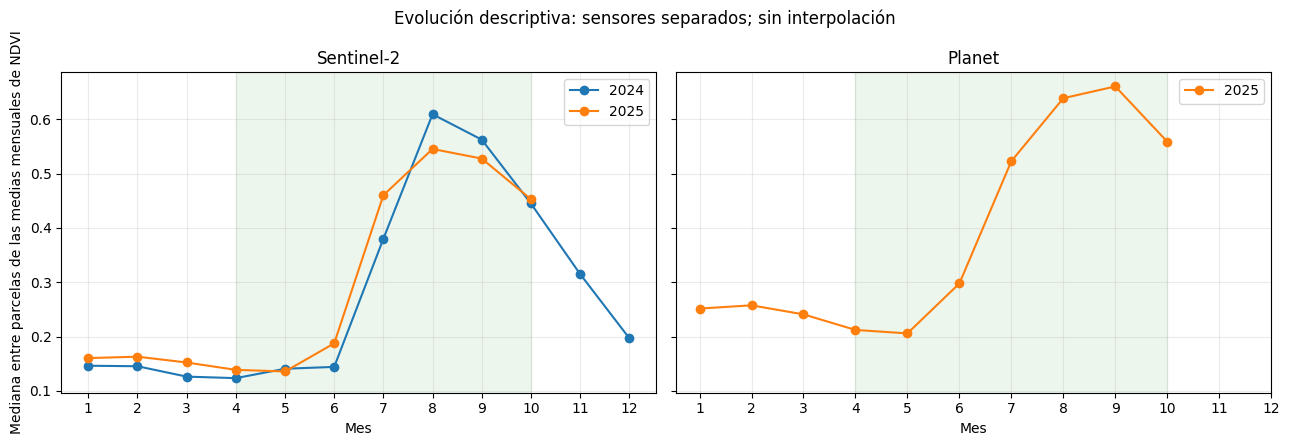

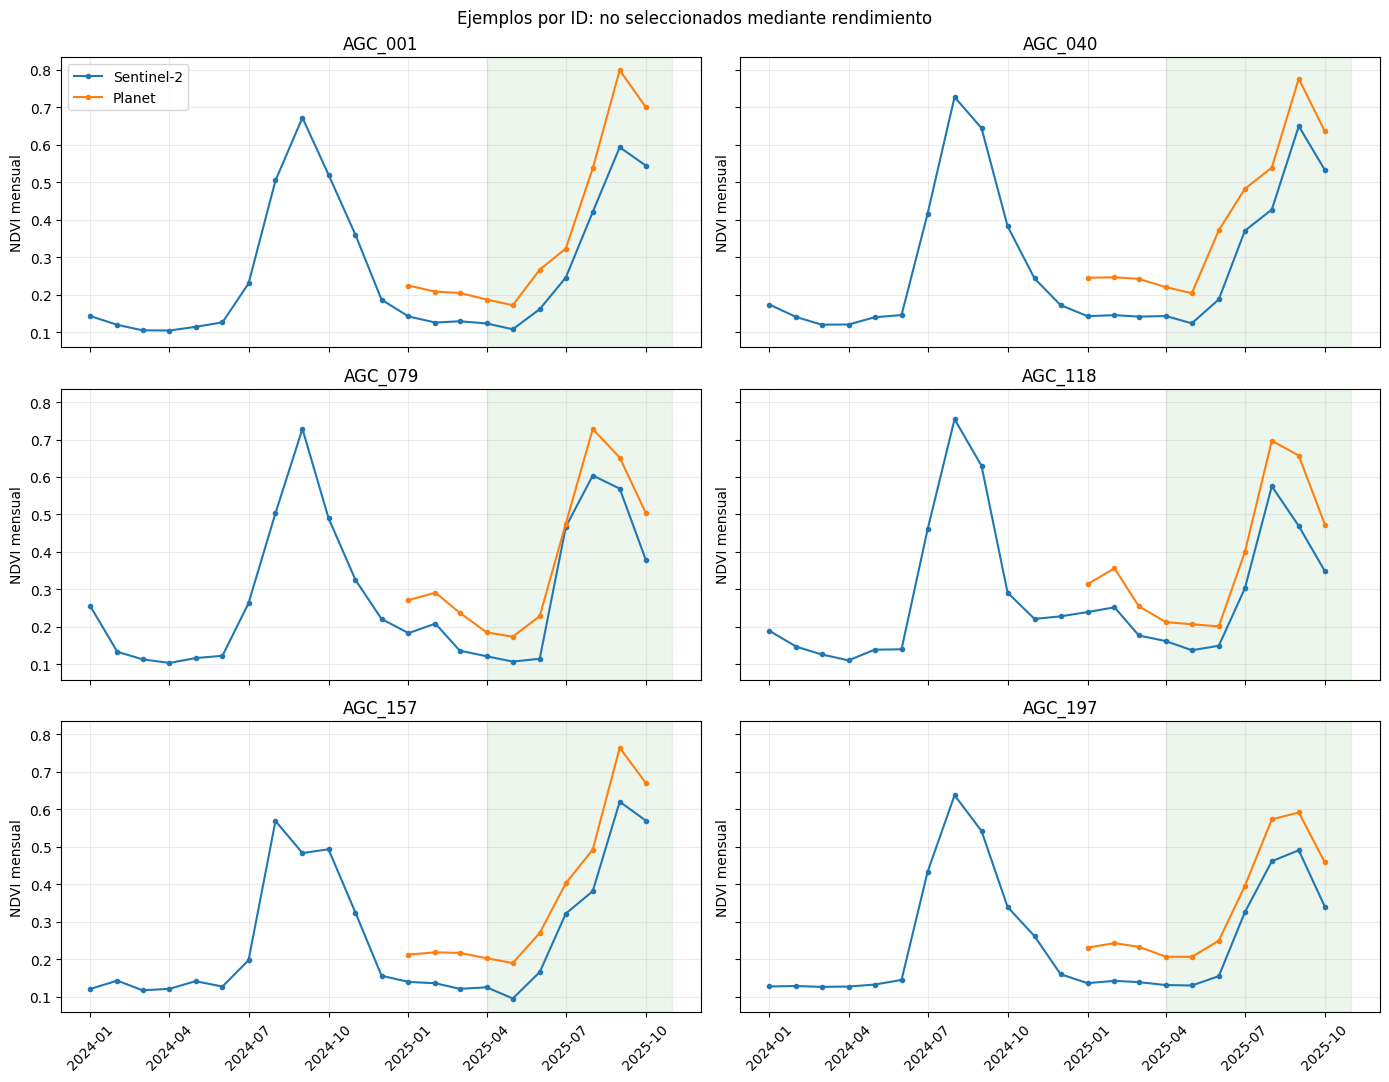


COBERTURA POR VENTANA


,ventana,sensor,parcelas,meses_esperados,parcelas_con_algun_ndvi,meses_disponibles_mediana,meses_disponibles_min,meses_disponibles_max
0,antecedente_3m_ene_mar2025,Planet,197,3,197,3.0,3,3
1,antecedente_3m_ene_mar2025,Sentinel-2,197,3,197,3.0,3,3
2,antecedente_6m_oct2024_mar2025,Planet,197,6,197,3.0,3,3
3,antecedente_6m_oct2024_mar2025,Sentinel-2,197,6,197,6.0,6,6
4,ciclo_2024_abril_octubre,Planet,197,7,0,0.0,0,0
5,ciclo_2024_abril_octubre,Sentinel-2,197,7,197,7.0,6,7
6,ciclo_2025_abril_octubre,Planet,197,7,197,7.0,7,7
7,ciclo_2025_abril_octubre,Sentinel-2,197,7,197,7.0,7,7



RESUMEN DE PERFILES


,sensor,anio,parcelas,cobertura_completa,maximos_resumibles,maximos_en_borde,perfiles_con_empate
0,Planet,2024,197,0,0,0,0
1,Planet,2025,197,197,197,18,0
2,Sentinel-2,2024,197,193,197,14,0
3,Sentinel-2,2025,197,197,197,30,0



DISTRIBUCIÓN DEL MES CON MÁXIMO OBSERVADO


,sensor,anio,cobertura_completa,mes_maximo_observado,parcelas,total_perfiles_del_grupo,porcentaje_del_grupo
0,Planet,2025,True,7,6,197,3.045685
1,Planet,2025,True,8,79,197,40.101523
2,Planet,2025,True,9,94,197,47.715736
3,Planet,2025,True,10,18,197,9.137056
4,Sentinel-2,2024,False,8,4,4,100.000000
5,Sentinel-2,2024,True,7,1,193,0.518135
6,Sentinel-2,2024,True,8,120,193,62.176166
7,Sentinel-2,2024,True,9,58,193,30.051813
8,Sentinel-2,2024,True,10,14,193,7.253886
9,Sentinel-2,2025,True,7,11,197,5.583756



COBERTURA Y CURVA AGREGADA DEL CICLO 2025


,sensor,fecha_mes,parcelas,parcelas_con_capturas,parcelas_con_ndvi,observaciones_validas,capturas,capturas_nubosidad_100,ndvi_medio_entre_parcelas,ndvi_mediano_entre_parcelas,porcentaje_parcelas_con_ndvi,anio,mes
15,Planet,2025-04-01,197,197,197,4476,4760,284,0.216984,0.212240,100.0,2025,4
16,Planet,2025-05-01,197,197,197,3118,4436,1318,0.209711,0.205846,100.0,2025,5
17,Planet,2025-06-01,197,197,197,1222,2213,991,0.308197,0.297800,100.0,2025,6
18,Planet,2025-07-01,197,197,197,1796,2940,1144,0.534203,0.522875,100.0,2025,7
19,Planet,2025-08-01,197,197,197,3215,4381,1166,0.633322,0.638800,100.0,2025,8
20,Planet,2025-09-01,197,197,197,2142,3964,1822,0.665238,0.660500,100.0,2025,9
21,Planet,2025-10-01,197,197,197,2279,3561,1282,0.562693,0.558778,100.0,2025,10
37,Sentinel-2,2025-04-01,197,197,197,1530,1576,46,0.145254,0.138750,100.0,2025,4
38,Sentinel-2,2025-05-01,197,197,197,911,1379,468,0.140236,0.135750,100.0,2025,5
39,Sentinel-2,2025-06-01,197,197,197,631,1576,945,0.200942,0.187500,100.0,2025,6



No se utilizó rendimiento.
No se modificaron las tablas ni la entrega vigente.
Los meses de máximo son descriptivos, no fechas de siembra.
Los huecos visibles se conservaron sin interpolación.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\experimento_4_temporal\bloque_56_20261018_231343_553625

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\experimento_4_temporal\bloque_56_20261018_231343_553625\revision_bloque_56.txt


In [68]:
# Bloque 56: Diagnóstico temporal de NDVI para el experimento 4.
# Periodo: enero de 2024 a octubre de 2025.
# No utiliza rendimiento, no entrena y no modifica tablas anteriores.

from datetime import datetime
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# ============================================================
# 1. DEFINIR EL ALCANCE ANTES DE MIRAR LOS RESULTADOS.
# ============================================================

inicio_temporal_56 = pd.Timestamp("2024-01-01")
fin_temporal_exclusivo_56 = pd.Timestamp("2025-11-01")

meses_calendario_56 = pd.date_range(
    inicio_temporal_56,
    "2025-10-01",
    freq="MS",
)

# Umbral descriptivo, no criterio agronómico validado.
# Con menos de cuatro meses disponibles no resumiremos el máximo.
min_meses_para_maximo_56 = 4

ids_temporal_56 = sorted(
    df_rendimiento["ID_POLIGONO"].astype(str).tolist()
)

assert len(ids_temporal_56) == 197
assert len(set(ids_temporal_56)) == 197

# No se accede a la columna de rendimiento.
columnas_observaciones_56 = [
    "ID_POLIGONO",
    "fecha_captura",
    "sensor",
    "ndvi_promedio",
    "porcentaje_nubosidad",
]

fuentes_temporales_56 = {
    "Sentinel-2": df_basico_preparado,
    "Planet": df_pro_preparado,
}


# ============================================================
# 2. RECUPERAR OBSERVACIONES SIN CAMBIAR LOS FILTROS PREVIOS.
# ============================================================

observaciones_por_sensor_56 = []

for sensor_56, fuente_56 in fuentes_temporales_56.items():
    assert set(columnas_observaciones_56).issubset(
        fuente_56.columns
    ), f"Faltan columnas en la fuente de {sensor_56}."

    datos_56 = fuente_56.loc[
        fuente_56["sensor"].eq(sensor_56),
        columnas_observaciones_56,
    ].copy()

    assert datos_56["ID_POLIGONO"].notna().all()

    datos_56["ID_POLIGONO"] = (
        datos_56["ID_POLIGONO"].astype(str)
    )

    # Las tablas preparadas ya deben tener fechas interpretadas.
    assert pd.api.types.is_datetime64_any_dtype(
        datos_56["fecha_captura"]
    ), (
        "fecha_captura no es datetime. "
        "Revisa o ejecuta el bloque 18."
    )

    datos_56 = datos_56.loc[
        datos_56["fecha_captura"].ge(inicio_temporal_56)
        & datos_56["fecha_captura"].lt(
            fin_temporal_exclusivo_56
        )
    ].copy()

    assert not datos_56.empty, (
        f"No hay observaciones de {sensor_56} en el periodo."
    )

    assert set(datos_56["ID_POLIGONO"]).issubset(
        ids_temporal_56
    )

    assert not datos_56.duplicated([
        "ID_POLIGONO",
        "fecha_captura",
        "sensor",
    ]).any(), f"Hay observaciones duplicadas en {sensor_56}."

    for columna_56 in [
        "ndvi_promedio",
        "porcentaje_nubosidad",
    ]:
        datos_56[columna_56] = pd.to_numeric(
            datos_56[columna_56],
            errors="raise",
        ).astype(float)

    assert not np.isinf(
        datos_56[
            ["ndvi_promedio", "porcentaje_nubosidad"]
        ].to_numpy()
    ).any()

    datos_56["fecha_mes"] = (
        datos_56["fecha_captura"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

    datos_56["nubosidad_100"] = (
        datos_56["porcentaje_nubosidad"].eq(100)
    )

    observaciones_por_sensor_56.append(datos_56)

observaciones_ndvi_56 = pd.concat(
    observaciones_por_sensor_56,
    ignore_index=True,
)

# Se conserva la preparación anterior.
# No se aplica aquí un nuevo umbral de nubosidad.
casos_nube100_con_ndvi_56 = observaciones_ndvi_56.loc[
    observaciones_ndvi_56["nubosidad_100"]
    & observaciones_ndvi_56["ndvi_promedio"].notna()
].copy()


# ============================================================
# 3. RESUMIR POR PARCELA, SENSOR Y MES.
# ============================================================

mensual_observado_56 = (
    observaciones_ndvi_56
    .groupby(
        ["sensor", "ID_POLIGONO", "fecha_mes"]
    )
    .agg(
        ndvi_media=("ndvi_promedio", "mean"),
        ndvi_mediana=("ndvi_promedio", "median"),
        n_observaciones_validas=("ndvi_promedio", "count"),
        n_capturas=("fecha_captura", "size"),
        capturas_nubosidad_100=("nubosidad_100", "sum"),
        nubosidad_media=("porcentaje_nubosidad", "mean"),
    )
)

# Calendario completo para hacer visibles los meses sin fuente
# y los meses con capturas pero sin NDVI válido.
calendario_completo_56 = pd.MultiIndex.from_product(
    [
        list(fuentes_temporales_56),
        ids_temporal_56,
        meses_calendario_56,
    ],
    names=["sensor", "ID_POLIGONO", "fecha_mes"],
)

ndvi_mensual_56 = (
    mensual_observado_56
    .reindex(calendario_completo_56)
    .reset_index()
)

columnas_conteos_56 = [
    "n_observaciones_validas",
    "n_capturas",
    "capturas_nubosidad_100",
]

ndvi_mensual_56[columnas_conteos_56] = (
    ndvi_mensual_56[columnas_conteos_56]
    .fillna(0)
    .astype(int)
)

ndvi_mensual_56["hay_capturas"] = (
    ndvi_mensual_56["n_capturas"].gt(0)
)

ndvi_mensual_56["hay_ndvi_valido"] = (
    ndvi_mensual_56["n_observaciones_validas"].gt(0)
)

ndvi_mensual_56["anio"] = (
    ndvi_mensual_56["fecha_mes"].dt.year
)

ndvi_mensual_56["mes"] = (
    ndvi_mensual_56["fecha_mes"].dt.month
)

assert not ndvi_mensual_56.duplicated([
    "sensor", "ID_POLIGONO", "fecha_mes"
]).any()

assert len(ndvi_mensual_56) == (
    2 * 197 * len(meses_calendario_56)
)


# ============================================================
# 4. COBERTURA Y CURVAS AGREGADAS.
# ============================================================

cobertura_mensual_56 = (
    ndvi_mensual_56
    .groupby(["sensor", "fecha_mes"])
    .agg(
        parcelas=("ID_POLIGONO", "nunique"),
        parcelas_con_capturas=("hay_capturas", "sum"),
        parcelas_con_ndvi=("hay_ndvi_valido", "sum"),
        observaciones_validas=(
            "n_observaciones_validas", "sum"
        ),
        capturas=("n_capturas", "sum"),
        capturas_nubosidad_100=(
            "capturas_nubosidad_100", "sum"
        ),
        ndvi_medio_entre_parcelas=("ndvi_media", "mean"),
        ndvi_mediano_entre_parcelas=(
            "ndvi_media", "median"
        ),
    )
    .reset_index()
)

cobertura_mensual_56["porcentaje_parcelas_con_ndvi"] = (
    100
    * cobertura_mensual_56["parcelas_con_ndvi"]
    / cobertura_mensual_56["parcelas"]
)

cobertura_mensual_56["anio"] = (
    cobertura_mensual_56["fecha_mes"].dt.year
)

cobertura_mensual_56["mes"] = (
    cobertura_mensual_56["fecha_mes"].dt.month
)


# ============================================================
# 5. REVISAR VENTANAS POSIBLES SIN UTILIZAR RENDIMIENTO.
# ============================================================

ventanas_56 = {
    "ciclo_2024_abril_octubre": (
        "2024-04-01", "2024-11-01"
    ),
    "antecedente_6m_oct2024_mar2025": (
        "2024-10-01", "2025-04-01"
    ),
    "antecedente_3m_ene_mar2025": (
        "2025-01-01", "2025-04-01"
    ),
    "ciclo_2025_abril_octubre": (
        "2025-04-01", "2025-11-01"
    ),
}

filas_ventanas_56 = []
filas_perfiles_56 = []

for nombre_ventana_56, (inicio_56, fin_56) in ventanas_56.items():
    inicio_56 = pd.Timestamp(inicio_56)
    fin_56 = pd.Timestamp(fin_56)

    n_meses_esperados_56 = len(pd.date_range(
        inicio_56,
        fin_56 - pd.Timedelta(days=1),
        freq="MS",
    ))

    subset_56 = ndvi_mensual_56.loc[
        ndvi_mensual_56["fecha_mes"].ge(inicio_56)
        & ndvi_mensual_56["fecha_mes"].lt(fin_56)
    ]

    for (sensor_56, id_56), grupo_56 in subset_56.groupby(
        ["sensor", "ID_POLIGONO"]
    ):
        grupo_56 = grupo_56.sort_values("fecha_mes")
        validos_56 = grupo_56.loc[
            grupo_56["ndvi_media"].notna()
        ]

        n_validos_56 = len(validos_56)

        filas_ventanas_56.append({
            "ventana": nombre_ventana_56,
            "sensor": sensor_56,
            "ID_POLIGONO": id_56,
            "meses_esperados": n_meses_esperados_56,
            "meses_con_capturas": int(
                grupo_56["hay_capturas"].sum()
            ),
            "meses_con_ndvi": n_validos_56,
            "observaciones_validas": int(
                grupo_56["n_observaciones_validas"].sum()
            ),
            "ndvi_medio_ventana": (
                validos_56["ndvi_media"].mean()
            ),
        })

        # Los máximos se describen solo en abril–octubre,
        # comparando el mismo intervalo de 2024 y 2025.
        if nombre_ventana_56.startswith("ciclo_"):
            perfil_56 = {
                "sensor": sensor_56,
                "ID_POLIGONO": id_56,
                "anio": inicio_56.year,
                "meses_esperados": n_meses_esperados_56,
                "meses_con_ndvi": n_validos_56,
                "cobertura_completa": (
                    n_validos_56 == n_meses_esperados_56
                ),
                "maximo_resumible": (
                    n_validos_56 >= min_meses_para_maximo_56
                ),
                "ndvi_medio_ciclo": (
                    validos_56["ndvi_media"].mean()
                ),
                "ndvi_minimo": (
                    validos_56["ndvi_media"].min()
                ),
                "ndvi_maximo": (
                    validos_56["ndvi_media"].max()
                ),
                "amplitud_observada": (
                    validos_56["ndvi_media"].max()
                    - validos_56["ndvi_media"].min()
                ),
                "mes_maximo_observado": np.nan,
                "numero_meses_empatados_maximo": 0,
                "maximo_en_borde_abril_octubre": False,
            }

            if perfil_56["maximo_resumible"]:
                maximo_56 = validos_56["ndvi_media"].max()

                empatados_56 = validos_56.loc[
                    np.isclose(
                        validos_56["ndvi_media"],
                        maximo_56,
                        rtol=0,
                        atol=1e-10,
                    )
                ].sort_values("fecha_mes")

                mes_maximo_56 = int(
                    empatados_56.iloc[0]["mes"]
                )

                perfil_56["mes_maximo_observado"] = (
                    mes_maximo_56
                )
                perfil_56[
                    "numero_meses_empatados_maximo"
                ] = len(empatados_56)

                perfil_56[
                    "maximo_en_borde_abril_octubre"
                ] = mes_maximo_56 in (4, 10)

            filas_perfiles_56.append(perfil_56)

cobertura_por_parcela_56 = pd.DataFrame(
    filas_ventanas_56
)

perfiles_ciclo_56 = pd.DataFrame(filas_perfiles_56)

perfiles_ciclo_56["mes_maximo_observado"] = (
    perfiles_ciclo_56["mes_maximo_observado"]
    .astype("Int64")
)

resumen_ventanas_56 = (
    cobertura_por_parcela_56
    .groupby(["ventana", "sensor"])
    .agg(
        parcelas=("ID_POLIGONO", "nunique"),
        meses_esperados=("meses_esperados", "first"),
        parcelas_con_algun_ndvi=(
            "meses_con_ndvi",
            lambda x: int(x.gt(0).sum()),
        ),
        meses_disponibles_mediana=(
            "meses_con_ndvi", "median"
        ),
        meses_disponibles_min=(
            "meses_con_ndvi", "min"
        ),
        meses_disponibles_max=(
            "meses_con_ndvi", "max"
        ),
    )
    .reset_index()
)


# ============================================================
# 6. DISTRIBUCIÓN DE MESES CON MÁXIMO OBSERVADO.
# ============================================================

# Se separa la cobertura completa para no mezclarla con
# perfiles que podrían haber perdido el verdadero máximo.
perfiles_resumibles_56 = perfiles_ciclo_56.loc[
    perfiles_ciclo_56["maximo_resumible"]
].copy()

frecuencia_maximos_56 = (
    perfiles_resumibles_56
    .groupby([
        "sensor",
        "anio",
        "cobertura_completa",
        "mes_maximo_observado",
    ])
    .size()
    .rename("parcelas")
    .reset_index()
)

if not frecuencia_maximos_56.empty:
    frecuencia_maximos_56["total_perfiles_del_grupo"] = (
        frecuencia_maximos_56
        .groupby([
            "sensor", "anio", "cobertura_completa"
        ])["parcelas"]
        .transform("sum")
    )

    frecuencia_maximos_56["porcentaje_del_grupo"] = (
        100
        * frecuencia_maximos_56["parcelas"]
        / frecuencia_maximos_56["total_perfiles_del_grupo"]
    )

resumen_perfiles_56 = (
    perfiles_ciclo_56
    .groupby(["sensor", "anio"])
    .agg(
        parcelas=("ID_POLIGONO", "nunique"),
        cobertura_completa=("cobertura_completa", "sum"),
        maximos_resumibles=("maximo_resumible", "sum"),
        maximos_en_borde=(
            "maximo_en_borde_abril_octubre", "sum"
        ),
        perfiles_con_empate=(
            "numero_meses_empatados_maximo",
            lambda x: int(x.gt(1).sum()),
        ),
    )
    .reset_index()
)


# ============================================================
# 7. EJEMPLOS FIJADOS POR ORDEN DE ID, NO POR RENDIMIENTO.
# ============================================================

posiciones_ejemplos_56 = np.linspace(
    0,
    len(ids_temporal_56) - 1,
    num=6,
    dtype=int,
)

ids_ejemplos_56 = [
    ids_temporal_56[i]
    for i in posiciones_ejemplos_56
]

ejemplos_perfiles_56 = perfiles_ciclo_56.loc[
    perfiles_ciclo_56["ID_POLIGONO"].isin(ids_ejemplos_56)
].copy()


# ============================================================
# 8. GUARDAR TABLAS, PLAN Y FIGURAS.
# ============================================================

carpeta_temporal_56 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_004"
    / "bloques_56_57_58_temporal"
    / f"bloque_56_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_temporal_56.mkdir(
    parents=True,
    exist_ok=False,
)

plan_temporal_56 = {
    "objetivo": "diagnostico temporal, no entrenamiento",
    "periodo": [
        str(inicio_temporal_56.date()),
        str((fin_temporal_exclusivo_56
             - pd.Timedelta(days=1)).date()),
    ],
    "sensores": list(fuentes_temporales_56),
    "variable": "ndvi_promedio",
    "min_meses_para_resumir_maximo": (
        min_meses_para_maximo_56
    ),
    "ventanas": ventanas_56,
    "ids_ejemplos": ids_ejemplos_56,
    "notas": [
        "No se utiliza rendimiento.",
        "Se mantienen las observaciones de las tablas preparadas.",
        "No se impone un umbral nuevo de nubosidad.",
        "No se interpolan ni suavizan valores.",
        "No se fusionan valores de sensores diferentes.",
        "Planet 2024 no se inventa ni se imputa.",
        "Maximos calculados sobre medias mensuales abril-octubre.",
        "En empates se registra el primer mes y el numero de empates.",
        "El maximo observado no identifica una fecha de siembra.",
        "Todas las series se cortan antes de noviembre de 2025.",
        "Se incluyen las 197 parcelas para descripcion, no seleccion supervisada.",
    ],
}

(carpeta_temporal_56 / "plan.json").write_text(
    json.dumps(
        plan_temporal_56,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

for nombre_archivo_56, tabla_56 in [
    ("ndvi_mensual.csv", ndvi_mensual_56),
    ("cobertura_mensual.csv", cobertura_mensual_56),
    ("cobertura_por_parcela_ventana.csv", cobertura_por_parcela_56),
    ("resumen_ventanas.csv", resumen_ventanas_56),
    ("perfiles_ciclo.csv", perfiles_ciclo_56),
    ("frecuencia_maximos.csv", frecuencia_maximos_56),
    ("resumen_perfiles.csv", resumen_perfiles_56),
    ("casos_nube100_con_ndvi.csv", casos_nube100_con_ndvi_56),
]:
    tabla_56.to_csv(
        carpeta_temporal_56 / nombre_archivo_56,
        index=False,
        encoding="utf-8-sig",
    )

# Figura 1: mediana mensual entre parcelas, por sensor y año.
# Cada parcela aporta una media mensual; no se pondera por
# cantidad de capturas.
fig_56, axes_56 = plt.subplots(
    1, 2,
    figsize=(13, 4.5),
    sharey=True,
)

for ax_56, sensor_56 in zip(
    axes_56,
    fuentes_temporales_56,
):
    for anio_56, color_56 in [
        (2024, "tab:blue"),
        (2025, "tab:orange"),
    ]:
        curva_56 = cobertura_mensual_56.loc[
            cobertura_mensual_56["sensor"].eq(sensor_56)
            & cobertura_mensual_56["anio"].eq(anio_56)
        ].sort_values("mes")

        if curva_56["ndvi_mediano_entre_parcelas"].notna().any():
            ax_56.plot(
                curva_56["mes"],
                curva_56["ndvi_mediano_entre_parcelas"],
                marker="o",
                color=color_56,
                label=str(anio_56),
            )

    ax_56.axvspan(4, 10, color="green", alpha=0.07)
    ax_56.set_title(sensor_56)
    ax_56.set_xlabel("Mes")
    ax_56.set_xticks(range(1, 13))
    ax_56.grid(alpha=0.25)

    handles_56, labels_56 = ax_56.get_legend_handles_labels()
    if handles_56:
        ax_56.legend()

axes_56[0].set_ylabel(
    "Mediana entre parcelas de las medias mensuales de NDVI"
)

fig_56.suptitle(
    "Evolución descriptiva: sensores separados; sin interpolación"
)

fig_56.tight_layout()
fig_56.savefig(
    carpeta_temporal_56 / "curvas_agregadas_ndvi.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()
plt.close(fig_56)

# Figura 2: trayectorias individuales.
fig_ej_56, axes_ej_56 = plt.subplots(
    3, 2,
    figsize=(14, 11),
    sharex=True,
    sharey=True,
)

for ax_56, id_56 in zip(
    axes_ej_56.flat,
    ids_ejemplos_56,
):
    for sensor_56, color_56 in [
        ("Sentinel-2", "tab:blue"),
        ("Planet", "tab:orange"),
    ]:
        curva_56 = ndvi_mensual_56.loc[
            ndvi_mensual_56["ID_POLIGONO"].eq(id_56)
            & ndvi_mensual_56["sensor"].eq(sensor_56)
        ].sort_values("fecha_mes")

        ax_56.plot(
            curva_56["fecha_mes"],
            curva_56["ndvi_media"],
            marker="o",
            markersize=3,
            color=color_56,
            label=sensor_56,
        )

    ax_56.axvspan(
        pd.Timestamp("2025-04-01"),
        pd.Timestamp("2025-10-31"),
        color="green",
        alpha=0.07,
    )
    ax_56.set_title(id_56)
    ax_56.set_ylabel("NDVI mensual")
    ax_56.grid(alpha=0.25)
    ax_56.tick_params(axis="x", rotation=45)

axes_ej_56.flat[0].legend()
fig_ej_56.suptitle(
    "Ejemplos por ID: no seleccionados mediante rendimiento"
)

fig_ej_56.tight_layout()
fig_ej_56.savefig(
    carpeta_temporal_56 / "curvas_individuales_ndvi.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()
plt.close(fig_ej_56)


# ============================================================
# 9. TXT PARA COMPARTIR.
# ============================================================

ruta_reporte_56 = (
    carpeta_temporal_56 / "revision_bloque_56.txt"
)

cobertura_ciclo2025_56 = cobertura_mensual_56.loc[
    cobertura_mensual_56["fecha_mes"].between(
        "2025-04-01",
        "2025-10-01",
    )
].copy()

with ruta_reporte_56.open("w", encoding="utf-8") as archivo_56:
    archivo_56.write(
        "EXPERIMENTO 4: DIAGNOSTICO TEMPORAL DE NDVI\n\n"
        "No se utilizo rendimiento ni se entrenaron modelos.\n"
        "No se cambiaron las bases de 33 y 213 variables.\n"
        "No se interpolaron ni suavizaron curvas.\n"
        "Sentinel-2 y Planet se analizaron por separado.\n"
        "Maximos: medias mensuales de abril-octubre.\n"
        "Minimo descriptivo para resumir maximo: 4 meses.\n"
        "Un maximo no es una fecha observada de siembra.\n"
        "Un maximo en abril u octubre puede estar limitado "
        "por la ventana analizada.\n"
        "En empates se registra el primer mes observado.\n\n"
    )

    archivo_56.write(
        "Casos con nubosidad 100 y NDVI presente: "
        f"{len(casos_nube100_con_ndvi_56)}\n\n"
    )

    for titulo_56, tabla_56 in [
        ("COBERTURA POR VENTANA", resumen_ventanas_56),
        ("RESUMEN DE PERFILES", resumen_perfiles_56),
        ("MESES CON MAXIMO OBSERVADO", frecuencia_maximos_56),
        (
            "COBERTURA Y CURVA AGREGADA ABRIL-OCTUBRE 2025",
            cobertura_ciclo2025_56,
        ),
        ("PERFILES DE LAS SEIS PARCELAS DE EJEMPLO", ejemplos_perfiles_56),
    ]:
        archivo_56.write(titulo_56 + "\n\n")
        archivo_56.write(
            tabla_56.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_56.write("\n\n")


# ============================================================
# 10. MOSTRAR RESULTADOS.
# ============================================================

print("\nCOBERTURA POR VENTANA")
display(resumen_ventanas_56)

print("\nRESUMEN DE PERFILES")
display(resumen_perfiles_56)

print("\nDISTRIBUCIÓN DEL MES CON MÁXIMO OBSERVADO")
display(frecuencia_maximos_56)

print("\nCOBERTURA Y CURVA AGREGADA DEL CICLO 2025")
display(cobertura_ciclo2025_56)

if not casos_nube100_con_ndvi_56.empty:
    print(
        "\nATENCIÓN: hay capturas con nubosidad 100 "
        "y NDVI presente. Revisarlas antes de construir "
        "las nuevas variables."
    )
    display(casos_nube100_con_ndvi_56.head(10))

print(
    "\nNo se utilizó rendimiento."
    "\nNo se modificaron las tablas ni la entrega vigente."
    "\nLos meses de máximo son descriptivos, no fechas de siembra."
    "\nLos huecos visibles se conservaron sin interpolación."
)

print(f"\nResultados: {carpeta_temporal_56.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_56.resolve()}")

In [69]:
# Bloque 57: Construir tablas temporales del experimento 4.
# No utiliza los valores de rendimiento, no entrena ni imputa.
# Conserva intactas las bases y los modelos anteriores.

from datetime import datetime
import hashlib
import json

import numpy as np
import pandas as pd


# ============================================================
# 1. IDENTIFICADORES Y BASES DE REFERENCIA.
# ============================================================

metadatos_e4_57 = df_eda_parcela[
    ["ID_POLIGONO", "CONJUNTO"]
].copy()

metadatos_e4_57["ID_POLIGONO"] = (
    metadatos_e4_57["ID_POLIGONO"].astype(str)
)

assert metadatos_e4_57["ID_POLIGONO"].is_unique
assert len(metadatos_e4_57) == 197

metadatos_e4_57 = (
    metadatos_e4_57
    .set_index("ID_POLIGONO")
    .sort_index()
)

ids_e4_57 = metadatos_e4_57.index

ids_train_e4_57 = X_ciclo.index.copy()

ids_pred_e4_57 = metadatos_e4_57.index[
    metadatos_e4_57["CONJUNTO"].eq("PREDICCION")
]

assert len(ids_train_e4_57) == 138
assert len(ids_pred_e4_57) == 59

assert set(ids_train_e4_57).isdisjoint(ids_pred_e4_57)

assert set(ids_train_e4_57) | set(ids_pred_e4_57) == set(
    ids_e4_57
)

assert metadatos_e4_57.loc[
    ids_train_e4_57, "CONJUNTO"
].eq("ENTRENAMIENTO").all()

def preparar_indice_57(tabla):
    copia = tabla.copy()
    assert copia["ID_POLIGONO"].notna().all()
    copia["ID_POLIGONO"] = copia["ID_POLIGONO"].astype(str)
    assert copia["ID_POLIGONO"].is_unique
    return copia.set_index("ID_POLIGONO")

tabla_ciclo_fuente_57 = preparar_indice_57(df_eda_parcela)
tabla_mensual_fuente_57 = preparar_indice_57(df_parcela_meses)

columnas_ciclo_base_57 = X_ciclo.columns.tolist()
columnas_mensual_base_57 = X_mensual.columns.tolist()

base_ciclo_e4_57 = (
    tabla_ciclo_fuente_57
    .loc[ids_e4_57, columnas_ciclo_base_57]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

base_mensual_e4_57 = (
    tabla_mensual_fuente_57
    .loc[ids_e4_57, columnas_mensual_base_57]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

assert base_ciclo_e4_57.shape == (197, 33)
assert base_mensual_e4_57.shape == (197, 213)

# Confirmar que el entrenamiento de referencia no cambió.
pd.testing.assert_frame_equal(
    base_ciclo_e4_57.loc[ids_train_e4_57],
    X_ciclo.astype(float),
    check_names=False,
)

pd.testing.assert_frame_equal(
    base_mensual_e4_57.loc[ids_train_e4_57],
    X_mensual.astype(float),
    check_names=False,
)


# ============================================================
# 2. RECUPERAR EL NDVI DEL BLOQUE 56.
# ============================================================

ndvi_fuente_e4_57 = ndvi_mensual_56[
    ["sensor", "ID_POLIGONO", "fecha_mes", "ndvi_media"]
].copy()

ndvi_fuente_e4_57["ID_POLIGONO"] = (
    ndvi_fuente_e4_57["ID_POLIGONO"].astype(str)
)

assert pd.api.types.is_datetime64_any_dtype(
    ndvi_fuente_e4_57["fecha_mes"]
)

assert not ndvi_fuente_e4_57.duplicated([
    "sensor", "ID_POLIGONO", "fecha_mes"
]).any()

meses_ciclo_e4_57 = pd.date_range(
    "2025-04-01", "2025-10-01", freq="MS"
)

meses_3m_e4_57 = pd.date_range(
    "2025-01-01", "2025-03-01", freq="MS"
)

meses_6m_e4_57 = pd.date_range(
    "2024-10-01", "2025-03-01", freq="MS"
)

meses_oct_dic_e4_57 = pd.date_range(
    "2024-10-01", "2024-12-01", freq="MS"
)

ndvi_ancho_por_sensor_57 = {}

for sensor_57 in ("Sentinel-2", "Planet"):
    ancho_57 = (
        ndvi_fuente_e4_57.loc[
            ndvi_fuente_e4_57["sensor"].eq(sensor_57)
        ]
        .pivot(
            index="ID_POLIGONO",
            columns="fecha_mes",
            values="ndvi_media",
        )
        .reindex(index=ids_e4_57)
    )

    ndvi_ancho_por_sensor_57[sensor_57] = ancho_57


# ============================================================
# 3. DINÁMICA DEL NDVI EN 2025: SEIS VARIABLES POR SENSOR.
# ============================================================

dinamica_ndvi_e4_57 = pd.DataFrame(index=ids_e4_57)

diccionario_nuevas_57 = []

def registrar_variable_57(
    variable,
    grupo,
    descripcion,
    periodo,
    sensor,
):
    diccionario_nuevas_57.append({
        "variable": variable,
        "grupo": grupo,
        "descripcion": descripcion,
        "periodo": periodo,
        "sensor_o_fuente": sensor,
    })

for sensor_57, prefijo_57 in [
    ("Sentinel-2", "sentinel2"),
    ("Planet", "planet"),
]:
    ciclo_57 = ndvi_ancho_por_sensor_57[sensor_57].reindex(
        columns=meses_ciclo_e4_57
    )

    # El bloque 56 confirmó los siete meses para ambos sensores.
    assert ciclo_57.notna().all().all(), (
        f"Faltan meses de NDVI en {sensor_57}; "
        "revisar antes de calcular dinámica."
    )

    valores_57 = ciclo_57.to_numpy(dtype=float)

    maximos_57 = valores_57.max(axis=1)
    minimos_57 = valores_57.min(axis=1)
    posiciones_max_57 = valores_57.argmax(axis=1)

    # En caso de empate se toma el primer mes.
    meses_max_57 = meses_ciclo_e4_57.month.to_numpy()[
        posiciones_max_57
    ]

    variables_sensor_57 = {
        f"e4__{prefijo_57}__ndvi_max_ciclo": (
            maximos_57,
            "Máximo de las siete medias mensuales",
        ),
        f"e4__{prefijo_57}__ndvi_mes_max_ciclo": (
            meses_max_57,
            "Primer mes con el máximo observado; no fecha de siembra",
        ),
        f"e4__{prefijo_57}__ndvi_amplitud_ciclo": (
            maximos_57 - minimos_57,
            "Máximo menos mínimo de las medias mensuales",
        ),
        f"e4__{prefijo_57}__ndvi_cambio_jun_ago": (
            (
                ciclo_57[pd.Timestamp("2025-08-01")]
                - ciclo_57[pd.Timestamp("2025-06-01")]
            ).to_numpy(),
            "NDVI de agosto menos NDVI de junio",
        ),
        f"e4__{prefijo_57}__ndvi_cambio_sep_oct": (
            (
                ciclo_57[pd.Timestamp("2025-10-01")]
                - ciclo_57[pd.Timestamp("2025-09-01")]
            ).to_numpy(),
            "NDVI de octubre menos NDVI de septiembre",
        ),
        f"e4__{prefijo_57}__ndvi_max_en_octubre": (
            (meses_max_57 == 10).astype(float),
            "Indicador de máximo en el borde final de la ventana",
        ),
    }

    for variable_57, (
        valores_variable_57,
        descripcion_57,
    ) in variables_sensor_57.items():
        dinamica_ndvi_e4_57[variable_57] = (
            valores_variable_57
        )

        registrar_variable_57(
            variable_57,
            "dinamica_ndvi_2025",
            descripcion_57,
            "abril-octubre 2025",
            sensor_57,
        )

assert dinamica_ndvi_e4_57.shape == (197, 12)
assert dinamica_ndvi_e4_57.notna().all().all()


# ============================================================
# 4. ANTECEDENTES RESUMIDOS DE NDVI.
# ============================================================

antecedentes_ndvi_e4_57 = pd.DataFrame(index=ids_e4_57)

cobertura_antecedentes_57 = pd.DataFrame(index=ids_e4_57)

for sensor_57, prefijo_57 in [
    ("Sentinel-2", "sentinel2"),
    ("Planet", "planet"),
]:
    previos_57 = ndvi_ancho_por_sensor_57[sensor_57].reindex(
        columns=meses_3m_e4_57
    )

    conteos_57 = previos_57.notna().sum(axis=1)

    assert conteos_57.eq(3).all(), (
        f"La ventana de tres meses está incompleta en {sensor_57}."
    )

    variable_57 = f"e4__{prefijo_57}__ndvi_media_ene_mar2025"

    antecedentes_ndvi_e4_57[variable_57] = (
        previos_57.mean(axis=1)
    )

    cobertura_antecedentes_57[
        f"{prefijo_57}__meses_ene_mar2025"
    ] = conteos_57

    registrar_variable_57(
        variable_57,
        "antecedente_ndvi_3m",
        "Media con igual peso de enero, febrero y marzo",
        "enero-marzo 2025",
        sensor_57,
    )

# Solo Sentinel-2 tiene los seis meses completos.
previos_s2_6m_57 = (
    ndvi_ancho_por_sensor_57["Sentinel-2"]
    .reindex(columns=meses_6m_e4_57)
)

conteos_s2_6m_57 = previos_s2_6m_57.notna().sum(axis=1)

assert conteos_s2_6m_57.eq(6).all()

columna_s2_6m_57 = (
    "e4__sentinel2__ndvi_media_oct2024_mar2025"
)

antecedentes_ndvi_e4_57[columna_s2_6m_57] = (
    previos_s2_6m_57.mean(axis=1)
)

cobertura_antecedentes_57[
    "sentinel2__meses_oct2024_mar2025"
] = conteos_s2_6m_57

registrar_variable_57(
    columna_s2_6m_57,
    "antecedente_ndvi_6m",
    "Media con igual peso de seis meses; no incluye Planet 2024",
    "octubre 2024-marzo 2025",
    "Sentinel-2",
)

columnas_ndvi_3m_57 = [
    c for c in antecedentes_ndvi_e4_57.columns
    if c.endswith("ndvi_media_ene_mar2025")
]

assert len(columnas_ndvi_3m_57) == 2


# ============================================================
# 5. MEDICIONES MENSUALES ANTERIORES AL CICLO.
# ============================================================

fuente_mensual_e4_57 = df_base_mensual.copy()

fuente_mensual_e4_57["ID_POLIGONO"] = (
    fuente_mensual_e4_57["ID_POLIGONO"].astype(str)
)

assert pd.api.types.is_datetime64_any_dtype(
    fuente_mensual_e4_57["fecha_mes"]
)

assert not fuente_mensual_e4_57.duplicated([
    "ID_POLIGONO", "fecha_mes"
]).any()

columnas_clima_e4_57 = [
    "precipitacion_mm",
    "tmax_c",
    "tmin_c",
]

columnas_indices_e4_57 = [
    c for c in fuente_mensual_e4_57.columns
    if c.endswith("_media_mensual")
]

assert len(columnas_indices_e4_57) == 27
assert set(columnas_clima_e4_57).issubset(
    fuente_mensual_e4_57.columns
)

# Tres variables climáticas + 27 índices.
mediciones_mensuales_e4_57 = (
    columnas_clima_e4_57 + columnas_indices_e4_57
)

assert len(mediciones_mensuales_e4_57) == 30

# Octubre-diciembre: excluir las cuatro mediciones de Planet.
mediciones_sin_planet_57 = [
    c for c in mediciones_mensuales_e4_57
    if not c.startswith("pro_planet__")
]

assert len(mediciones_sin_planet_57) == 26

def expandir_antecedentes_57(
    meses,
    columnas,
    nombre_grupo,
):
    subset = fuente_mensual_e4_57.loc[
        fuente_mensual_e4_57["fecha_mes"].isin(meses),
        ["ID_POLIGONO", "fecha_mes"] + columnas,
    ].copy()

    claves_esperadas = pd.MultiIndex.from_product(
        [ids_e4_57, meses],
        names=["ID_POLIGONO", "fecha_mes"],
    )

    claves_obtenidas = pd.MultiIndex.from_frame(
        subset[["ID_POLIGONO", "fecha_mes"]]
    )

    assert claves_esperadas.difference(
        claves_obtenidas
    ).empty, "Faltan filas parcela-mes en los antecedentes."

    subset[columnas] = subset[columnas].apply(
        pd.to_numeric,
        errors="raise",
    )

    ancho = subset.pivot(
        index="ID_POLIGONO",
        columns="fecha_mes",
        values=columnas,
    )

    orden = pd.MultiIndex.from_product(
        [columnas, meses],
        names=ancho.columns.names,
    )

    ancho = ancho.reindex(
        index=ids_e4_57,
        columns=orden,
    )

    nuevos_nombres = []

    for variable, fecha in ancho.columns:
        nombre_base = variable.replace(
            "_promedio_media_mensual",
            "__media_mensual",
        )

        nuevo_nombre = (
            f"{nombre_base}__{fecha.strftime('%Y_%m')}"
        )

        nuevos_nombres.append(nuevo_nombre)

        registrar_variable_57(
            nuevo_nombre,
            nombre_grupo,
            f"Medición mensual original: {variable}",
            fecha.strftime("%Y-%m"),
            (
                "Planet"
                if variable.startswith("pro_planet__")
                else "clima / BÁSICO"
            ),
        )

    ancho.columns = nuevos_nombres
    ancho = ancho.astype(float)

    assert ancho.columns.is_unique
    assert not np.isinf(ancho.to_numpy()).any()

    return ancho

mensual_enero_marzo_57 = expandir_antecedentes_57(
    meses=meses_3m_e4_57,
    columnas=mediciones_mensuales_e4_57,
    nombre_grupo="mediciones_mensuales_3m",
)

mensual_octubre_diciembre_57 = expandir_antecedentes_57(
    meses=meses_oct_dic_e4_57,
    columnas=mediciones_sin_planet_57,
    nombre_grupo="mediciones_mensuales_oct_dic2024",
)

assert mensual_enero_marzo_57.shape == (197, 90)
assert mensual_octubre_diciembre_57.shape == (197, 78)

# No se imputan posibles faltantes de VI6T u otros índices.


# ============================================================
# 6. CONSTRUIR LAS CINCO VARIANTES.
# ============================================================

def unir_columnas_e4_57(*tablas):
    for tabla in tablas:
        assert tabla.index.equals(ids_e4_57)

    resultado = pd.concat(tablas, axis=1)

    assert resultado.columns.is_unique
    assert not np.isinf(
        resultado.to_numpy(dtype=float)
    ).any()

    return resultado.astype(float)

tablas_e4_57 = {}

tablas_e4_57["e4_ciclo_dinamica"] = unir_columnas_e4_57(
    base_ciclo_e4_57,
    dinamica_ndvi_e4_57,
)

tablas_e4_57["e4_ciclo_dinamica_3m"] = unir_columnas_e4_57(
    tablas_e4_57["e4_ciclo_dinamica"],
    antecedentes_ndvi_e4_57[columnas_ndvi_3m_57],
)

tablas_e4_57["e4_ciclo_dinamica_6m"] = unir_columnas_e4_57(
    tablas_e4_57["e4_ciclo_dinamica_3m"],
    antecedentes_ndvi_e4_57[[columna_s2_6m_57]],
)

tablas_e4_57["e4_mensual_3m"] = unir_columnas_e4_57(
    base_mensual_e4_57,
    mensual_enero_marzo_57,
)

tablas_e4_57["e4_mensual_6m"] = unir_columnas_e4_57(
    tablas_e4_57["e4_mensual_3m"],
    mensual_octubre_diciembre_57,
)

dimensiones_esperadas_e4_57 = {
    "e4_ciclo_dinamica": 45,
    "e4_ciclo_dinamica_3m": 47,
    "e4_ciclo_dinamica_6m": 48,
    "e4_mensual_3m": 303,
    "e4_mensual_6m": 381,
}

X_train_e4_57 = {}
X_pred_e4_57 = {}
filas_resumen_e4_57 = []
filas_faltantes_e4_57 = []

for nombre_57, tabla_57 in tablas_e4_57.items():
    assert tabla_57.shape == (
        197,
        dimensiones_esperadas_e4_57[nombre_57],
    )

    assert not {
        "ID_POLIGONO",
        "CONJUNTO",
        "RENDIMIENTO_T_HA",
    }.intersection(tabla_57.columns)

    X_train_e4_57[nombre_57] = tabla_57.loc[
        ids_train_e4_57
    ].copy()

    X_pred_e4_57[nombre_57] = tabla_57.loc[
        ids_pred_e4_57
    ].copy()

    train_57 = X_train_e4_57[nombre_57]
    pred_57 = X_pred_e4_57[nombre_57]

    assert train_57.index.equals(X_ciclo.index)
    assert train_57.columns.equals(pred_57.columns)

    # Detectar columnas que una futura imputación no resolvería.
    columnas_totalmente_vacias_57 = (
        train_57.columns[train_57.isna().all()]
        .tolist()
    )

    filas_resumen_e4_57.append({
        "variante": nombre_57,
        "parcelas_totales": len(tabla_57),
        "parcelas_train": len(train_57),
        "parcelas_prediccion": len(pred_57),
        "variables": tabla_57.shape[1],
        "NA_train": int(train_57.isna().sum().sum()),
        "NA_prediccion": int(pred_57.isna().sum().sum()),
        "parcelas_train_con_NA": int(
            train_57.isna().any(axis=1).sum()
        ),
        "columnas_totalmente_vacias_train": len(
            columnas_totalmente_vacias_57
        ),
    })

    for columna_57 in tabla_57.columns:
        n_train_57 = int(train_57[columna_57].isna().sum())
        n_pred_57 = int(pred_57[columna_57].isna().sum())

        if n_train_57 + n_pred_57 > 0:
            filas_faltantes_e4_57.append({
                "variante": nombre_57,
                "variable": columna_57,
                "NA_train": n_train_57,
                "NA_prediccion": n_pred_57,
            })

resumen_tablas_e4_57 = pd.DataFrame(
    filas_resumen_e4_57
)

faltantes_tablas_e4_57 = pd.DataFrame(
    filas_faltantes_e4_57,
    columns=[
        "variante",
        "variable",
        "NA_train",
        "NA_prediccion",
    ],
)

diccionario_e4_57 = pd.DataFrame(
    diccionario_nuevas_57
)

assert diccionario_e4_57["variable"].is_unique


# ============================================================
# 7. GUARDAR SIN SOBRESCRIBIR EXPERIMENTOS ANTERIORES.
# ============================================================

carpeta_tablas_e4_57 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_004"
    / "bloques_56_57_58_temporal"
    / f"bloque_57_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_tablas_e4_57.mkdir(
    parents=True,
    exist_ok=False,
)

def huella_e4_57(tabla):
    contenido = tabla.to_csv(
        index=True,
        float_format="%.17g",
        na_rep="NA",
    ).encode("utf-8")
    return hashlib.sha256(contenido).hexdigest()

plan_tablas_e4_57 = {
    "objetivo": "Construcción de variantes; sin entrenamiento",
    "corte_datos": "2025-10-31",
    "ventanas_antecedentes": {
        "3m": "enero-marzo 2025",
        "6m": "octubre 2024-marzo 2025",
    },
    "notas": [
        "Sin uso de valores de rendimiento.",
        "Sin imputación ni estandarización.",
        "No se cambian las bases anteriores.",
        "Los descriptores son de NDVI mensual, no fases observadas.",
        "La versión resumida 6m conserva también los resúmenes 3m.",
        "Planet 2024 se excluye, no se inventa.",
        "La versión mensual 6m conserva Planet de enero-marzo.",
        "No se incorpora noviembre-diciembre de 2025.",
        "Las 59 parcelas no se usan para elegir parámetros.",
        "El conjunto con más columnas no se considera mejor por defecto.",
    ],
    "variantes": {},
}

for nombre_57, tabla_57 in tablas_e4_57.items():
    carpeta_variante_57 = carpeta_tablas_e4_57 / nombre_57
    carpeta_variante_57.mkdir(exist_ok=False)

    for archivo_57, datos_57 in [
        ("X_197_parcelas.csv", tabla_57),
        ("X_train_138.csv", X_train_e4_57[nombre_57]),
        ("X_prediccion_59.csv", X_pred_e4_57[nombre_57]),
    ]:
        datos_57.to_csv(
            carpeta_variante_57 / archivo_57,
            index=True,
            index_label="ID_POLIGONO",
            encoding="utf-8-sig",
        )

    plan_tablas_e4_57["variantes"][nombre_57] = {
        "variables": tabla_57.shape[1],
        "columnas": tabla_57.columns.tolist(),
        "huella_tabla_completa": huella_e4_57(tabla_57),
        "huella_train": huella_e4_57(
            X_train_e4_57[nombre_57]
        ),
    }

for archivo_57, tabla_57, con_indice_57 in [
    ("resumen_variantes.csv", resumen_tablas_e4_57, False),
    ("faltantes_por_variable.csv", faltantes_tablas_e4_57, False),
    ("diccionario_nuevas_variables.csv", diccionario_e4_57, False),
    ("cobertura_antecedentes_ndvi.csv", cobertura_antecedentes_57, True),
    ("metadatos_parcelas.csv", metadatos_e4_57, True),
]:
    tabla_57.to_csv(
        carpeta_tablas_e4_57 / archivo_57,
        index=con_indice_57,
        encoding="utf-8-sig",
    )

(carpeta_tablas_e4_57 / "plan.json").write_text(
    json.dumps(
        plan_tablas_e4_57,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)


# ============================================================
# 8. TXT Y COMPROBACIONES FINALES.
# ============================================================

ruta_reporte_57 = (
    carpeta_tablas_e4_57 / "revision_bloque_57.txt"
)

with ruta_reporte_57.open("w", encoding="utf-8") as archivo_57:
    archivo_57.write(
        "EXPERIMENTO 4: TABLAS TEMPORALES\n\n"
        "No se entrenaron modelos ni se usaron valores de rendimiento.\n"
        "No se imputaron ni estandarizaron mediciones.\n"
        "Los meses de maximo no son fechas de siembra.\n"
        "Planet 2024 no se incorporo ni se imputo.\n"
        "Las bases y entregas anteriores se conservaron.\n\n"
    )

    for titulo_57, tabla_57 in [
        ("RESUMEN DE VARIANTES", resumen_tablas_e4_57),
        ("COLUMNAS CON FALTANTES", faltantes_tablas_e4_57),
        (
            "NUEVOS DESCRIPTORES RESUMIDOS",
            diccionario_e4_57.loc[
                diccionario_e4_57["grupo"].isin([
                    "dinamica_ndvi_2025",
                    "antecedente_ndvi_3m",
                    "antecedente_ndvi_6m",
                ])
            ],
        ),
    ]:
        archivo_57.write(titulo_57 + "\n\n")
        archivo_57.write(
            tabla_57.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_57.write("\n\n")

print("\nRESUMEN DE VARIANTES")
display(resumen_tablas_e4_57)

print("\nCOLUMNAS CON FALTANTES")
display(faltantes_tablas_e4_57)

print("\nEJEMPLO DE NUEVAS VARIABLES: PRIMERAS CINCO PARCELAS")
display(
    tablas_e4_57["e4_ciclo_dinamica_6m"][
        dinamica_ndvi_e4_57.columns.tolist()
        + antecedentes_ndvi_e4_57.columns.tolist()
    ].head()
)

hay_columnas_vacias_57 = resumen_tablas_e4_57[
    "columnas_totalmente_vacias_train"
].gt(0).any()

if hay_columnas_vacias_57:
    print(
        "\nATENCIÓN: hay columnas completamente vacías en entrenamiento."
        "\nRevisarlas antes de evaluar modelos."
    )

print(
    "\nTablas disponibles en tablas_e4_57."
    "\nEntrenamientos disponibles en X_train_e4_57."
    "\nParcelas objetivo disponibles en X_pred_e4_57."
    "\nNo se cambió ningún modelo ni la entrega vigente."
    "\nNo se calcularon nuevas métricas de precisión."
)

print(f"\nResultados: {carpeta_tablas_e4_57.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_57.resolve()}")


RESUMEN DE VARIANTES


,variante,parcelas_totales,parcelas_train,parcelas_prediccion,variables,NA_train,NA_prediccion,parcelas_train_con_NA,columnas_totalmente_vacias_train
0,e4_ciclo_dinamica,197,138,59,45,0,0,0,0
1,e4_ciclo_dinamica_3m,197,138,59,47,0,0,0,0
2,e4_ciclo_dinamica_6m,197,138,59,48,0,0,0,0
3,e4_mensual_3m,197,138,59,303,7,1,7,0
4,e4_mensual_6m,197,138,59,381,7,1,7,0



COLUMNAS CON FALTANTES


,variante,variable,NA_train,NA_prediccion
0,e4_mensual_3m,basico_landsat__vi6t__media_mensual__2025_07,2,1
1,e4_mensual_3m,basico_landsat__vi6t__media_mensual__2025_09,5,0
2,e4_mensual_6m,basico_landsat__vi6t__media_mensual__2025_07,2,1
3,e4_mensual_6m,basico_landsat__vi6t__media_mensual__2025_09,5,0



EJEMPLO DE NUEVAS VARIABLES: PRIMERAS CINCO PARCELAS


,e4__sentinel2__ndvi_max_ciclo,e4__sentinel2__ndvi_mes_max_ciclo,e4__sentinel2__ndvi_amplitud_ciclo,e4__sentinel2__ndvi_cambio_jun_ago,e4__sentinel2__ndvi_cambio_sep_oct,e4__sentinel2__ndvi_max_en_octubre,e4__planet__ndvi_max_ciclo,e4__planet__ndvi_mes_max_ciclo,e4__planet__ndvi_amplitud_ciclo,e4__planet__ndvi_cambio_jun_ago,e4__planet__ndvi_cambio_sep_oct,e4__planet__ndvi_max_en_octubre,e4__sentinel2__ndvi_media_ene_mar2025,e4__planet__ndvi_media_ene_mar2025,e4__sentinel2__ndvi_media_oct2024_mar2025
ID_POLIGONO,,,,,,,,,,,,,,,
AGC_001,0.593500,9.0,0.485750,0.259214,-0.048929,0.0,0.798909,9.0,0.627086,0.270188,-0.098063,0.0,0.132298,0.212440,0.243962
AGC_002,0.669667,7.0,0.525792,0.259500,-0.057250,0.0,0.737385,7.0,0.535679,0.266976,-0.134800,0.0,0.154594,0.241842,0.278110
AGC_003,0.643333,8.0,0.487333,0.467333,-0.072000,0.0,0.737545,8.0,0.505182,0.497545,-0.027143,0.0,0.392158,0.510984,0.458716
AGC_004,0.499167,9.0,0.373333,0.283857,-0.032767,0.0,0.661000,9.0,0.448842,0.235967,-0.111333,0.0,0.143907,0.244053,0.209692
AGC_005,0.683800,9.0,0.507300,0.259167,-0.012800,0.0,0.838545,9.0,0.582079,0.209529,-0.041768,0.0,0.203194,0.297184,0.261775



Tablas disponibles en tablas_e4_57.
Entrenamientos disponibles en X_train_e4_57.
Parcelas objetivo disponibles en X_pred_e4_57.
No se cambió ningún modelo ni la entrega vigente.
No se calcularon nuevas métricas de precisión.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\experimento_4_temporal\bloque_57_20261018_231345_741550

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\experimento_4_temporal\bloque_57_20261018_231345_741550\revision_bloque_57.txt


In [70]:
# Bloque 58: Evaluar las cinco variantes del experimento 4.
# Ridge: selección interna de alpha por grupos.
# XGBoost: configuración fija previamente evaluada.
# No modifica modelos finales ni las 59 predicciones de entrega.

from datetime import datetime
import hashlib
import json
import warnings

import numpy as np
import pandas as pd
import sklearn
import xgboost

from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor


# ============================================================
# 1. FIJAR LOS EXPERIMENTOS ANTES DE OBSERVAR RESULTADOS.
# ============================================================

plan_experimentos_58 = {
    "ridge_e4_dinamica": {
        "familia": "ridge",
        "tabla": "e4_ciclo_dinamica",
        "referencia": "ridge_ciclo_anidado",
    },
    "ridge_e4_dinamica_3m": {
        "familia": "ridge",
        "tabla": "e4_ciclo_dinamica_3m",
        "referencia": "ridge_ciclo_anidado",
    },
    "ridge_e4_dinamica_6m": {
        "familia": "ridge",
        "tabla": "e4_ciclo_dinamica_6m",
        "referencia": "ridge_ciclo_anidado",
    },
    "xgb_e4_mensual_3m": {
        "familia": "xgb",
        "tabla": "e4_mensual_3m",
        "referencia": "xgb_meses_separados",
    },
    "xgb_e4_mensual_6m": {
        "familia": "xgb",
        "tabla": "e4_mensual_6m",
        "referencia": "xgb_meses_separados",
    },
}

rejilla_ridge_58 = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

configuracion_xgb_58 = {
    "objective": "reg:squarederror",
    "booster": "gbtree",
    "n_estimators": 400,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.7,
    "reg_lambda": 5.0,
    "random_state": 0,
    "n_jobs": -1,
    "missing": np.nan,
}

y_e4_58 = y_comparacion.copy().astype(float)
grupos_e4_58 = grupos_espaciales.copy()

assert len(y_e4_58) == 138
assert y_e4_58.index.is_unique
assert np.isfinite(y_e4_58.to_numpy()).all()
assert grupos_e4_58.index.equals(y_e4_58.index)
assert grupos_e4_58.notna().all()

assert len(particiones_espaciales) == 5


# ============================================================
# 2. COMPROBAR DATOS, PARTICIONES Y REFERENCIAS.
# ============================================================

# Confirmar que las etiquetas y los grupos no cambiaron.
pd.testing.assert_series_equal(y_e4_58, y_50)
pd.testing.assert_series_equal(grupos_e4_58, grupos_50)

matrices_e4_58 = {}

for nombre_58, experimento_58 in plan_experimentos_58.items():
    clave_tabla_58 = experimento_58["tabla"]

    matriz_58 = X_train_e4_57[
        clave_tabla_58
    ].copy().astype(float)

    assert matriz_58.index.equals(y_e4_58.index)
    assert matriz_58.columns.is_unique

    assert not np.isinf(matriz_58.to_numpy()).any()
    assert not matriz_58.isna().all(axis=0).any()

    # Verificar que las columnas base siguen intactas.
    if experimento_58["familia"] == "ridge":
        pd.testing.assert_frame_equal(
            matriz_58[X_ciclo.columns],
            X_ciclo.astype(float),
            check_names=False,
        )
    else:
        pd.testing.assert_frame_equal(
            matriz_58[X_mensual.columns],
            X_mensual.astype(float),
            check_names=False,
        )

    matrices_e4_58[nombre_58] = matriz_58

fold_por_parcela_58 = np.full(
    len(y_e4_58), -1, dtype=int
)
cobertura_externa_58 = np.zeros(
    len(y_e4_58), dtype=int
)

# Preparar una sola vez las divisiones internas, compartidas
# por las tres variantes Ridge.
particiones_internas_e4_58 = {}

for fold_58, (train_58, val_58) in enumerate(
    particiones_espaciales,
    start=1,
):
    assert len(np.unique(train_58)) == len(train_58)
    assert len(np.unique(val_58)) == len(val_58)

    assert set(train_58).isdisjoint(set(val_58))
    assert set(train_58) | set(val_58) == set(
        range(len(y_e4_58))
    )

    grupos_train_58 = grupos_e4_58.iloc[train_58]

    assert set(grupos_train_58).isdisjoint(
        set(grupos_e4_58.iloc[val_58])
    )
    assert grupos_train_58.nunique() >= 3

    fold_por_parcela_58[val_58] = fold_58
    cobertura_externa_58[val_58] += 1

    internas_58 = list(
        GroupKFold(n_splits=3).split(
            np.zeros((len(train_58), 1)),
            y_e4_58.iloc[train_58],
            groups=grupos_train_58,
        )
    )

    for tr_interno_58, va_interno_58 in internas_58:
        assert set(
            grupos_train_58.iloc[tr_interno_58]
        ).isdisjoint(
            set(grupos_train_58.iloc[va_interno_58])
        )

    particiones_internas_e4_58[fold_58] = internas_58

assert (cobertura_externa_58 == 1).all()

assert predicciones_consolidadas_52.index.equals(
    y_e4_58.index
)

assert np.allclose(
    predicciones_consolidadas_52[
        "rendimiento_observado"
    ].to_numpy(),
    y_e4_58.to_numpy(),
    rtol=0,
    atol=1e-12,
)

assert np.array_equal(
    predicciones_consolidadas_52[
        "fold_validacion"
    ].to_numpy(),
    fold_por_parcela_58,
)

nombres_referencias_58 = [
    "ridge_ciclo_anidado",
    "xgb_meses_separados",
]

predicciones_e4_58 = pd.DataFrame({
    "rendimiento_observado": y_e4_58,
    "fold_validacion": fold_por_parcela_58,
})
predicciones_e4_58.index.name = "ID_POLIGONO"

for nombre_58 in nombres_referencias_58:
    pred_ref_58 = predicciones_consolidadas_52[
        nombre_58
    ].astype(float)

    assert np.isfinite(pred_ref_58.to_numpy()).all()
    predicciones_e4_58[nombre_58] = pred_ref_58


# ============================================================
# 3. GUARDAR EL PLAN Y LAS ASIGNACIONES.
# ============================================================

carpeta_evaluacion_e4_58 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_004"
    / "bloques_56_57_58_temporal"
    / f"bloque_58_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_evaluacion_e4_58.mkdir(
    parents=True,
    exist_ok=False,
)

def huella_evaluacion_58(tabla):
    contenido = tabla.to_csv(
        index=True,
        float_format="%.17g",
        na_rep="NA",
    ).encode("utf-8")
    return hashlib.sha256(contenido).hexdigest()

plan_guardado_58 = {
    "experimentos": plan_experimentos_58,
    "rejilla_ridge": rejilla_ridge_58,
    "configuracion_xgb": configuracion_xgb_58,
    "scikit_learn": sklearn.__version__,
    "xgboost": xgboost.__version__,
    "huella_y": huella_evaluacion_58(y_e4_58.to_frame()),
    "huella_grupos": huella_evaluacion_58(
        grupos_e4_58.to_frame()
    ),
    "matrices": {
        nombre: {
            "variables": matriz.shape[1],
            "columnas": matriz.columns.tolist(),
            "huella": huella_evaluacion_58(matriz),
        }
        for nombre, matriz in matrices_e4_58.items()
    },
    "notas": [
        "Mismas particiones espaciales externas anteriores.",
        "Ridge: tres divisiones internas por grupos.",
        "XGBoost: configuración fija, sin búsqueda ni early stopping.",
        "No se utilizan las 59 parcelas para evaluar o seleccionar.",
        "No se modifica el modelo final vigente.",
        "Comparación exploratoria; folds externos ya consultados.",
        "Mes del máximo representado como número de mes.",
        "Los antecedentes resumidos y mensuales no contienen "
        "exactamente las mismas mediciones.",
    ],
}

(carpeta_evaluacion_e4_58 / "plan.json").write_text(
    json.dumps(
        plan_guardado_58,
        ensure_ascii=False,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

pd.DataFrame({
    "ID_POLIGONO": y_e4_58.index,
    "grupo_espacial": grupos_e4_58.to_numpy(),
    "fold_externo": fold_por_parcela_58,
}).to_csv(
    carpeta_evaluacion_e4_58 / "asignaciones_externas.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 4. EVALUAR LAS CINCO VARIANTES.
# ============================================================

filas_folds_e4_58 = []
filas_avisos_e4_58 = []

for nombre_58, experimento_58 in plan_experimentos_58.items():
    matriz_58 = matrices_e4_58[nombre_58]
    familia_58 = experimento_58["familia"]

    carpeta_modelo_58 = carpeta_evaluacion_e4_58 / nombre_58
    carpeta_modelo_58.mkdir(exist_ok=False)

    pred_oof_58 = np.full(len(y_e4_58), np.nan)

    for fold_58, (train_58, val_58) in enumerate(
        particiones_espaciales,
        start=1,
    ):
        X_train_58 = matriz_58.iloc[train_58]
        X_val_58 = matriz_58.iloc[val_58]

        y_train_58 = y_e4_58.iloc[train_58]
        y_val_58 = y_e4_58.iloc[val_58]

        assert not X_train_58.isna().all(axis=0).any()

        print(
            f"{nombre_58} | fold externo {fold_58}/5...",
            flush=True,
        )

        alpha_elegido_58 = np.nan
        rmse_interno_58 = np.nan

        with warnings.catch_warnings(record=True) as avisos_58:
            warnings.simplefilter("always")

            if familia_58 == "ridge":
                internas_58 = particiones_internas_e4_58[
                    fold_58
                ]

                for tr_interno_58, _ in internas_58:
                    assert not X_train_58.iloc[
                        tr_interno_58
                    ].isna().all(axis=0).any()

                pipeline_58 = Pipeline([
                    (
                        "imputacion",
                        SimpleImputer(strategy="median"),
                    ),
                    ("escala", StandardScaler()),
                    ("ridge", Ridge(solver="svd")),
                ])

                busqueda_58 = GridSearchCV(
                    estimator=pipeline_58,
                    param_grid=rejilla_ridge_58,
                    scoring="neg_root_mean_squared_error",
                    cv=internas_58,
                    refit=True,
                    n_jobs=1,
                    error_score="raise",
                    return_train_score=False,
                )

                busqueda_58.fit(X_train_58, y_train_58)

                estimador_fold_58 = (
                    busqueda_58.best_estimator_
                )

                alpha_elegido_58 = float(
                    busqueda_58.best_params_[
                        "ridge__alpha"
                    ]
                )

                rmse_interno_58 = float(
                    -busqueda_58.best_score_
                )

            else:
                estimador_fold_58 = XGBRegressor(
                    **configuracion_xgb_58
                )

                estimador_fold_58.fit(
                    X_train_58,
                    y_train_58,
                )

        for aviso_58 in avisos_58:
            filas_avisos_e4_58.append({
                "modelo": nombre_58,
                "fold": fold_58,
                "categoria": aviso_58.category.__name__,
                "es_convergencia": issubclass(
                    aviso_58.category,
                    ConvergenceWarning,
                ),
                "mensaje": str(aviso_58.message),
            })

        pred_val_58 = estimador_fold_58.predict(X_val_58)
        pred_train_58 = estimador_fold_58.predict(X_train_58)

        assert np.isfinite(pred_val_58).all()
        assert np.isfinite(pred_train_58).all()

        pred_oof_58[val_58] = pred_val_58

        errores_58 = (
            pred_val_58 - y_val_58.to_numpy()
        )

        filas_folds_e4_58.append({
            "modelo": nombre_58,
            "familia": familia_58,
            "fold": fold_58,
            "n_train": len(train_58),
            "n_validacion": len(val_58),
            "variables": matriz_58.shape[1],
            "alpha_elegido": alpha_elegido_58,
            "RMSE_interno_elegido": rmse_interno_58,
            "MAE_val": mean_absolute_error(
                y_val_58, pred_val_58
            ),
            "RMSE_val": np.sqrt(
                mean_squared_error(y_val_58, pred_val_58)
            ),
            "R2_val": r2_score(y_val_58, pred_val_58),
            "R2_train": r2_score(
                y_train_58, pred_train_58
            ),
            "sesgo_pred_menos_real": errores_58.mean(),
            "avisos": len(avisos_58),
        })

        # Guardar avances de cada fold.
        pd.DataFrame(filas_folds_e4_58).to_csv(
            carpeta_evaluacion_e4_58 / "metricas_por_fold.csv",
            index=False,
            encoding="utf-8-sig",
        )

        pd.DataFrame({
            "ID_POLIGONO": X_val_58.index,
            "rendimiento_observado": y_val_58.to_numpy(),
            "prediccion": pred_val_58,
        }).to_csv(
            carpeta_modelo_58 / f"predicciones_fold_{fold_58}.csv",
            index=False,
            encoding="utf-8-sig",
        )

        if familia_58 == "ridge":
            pd.DataFrame(
                busqueda_58.cv_results_
            ).to_csv(
                carpeta_modelo_58
                / f"busqueda_interna_fold_{fold_58}.csv",
                index=False,
                encoding="utf-8-sig",
            )

        print(
            f"  RMSE externo: "
            f"{np.sqrt(np.mean(errores_58**2)):.6f}",
            flush=True,
        )

    assert np.isfinite(pred_oof_58).all()

    predicciones_e4_58[nombre_58] = pred_oof_58

    predicciones_e4_58.to_csv(
        carpeta_evaluacion_e4_58 / "predicciones_oof.csv",
        encoding="utf-8-sig",
    )

metricas_folds_e4_58 = pd.DataFrame(
    filas_folds_e4_58
)

avisos_e4_58 = pd.DataFrame(
    filas_avisos_e4_58,
    columns=[
        "modelo",
        "fold",
        "categoria",
        "es_convergencia",
        "mensaje",
    ],
)


# ============================================================
# 5. MÉTRICAS GLOBALES DE REFERENCIAS Y VARIANTES.
# ============================================================

columnas_modelos_e4_58 = (
    nombres_referencias_58
    + list(plan_experimentos_58)
)

filas_globales_e4_58 = []

for nombre_58 in columnas_modelos_e4_58:
    pred_58 = predicciones_e4_58[nombre_58]

    filas_globales_e4_58.append({
        "modelo": nombre_58,
        "variables": (
            matrices_e4_58[nombre_58].shape[1]
            if nombre_58 in matrices_e4_58
            else (
                33
                if nombre_58 == "ridge_ciclo_anidado"
                else 213
            )
        ),
        "MAE_OOF": mean_absolute_error(
            y_e4_58, pred_58
        ),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(y_e4_58, pred_58)
        ),
        "R2_OOF": r2_score(y_e4_58, pred_58),
        "sesgo_pred_menos_real": (
            pred_58 - y_e4_58
        ).mean(),
    })

comparacion_global_e4_58 = pd.DataFrame(
    filas_globales_e4_58
)

metricas_indexadas_58 = comparacion_global_e4_58.set_index(
    "modelo"
)

referencia_por_modelo_58 = {
    "ridge_ciclo_anidado": "ridge_ciclo_anidado",
    "xgb_meses_separados": "xgb_meses_separados",
    **{
        nombre: datos["referencia"]
        for nombre, datos in plan_experimentos_58.items()
    },
}

comparacion_global_e4_58["referencia"] = (
    comparacion_global_e4_58["modelo"]
    .map(referencia_por_modelo_58)
)

for metrica_58 in ("MAE", "RMSE"):
    comparacion_global_e4_58[
        f"delta_{metrica_58}_vs_referencia"
    ] = [
        fila[f"{metrica_58}_OOF"]
        - metricas_indexadas_58.loc[
            fila["referencia"],
            f"{metrica_58}_OOF",
        ]
        for _, fila in comparacion_global_e4_58.iterrows()
    ]

comparacion_global_e4_58 = (
    comparacion_global_e4_58
    .sort_values("RMSE_OOF")
    .reset_index(drop=True)
)


# ============================================================
# 6. COMPARACIONES INCREMENTALES DEFINIDAS PREVIAMENTE.
# ============================================================

pares_incrementales_58 = [
    ("ridge_e4_dinamica", "ridge_ciclo_anidado"),
    ("ridge_e4_dinamica_3m", "ridge_e4_dinamica"),
    ("ridge_e4_dinamica_6m", "ridge_e4_dinamica_3m"),
    ("xgb_e4_mensual_3m", "xgb_meses_separados"),
    ("xgb_e4_mensual_6m", "xgb_e4_mensual_3m"),
]

filas_incrementales_58 = []

for nuevo_58, anterior_58 in pares_incrementales_58:
    filas_incrementales_58.append({
        "nuevo": nuevo_58,
        "comparado_con": anterior_58,
        "delta_MAE": (
            metricas_indexadas_58.loc[nuevo_58, "MAE_OOF"]
            - metricas_indexadas_58.loc[
                anterior_58, "MAE_OOF"
            ]
        ),
        "delta_RMSE": (
            metricas_indexadas_58.loc[nuevo_58, "RMSE_OOF"]
            - metricas_indexadas_58.loc[
                anterior_58, "RMSE_OOF"
            ]
        ),
    })

comparacion_incremental_e4_58 = pd.DataFrame(
    filas_incrementales_58
)


# ============================================================
# 7. COMPARAR CADA VARIANTE CONTRA SU REFERENCIA POR FOLD.
# ============================================================

filas_pareadas_58 = []

for nombre_58, experimento_58 in plan_experimentos_58.items():
    referencia_58 = experimento_58["referencia"]

    for fold_58 in range(1, 6):
        mascara_58 = fold_por_parcela_58 == fold_58

        observado_58 = y_e4_58.to_numpy()[mascara_58]

        pred_nueva_58 = predicciones_e4_58[
            nombre_58
        ].to_numpy()[mascara_58]

        pred_referencia_58 = predicciones_e4_58[
            referencia_58
        ].to_numpy()[mascara_58]

        mae_nuevo_58 = mean_absolute_error(
            observado_58, pred_nueva_58
        )
        mae_ref_58 = mean_absolute_error(
            observado_58, pred_referencia_58
        )

        rmse_nuevo_58 = np.sqrt(mean_squared_error(
            observado_58, pred_nueva_58
        ))
        rmse_ref_58 = np.sqrt(mean_squared_error(
            observado_58, pred_referencia_58
        ))

        filas_pareadas_58.append({
            "modelo": nombre_58,
            "referencia": referencia_58,
            "fold": fold_58,
            "MAE_nuevo": mae_nuevo_58,
            "MAE_referencia": mae_ref_58,
            "delta_MAE": mae_nuevo_58 - mae_ref_58,
            "RMSE_nuevo": rmse_nuevo_58,
            "RMSE_referencia": rmse_ref_58,
            "delta_RMSE": rmse_nuevo_58 - rmse_ref_58,
        })

comparacion_folds_e4_58 = pd.DataFrame(
    filas_pareadas_58
)

filas_consistencia_58 = []

for nombre_58, casos_58 in comparacion_folds_e4_58.groupby(
    "modelo"
):
    ajustes_58 = metricas_folds_e4_58.loc[
        metricas_folds_e4_58["modelo"].eq(nombre_58)
    ]

    filas_consistencia_58.append({
        "modelo": nombre_58,
        "folds_menor_RMSE_que_referencia": int(
            casos_58["delta_RMSE"].lt(-1e-10).sum()
        ),
        "folds_menor_MAE_que_referencia": int(
            casos_58["delta_MAE"].lt(-1e-10).sum()
        ),
        "max_RMSE_fold": ajustes_58["RMSE_val"].max(),
        "max_sesgo_absoluto_fold": (
            ajustes_58["sesgo_pred_menos_real"].abs().max()
        ),
        "R2_train_media_folds": (
            ajustes_58["R2_train"].mean()
        ),
    })

consistencia_e4_58 = pd.DataFrame(
    filas_consistencia_58
)


# ============================================================
# 8. GUARDAR RESULTADOS Y TXT.
# ============================================================

for archivo_58, tabla_58, incluir_indice_58 in [
    ("predicciones_oof.csv", predicciones_e4_58, True),
    (
        "comparacion_global.csv",
        comparacion_global_e4_58,
        False,
    ),
    (
        "comparacion_incremental.csv",
        comparacion_incremental_e4_58,
        False,
    ),
    ("metricas_por_fold.csv", metricas_folds_e4_58, False),
    (
        "comparacion_pareada_por_fold.csv",
        comparacion_folds_e4_58,
        False,
    ),
    ("consistencia.csv", consistencia_e4_58, False),
    ("avisos.csv", avisos_e4_58, False),
]:
    tabla_58.to_csv(
        carpeta_evaluacion_e4_58 / archivo_58,
        index=incluir_indice_58,
        encoding="utf-8-sig",
    )

ruta_reporte_58 = (
    carpeta_evaluacion_e4_58 / "revision_bloque_58.txt"
)

with ruta_reporte_58.open("w", encoding="utf-8") as archivo_58:
    archivo_58.write(
        "EXPERIMENTO 4: EVALUACION TEMPORAL\n\n"
        "Ridge: seleccion interna de alpha por grupos.\n"
        "XGBoost: configuracion fija anterior.\n"
        "Mismas parcelas y folds externos anteriores.\n"
        "Delta negativo = menor error que la comparacion indicada.\n"
        "Los recuentos por fold no prueban significancia.\n"
        "La comparacion sigue siendo exploratoria.\n"
        "No se entreno un modelo final ni se cambio la entrega.\n\n"
    )

    for titulo_58, tabla_58 in [
        ("COMPARACION GLOBAL", comparacion_global_e4_58),
        (
            "CAMBIOS INCREMENTALES",
            comparacion_incremental_e4_58,
        ),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_e4_58),
        ("RESULTADOS POR FOLD", metricas_folds_e4_58),
        (
            "COMPARACION CON REFERENCIA POR FOLD",
            comparacion_folds_e4_58,
        ),
        ("AVISOS", avisos_e4_58),
    ]:
        archivo_58.write(titulo_58 + "\n\n")
        archivo_58.write(
            tabla_58.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_58.write("\n\n")


# ============================================================
# 9. MOSTRAR RESULTADOS.
# ============================================================

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_global_e4_58)

print("\nCAMBIOS INCREMENTALES")
display(comparacion_incremental_e4_58)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_e4_58)

print("\nRESULTADOS POR FOLD")
display(metricas_folds_e4_58)

if avisos_e4_58.empty:
    print("\nNo se registraron avisos de entrenamiento.")
else:
    print("\nAVISOS PARA REVISAR")
    display(avisos_e4_58)

print(
    "\nNo se seleccionó automáticamente un ganador."
    "\nNo se generaron nuevas predicciones para las 59 parcelas."
    "\nEl Ridge final del bloque 53 permanece intacto."
    "\nLos NaN de alpha y RMSE interno en XGBoost son esperados:"
    " ese procedimiento no realizó búsqueda interna."
)

print(f"\nResultados: {carpeta_evaluacion_e4_58.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_58.resolve()}")

ridge_e4_dinamica | fold externo 1/5...
  RMSE externo: 0.712674
ridge_e4_dinamica | fold externo 2/5...
  RMSE externo: 0.583658
ridge_e4_dinamica | fold externo 3/5...
  RMSE externo: 0.572803
ridge_e4_dinamica | fold externo 4/5...
  RMSE externo: 0.839365
ridge_e4_dinamica | fold externo 5/5...
  RMSE externo: 0.751927
ridge_e4_dinamica_3m | fold externo 1/5...
  RMSE externo: 0.715482
ridge_e4_dinamica_3m | fold externo 2/5...
  RMSE externo: 0.573977
ridge_e4_dinamica_3m | fold externo 3/5...
  RMSE externo: 0.612281
ridge_e4_dinamica_3m | fold externo 4/5...
  RMSE externo: 0.705952
ridge_e4_dinamica_3m | fold externo 5/5...
  RMSE externo: 0.746965
ridge_e4_dinamica_6m | fold externo 1/5...
  RMSE externo: 0.715646
ridge_e4_dinamica_6m | fold externo 2/5...
  RMSE externo: 0.573183
ridge_e4_dinamica_6m | fold externo 3/5...
  RMSE externo: 0.610518
ridge_e4_dinamica_6m | fold externo 4/5...
  RMSE externo: 0.738027
ridge_e4_dinamica_6m | fold externo 5/5...
  RMSE externo: 0.75

,modelo,variables,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,referencia,delta_MAE_vs_referencia,delta_RMSE_vs_referencia
0,xgb_e4_mensual_3m,303,0.459095,0.626746,0.453842,0.065354,xgb_meses_separados,-0.014049,-0.010213
1,ridge_ciclo_anidado,33,0.470097,0.628702,0.450427,0.042333,ridge_ciclo_anidado,0.000000,0.000000
2,xgb_meses_separados,213,0.473144,0.636959,0.435897,0.083965,xgb_meses_separados,0.000000,0.000000
3,xgb_e4_mensual_6m,381,0.462455,0.638240,0.433627,0.107794,xgb_meses_separados,-0.010689,0.001280
4,ridge_e4_dinamica_3m,47,0.513658,0.676081,0.364475,0.047390,ridge_ciclo_anidado,0.043561,0.047379
5,ridge_e4_dinamica_6m,48,0.518891,0.684267,0.348992,0.056768,ridge_ciclo_anidado,0.048794,0.055565
6,ridge_e4_dinamica,45,0.539119,0.700667,0.317412,0.086144,ridge_ciclo_anidado,0.069023,0.071965



CAMBIOS INCREMENTALES


,nuevo,comparado_con,delta_MAE,delta_RMSE
0,ridge_e4_dinamica,ridge_ciclo_anidado,0.069023,0.071965
1,ridge_e4_dinamica_3m,ridge_e4_dinamica,-0.025461,-0.024586
2,ridge_e4_dinamica_6m,ridge_e4_dinamica_3m,0.005233,0.008186
3,xgb_e4_mensual_3m,xgb_meses_separados,-0.014049,-0.010213
4,xgb_e4_mensual_6m,xgb_e4_mensual_3m,0.003360,0.011493



CONSISTENCIA DESCRIPTIVA


,modelo,folds_menor_RMSE_que_referencia,folds_menor_MAE_que_referencia,max_RMSE_fold,max_sesgo_absoluto_fold,R2_train_media_folds
0,ridge_e4_dinamica,1,1,0.839365,0.630425,0.682841
1,ridge_e4_dinamica_3m,1,1,0.746965,0.465291,0.708712
2,ridge_e4_dinamica_6m,1,1,0.755859,0.502534,0.709980
3,xgb_e4_mensual_3m,3,3,0.779726,0.449636,0.996029
4,xgb_e4_mensual_6m,3,3,0.792922,0.477877,0.996143



RESULTADOS POR FOLD


,modelo,familia,fold,n_train,n_validacion,variables,alpha_elegido,RMSE_interno_elegido,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real,avisos
0,ridge_e4_dinamica,ridge,1,107,31,45,1.0,0.729019,0.581772,0.712674,-0.695413,0.806842,-0.247803,0
1,ridge_e4_dinamica,ridge,2,112,26,45,10.0,0.780823,0.394024,0.583658,0.008982,0.708399,0.060093,0
2,ridge_e4_dinamica,ridge,3,111,27,45,10.0,0.747025,0.420791,0.572803,0.122801,0.686938,-0.297816,0
3,ridge_e4_dinamica,ridge,4,111,27,45,100.0,0.647976,0.720888,0.839365,-0.164867,0.554193,0.630425,0
4,ridge_e4_dinamica,ridge,5,111,27,45,10.0,0.672372,0.566428,0.751927,-2.495360,0.657835,0.334327,0
5,ridge_e4_dinamica_3m,ridge,1,107,31,47,1.0,0.717258,0.564914,0.715482,-0.708800,0.819000,-0.204082,0
6,ridge_e4_dinamica_3m,ridge,2,112,26,47,10.0,0.815729,0.386860,0.573977,0.041583,0.712231,0.052280,0
7,ridge_e4_dinamica_3m,ridge,3,111,27,47,10.0,0.736002,0.465610,0.612281,-0.002278,0.698483,-0.370880,0
8,ridge_e4_dinamica_3m,ridge,4,111,27,47,10.0,0.655227,0.578454,0.705952,0.176004,0.654289,0.465291,0
9,ridge_e4_dinamica_3m,ridge,5,111,27,47,10.0,0.669133,0.560162,0.746965,-2.449374,0.659556,0.331780,0



No se registraron avisos de entrenamiento.

No se seleccionó automáticamente un ganador.
No se generaron nuevas predicciones para las 59 parcelas.
El Ridge final del bloque 53 permanece intacto.
Los NaN de alpha y RMSE interno en XGBoost son esperados: ese procedimiento no realizó búsqueda interna.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\experimento_4_temporal\bloque_58_20261018_231346_622357

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\experimento_4_temporal\bloque_58_20261018_231346_622357\revision_bloque_58.txt


In [71]:
# Bloque 59: Ensamble OOF fijo 50/50.
# Componentes:
# - Ridge del ciclo, evaluado con selección interna de alpha.
# - XGBoost mensual con enero-marzo añadido.
#
# No reentrena, no optimiza pesos y no modifica entregas.

from datetime import datetime
import hashlib
import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ============================================================
# 1. FIJAR LOS COMPONENTES Y SUS PESOS.
# ============================================================

nombre_ridge_59 = "ridge_ciclo_anidado"
nombre_xgb_59 = "xgb_e4_mensual_3m"
nombre_ensamble_59 = "ensamble_ridge_xgb3m_50_50"

peso_ridge_59 = 0.5
peso_xgb_59 = 0.5

assert np.isclose(peso_ridge_59 + peso_xgb_59, 1.0)

# Tolerancia solo para contar diferencias numéricas.
# No representa relevancia agronómica.
tolerancia_numerica_59 = 1e-10


# ============================================================
# 2. VERIFICAR PREDICCIONES, ETIQUETAS Y FOLDS.
# ============================================================

columnas_necesarias_59 = [
    "rendimiento_observado",
    "fold_validacion",
    nombre_ridge_59,
    nombre_xgb_59,
]

assert set(columnas_necesarias_59).issubset(
    predicciones_e4_58.columns
)

oof_ensamble_59 = predicciones_e4_58[
    columnas_necesarias_59
].copy()

assert len(oof_ensamble_59) == 138
assert oof_ensamble_59.index.is_unique
assert oof_ensamble_59.index.equals(y_comparacion.index)

assert np.allclose(
    oof_ensamble_59["rendimiento_observado"].to_numpy(),
    y_comparacion.to_numpy(dtype=float),
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_ensamble_59[
        [
            "rendimiento_observado",
            nombre_ridge_59,
            nombre_xgb_59,
        ]
    ].to_numpy(dtype=float)
).all()

folds_comprobacion_59 = np.full(
    len(oof_ensamble_59), -1, dtype=int
)

veces_validacion_59 = np.zeros(
    len(oof_ensamble_59), dtype=int
)

for fold_59, (train_59, val_59) in enumerate(
    particiones_espaciales,
    start=1,
):
    assert set(train_59).isdisjoint(set(val_59))

    assert set(
        grupos_espaciales.iloc[train_59]
    ).isdisjoint(
        set(grupos_espaciales.iloc[val_59])
    )

    folds_comprobacion_59[val_59] = fold_59
    veces_validacion_59[val_59] += 1

assert (veces_validacion_59 == 1).all()

assert np.array_equal(
    oof_ensamble_59["fold_validacion"].to_numpy(),
    folds_comprobacion_59,
)


# ============================================================
# 3. CALCULAR EL ENSAMBLE SIN APRENDER PESOS.
# ============================================================

oof_ensamble_59[nombre_ensamble_59] = (
    peso_ridge_59 * oof_ensamble_59[nombre_ridge_59]
    + peso_xgb_59 * oof_ensamble_59[nombre_xgb_59]
)

modelos_comparacion_59 = [
    nombre_ridge_59,
    nombre_xgb_59,
    nombre_ensamble_59,
]

for nombre_59 in modelos_comparacion_59:
    oof_ensamble_59[f"error__{nombre_59}"] = (
        oof_ensamble_59[nombre_59]
        - oof_ensamble_59["rendimiento_observado"]
    )

    oof_ensamble_59[f"error_abs__{nombre_59}"] = (
        oof_ensamble_59[f"error__{nombre_59}"].abs()
    )

assert np.allclose(
    oof_ensamble_59[f"error__{nombre_ensamble_59}"],
    (
        peso_ridge_59
        * oof_ensamble_59[f"error__{nombre_ridge_59}"]
        + peso_xgb_59
        * oof_ensamble_59[f"error__{nombre_xgb_59}"]
    ),
    rtol=0,
    atol=1e-12,
)


# ============================================================
# 4. MÉTRICAS GLOBALES Y POR FOLD.
# ============================================================

def metricas_ensamble_59(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

filas_globales_59 = []
filas_folds_59 = []

for nombre_59 in modelos_comparacion_59:
    globales_59 = metricas_ensamble_59(
        oof_ensamble_59["rendimiento_observado"],
        oof_ensamble_59[nombre_59],
    )

    filas_globales_59.append({
        "modelo": nombre_59,
        "MAE_OOF": globales_59["MAE"],
        "RMSE_OOF": globales_59["RMSE"],
        "R2_OOF": globales_59["R2"],
        "sesgo_pred_menos_real": (
            globales_59["sesgo_pred_menos_real"]
        ),
    })

    for fold_59, casos_59 in oof_ensamble_59.groupby(
        "fold_validacion"
    ):
        metricas_fold_59 = metricas_ensamble_59(
            casos_59["rendimiento_observado"],
            casos_59[nombre_59],
        )

        filas_folds_59.append({
            "modelo": nombre_59,
            "fold": int(fold_59),
            "parcelas": len(casos_59),
            "MAE_val": metricas_fold_59["MAE"],
            "RMSE_val": metricas_fold_59["RMSE"],
            "R2_val": metricas_fold_59["R2"],
            "sesgo_pred_menos_real": (
                metricas_fold_59["sesgo_pred_menos_real"]
            ),
        })

comparacion_global_59 = pd.DataFrame(
    filas_globales_59
)

comparacion_folds_59 = pd.DataFrame(
    filas_folds_59
)

metricas_por_nombre_59 = comparacion_global_59.set_index(
    "modelo"
)

for etiqueta_59, referencia_59 in [
    ("ridge", nombre_ridge_59),
    ("xgb3m", nombre_xgb_59),
]:
    for metrica_59 in ("MAE", "RMSE"):
        comparacion_global_59[
            f"delta_{metrica_59}_vs_{etiqueta_59}"
        ] = (
            comparacion_global_59[f"{metrica_59}_OOF"]
            - metricas_por_nombre_59.loc[
                referencia_59,
                f"{metrica_59}_OOF",
            ]
        )

comparacion_global_59 = (
    comparacion_global_59
    .sort_values("RMSE_OOF")
    .reset_index(drop=True)
)


# ============================================================
# 5. REVISAR COMPLEMENTARIEDAD DE LOS ERRORES.
# ============================================================

def correlacion_errores_59(error_a, error_b):
    error_a = np.asarray(error_a, dtype=float)
    error_b = np.asarray(error_b, dtype=float)

    if (
        np.std(error_a) <= tolerancia_numerica_59
        or np.std(error_b) <= tolerancia_numerica_59
    ):
        return np.nan

    return float(np.corrcoef(error_a, error_b)[0, 1])

filas_complementariedad_59 = []

grupos_analisis_59 = [
    ("global", oof_ensamble_59),
] + [
    (f"fold_{int(fold)}", casos)
    for fold, casos in oof_ensamble_59.groupby(
        "fold_validacion"
    )
]

for grupo_59, casos_59 in grupos_analisis_59:
    error_ridge_59 = casos_59[
        f"error__{nombre_ridge_59}"
    ]
    error_xgb_59 = casos_59[
        f"error__{nombre_xgb_59}"
    ]

    abs_ridge_59 = error_ridge_59.abs()
    abs_xgb_59 = error_xgb_59.abs()
    abs_ensamble_59 = casos_59[
        f"error_abs__{nombre_ensamble_59}"
    ]

    filas_complementariedad_59.append({
        "grupo": grupo_59,
        "parcelas": len(casos_59),
        "correlacion_errores_ridge_xgb": (
            correlacion_errores_59(
                error_ridge_59, error_xgb_59
            )
        ),
        "errores_de_signo_opuesto": int(
            (
                error_ridge_59.to_numpy()
                * error_xgb_59.to_numpy()
                < 0
            ).sum()
        ),
        "ensamble_menor_error_abs_que_ridge": int(
            (
                abs_ensamble_59
                < abs_ridge_59 - tolerancia_numerica_59
            ).sum()
        ),
        "ensamble_menor_error_abs_que_xgb": int(
            (
                abs_ensamble_59
                < abs_xgb_59 - tolerancia_numerica_59
            ).sum()
        ),
    })

complementariedad_59 = pd.DataFrame(
    filas_complementariedad_59
)


# ============================================================
# 6. COMPARACIÓN DEL ENSAMBLE CON CADA COMPONENTE POR FOLD.
# ============================================================

filas_pareadas_59 = []

for referencia_59 in [
    nombre_ridge_59,
    nombre_xgb_59,
]:
    for fold_59 in range(1, 6):
        fila_ensamble_59 = comparacion_folds_59.loc[
            comparacion_folds_59["modelo"].eq(
                nombre_ensamble_59
            )
            & comparacion_folds_59["fold"].eq(fold_59)
        ].iloc[0]

        fila_referencia_59 = comparacion_folds_59.loc[
            comparacion_folds_59["modelo"].eq(
                referencia_59
            )
            & comparacion_folds_59["fold"].eq(fold_59)
        ].iloc[0]

        filas_pareadas_59.append({
            "referencia": referencia_59,
            "fold": fold_59,
            "MAE_ensamble": fila_ensamble_59["MAE_val"],
            "MAE_referencia": fila_referencia_59["MAE_val"],
            "delta_MAE": (
                fila_ensamble_59["MAE_val"]
                - fila_referencia_59["MAE_val"]
            ),
            "RMSE_ensamble": fila_ensamble_59["RMSE_val"],
            "RMSE_referencia": fila_referencia_59["RMSE_val"],
            "delta_RMSE": (
                fila_ensamble_59["RMSE_val"]
                - fila_referencia_59["RMSE_val"]
            ),
        })

comparacion_pareada_59 = pd.DataFrame(
    filas_pareadas_59
)

mayores_errores_ensamble_59 = (
    oof_ensamble_59
    .sort_values(
        f"error_abs__{nombre_ensamble_59}",
        ascending=False,
    )
    .head(10)
    .copy()
)


# ============================================================
# 7. GUARDAR RESULTADOS SIN CAMBIAR LAS ENTREGAS.
# ============================================================

carpeta_ensamble_59 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_59_ensamble_ridge_xgb"
    / f"bloque_59_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_ensamble_59.mkdir(
    parents=True,
    exist_ok=False,
)

huella_oof_59 = hashlib.sha256(
    predicciones_e4_58[columnas_necesarias_59]
    .to_csv(
        index=True,
        float_format="%.17g",
    )
    .encode("utf-8")
).hexdigest()

plan_ensamble_59 = {
    "componentes": {
        nombre_ridge_59: peso_ridge_59,
        nombre_xgb_59: peso_xgb_59,
    },
    "nombre_ensamble": nombre_ensamble_59,
    "huella_entradas_oof": huella_oof_59,
    "notas": [
        "Pesos fijos 50/50, sin optimización.",
        "Se combinan predicciones OOF alineadas.",
        "Cada componente se evaluó sin entrenar "
        "con las etiquetas de su fold externo.",
        "Los componentes se eligieron después de observar "
        "experimentos anteriores: evaluación exploratoria.",
        "No se reentrenaron modelos.",
        "No se utilizaron ni predijeron las 59 parcelas objetivo.",
        "No se reemplazó la entrega vigente.",
        "La correlación de errores y los recuentos "
        "son descriptivos, no pruebas de significancia.",
    ],
}

(carpeta_ensamble_59 / "plan.json").write_text(
    json.dumps(
        plan_ensamble_59,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

for archivo_59, tabla_59, incluir_indice_59 in [
    ("predicciones_oof.csv", oof_ensamble_59, True),
    ("comparacion_global.csv", comparacion_global_59, False),
    ("metricas_por_fold.csv", comparacion_folds_59, False),
    (
        "comparacion_pareada_por_fold.csv",
        comparacion_pareada_59,
        False,
    ),
    ("complementariedad.csv", complementariedad_59, False),
    (
        "mayores_errores_ensamble.csv",
        mayores_errores_ensamble_59,
        True,
    ),
]:
    tabla_59.to_csv(
        carpeta_ensamble_59 / archivo_59,
        index=incluir_indice_59,
        encoding="utf-8-sig",
    )

ruta_reporte_59 = (
    carpeta_ensamble_59 / "revision_bloque_59.txt"
)

with ruta_reporte_59.open("w", encoding="utf-8") as archivo_59:
    archivo_59.write(
        "ENSAMBLE FIJO: RIDGE + XGBOOST CON TRES MESES PREVIOS\n\n"
        "Pesos: 0.5 y 0.5, fijados antes del cálculo.\n"
        "No se entrenaron modelos ni se optimizaron pesos.\n"
        "Mismas 138 parcelas y asignaciones externas.\n"
        "Selección previa de componentes exploratoria.\n"
        "Delta negativo = menor error que la referencia indicada.\n"
        "La correlación y los recuentos no prueban significancia.\n"
        "No se generaron predicciones para las 59 parcelas.\n"
        "No se cambió la entrega vigente.\n\n"
    )

    for titulo_59, tabla_59, incluir_indice_59 in [
        ("COMPARACION GLOBAL", comparacion_global_59, False),
        ("RESULTADOS POR FOLD", comparacion_folds_59, False),
        (
            "ENSAMBLE CONTRA CADA COMPONENTE",
            comparacion_pareada_59,
            False,
        ),
        (
            "COMPLEMENTARIEDAD DE ERRORES",
            complementariedad_59,
            False,
        ),
        (
            "DIEZ MAYORES ERRORES DEL ENSAMBLE",
            mayores_errores_ensamble_59,
            True,
        ),
    ]:
        archivo_59.write(titulo_59 + "\n\n")
        archivo_59.write(
            tabla_59.to_string(
                index=incluir_indice_59,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_59.write("\n\n")


# ============================================================
# 8. MOSTRAR RESULTADOS.
# ============================================================

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_global_59)

print("\nRESULTADOS POR FOLD")
display(comparacion_folds_59)

print("\nENSAMBLE CONTRA CADA COMPONENTE")
display(comparacion_pareada_59)

print("\nCOMPLEMENTARIEDAD DE ERRORES")
display(complementariedad_59)

print("\nDIEZ MAYORES ERRORES OOF DEL ENSAMBLE")
display(mayores_errores_ensamble_59)

print(
    "\nNo se optimizaron los pesos."
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se modificaron las entregas anteriores."
    "\nLos componentes fueron elegidos tras explorar resultados;"
    " esta no es una validación independiente."
)

print(f"\nResultados: {carpeta_ensamble_59.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_59.resolve()}")


COMPARACIÓN GLOBAL


,modelo,MAE_OOF,RMSE_OOF,R2_OOF,sesgo_pred_menos_real,delta_MAE_vs_ridge,delta_RMSE_vs_ridge,delta_MAE_vs_xgb3m,delta_RMSE_vs_xgb3m
0,ensamble_ridge_xgb3m_50_50,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,-0.010218,-0.015342
1,xgb_e4_mensual_3m,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.000000,0.000000
2,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.011002,0.001956



RESULTADOS POR FOLD


,modelo,fold,parcelas,MAE_val,RMSE_val,R2_val,sesgo_pred_menos_real
0,ridge_ciclo_anidado,1,31,0.510727,0.657937,-0.444983,-0.243262
1,ridge_ciclo_anidado,2,26,0.368536,0.557214,0.096748,0.048804
2,ridge_ciclo_anidado,3,27,0.416018,0.562560,0.153894,-0.268910
3,ridge_ciclo_anidado,4,27,0.462721,0.572739,0.457639,0.336278
4,ridge_ciclo_anidado,5,27,0.582700,0.761410,-2.584080,0.381303
5,xgb_e4_mensual_3m,1,31,0.391652,0.553586,-0.022972,-0.060439
6,xgb_e4_mensual_3m,2,26,0.423252,0.619016,-0.114728,-0.032564
7,xgb_e4_mensual_3m,3,27,0.446314,0.570517,0.129790,-0.390012
8,xgb_e4_mensual_3m,4,27,0.483525,0.594466,0.415709,0.375158
9,xgb_e4_mensual_3m,5,27,0.559395,0.779726,-2.758581,0.449636



ENSAMBLE CONTRA CADA COMPONENTE


...


COMPLEMENTARIEDAD DE ERRORES


,grupo,parcelas,correlacion_errores_ridge_xgb,errores_de_signo_opuesto,ensamble_menor_error_abs_que_ridge,ensamble_menor_error_abs_que_xgb
0,global,138,0.897254,25,78,71
1,fold_1,31,0.915547,4,23,11
2,fold_2,26,0.904439,5,14,13
3,fold_3,27,0.792784,6,12,17
4,fold_4,27,0.860922,5,13,16
5,fold_5,27,0.928440,5,16,14



DIEZ MAYORES ERRORES OOF DEL ENSAMBLE


,rendimiento_observado,fold_validacion,ridge_ciclo_anidado,xgb_e4_mensual_3m,ensamble_ridge_xgb3m_50_50,error__ridge_ciclo_anidado,error_abs__ridge_ciclo_anidado,error__xgb_e4_mensual_3m,error_abs__xgb_e4_mensual_3m,error__ensamble_ridge_xgb3m_50_50,error_abs__ensamble_ridge_xgb3m_50_50
ID_POLIGONO,,,,,,,,,,,
AGC_015,2.64,2,4.728116,4.592427,4.660272,2.088116,2.088116,1.952427,1.952427,2.020272,2.020272
AGC_171,2.15,1,4.154495,4.110335,4.132415,2.004495,2.004495,1.960335,1.960335,1.982415,1.982415
AGC_041,2.50,5,4.207406,4.601327,4.404367,1.707406,1.707406,2.101327,2.101327,1.904367,1.904367
AGC_166,2.50,5,4.119209,4.479155,4.299182,1.619209,1.619209,1.979155,1.979155,1.799182,1.799182
AGC_034,2.00,5,3.860249,3.643805,3.752027,1.860249,1.860249,1.643805,1.643805,1.752027,1.752027
AGC_162,5.59,3,4.306732,4.201081,4.253906,-1.283268,1.283268,-1.388919,1.388919,-1.336094,1.336094
AGC_024,3.03,1,4.235345,4.420869,4.328107,1.205345,1.205345,1.390869,1.390869,1.298107,1.298107
AGC_127,5.57,3,4.327619,4.312642,4.320131,-1.242381,1.242381,-1.257358,1.257358,-1.249869,1.249869
AGC_058,2.50,4,3.543689,3.763674,3.653681,1.043689,1.043689,1.263674,1.263674,1.153681,1.153681



No se optimizaron los pesos.
No se seleccionó automáticamente un modelo final.
No se modificaron las entregas anteriores.
Los componentes fueron elegidos tras explorar resultados; esta no es una validación independiente.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ensamble_ridge_xgb\bloque_59_20261018_231356_196633

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ensamble_ridge_xgb\bloque_59_20261018_231356_196633\revision_bloque_59.txt


In [72]:
# Bloque 60A: Ridge con antecedentes, sin descriptores de dinámica.
# Requiere los bloques 50, 57, 58 y 59 en la sesión.
# No modifica el Ridge final ni genera nuevos rendimientos
# para las 59 parcelas objetivo.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBAR REFERENCIAS Y DATOS.
# ============================================================

if "evaluar_anidado_50" not in globals():
    raise RuntimeError(
        "Falta evaluar_anidado_50. "
        "Ejecuta primero el bloque 50 que define esa función."
    )

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

base_ciclo_60A = base_ciclo_e4_57.copy().astype(float)
ids_60A = base_ciclo_60A.index

assert base_ciclo_60A.shape == (197, 33)
assert ids_60A.is_unique

pd.testing.assert_frame_equal(
    base_ciclo_60A.loc[X_ciclo.index],
    X_ciclo.astype(float),
    check_names=False,
)

ids_train_60A = X_ciclo.index.copy()
ids_pred_60A = ids_pred_e4_57.copy()

assert len(ids_train_60A) == 138
assert len(ids_pred_60A) == 59
assert set(ids_train_60A).isdisjoint(ids_pred_60A)

assert set(ids_train_60A) | set(ids_pred_60A) == set(
    ids_60A
)

# Confirmar que las predicciones de referencia utilizan
# las mismas etiquetas y asignaciones externas.
assert oof_ensamble_59.index.equals(y_50.index)

assert np.allclose(
    oof_ensamble_59["rendimiento_observado"].to_numpy(),
    y_50.to_numpy(),
    rtol=0,
    atol=1e-12,
)

fold_actual_60A = np.full(len(y_50), -1, dtype=int)
veces_val_60A = np.zeros(len(y_50), dtype=int)

for fold_60A, (train_60A, val_60A) in enumerate(
    particiones_espaciales,
    start=1,
):
    assert set(train_60A).isdisjoint(set(val_60A))

    assert set(
        grupos_50.iloc[train_60A]
    ).isdisjoint(
        set(grupos_50.iloc[val_60A])
    )

    fold_actual_60A[val_60A] = fold_60A
    veces_val_60A[val_60A] += 1

assert (veces_val_60A == 1).all()

assert np.array_equal(
    oof_ensamble_59["fold_validacion"].to_numpy(),
    fold_actual_60A,
)


# ============================================================
# 2. RECUPERAR ANTECEDENTES NDVI DEL BLOQUE 57.
# ============================================================

columnas_ndvi_3m_60A = [
    "e4__sentinel2__ndvi_media_ene_mar2025",
    "e4__planet__ndvi_media_ene_mar2025",
]

columna_ndvi_6m_60A = (
    "e4__sentinel2__ndvi_media_oct2024_mar2025"
)

assert set(
    columnas_ndvi_3m_60A + [columna_ndvi_6m_60A]
).issubset(antecedentes_ndvi_e4_57.columns)

ndvi_antecedentes_60A = (
    antecedentes_ndvi_e4_57
    .reindex(ids_60A)
    .copy()
    .astype(float)
)

assert ndvi_antecedentes_60A.notna().all().all()


# ============================================================
# 3. PREPARAR CLIMA DE ENERO-MARZO Y DEL AÑO 2024.
# ============================================================

columnas_clima_60A = [
    "precipitacion_mm",
    "tmax_c",
    "tmin_c",
]

clima_fuente_60A = df_clima_mensual[
    ["ID_POLIGONO", "fecha_mes"] + columnas_clima_60A
].copy()

assert clima_fuente_60A["ID_POLIGONO"].notna().all()

clima_fuente_60A["ID_POLIGONO"] = (
    clima_fuente_60A["ID_POLIGONO"].astype(str)
)

assert pd.api.types.is_datetime64_any_dtype(
    clima_fuente_60A["fecha_mes"]
)

assert not clima_fuente_60A.duplicated([
    "ID_POLIGONO", "fecha_mes"
]).any()

clima_fuente_60A[columnas_clima_60A] = (
    clima_fuente_60A[columnas_clima_60A]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

assert not np.isinf(
    clima_fuente_60A[columnas_clima_60A].to_numpy()
).any()

filas_cobertura_clima_60A = []

def resumir_clima_previo_60A(
    inicio,
    fin,
    etiqueta,
):
    meses = pd.date_range(inicio, fin, freq="MS")

    subset = clima_fuente_60A.loc[
        clima_fuente_60A["fecha_mes"].isin(meses)
        & clima_fuente_60A["ID_POLIGONO"].isin(ids_60A)
    ].copy()

    indice_esperado = pd.MultiIndex.from_product(
        [ids_60A, meses],
        names=["ID_POLIGONO", "fecha_mes"],
    )

    organizado = (
        subset
        .set_index(["ID_POLIGONO", "fecha_mes"])
        .reindex(indice_esperado)
    )

    filas_resultado = []

    for id_parcela, grupo in organizado.groupby(
        level="ID_POLIGONO",
        sort=False,
    ):
        n_meses_completos = int(
            grupo[columnas_clima_60A]
            .notna()
            .all(axis=1)
            .sum()
        )

        filas_cobertura_clima_60A.append({
            "ID_POLIGONO": id_parcela,
            "ventana": etiqueta,
            "meses_esperados": len(meses),
            "meses_completos": n_meses_completos,
        })

        # No generar un resumen anual con meses incompletos.
        assert n_meses_completos == len(meses), (
            f"Clima incompleto en {id_parcela}, "
            f"ventana {etiqueta}: "
            f"{n_meses_completos}/{len(meses)} meses."
        )

        fechas = grupo.index.get_level_values("fecha_mes")
        dias = fechas.days_in_month.to_numpy(dtype=float)

        assert grupo["precipitacion_mm"].ge(0).all()
        assert grupo["tmin_c"].le(grupo["tmax_c"]).all()

        filas_resultado.append({
            "ID_POLIGONO": id_parcela,
            f"antecedente__precipitacion_{etiqueta}_mm": (
                grupo["precipitacion_mm"].sum(
                    min_count=len(meses)
                )
            ),
            f"antecedente__tmin_{etiqueta}_c": (
                np.average(
                    grupo["tmin_c"].to_numpy(),
                    weights=dias,
                )
            ),
            f"antecedente__tmax_{etiqueta}_c": (
                np.average(
                    grupo["tmax_c"].to_numpy(),
                    weights=dias,
                )
            ),
        })

    resultado = (
        pd.DataFrame(filas_resultado)
        .set_index("ID_POLIGONO")
        .reindex(ids_60A)
    )

    assert resultado.shape == (197, 3)
    assert resultado.notna().all().all()

    return resultado

clima_3m_60A = resumir_clima_previo_60A(
    inicio="2025-01-01",
    fin="2025-03-01",
    etiqueta="ene_mar2025",
)

clima_anual_2024_60A = resumir_clima_previo_60A(
    inicio="2024-01-01",
    fin="2024-12-01",
    etiqueta="anual2024",
)

cobertura_clima_60A = pd.DataFrame(
    filas_cobertura_clima_60A
)

resumen_cobertura_clima_60A = (
    cobertura_clima_60A
    .groupby("ventana")
    .agg(
        parcelas=("ID_POLIGONO", "nunique"),
        meses_esperados=("meses_esperados", "first"),
        minimo_meses_completos=("meses_completos", "min"),
        maximo_meses_completos=("meses_completos", "max"),
    )
    .reset_index()
)


# ============================================================
# 4. CONSTRUIR LAS CUATRO VARIANTES, SIN DINÁMICA.
# ============================================================

def unir_antecedentes_60A(*tablas):
    for tabla in tablas:
        assert tabla.index.equals(ids_60A)

    resultado = pd.concat(tablas, axis=1).astype(float)

    assert resultado.columns.is_unique
    assert resultado.notna().all().all()
    assert not np.isinf(resultado.to_numpy()).any()

    # Prohibir los descriptores de dinámica del bloque 57.
    assert not set(
        dinamica_ndvi_e4_57.columns
    ).intersection(resultado.columns)

    return resultado

tablas_antecedentes_60A = {
    "ridge_sin_dinamica_ndvi_3m": unir_antecedentes_60A(
        base_ciclo_60A,
        ndvi_antecedentes_60A[columnas_ndvi_3m_60A],
    ),
    "ridge_sin_dinamica_ndvi_6m": unir_antecedentes_60A(
        base_ciclo_60A,
        ndvi_antecedentes_60A[
            columnas_ndvi_3m_60A + [columna_ndvi_6m_60A]
        ],
    ),
    "ridge_sin_dinamica_clima_3m": unir_antecedentes_60A(
        base_ciclo_60A,
        clima_3m_60A,
    ),
    "ridge_sin_dinamica_clima_anual2024": (
        unir_antecedentes_60A(
            base_ciclo_60A,
            clima_anual_2024_60A,
        )
    ),
}

dimensiones_antecedentes_60A = {
    "ridge_sin_dinamica_ndvi_3m": 35,
    "ridge_sin_dinamica_ndvi_6m": 36,
    "ridge_sin_dinamica_clima_3m": 36,
    "ridge_sin_dinamica_clima_anual2024": 36,
}

filas_tablas_60A = []

for nombre_60A, tabla_60A in tablas_antecedentes_60A.items():
    assert tabla_60A.shape == (
        197,
        dimensiones_antecedentes_60A[nombre_60A],
    )

    pd.testing.assert_frame_equal(
        tabla_60A[X_ciclo.columns].loc[ids_train_60A],
        X_ciclo.astype(float),
        check_names=False,
    )

    filas_tablas_60A.append({
        "variante": nombre_60A,
        "parcelas": len(tabla_60A),
        "variables": tabla_60A.shape[1],
        "NA_train": int(
            tabla_60A.loc[ids_train_60A].isna().sum().sum()
        ),
        "NA_prediccion": int(
            tabla_60A.loc[ids_pred_60A].isna().sum().sum()
        ),
    })

resumen_tablas_60A = pd.DataFrame(filas_tablas_60A)


# ============================================================
# 5. GUARDAR EL PLAN ANTES DE ENTRENAR.
# ============================================================

carpeta_antecedentes_60A = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_004"
    / "bloque_60A_antecedentes_ridge"
    / f"bloque_60A_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_antecedentes_60A.mkdir(
    parents=True,
    exist_ok=False,
)

rejilla_antecedentes_60A = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

plan_antecedentes_60A = {
    "objetivo": "Antecedentes sin descriptores de dinámica",
    "rejilla": rejilla_antecedentes_60A,
    "seleccion": "menor RMSE medio interno",
    "folds_internos": 3,
    "folds_externos": 5,
    "variantes": {
        nombre: {
            "variables": tabla.shape[1],
            "columnas": tabla.columns.tolist(),
        }
        for nombre, tabla in tablas_antecedentes_60A.items()
    },
    "notas": [
        "Mismas etiquetas y grupos que el bloque 50.",
        "Mediana y escalador dentro de cada entrenamiento.",
        "Precipitación previa: suma de meses completos.",
        "Temperaturas previas: medias ponderadas por días.",
        "NDVI previo: medias con igual peso por mes, como en el 57.",
        "El clima de 2024 no mide degradación del suelo.",
        "No se utilizan las 59 parcelas para seleccionar parámetros.",
        "No se cambia el modelo final ni la entrega.",
        "Comparación exploratoria sobre folds ya consultados.",
    ],
}

(carpeta_antecedentes_60A / "plan.json").write_text(
    json.dumps(
        plan_antecedentes_60A,
        ensure_ascii=False,
        indent=2,
    ),
    encoding="utf-8",
)

resumen_tablas_60A.to_csv(
    carpeta_antecedentes_60A / "resumen_tablas.csv",
    index=False,
    encoding="utf-8-sig",
)

cobertura_clima_60A.to_csv(
    carpeta_antecedentes_60A / "cobertura_clima.csv",
    index=False,
    encoding="utf-8-sig",
)

for nombre_60A, tabla_60A in tablas_antecedentes_60A.items():
    tabla_60A.to_csv(
        carpeta_antecedentes_60A / f"X_{nombre_60A}.csv",
        index=True,
        index_label="ID_POLIGONO",
        encoding="utf-8-sig",
    )


# ============================================================
# 6. EVALUAR CADA VARIANTE CON LA FUNCIÓN DEL BLOQUE 50.
# ============================================================

pipeline_antecedentes_60A = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

resultados_antecedentes_60A = {}

for nombre_60A, tabla_60A in tablas_antecedentes_60A.items():
    resultados_antecedentes_60A[
        nombre_60A
    ] = evaluar_anidado_50(
        nombre=nombre_60A,
        X=tabla_60A.loc[ids_train_60A].copy(),
        estimador=pipeline_antecedentes_60A,
        rejilla=rejilla_antecedentes_60A,
        carpeta=carpeta_antecedentes_60A / nombre_60A,
    )

resumen_nuevos_60A = pd.concat(
    [
        resultado["resumen"]
        for resultado in resultados_antecedentes_60A.values()
    ],
    ignore_index=True,
)

folds_antecedentes_60A = pd.concat(
    [
        resultado["folds"]
        for resultado in resultados_antecedentes_60A.values()
    ],
    ignore_index=True,
)

parametros_antecedentes_60A = pd.concat(
    [
        resultado["parametros"]
        for resultado in resultados_antecedentes_60A.values()
    ],
    ignore_index=True,
)

avisos_antecedentes_60A = pd.concat(
    [
        resultado["avisos"]
        for resultado in resultados_antecedentes_60A.values()
    ],
    ignore_index=True,
)


# ============================================================
# 7. REUNIR PREDICCIONES OOF Y REFERENCIAS.
# ============================================================

nombres_referencias_60A = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

oof_antecedentes_60A = oof_ensamble_59[
    [
        "rendimiento_observado",
        "fold_validacion",
    ] + nombres_referencias_60A
].copy()

for nombre_60A, resultado_60A in resultados_antecedentes_60A.items():
    oof_nuevo_60A = resultado_60A["oof"]

    assert oof_nuevo_60A.index.equals(y_50.index)

    assert np.array_equal(
        oof_nuevo_60A["fold_validacion"].to_numpy(),
        fold_actual_60A,
    )

    assert np.allclose(
        oof_nuevo_60A["rendimiento_observado"].to_numpy(),
        y_50.to_numpy(),
        rtol=0,
        atol=1e-12,
    )

    oof_antecedentes_60A[nombre_60A] = (
        oof_nuevo_60A[nombre_60A]
    )

modelos_60A = (
    nombres_referencias_60A
    + list(resultados_antecedentes_60A)
)

filas_globales_60A = []

for nombre_60A in modelos_60A:
    pred_60A = oof_antecedentes_60A[nombre_60A]

    filas_globales_60A.append({
        "modelo": nombre_60A,
        "MAE_OOF": mean_absolute_error(y_50, pred_60A),
        "RMSE_OOF": np.sqrt(
            mean_squared_error(y_50, pred_60A)
        ),
        "R2_OOF": r2_score(y_50, pred_60A),
        "sesgo_pred_menos_real": (
            pred_60A - y_50
        ).mean(),
    })

comparacion_global_60A = pd.DataFrame(
    filas_globales_60A
)

referencia_ridge_60A = comparacion_global_60A.loc[
    comparacion_global_60A["modelo"].eq(
        "ridge_ciclo_anidado"
    )
].iloc[0]

referencia_ensamble_60A = comparacion_global_60A.loc[
    comparacion_global_60A["modelo"].eq(
        "ensamble_ridge_xgb3m_50_50"
    )
].iloc[0]

for etiqueta_60A, referencia_60A in [
    ("ridge_original", referencia_ridge_60A),
    ("ensamble", referencia_ensamble_60A),
]:
    for metrica_60A in ("MAE", "RMSE"):
        comparacion_global_60A[
            f"delta_{metrica_60A}_vs_{etiqueta_60A}"
        ] = (
            comparacion_global_60A[
                f"{metrica_60A}_OOF"
            ]
            - referencia_60A[f"{metrica_60A}_OOF"]
        )

comparacion_global_60A = (
    comparacion_global_60A
    .sort_values("RMSE_OOF")
    .reset_index(drop=True)
)


# ============================================================
# 8. COMPARAR POR FOLD CONTRA RIDGE ORIGINAL.
# ============================================================

filas_pareadas_60A = []

for nombre_60A in resultados_antecedentes_60A:
    for fold_60A in range(1, 6):
        mascara_60A = fold_actual_60A == fold_60A
        observado_60A = y_50.to_numpy()[mascara_60A]

        pred_nueva_60A = oof_antecedentes_60A[
            nombre_60A
        ].to_numpy()[mascara_60A]

        pred_ref_60A = oof_antecedentes_60A[
            "ridge_ciclo_anidado"
        ].to_numpy()[mascara_60A]

        mae_nuevo_60A = mean_absolute_error(
            observado_60A, pred_nueva_60A
        )
        mae_ref_60A = mean_absolute_error(
            observado_60A, pred_ref_60A
        )

        rmse_nuevo_60A = np.sqrt(mean_squared_error(
            observado_60A, pred_nueva_60A
        ))
        rmse_ref_60A = np.sqrt(mean_squared_error(
            observado_60A, pred_ref_60A
        ))

        filas_pareadas_60A.append({
            "modelo": nombre_60A,
            "fold": fold_60A,
            "MAE_nuevo": mae_nuevo_60A,
            "MAE_ridge_original": mae_ref_60A,
            "delta_MAE": mae_nuevo_60A - mae_ref_60A,
            "RMSE_nuevo": rmse_nuevo_60A,
            "RMSE_ridge_original": rmse_ref_60A,
            "delta_RMSE": rmse_nuevo_60A - rmse_ref_60A,
        })

comparacion_folds_60A = pd.DataFrame(
    filas_pareadas_60A
)

filas_consistencia_60A = []

for nombre_60A, casos_60A in comparacion_folds_60A.groupby(
    "modelo"
):
    ajustes_60A = folds_antecedentes_60A.loc[
        folds_antecedentes_60A["modelo"].eq(nombre_60A)
    ]

    filas_consistencia_60A.append({
        "modelo": nombre_60A,
        "folds_menor_RMSE_que_ridge": int(
            casos_60A["delta_RMSE"].lt(-1e-10).sum()
        ),
        "folds_menor_MAE_que_ridge": int(
            casos_60A["delta_MAE"].lt(-1e-10).sum()
        ),
        "max_RMSE_fold": ajustes_60A["RMSE_val"].max(),
        "max_sesgo_absoluto_fold": (
            ajustes_60A["sesgo_pred_menos_real"].abs().max()
        ),
        "R2_train_media_folds": (
            ajustes_60A["R2_train"].mean()
        ),
    })

consistencia_60A = pd.DataFrame(
    filas_consistencia_60A
)


# ============================================================
# 9. GUARDAR RESULTADOS Y REPORTE.
# ============================================================

for archivo_60A, tabla_60A, con_indice_60A in [
    ("predicciones_oof.csv", oof_antecedentes_60A, True),
    ("comparacion_global.csv", comparacion_global_60A, False),
    ("resultados_nuevos.csv", resumen_nuevos_60A, False),
    ("metricas_por_fold.csv", folds_antecedentes_60A, False),
    ("parametros_por_fold.csv", parametros_antecedentes_60A, False),
    ("comparacion_por_fold.csv", comparacion_folds_60A, False),
    ("consistencia.csv", consistencia_60A, False),
    ("avisos.csv", avisos_antecedentes_60A, False),
]:
    tabla_60A.to_csv(
        carpeta_antecedentes_60A / archivo_60A,
        index=con_indice_60A,
        encoding="utf-8-sig",
    )

ruta_reporte_60A = (
    carpeta_antecedentes_60A / "revision_bloque_60A.txt"
)

with ruta_reporte_60A.open("w", encoding="utf-8") as archivo_60A:
    archivo_60A.write(
        "ANTECEDENTES SIN DESCRIPTORES DE DINAMICA\n\n"
        "Cuatro variantes Ridge con la misma base original.\n"
        "Seleccion interna de alpha por grupos.\n"
        "Mismas 138 etiquetas y folds externos anteriores.\n"
        "Clima previo: no es una medicion de degradacion del suelo.\n"
        "No se entrenaron modelos finales para las 59 parcelas.\n"
        "No se modifico ninguna entrega.\n"
        "Comparacion exploratoria; recuentos no prueban significancia.\n\n"
    )

    for titulo_60A, tabla_60A in [
        ("RESUMEN DE TABLAS", resumen_tablas_60A),
        ("COBERTURA CLIMATICA", resumen_cobertura_clima_60A),
        ("COMPARACION GLOBAL", comparacion_global_60A),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_60A),
        ("RESULTADOS POR FOLD", folds_antecedentes_60A),
        ("PARAMETROS ELEGIDOS", parametros_antecedentes_60A),
        ("AVISOS", avisos_antecedentes_60A),
    ]:
        archivo_60A.write(titulo_60A + "\n\n")
        archivo_60A.write(
            tabla_60A.to_string(
                index=False,
                float_format=lambda v: f"{v:.6f}",
            )
        )
        archivo_60A.write("\n\n")


# ============================================================
# 10. MOSTRAR RESULTADOS.
# ============================================================

print("\nRESUMEN DE TABLAS")
display(resumen_tablas_60A)

print("\nCOBERTURA CLIMÁTICA")
display(resumen_cobertura_clima_60A)

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_global_60A)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_60A)

print("\nRESULTADOS POR FOLD")
display(folds_antecedentes_60A)

print("\nPARÁMETROS ELEGIDOS")
display(parametros_antecedentes_60A)

if not avisos_antecedentes_60A.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_antecedentes_60A)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se evaluaron nuevos pesos de ensamble."
    "\nNo se generaron rendimientos para las 59 parcelas."
    "\nLos modelos y entregas anteriores permanecen intactos."
)

print(f"\nResultados: {carpeta_antecedentes_60A.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_60A.resolve()}")

ridge_sin_dinamica_ndvi_3m | fold externo 1/5...
ridge_sin_dinamica_ndvi_3m | fold externo 2/5...
ridge_sin_dinamica_ndvi_3m | fold externo 3/5...
ridge_sin_dinamica_ndvi_3m | fold externo 4/5...
ridge_sin_dinamica_ndvi_3m | fold externo 5/5...
ridge_sin_dinamica_ndvi_6m | fold externo 1/5...
ridge_sin_dinamica_ndvi_6m | fold externo 2/5...
ridge_sin_dinamica_ndvi_6m | fold externo 3/5...
ridge_sin_dinamica_ndvi_6m | fold externo 4/5...
ridge_sin_dinamica_ndvi_6m | fold externo 5/5...
ridge_sin_dinamica_clima_3m | fold externo 1/5...
ridge_sin_dinamica_clima_3m | fold externo 2/5...
ridge_sin_dinamica_clima_3m | fold externo 3/5...
ridge_sin_dinamica_clima_3m | fold externo 4/5...
ridge_sin_dinamica_clima_3m | fold externo 5/5...
ridge_sin_dinamica_clima_anual2024 | fold externo 1/5...
ridge_sin_dinamica_clima_anual2024 | fold externo 2/5...
ridge_sin_dinamica_clima_anual2024 | fold externo 3/5...
ridge_sin_dinamica_clima_anual2024 | fold externo 4/5...
ridge_sin_dinamica_clima_anual20

,variante,parcelas,variables,NA_train,NA_prediccion
0,ridge_sin_dinamica_ndvi_3m,197,35,0,0
1,ridge_sin_dinamica_ndvi_6m,197,36,0,0
2,ridge_sin_dinamica_clima_3m,197,36,0,0
3,ridge_sin_dinamica_clima_anual2024,197,36,0,0



COBERTURA CLIMÁTICA


,ventana,parcelas,meses_esperados,minimo_meses_completos,maximo_meses_completos
0,anual2024,197,12,12,12
1,ene_mar2025,197,3,3,3



COMPARACIÓN GLOBAL


...


RESULTADOS POR FOLD


,modelo,fold,n_train,n_validacion,RMSE_interno_elegido,MAE_val,RMSE_val,R2_val,R2_train,sesgo_pred_menos_real,avisos
0,ridge_sin_dinamica_ndvi_3m,1,107,31,0.766471,0.540742,0.702221,-0.646043,0.780955,-0.203500,0
1,ridge_sin_dinamica_ndvi_3m,2,112,26,0.743147,0.372109,0.555561,0.102100,0.686332,0.042629,0
2,ridge_sin_dinamica_ndvi_3m,3,111,27,0.700506,0.443308,0.598546,0.042185,0.679772,-0.326295,0
3,ridge_sin_dinamica_ndvi_3m,4,111,27,0.641729,0.425102,0.513452,0.564112,0.666167,0.207916,0
4,ridge_sin_dinamica_ndvi_3m,5,111,27,0.609169,0.578536,0.757837,-2.550518,0.640635,0.378664,0
5,ridge_sin_dinamica_ndvi_6m,1,107,31,0.757491,0.547612,0.703393,-0.651545,0.783676,-0.204486,0
6,ridge_sin_dinamica_ndvi_6m,2,112,26,0.742121,0.368923,0.553558,0.108562,0.687056,0.028105,0
7,ridge_sin_dinamica_ndvi_6m,3,111,27,0.700782,0.439785,0.592536,0.061323,0.680487,-0.316225,0
8,ridge_sin_dinamica_ndvi_6m,4,111,27,0.632150,0.464636,0.558649,0.483997,0.671733,0.282212,0
9,ridge_sin_dinamica_ndvi_6m,5,111,27,0.612114,0.584131,0.763794,-2.606556,0.640838,0.388029,0



PARÁMETROS ELEGIDOS


,modelo,fold,ridge__alpha
0,ridge_sin_dinamica_ndvi_3m,1,1.0
1,ridge_sin_dinamica_ndvi_3m,2,10.0
2,ridge_sin_dinamica_ndvi_3m,3,10.0
3,ridge_sin_dinamica_ndvi_3m,4,1.0
4,ridge_sin_dinamica_ndvi_3m,5,10.0
5,ridge_sin_dinamica_ndvi_6m,1,1.0
6,ridge_sin_dinamica_ndvi_6m,2,10.0
7,ridge_sin_dinamica_ndvi_6m,3,10.0
8,ridge_sin_dinamica_ndvi_6m,4,1.0
9,ridge_sin_dinamica_ndvi_6m,5,10.0



No se seleccionó automáticamente un modelo final.
No se evaluaron nuevos pesos de ensamble.
No se generaron rendimientos para las 59 parcelas.
Los modelos y entregas anteriores permanecen intactos.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\antecedentes_ridge\bloque_60A_20261018_231356_690664

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\antecedentes_ridge\bloque_60A_20261018_231356_690664\revision_bloque_60A.txt


In [73]:
# Bloque 60B: auditoría descriptiva de errores OOF.
# No reentrena modelos predictivos ni modifica entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances


# ============================================================
# 1. COMPROBACIONES.
# ============================================================

requeridos_60B = [
    "oof_ensamble_59",
    "X_ciclo",
    "y_50",
    "grupos_50",
    "particiones_espaciales",
    "raiz_proyecto",
]

faltantes_60B = [
    nombre for nombre in requeridos_60B
    if nombre not in globals()
]

if faltantes_60B:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_60B}"
    )

col_ridge_60B = "ridge_ciclo_anidado"
col_xgb_60B = "xgb_e4_mensual_3m"
col_ensamble_60B = "ensamble_ridge_xgb3m_50_50"

columnas_oof_60B = [
    "rendimiento_observado",
    "fold_validacion",
    col_ridge_60B,
    col_xgb_60B,
    col_ensamble_60B,
]

assert set(columnas_oof_60B).issubset(
    oof_ensamble_59.columns
)

auditoria_60B = oof_ensamble_59[
    columnas_oof_60B
].copy()

X_auditoria_60B = X_ciclo.copy().astype(float)

assert auditoria_60B.index.is_unique
assert X_auditoria_60B.index.is_unique
assert auditoria_60B.index.equals(y_50.index)
assert X_auditoria_60B.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)
assert X_auditoria_60B.shape == (138, 33)

assert np.isfinite(
    auditoria_60B.to_numpy(dtype=float)
).all()

assert np.isfinite(
    X_auditoria_60B.to_numpy()
).all()

assert np.allclose(
    auditoria_60B["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.allclose(
    auditoria_60B[col_ensamble_60B],
    0.5 * auditoria_60B[col_ridge_60B]
    + 0.5 * auditoria_60B[col_xgb_60B],
    rtol=0,
    atol=1e-10,
)

visitas_60B = np.zeros(len(y_50), dtype=int)
fold_esperado_60B = np.full(len(y_50), -1, dtype=int)

for numero_fold_60B, (tr_60B, va_60B) in enumerate(
    particiones_espaciales, start=1
):
    tr_60B = np.asarray(tr_60B, dtype=int)
    va_60B = np.asarray(va_60B, dtype=int)

    assert len(np.unique(tr_60B)) == len(tr_60B)
    assert len(np.unique(va_60B)) == len(va_60B)
    assert set(tr_60B).isdisjoint(set(va_60B))
    assert set(tr_60B) | set(va_60B) == set(
        range(len(y_50))
    )

    assert set(
        grupos_50.iloc[tr_60B]
    ).isdisjoint(
        set(grupos_50.iloc[va_60B])
    )

    visitas_60B[va_60B] += 1
    fold_esperado_60B[va_60B] = numero_fold_60B

assert (visitas_60B == 1).all()

assert np.array_equal(
    auditoria_60B["fold_validacion"].to_numpy(),
    fold_esperado_60B,
)

auditoria_60B["grupo_espacial"] = grupos_50.to_numpy()


# ============================================================
# 2. PLAN DESCRIPTIVO.
# ============================================================

cuantil_error_60B = 0.80
numero_vecinos_60B = 5

carpeta_auditoria_60B = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_60B_auditoria_errores"
    / f"bloque_60B_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_auditoria_60B.mkdir(
    parents=True,
    exist_ok=False,
)

plan_60B = {
    "objetivo": "Auditoria descriptiva de errores OOF compartidos",
    "modelos": [col_ridge_60B, col_xgb_60B],
    "cuantil_error_grande": cuantil_error_60B,
    "criterio_compartido": (
        "Ambos errores absolutos >= percentil 80 de su modelo "
        "y ambos errores estrictamente del mismo signo"
    ),
    "orden_prioridad": (
        "Menor de los dos errores absolutos, descendente"
    ),
    "numero_vecinos": numero_vecinos_60B,
    "espacio_vecinos": "33 variables originales del ciclo",
    "distancia": "Euclidea tras StandardScaler del entrenamiento del fold",
    "notas": [
        "Los umbrales solo ordenan la inspeccion.",
        "No constituyen pruebas estadisticas.",
        "Los vecinos pertenecen al entrenamiento del fold externo.",
        "El rendimiento observado no se usa para calcular distancias.",
        "Las diferencias de rendimiento entre vecinos son descriptivas.",
        "No se entrenan modelos predictivos.",
        "No se eliminan parcelas.",
        "No se evalua calidad de imagen sin tablas originales.",
        "No se modifica la entrega ni se predicen las 59 parcelas.",
    ],
}

(carpeta_auditoria_60B / "plan.json").write_text(
    json.dumps(plan_60B, ensure_ascii=False, indent=2),
    encoding="utf-8",
)


# ============================================================
# 3. ERRORES Y PRIORIDADES.
# ============================================================

for etiqueta_60B, columna_60B in [
    ("ridge", col_ridge_60B),
    ("xgb", col_xgb_60B),
    ("ensamble", col_ensamble_60B),
]:
    auditoria_60B[f"error_{etiqueta_60B}"] = (
        auditoria_60B[columna_60B]
        - auditoria_60B["rendimiento_observado"]
    )

    auditoria_60B[f"abs_error_{etiqueta_60B}"] = (
        auditoria_60B[f"error_{etiqueta_60B}"].abs()
    )

er_60B = auditoria_60B["error_ridge"]
ex_60B = auditoria_60B["error_xgb"]

mismo_signo_60B = (
    ((er_60B > 0) & (ex_60B > 0))
    | ((er_60B < 0) & (ex_60B < 0))
)

signos_opuestos_60B = (
    ((er_60B > 0) & (ex_60B < 0))
    | ((er_60B < 0) & (ex_60B > 0))
)

auditoria_60B["mismo_signo"] = mismo_signo_60B
auditoria_60B["signos_opuestos"] = signos_opuestos_60B

auditoria_60B["patron_error"] = np.select(
    [
        (er_60B > 0) & (ex_60B > 0),
        (er_60B < 0) & (ex_60B < 0),
        signos_opuestos_60B,
    ],
    [
        "ambos_sobreestiman",
        "ambos_subestiman",
        "signos_opuestos",
    ],
    default="algun_error_cero",
)

umbral_ridge_60B = auditoria_60B[
    "abs_error_ridge"
].quantile(cuantil_error_60B)

umbral_xgb_60B = auditoria_60B[
    "abs_error_xgb"
].quantile(cuantil_error_60B)

auditoria_60B["grande_ridge"] = (
    auditoria_60B["abs_error_ridge"] >= umbral_ridge_60B
)

auditoria_60B["grande_xgb"] = (
    auditoria_60B["abs_error_xgb"] >= umbral_xgb_60B
)

auditoria_60B["compartido_grande"] = (
    auditoria_60B["grande_ridge"]
    & auditoria_60B["grande_xgb"]
    & auditoria_60B["mismo_signo"]
)

auditoria_60B["min_abs_error_componentes"] = np.minimum(
    auditoria_60B["abs_error_ridge"],
    auditoria_60B["abs_error_xgb"],
)

auditoria_60B["desacuerdo_componentes"] = (
    auditoria_60B[col_ridge_60B]
    - auditoria_60B[col_xgb_60B]
).abs()

# Positivo: el ensamble supera al componente individual
# que acertó más en esa parcela. Es una comparación retrospectiva,
# no una regla utilizable para elegir modelo en una parcela nueva.
auditoria_60B["exceso_abs_vs_mejor_componente"] = (
    auditoria_60B["abs_error_ensamble"]
    - auditoria_60B["min_abs_error_componentes"]
)


# ============================================================
# 4. VECINOS Y RANGOS DEL ENTRENAMIENTO DE CADA FOLD.
# ============================================================

filas_vecinos_60B = []
filas_soporte_60B = []
filas_fuera_rango_60B = []

for numero_fold_60B, (tr_60B, va_60B) in enumerate(
    particiones_espaciales, start=1
):
    Xtr_60B = X_auditoria_60B.iloc[tr_60B]
    Xva_60B = X_auditoria_60B.iloc[va_60B]

    ytr_60B = y_50.iloc[tr_60B]
    yva_60B = y_50.iloc[va_60B]

    # Ajuste exclusivamente con entrenamiento externo.
    escala_60B = StandardScaler().fit(Xtr_60B)

    Ztr_60B = escala_60B.transform(Xtr_60B)
    Zva_60B = escala_60B.transform(Xva_60B)

    distancias_60B = pairwise_distances(
        Zva_60B, Ztr_60B, metric="euclidean"
    )

    k_60B = min(numero_vecinos_60B, len(Xtr_60B))

    orden_60B = np.argsort(
        distancias_60B, axis=1, kind="stable"
    )[:, :k_60B]

    # Referencia de distancia entre casos del entrenamiento:
    # distancia de cada caso a su vecino más próximo, sin sí mismo.
    dist_train_60B = pairwise_distances(
        Ztr_60B, Ztr_60B, metric="euclidean"
    )
    np.fill_diagonal(dist_train_60B, np.inf)

    min_train_60B = dist_train_60B.min(axis=1)

    minimo_60B = Xtr_60B.min()
    maximo_60B = Xtr_60B.max()

    for posicion_60B, id_60B in enumerate(Xva_60B.index):
        indices_vecinos_60B = orden_60B[posicion_60B]
        dist_vecinos_60B = distancias_60B[
            posicion_60B, indices_vecinos_60B
        ]

        rend_vecinos_60B = ytr_60B.iloc[
            indices_vecinos_60B
        ].to_numpy(dtype=float)

        observado_60B = float(yva_60B.iloc[posicion_60B])
        valores_60B = Xva_60B.iloc[posicion_60B]

        fuera_60B = (
            (valores_60B < minimo_60B)
            | (valores_60B > maximo_60B)
        )

        distancia_primero_60B = float(dist_vecinos_60B[0])

        # Percentil empírico relativo al entrenamiento de ese fold.
        percentil_distancia_60B = float(
            100.0 * np.mean(
                min_train_60B <= distancia_primero_60B
            )
        )

        filas_soporte_60B.append({
            "ID_POLIGONO": id_60B,
            "distancia_vecino_1": distancia_primero_60B,
            "percentil_distancia_vs_train": percentil_distancia_60B,
            "distancia_media_5_vecinos": float(
                dist_vecinos_60B.mean()
            ),
            "rendimiento_medio_5_vecinos": float(
                rend_vecinos_60B.mean()
            ),
            "observado_menos_media_5_vecinos": float(
                observado_60B - rend_vecinos_60B.mean()
            ),
            "observado_menos_vecino_1": float(
                observado_60B - rend_vecinos_60B[0]
            ),
            "n_variables_fuera_rango_train": int(
                fuera_60B.sum()
            ),
            "max_abs_z_validacion": float(
                np.abs(Zva_60B[posicion_60B]).max()
            ),
        })

        for rango_60B, indice_vecino_60B in enumerate(
            indices_vecinos_60B, start=1
        ):
            id_vecino_60B = Xtr_60B.index[indice_vecino_60B]
            rendimiento_vecino_60B = float(
                ytr_60B.iloc[indice_vecino_60B]
            )

            filas_vecinos_60B.append({
                "ID_POLIGONO": id_60B,
                "fold": numero_fold_60B,
                "rango_vecino": rango_60B,
                "ID_VECINO_TRAIN": id_vecino_60B,
                "distancia_estandarizada": float(
                    distancias_60B[
                        posicion_60B, indice_vecino_60B
                    ]
                ),
                "rendimiento_observado": observado_60B,
                "rendimiento_vecino": rendimiento_vecino_60B,
                "diferencia_observado_menos_vecino": (
                    observado_60B - rendimiento_vecino_60B
                ),
            })

        for variable_60B in valores_60B.index[fuera_60B]:
            filas_fuera_rango_60B.append({
                "ID_POLIGONO": id_60B,
                "fold": numero_fold_60B,
                "variable": variable_60B,
                "valor": float(valores_60B[variable_60B]),
                "min_train": float(minimo_60B[variable_60B]),
                "max_train": float(maximo_60B[variable_60B]),
                "lado": (
                    "debajo"
                    if valores_60B[variable_60B]
                    < minimo_60B[variable_60B]
                    else "encima"
                ),
            })

soporte_60B = (
    pd.DataFrame(filas_soporte_60B)
    .set_index("ID_POLIGONO")
    .reindex(auditoria_60B.index)
)

assert soporte_60B.index.is_unique
assert soporte_60B.notna().all().all()

# Alinear también el nombre del índice antes de incorporar.
soporte_60B.index.name = auditoria_60B.index.name

auditoria_60B = auditoria_60B.join(
    soporte_60B, validate="one_to_one"
)

vecinos_60B = pd.DataFrame(filas_vecinos_60B)

fuera_rango_60B = pd.DataFrame(
    filas_fuera_rango_60B,
    columns=[
        "ID_POLIGONO", "fold", "variable", "valor",
        "min_train", "max_train", "lado",
    ],
)


# ============================================================
# 5. TABLAS PRIORITARIAS Y RESÚMENES.
# ============================================================

prioritarios_60B = (
    auditoria_60B.loc[
        auditoria_60B["compartido_grande"]
    ]
    .sort_values(
        ["min_abs_error_componentes", "abs_error_ensamble"],
        ascending=False,
    )
    .copy()
)

top_ensamble_60B = (
    auditoria_60B
    .sort_values("abs_error_ensamble", ascending=False)
    .head(20)
    .copy()
)

filas_folds_60B = []

for fold_60B, tabla_60B in auditoria_60B.groupby(
    "fold_validacion"
):
    fila_60B = {
        "fold": int(fold_60B),
        "parcelas": len(tabla_60B),
        "rendimiento_medio": tabla_60B[
            "rendimiento_observado"
        ].mean(),
        "rendimiento_std": tabla_60B[
            "rendimiento_observado"
        ].std(),
        "compartidos_grandes": int(
            tabla_60B["compartido_grande"].sum()
        ),
        "ambos_sobreestiman": int(
            tabla_60B["patron_error"]
            .eq("ambos_sobreestiman").sum()
        ),
        "ambos_subestiman": int(
            tabla_60B["patron_error"]
            .eq("ambos_subestiman").sum()
        ),
        "signos_opuestos": int(
            tabla_60B["signos_opuestos"].sum()
        ),
    }

    for modelo_60B in ("ridge", "xgb", "ensamble"):
        error_60B = tabla_60B[f"error_{modelo_60B}"]

        fila_60B[f"MAE_{modelo_60B}"] = (
            error_60B.abs().mean()
        )
        fila_60B[f"RMSE_{modelo_60B}"] = np.sqrt(
            np.mean(error_60B.to_numpy() ** 2)
        )
        fila_60B[f"sesgo_{modelo_60B}"] = error_60B.mean()

    filas_folds_60B.append(fila_60B)

resumen_folds_60B = pd.DataFrame(filas_folds_60B)

resumen_patrones_60B = (
    auditoria_60B
    .groupby("patron_error", dropna=False)
    .agg(
        parcelas=("patron_error", "size"),
        compartidos_grandes=("compartido_grande", "sum"),
        MAE_ridge=("abs_error_ridge", "mean"),
        MAE_xgb=("abs_error_xgb", "mean"),
        MAE_ensamble=("abs_error_ensamble", "mean"),
    )
    .reset_index()
)

filas_soporte_resumen_60B = []

for etiqueta_60B, mascara_60B in [
    ("compartidos_grandes", auditoria_60B["compartido_grande"]),
    ("resto", ~auditoria_60B["compartido_grande"]),
]:
    tabla_60B = auditoria_60B.loc[mascara_60B]

    filas_soporte_resumen_60B.append({
        "grupo": etiqueta_60B,
        "parcelas": len(tabla_60B),
        "mediana_percentil_distancia": tabla_60B[
            "percentil_distancia_vs_train"
        ].median(),
        "mediana_variables_fuera_rango": tabla_60B[
            "n_variables_fuera_rango_train"
        ].median(),
        "mediana_abs_diferencia_media_vecinos": tabla_60B[
            "observado_menos_media_5_vecinos"
        ].abs().median(),
    })

resumen_soporte_60B = pd.DataFrame(
    filas_soporte_resumen_60B
)

correlacion_errores_60B = auditoria_60B[
    ["error_ridge", "error_xgb"]
].corr().iloc[0, 1]

resumen_general_60B = pd.DataFrame([{
    "parcelas": len(auditoria_60B),
    "umbral_abs_error_ridge_p80": umbral_ridge_60B,
    "umbral_abs_error_xgb_p80": umbral_xgb_60B,
    "compartidos_grandes": int(
        auditoria_60B["compartido_grande"].sum()
    ),
    "mismo_signo": int(auditoria_60B["mismo_signo"].sum()),
    "signos_opuestos": int(
        auditoria_60B["signos_opuestos"].sum()
    ),
    "correlacion_errores": correlacion_errores_60B,
}])

# Plantilla para comprobaciones con fuentes originales.
# Se incluyen compartidos grandes y los 20 mayores errores
# del ensamble; no se fuerza que haya un número fijo de casos.
ids_revision_60B = prioritarios_60B.index.union(
    top_ensamble_60B.index, sort=False
)

revision_manual_60B = auditoria_60B.loc[
    ids_revision_60B,
    [
        "fold_validacion",
        "rendimiento_observado",
        col_ridge_60B,
        col_xgb_60B,
        col_ensamble_60B,
        "compartido_grande",
        "patron_error",
    ],
].copy()

for campo_60B in [
    "identidad_verificada",
    "rendimiento_fuente_verificado",
    "cobertura_y_nubosidad_revisadas",
    "curvas_por_sensor_revisadas",
    "fuente_evidencia",
    "hallazgo_verificable",
]:
    revision_manual_60B[campo_60B] = ""


# ============================================================
# 6. EXPORTAR AUDITORÍA.
# ============================================================

tablas_exportar_60B = [
    ("auditoria_completa.csv", auditoria_60B, True),
    ("compartidos_grandes.csv", prioritarios_60B, True),
    ("top20_error_ensamble.csv", top_ensamble_60B, True),
    ("vecinos_train_por_fold.csv", vecinos_60B, False),
    ("variables_fuera_rango.csv", fuera_rango_60B, False),
    ("resumen_general.csv", resumen_general_60B, False),
    ("resumen_folds.csv", resumen_folds_60B, False),
    ("resumen_patrones.csv", resumen_patrones_60B, False),
    ("resumen_soporte.csv", resumen_soporte_60B, False),
    ("revision_manual.csv", revision_manual_60B, True),
    ("X_original_auditada.csv", X_auditoria_60B, True),
]

for nombre_60B, tabla_60B, indice_60B in tablas_exportar_60B:
    opciones_60B = {
        "index": indice_60B,
        "encoding": "utf-8-sig",
    }

    if indice_60B:
        opciones_60B["index_label"] = "ID_POLIGONO"

    tabla_60B.to_csv(
        carpeta_auditoria_60B / nombre_60B,
        **opciones_60B,
    )

columnas_revision_60B = [
    "fold_validacion",
    "rendimiento_observado",
    col_ridge_60B,
    col_xgb_60B,
    "error_ridge",
    "error_xgb",
    "abs_error_ensamble",
    "patron_error",
    "percentil_distancia_vs_train",
    "n_variables_fuera_rango_train",
    "observado_menos_media_5_vecinos",
]

ruta_reporte_60B = (
    carpeta_auditoria_60B / "revision_bloque_60B.txt"
)

with ruta_reporte_60B.open("w", encoding="utf-8") as archivo_60B:
    archivo_60B.write(
        "AUDITORIA DESCRIPTIVA DE ERRORES OOF\n\n"
        "Error = prediccion menos observado.\n"
        "Compartido grande = ambos errores absolutos >= P80 "
        "de su modelo y mismo signo.\n"
        "Umbrales solo para priorizar inspeccion.\n"
        "Vecinos: entrenamiento del fold, 33 variables originales.\n"
        "Escalado ajustado solo en entrenamiento del fold.\n"
        "Distancias no prueban anomalias ni errores de etiqueta.\n"
        "No se reentrenaron modelos predictivos.\n"
        "No se eliminaron parcelas ni se modifico la entrega.\n\n"
        "PENDIENTES CON FUENTES ORIGINALES:\n"
        "- Verificar identidad y rendimiento registrado.\n"
        "- Revisar cobertura y nubosidad.\n"
        "- Inspeccionar curvas mensuales por sensor.\n"
        "- Documentar evidencia antes de corregir datos.\n\n"
    )

    for titulo_60B, tabla_60B, mostrar_indice_60B in [
        ("RESUMEN GENERAL", resumen_general_60B, False),
        ("RESUMEN POR FOLD", resumen_folds_60B, False),
        ("PATRONES", resumen_patrones_60B, False),
        ("SOPORTE DESCRIPTIVO", resumen_soporte_60B, False),
        (
            "COMPARTIDOS GRANDES",
            prioritarios_60B[columnas_revision_60B],
            True,
        ),
        (
            "TOP 20 ERRORES DEL ENSAMBLE",
            top_ensamble_60B[columnas_revision_60B],
            True,
        ),
    ]:
        archivo_60B.write(titulo_60B + "\n\n")
        archivo_60B.write(
            tabla_60B.to_string(
                index=mostrar_indice_60B,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_60B.write("\n\n")


# ============================================================
# 7. MOSTRAR.
# ============================================================

print("\nRESUMEN GENERAL")
display(resumen_general_60B)

print("\nRESUMEN POR FOLD")
display(resumen_folds_60B)

print("\nPATRONES DE ERROR")
display(resumen_patrones_60B)

print("\nSOPORTE DESCRIPTIVO")
display(resumen_soporte_60B)

print("\nCOMPARTIDOS GRANDES")
display(prioritarios_60B[columnas_revision_60B])

print("\nTOP 20 ERRORES DEL ENSAMBLE")
display(top_ensamble_60B[columnas_revision_60B])

print(
    "\nAuditoría tabular terminada."
    "\nLa calidad de las imágenes sigue pendiente de revisión."
    "\nNo se cambiaron datos, modelos ni entregas."
)

print(f"\nResultados: {carpeta_auditoria_60B.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_60B.resolve()}")


RESUMEN GENERAL


,parcelas,umbral_abs_error_ridge_p80,umbral_abs_error_xgb_p80,compartidos_grandes,mismo_signo,signos_opuestos,correlacion_errores
0,138,0.711112,0.647931,19,113,25,0.897254



RESUMEN POR FOLD


,fold,parcelas,rendimiento_medio,rendimiento_std,compartidos_grandes,ambos_sobreestiman,ambos_subestiman,signos_opuestos,MAE_ridge,RMSE_ridge,sesgo_ridge,MAE_xgb,RMSE_xgb,sesgo_xgb,MAE_ensamble,RMSE_ensamble,sesgo_ensamble
0,1,31,4.312903,0.556382,2,6,21,4,0.510727,0.657937,-0.243262,0.391652,0.553586,-0.060439,0.436702,0.588368,-0.151851
1,2,26,4.528462,0.597908,3,10,11,5,0.368536,0.557214,0.048804,0.423252,0.619016,-0.032564,0.382701,0.572529,0.008120
2,3,27,4.462963,0.623235,4,5,16,6,0.416018,0.562560,-0.268910,0.446314,0.570517,-0.390012,0.410643,0.542667,-0.329461
3,4,27,3.392593,0.792516,5,17,5,5,0.462721,0.572739,0.336278,0.483525,0.594466,0.375158,0.456179,0.570494,0.355718
4,5,27,3.048148,0.409850,5,19,3,5,0.582700,0.761410,0.381303,0.559395,0.779726,0.449636,0.557513,0.759966,0.415469



PATRONES DE ERROR


...


COMPARTIDOS GRANDES


,fold_validacion,rendimiento_observado,ridge_ciclo_anidado,xgb_e4_mensual_3m,error_ridge,error_xgb,abs_error_ensamble,patron_error,percentil_distancia_vs_train,n_variables_fuera_rango_train,observado_menos_media_5_vecinos
ID_POLIGONO,,,,,,,,,,,
AGC_171,1,2.15,4.154495,4.110335,2.004495,1.960335,1.982415,ambos_sobreestiman,63.551402,0,-1.072
AGC_015,2,2.64,4.728116,4.592427,2.088116,1.952427,2.020272,ambos_sobreestiman,77.678571,0,-1.798
AGC_041,5,2.50,4.207406,4.601327,1.707406,2.101327,1.904367,ambos_sobreestiman,96.396396,1,-1.446
AGC_034,5,2.00,3.860249,3.643805,1.860249,1.643805,1.752027,ambos_sobreestiman,98.198198,1,-2.074
AGC_166,5,2.50,4.119209,4.479155,1.619209,1.979155,1.799182,ambos_sobreestiman,88.288288,2,-1.898
AGC_162,3,5.59,4.306732,4.201081,-1.283268,-1.388919,1.336094,ambos_subestiman,100.000000,8,0.962
AGC_127,3,5.57,4.327619,4.312642,-1.242381,-1.257358,1.249869,ambos_subestiman,96.396396,1,1.082
AGC_024,1,3.03,4.235345,4.420869,1.205345,1.390869,1.298107,ambos_sobreestiman,63.551402,0,-1.562
AGC_058,4,2.50,3.543689,3.763674,1.043689,1.263674,1.153681,ambos_sobreestiman,64.864865,0,-0.920



TOP 20 ERRORES DEL ENSAMBLE


,fold_validacion,rendimiento_observado,ridge_ciclo_anidado,xgb_e4_mensual_3m,error_ridge,error_xgb,abs_error_ensamble,patron_error,percentil_distancia_vs_train,n_variables_fuera_rango_train,observado_menos_media_5_vecinos
ID_POLIGONO,,,,,,,,,,,
AGC_015,2,2.64,4.728116,4.592427,2.088116,1.952427,2.020272,ambos_sobreestiman,77.678571,0,-1.798
AGC_171,1,2.15,4.154495,4.110335,2.004495,1.960335,1.982415,ambos_sobreestiman,63.551402,0,-1.072
AGC_041,5,2.50,4.207406,4.601327,1.707406,2.101327,1.904367,ambos_sobreestiman,96.396396,1,-1.446
AGC_166,5,2.50,4.119209,4.479155,1.619209,1.979155,1.799182,ambos_sobreestiman,88.288288,2,-1.898
AGC_034,5,2.00,3.860249,3.643805,1.860249,1.643805,1.752027,ambos_sobreestiman,98.198198,1,-2.074
AGC_162,3,5.59,4.306732,4.201081,-1.283268,-1.388919,1.336094,ambos_subestiman,100.000000,8,0.962
AGC_024,1,3.03,4.235345,4.420869,1.205345,1.390869,1.298107,ambos_sobreestiman,63.551402,0,-1.562
AGC_127,3,5.57,4.327619,4.312642,-1.242381,-1.257358,1.249869,ambos_subestiman,96.396396,1,1.082
AGC_058,4,2.50,3.543689,3.763674,1.043689,1.263674,1.153681,ambos_sobreestiman,64.864865,0,-0.920



Auditoría tabular terminada.
La calidad de las imágenes sigue pendiente de revisión.
No se cambiaron datos, modelos ni entregas.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\auditoria_errores\bloque_60B_20261018_231358_812212

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\auditoria_errores\bloque_60B_20261018_231358_812212\revision_bloque_60B.txt


In [74]:
# Bloque 60B.1: frecuencias de rendimiento e inventario de tablas.
# No modifica los DataFrames existentes ni los modelos.

import json
import numpy as np
import pandas as pd


# ============================================================
# 1. COMPROBAR OBJETOS DE LA AUDITORÍA.
# ============================================================

requeridos_60B1 = [
    "y_50",
    "auditoria_60B",
    "carpeta_auditoria_60B",
]

faltantes_60B1 = [
    nombre for nombre in requeridos_60B1
    if nombre not in globals()
]

if faltantes_60B1:
    raise RuntimeError(
        f"Ejecuta primero el 60B. Faltan: {faltantes_60B1}"
    )

assert y_50.index.is_unique
assert auditoria_60B.index.equals(y_50.index)

rendimientos_60B1 = pd.to_numeric(
    y_50.copy(), errors="raise"
).astype(float)

assert np.isfinite(rendimientos_60B1.to_numpy()).all()


# ============================================================
# 2. FRECUENCIAS DE LAS 138 ETIQUETAS.
# ============================================================

frecuencias_60B1 = (
    rendimientos_60B1
    .value_counts(dropna=False)
    .rename_axis("rendimiento_t_ha")
    .reset_index(name="parcelas")
    .sort_values(
        ["parcelas", "rendimiento_t_ha"],
        ascending=[False, True],
    )
    .reset_index(drop=True)
)

frecuencias_60B1["porcentaje"] = (
    100 * frecuencias_60B1["parcelas"]
    / len(rendimientos_60B1)
)

# Distinguir igualdad exacta de diferencias mínimas de
# representación numérica. No se redondean las etiquetas.
mascara_exacta_250_60B1 = rendimientos_60B1.eq(2.50)

mascara_cercana_250_60B1 = pd.Series(
    np.isclose(
        rendimientos_60B1.to_numpy(),
        2.50,
        rtol=0,
        atol=1e-10,
    ),
    index=rendimientos_60B1.index,
)

columnas_revision_60B1 = [
    "fold_validacion",
    "rendimiento_observado",
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
    "error_ridge",
    "error_xgb",
    "abs_error_ensamble",
    "compartido_grande",
    "patron_error",
]

assert set(columnas_revision_60B1).issubset(
    auditoria_60B.columns
)

parcelas_250_60B1 = (
    auditoria_60B.loc[
        mascara_cercana_250_60B1,
        columnas_revision_60B1,
    ]
    .sort_values(
        ["fold_validacion", "abs_error_ensamble"],
        ascending=[True, False],
    )
    .copy()
)

parcelas_250_60B1["igualdad_exacta_2_50"] = (
    mascara_exacta_250_60B1
    .reindex(parcelas_250_60B1.index)
    .to_numpy()
)

resumen_250_60B1 = pd.DataFrame([{
    "etiquetas_totales": len(rendimientos_60B1),
    "rendimientos_distintos_sin_redondear": (
        rendimientos_60B1.nunique()
    ),
    "parcelas_exactamente_2_50": int(
        mascara_exacta_250_60B1.sum()
    ),
    "parcelas_2_50_con_tolerancia_numerica": int(
        mascara_cercana_250_60B1.sum()
    ),
    "compartidos_grandes_entre_2_50": int(
        parcelas_250_60B1["compartido_grande"].sum()
    ),
}])

if parcelas_250_60B1.empty:
    resumen_250_folds_60B1 = pd.DataFrame(columns=[
        "fold_validacion",
        "parcelas_2_50",
        "compartidos_grandes",
        "MAE_ensamble",
    ])
else:
    resumen_250_folds_60B1 = (
        parcelas_250_60B1
        .groupby("fold_validacion")
        .agg(
            parcelas_2_50=("rendimiento_observado", "size"),
            compartidos_grandes=("compartido_grande", "sum"),
            MAE_ensamble=("abs_error_ensamble", "mean"),
        )
        .reset_index()
    )


# ============================================================
# 3. INVENTARIAR DATAFRAMES CARGADOS.
# ============================================================

# Solo nombres, dimensiones, índices, columnas y tipos.
# No se vuelcan registros completos de tablas desconocidas.

palabras_clave_60B1 = [
    "sentinel", "planet", "ndvi", "evi",
    "mensual", "monthly", "fecha", "date",
    "nube", "cloud", "cobertura", "coverage",
    "valido", "valid", "pixel", "observ",
    "rendimiento", "yield", "cosecha",
    "productor", "parcela", "poligono",
    "fuente", "origen",
]

# Copia de la lista de objetos para no iterar sobre globals()
# mientras se añaden variables.
objetos_sesion_60B1 = list(globals().items())

filas_inventario_60B1 = []
esquemas_60B1 = {}

for nombre_objeto_60B1, objeto_60B1 in objetos_sesion_60B1:
    if nombre_objeto_60B1.startswith("_"):
        continue

    if not isinstance(objeto_60B1, pd.DataFrame):
        continue

    # Excluir productos de esta continuación y auditoría previa.
    if any(
        marca in nombre_objeto_60B1.lower()
        for marca in ("60b", "60a")
    ):
        continue

    columnas_objeto_60B1 = [
        str(columna) for columna in objeto_60B1.columns
    ]

    texto_objeto_60B1 = " ".join(
        [nombre_objeto_60B1]
        + columnas_objeto_60B1
        + [str(n) for n in objeto_60B1.index.names]
    ).lower()

    coincidencias_60B1 = [
        palabra for palabra in palabras_clave_60B1
        if palabra in texto_objeto_60B1
    ]

    filas_inventario_60B1.append({
        "objeto": nombre_objeto_60B1,
        "filas": objeto_60B1.shape[0],
        "columnas": objeto_60B1.shape[1],
        "indice_unico": objeto_60B1.index.is_unique,
        "nombres_indice": json.dumps(
            [str(n) for n in objeto_60B1.index.names],
            ensure_ascii=False,
        ),
        "coincidencias": ", ".join(coincidencias_60B1),
        "n_coincidencias": len(coincidencias_60B1),
    })

    esquemas_60B1[nombre_objeto_60B1] = {
        "dimensiones": list(objeto_60B1.shape),
        "nombres_indice": [
            str(n) for n in objeto_60B1.index.names
        ],
        "columnas": [
            {
                "nombre": str(columna),
                "tipo": str(tipo),
            }
            for columna, tipo in zip(
                objeto_60B1.columns,
                objeto_60B1.dtypes,
            )
        ],
    }

inventario_60B1 = pd.DataFrame(
    filas_inventario_60B1,
    columns=[
        "objeto", "filas", "columnas", "indice_unico",
        "nombres_indice", "coincidencias", "n_coincidencias",
    ],
).sort_values(
    ["n_coincidencias", "objeto"],
    ascending=[False, True],
).reset_index(drop=True)

candidatas_60B1 = inventario_60B1.loc[
    inventario_60B1["n_coincidencias"].gt(0)
].copy()


# ============================================================
# 4. GUARDAR RESULTADOS.
# ============================================================

for nombre_archivo_60B1, tabla_60B1, con_indice_60B1 in [
    ("frecuencias_rendimiento.csv", frecuencias_60B1, False),
    ("resumen_2_50.csv", resumen_250_60B1, False),
    ("parcelas_2_50.csv", parcelas_250_60B1, True),
    ("resumen_2_50_por_fold.csv", resumen_250_folds_60B1, False),
    ("inventario_tablas.csv", inventario_60B1, False),
]:
    opciones_60B1 = {
        "index": con_indice_60B1,
        "encoding": "utf-8-sig",
    }

    if con_indice_60B1:
        opciones_60B1["index_label"] = "ID_POLIGONO"

    tabla_60B1.to_csv(
        carpeta_auditoria_60B / nombre_archivo_60B1,
        **opciones_60B1,
    )

(carpeta_auditoria_60B / "esquemas_tablas.json").write_text(
    json.dumps(esquemas_60B1, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

ruta_reporte_60B1 = (
    carpeta_auditoria_60B / "revision_bloque_60B_1.txt"
)

with ruta_reporte_60B1.open("w", encoding="utf-8") as archivo_60B1:
    archivo_60B1.write(
        "FRECUENCIAS E INVENTARIO DE FUENTES\n\n"
        "No se modificaron etiquetas, modelos ni entregas.\n"
        "Las repeticiones no demuestran errores de registro.\n"
        "El inventario identifica objetos, no acredita su origen.\n"
        "La verificacion documental sigue pendiente.\n\n"
    )

    for titulo_60B1, tabla_60B1, indice_60B1 in [
        ("RESUMEN 2.50", resumen_250_60B1, False),
        ("FRECUENCIAS", frecuencias_60B1, False),
        ("PARCELAS CON 2.50", parcelas_250_60B1, True),
        ("2.50 POR FOLD", resumen_250_folds_60B1, False),
        ("TABLAS CANDIDATAS", candidatas_60B1, False),
    ]:
        archivo_60B1.write(titulo_60B1 + "\n\n")
        archivo_60B1.write(
            tabla_60B1.to_string(
                index=indice_60B1,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_60B1.write("\n\n")

    archivo_60B1.write("ESQUEMAS DE TABLAS CANDIDATAS\n\n")

    for nombre_60B1 in candidatas_60B1["objeto"]:
        archivo_60B1.write(
            f"OBJETO: {nombre_60B1}\n"
            + json.dumps(
                esquemas_60B1[nombre_60B1],
                ensure_ascii=False,
                indent=2,
            )
            + "\n\n"
        )


# ============================================================
# 5. MOSTRAR.
# ============================================================

print("\nRESUMEN DE ETIQUETAS 2.50")
display(resumen_250_60B1)

print("\nFRECUENCIAS MÁS ALTAS")
display(frecuencias_60B1.head(20))

print("\nTODAS LAS PARCELAS CON 2.50")
display(parcelas_250_60B1)

print("\nDISTRIBUCIÓN DE 2.50 POR FOLD")
display(resumen_250_folds_60B1)

print("\nTABLAS CANDIDATAS PARA REVISAR FUENTES Y CURVAS")
display(candidatas_60B1)

print(
    "\nNo se corrigió ni eliminó ninguna etiqueta."
    "\nNo se evaluó todavía la calidad de las imágenes."
    "\nNo se modificaron modelos ni entregas."
)

print(f"\nTXT para compartir: {ruta_reporte_60B1.resolve()}")


RESUMEN DE ETIQUETAS 2.50


,etiquetas_totales,rendimientos_distintos_sin_redondear,parcelas_exactamente_2_50,parcelas_2_50_con_tolerancia_numerica,compartidos_grandes_entre_2_50
0,138,67,11,11,7



FRECUENCIAS MÁS ALTAS


,rendimiento_t_ha,parcelas,porcentaje
0,3.00,19,13.768116
1,3.50,13,9.420290
2,2.50,11,7.971014
3,4.52,5,3.623188
4,4.55,5,3.623188
5,3.30,4,2.898551
6,4.49,4,2.898551
7,4.54,4,2.898551
8,4.51,3,2.173913
9,4.57,3,2.173913



TODAS LAS PARCELAS CON 2.50


...


DISTRIBUCIÓN DE 2.50 POR FOLD


,fold_validacion,parcelas_2_50,compartidos_grandes,MAE_ensamble
0,4,6,5,0.983237
1,5,5,2,1.078978



TABLAS CANDIDATAS PARA REVISAR FUENTES Y CURVAS


,objeto,filas,columnas,indice_unico,nombres_indice,coincidencias,n_coincidencias
0,df_parcela_meses,197,426,True,"[""None""]","sentinel, planet, ndvi, evi, mensual, rendimie...",8
1,df_validacion_sensores,386,33,True,"[""None""]","sentinel, planet, ndvi, evi, mensual, fecha, v...",8
2,fuente_mensual_e4_57,9456,75,True,"[""None""]","sentinel, planet, ndvi, evi, mensual, fecha, p...",8
3,tabla_mensual_fuente_57,197,425,True,"[""ID_POLIGONO""]","sentinel, planet, ndvi, evi, mensual, rendimie...",8
4,cobertura_mensual_56,44,13,True,"[""None""]","ndvi, mensual, fecha, cobertura, valid, observ...",7
...,...,...,...,...,...,...,...
294,tabla_52,55,11,True,"[""None""]",parcela,1
295,tabla_57,15,5,True,"[""None""]",fuente,1
296,topografia_extraida,394,3,True,"[""None""]",poligono,1
297,variacion_topografia,197,2,True,"[""ID_POLIGONO""]",poligono,1



No se corrigió ni eliminó ninguna etiqueta.
No se evaluó todavía la calidad de las imágenes.
No se modificaron modelos ni entregas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\auditoria_errores\bloque_60B_20261018_231358_812212\revision_bloque_60B_1.txt


In [75]:
# Bloque 60B.2: curvas NDVI y cobertura mensual.
# No entrena modelos, imputa curvas ni modifica etiquetas.

from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.backends.backend_pdf import PdfPages


# ============================================================
# 1. COMPROBACIONES.
# ============================================================

requeridos_60B2 = [
    "ndvi_mensual_56",
    "auditoria_60B",
    "carpeta_auditoria_60B",
]

faltantes_60B2 = [
    nombre for nombre in requeridos_60B2
    if nombre not in globals()
]

if faltantes_60B2:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_60B2}"
    )

columnas_60B2 = [
    "sensor",
    "ID_POLIGONO",
    "fecha_mes",
    "ndvi_media",
    "ndvi_mediana",
    "n_observaciones_validas",
    "n_capturas",
    "capturas_nubosidad_100",
    "nubosidad_media",
]

assert set(columnas_60B2).issubset(ndvi_mensual_56.columns)

mensual_60B2 = ndvi_mensual_56[columnas_60B2].copy()

assert mensual_60B2[
    ["sensor", "ID_POLIGONO", "fecha_mes"]
].notna().all().all()

mensual_60B2["ID_POLIGONO"] = (
    mensual_60B2["ID_POLIGONO"].astype(str)
)

mensual_60B2["sensor"] = mensual_60B2["sensor"].astype(str)

mensual_60B2["fecha_mes"] = pd.to_datetime(
    mensual_60B2["fecha_mes"],
    errors="raise",
)

assert mensual_60B2["fecha_mes"].dt.is_month_start.all()

assert not mensual_60B2.duplicated(
    ["sensor", "ID_POLIGONO", "fecha_mes"]
).any()

for columna_60B2 in columnas_60B2[3:]:
    mensual_60B2[columna_60B2] = pd.to_numeric(
        mensual_60B2[columna_60B2],
        errors="raise",
    )

assert not np.isinf(
    mensual_60B2[columnas_60B2[3:]].to_numpy(dtype=float)
).any()

# Conservar las etiquetas originales de sensor, sin renombrarlas.
sensores_60B2 = sorted(mensual_60B2["sensor"].unique())
assert len(sensores_60B2) > 0

meses_60B2 = pd.date_range(
    "2025-04-01",
    "2025-10-01",
    freq="MS",
)


# ============================================================
# 2. SELECCIONAR PARCELAS PARA INSPECCIÓN.
# ============================================================

compartidos_60B2 = (
    auditoria_60B.loc[auditoria_60B["compartido_grande"]]
    .sort_values(
        "min_abs_error_componentes",
        ascending=False,
    )
)

mascara_250_60B2 = np.isclose(
    auditoria_60B["rendimiento_observado"].to_numpy(),
    2.50,
    rtol=0,
    atol=1e-10,
)

ids_250_60B2 = auditoria_60B.index[mascara_250_60B2]

ids_revision_60B2 = list(dict.fromkeys(
    list(compartidos_60B2.index)
    + list(ids_250_60B2)
))

assert len(ids_revision_60B2) > 0

ficha_60B2 = auditoria_60B.loc[
    ids_revision_60B2,
    [
        "fold_validacion",
        "rendimiento_observado",
        "ridge_ciclo_anidado",
        "xgb_e4_mensual_3m",
        "ensamble_ridge_xgb3m_50_50",
        "compartido_grande",
        "patron_error",
        "abs_error_ensamble",
    ],
].copy()

ficha_60B2["etiqueta_2_50"] = np.isclose(
    ficha_60B2["rendimiento_observado"],
    2.50,
    rtol=0,
    atol=1e-10,
)


# ============================================================
# 3. RECONSTRUIR REJILLA SIN IMPUTAR.
# ============================================================

subset_60B2 = mensual_60B2.loc[
    mensual_60B2["ID_POLIGONO"].isin(ids_revision_60B2)
    & mensual_60B2["fecha_mes"].isin(meses_60B2)
].copy()

subset_60B2["registro_en_tabla"] = True

indice_60B2 = pd.MultiIndex.from_product(
    [ids_revision_60B2, sensores_60B2, meses_60B2],
    names=["ID_POLIGONO", "sensor", "fecha_mes"],
)

curvas_60B2 = (
    subset_60B2
    .set_index(["ID_POLIGONO", "sensor", "fecha_mes"])
    .reindex(indice_60B2)
    .reset_index()
)

curvas_60B2["registro_en_tabla"] = (
    curvas_60B2["registro_en_tabla"].eq(True)
)

curvas_60B2["ndvi_disponible"] = (
    curvas_60B2["ndvi_media"].notna()
)

# No se rellenan con cero los conteos o la nubosidad:
# un dato desconocido permanece como desconocido.

filas_cobertura_60B2 = []

for (id_60B2, sensor_60B2), grupo_60B2 in curvas_60B2.groupby(
    ["ID_POLIGONO", "sensor"],
    sort=False,
):
    filas_cobertura_60B2.append({
        "ID_POLIGONO": id_60B2,
        "sensor": sensor_60B2,
        "meses_esperados": len(meses_60B2),
        "meses_con_registro": int(
            grupo_60B2["registro_en_tabla"].sum()
        ),
        "meses_con_ndvi": int(
            grupo_60B2["ndvi_disponible"].sum()
        ),
        "meses_con_conteo_capturas": int(
            grupo_60B2["n_capturas"].notna().sum()
        ),
        "capturas_reportadas": grupo_60B2[
            "n_capturas"
        ].sum(min_count=1),
        "observaciones_validas_reportadas": grupo_60B2[
            "n_observaciones_validas"
        ].sum(min_count=1),
        "capturas_nubosidad_100_reportadas": grupo_60B2[
            "capturas_nubosidad_100"
        ].sum(min_count=1),
        "meses_con_dato_nubosidad": int(
            grupo_60B2["nubosidad_media"].notna().sum()
        ),
    })

cobertura_60B2 = pd.DataFrame(filas_cobertura_60B2)

cobertura_60B2 = cobertura_60B2.merge(
    ficha_60B2[
        ["compartido_grande", "etiqueta_2_50"]
    ].rename_axis("ID_POLIGONO").reset_index(),
    on="ID_POLIGONO",
    how="left",
    validate="many_to_one",
)


# ============================================================
# 4. GUARDAR CSV Y GRÁFICOS.
# ============================================================

carpeta_60B2 = (
    carpeta_auditoria_60B
    / f"curvas_60B2_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_60B2.mkdir(parents=True, exist_ok=False)

ficha_60B2.to_csv(
    carpeta_60B2 / "fichas_parcelas.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig",
)

curvas_60B2.to_csv(
    carpeta_60B2 / "curvas_mensuales.csv",
    index=False,
    encoding="utf-8-sig",
)

cobertura_60B2.to_csv(
    carpeta_60B2 / "cobertura_por_parcela_sensor.csv",
    index=False,
    encoding="utf-8-sig",
)

ruta_pdf_60B2 = carpeta_60B2 / "curvas_revision.pdf"

with PdfPages(ruta_pdf_60B2) as pdf_60B2:
    for id_60B2 in ids_revision_60B2:
        ficha_actual_60B2 = ficha_60B2.loc[id_60B2]

        fig_60B2, ejes_60B2 = plt.subplots(
            len(sensores_60B2),
            2,
            figsize=(12, 3.2 * len(sensores_60B2)),
            squeeze=False,
        )

        for fila_60B2, sensor_60B2 in enumerate(sensores_60B2):
            datos_60B2 = curvas_60B2.loc[
                curvas_60B2["ID_POLIGONO"].eq(id_60B2)
                & curvas_60B2["sensor"].eq(sensor_60B2)
            ].sort_values("fecha_mes")

            ax_ndvi_60B2 = ejes_60B2[fila_60B2, 0]
            ax_obs_60B2 = ejes_60B2[fila_60B2, 1]

            ax_ndvi_60B2.plot(
                datos_60B2["fecha_mes"],
                datos_60B2["ndvi_media"],
                marker="o",
                label="Media mensual",
            )

            ax_ndvi_60B2.plot(
                datos_60B2["fecha_mes"],
                datos_60B2["ndvi_mediana"],
                marker="s",
                linestyle="--",
                label="Mediana mensual",
            )

            ax_ndvi_60B2.set_title(f"{sensor_60B2}: NDVI")
            ax_ndvi_60B2.set_ylabel("NDVI")
            ax_ndvi_60B2.set_ylim(-1.05, 1.05)
            ax_ndvi_60B2.legend(fontsize=8)

            ax_obs_60B2.plot(
                datos_60B2["fecha_mes"],
                datos_60B2["n_capturas"],
                marker="o",
                label="Capturas",
            )

            ax_obs_60B2.plot(
                datos_60B2["fecha_mes"],
                datos_60B2["n_observaciones_validas"],
                marker="s",
                label="Observaciones NDVI válidas",
            )

            ax_obs_60B2.plot(
                datos_60B2["fecha_mes"],
                datos_60B2["capturas_nubosidad_100"],
                marker="x",
                linestyle=":",
                label="Capturas con nubosidad 100",
            )

            ax_obs_60B2.set_title(
                f"{sensor_60B2}: disponibilidad"
            )
            ax_obs_60B2.set_ylabel("Conteo reportado")
            ax_obs_60B2.set_ylim(bottom=0)
            ax_obs_60B2.legend(fontsize=8)

            for ax_60B2 in (ax_ndvi_60B2, ax_obs_60B2):
                ax_60B2.set_xticks(meses_60B2)
                ax_60B2.xaxis.set_major_formatter(
                    mdates.DateFormatter("%Y-%m")
                )
                ax_60B2.tick_params(axis="x", rotation=45)
                ax_60B2.grid(alpha=0.25)

        fig_60B2.suptitle(
            f"{id_60B2} | "
            f"Fold {int(ficha_actual_60B2['fold_validacion'])} | "
            f"Observado: "
            f"{ficha_actual_60B2['rendimiento_observado']:.2f} t/ha\n"
            f"Ridge: "
            f"{ficha_actual_60B2['ridge_ciclo_anidado']:.2f} | "
            f"XGBoost: "
            f"{ficha_actual_60B2['xgb_e4_mensual_3m']:.2f} | "
            f"Ensamble: "
            f"{ficha_actual_60B2['ensamble_ridge_xgb3m_50_50']:.2f}",
            fontsize=11,
        )

        fig_60B2.tight_layout(rect=[0, 0, 1, 0.90])
        pdf_60B2.savefig(fig_60B2)
        plt.close(fig_60B2)


# ============================================================
# 5. REPORTE COMPACTO.
# ============================================================

ruta_txt_60B2 = carpeta_60B2 / "revision_bloque_60B_2.txt"

with ruta_txt_60B2.open("w", encoding="utf-8") as archivo_60B2:
    archivo_60B2.write(
        "CURVAS Y COBERTURA DE PARCELAS PRIORITARIAS\n\n"
        "Fuente: ndvi_mensual_56.\n"
        "Ventana: abril-octubre de 2025.\n"
        "No se imputaron curvas ni se corrigieron etiquetas.\n"
        "Los huecos permanecen como datos faltantes.\n"
        "Los conteos desconocidos no se sustituyeron por cero.\n"
        "La procedencia documental del rendimiento sigue pendiente.\n\n"
    )

    for titulo_60B2, tabla_60B2, indice_60B2 in [
        ("FICHAS", ficha_60B2, True),
        ("COBERTURA POR SENSOR", cobertura_60B2, False),
        ("CURVAS MENSUALES", curvas_60B2, False),
    ]:
        archivo_60B2.write(titulo_60B2 + "\n\n")
        archivo_60B2.write(
            tabla_60B2.to_string(
                index=indice_60B2,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_60B2.write("\n\n")

assert ruta_pdf_60B2.exists()
assert ruta_pdf_60B2.stat().st_size > 0

print("\nPARCELAS INCLUIDAS")
display(ficha_60B2)

print("\nCOBERTURA POR PARCELA Y SENSOR")
display(cobertura_60B2)

print(f"\nPDF de curvas: {ruta_pdf_60B2.resolve()}")
print(f"\nTXT para compartir: {ruta_txt_60B2.resolve()}")

print(
    "\nNo se modificaron etiquetas, modelos ni entregas."
    "\nLa inspección de curvas no verifica por sí sola "
    "el rendimiento registrado."
)


PARCELAS INCLUIDAS


,fold_validacion,rendimiento_observado,ridge_ciclo_anidado,xgb_e4_mensual_3m,ensamble_ridge_xgb3m_50_50,compartido_grande,patron_error,abs_error_ensamble,etiqueta_2_50
ID_POLIGONO,,,,,,,,,
AGC_171,1,2.15,4.154495,4.110335,4.132415,True,ambos_sobreestiman,1.982415,False
AGC_015,2,2.64,4.728116,4.592427,4.660272,True,ambos_sobreestiman,2.020272,False
AGC_041,5,2.50,4.207406,4.601327,4.404367,True,ambos_sobreestiman,1.904367,True
AGC_034,5,2.00,3.860249,3.643805,3.752027,True,ambos_sobreestiman,1.752027,False
AGC_166,5,2.50,4.119209,4.479155,4.299182,True,ambos_sobreestiman,1.799182,True
AGC_162,3,5.59,4.306732,4.201081,4.253906,True,ambos_subestiman,1.336094,False
AGC_127,3,5.57,4.327619,4.312642,4.320131,True,ambos_subestiman,1.249869,False
AGC_024,1,3.03,4.235345,4.420869,4.328107,True,ambos_sobreestiman,1.298107,False
AGC_058,4,2.50,3.543689,3.763674,3.653681,True,ambos_sobreestiman,1.153681,True



COBERTURA POR PARCELA Y SENSOR


,ID_POLIGONO,sensor,meses_esperados,meses_con_registro,meses_con_ndvi,meses_con_conteo_capturas,capturas_reportadas,observaciones_validas_reportadas,capturas_nubosidad_100_reportadas,meses_con_dato_nubosidad,compartido_grande,etiqueta_2_50
0,AGC_171,Planet,7,7,7,7,134,92,42,7,True,False
1,AGC_171,Sentinel-2,7,7,7,7,51,36,15,7,True,False
2,AGC_015,Planet,7,7,7,7,134,93,41,7,True,False
3,AGC_015,Sentinel-2,7,7,7,7,51,39,12,7,True,False
4,AGC_041,Planet,7,7,7,7,131,84,47,7,True,True
5,AGC_041,Sentinel-2,7,7,7,7,51,37,14,7,True,True
6,AGC_034,Planet,7,7,7,7,133,78,55,7,True,False
7,AGC_034,Sentinel-2,7,7,7,7,51,38,13,7,True,False
8,AGC_166,Planet,7,7,7,7,131,82,49,7,True,True
9,AGC_166,Sentinel-2,7,7,7,7,51,38,13,7,True,True



PDF de curvas: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\auditoria_errores\bloque_60B_20261018_231358_812212\curvas_60B2_20261018_231359_509188\curvas_revision.pdf

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\auditoria_errores\bloque_60B_20261018_231358_812212\curvas_60B2_20261018_231359_509188\revision_bloque_60B_2.txt

No se modificaron etiquetas, modelos ni entregas.
La inspección de curvas no verifica por sí sola el rendimiento registrado.


In [76]:
# Bloque 61: consolidación de esta etapa y decisión documentada.
# No entrena modelos finales ni genera una nueva entrega.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ============================================================
# 1. COMPROBAR OBJETOS Y PREDICCIONES.
# ============================================================

requeridos_61 = [
    "oof_antecedentes_60A",
    "auditoria_60B",
    "cobertura_60B2",
    "y_50",
    "grupos_50",
    "particiones_espaciales",
    "raiz_proyecto",
]

faltantes_61 = [
    nombre for nombre in requeridos_61
    if nombre not in globals()
]

if faltantes_61:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_61}"
    )

ridge_61 = "ridge_ciclo_anidado"
xgb_61 = "xgb_e4_mensual_3m"
ensamble_61 = "ensamble_ridge_xgb3m_50_50"

modelos_61 = [
    ridge_61,
    xgb_61,
    ensamble_61,
    "ridge_sin_dinamica_ndvi_3m",
    "ridge_sin_dinamica_ndvi_6m",
    "ridge_sin_dinamica_clima_3m",
    "ridge_sin_dinamica_clima_anual2024",
]

columnas_61 = [
    "rendimiento_observado",
    "fold_validacion",
] + modelos_61

assert set(columnas_61).issubset(
    oof_antecedentes_60A.columns
)

oof_cierre_61 = oof_antecedentes_60A[
    columnas_61
].copy()

assert oof_cierre_61.index.is_unique
assert oof_cierre_61.index.equals(y_50.index)
assert auditoria_60B.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)
assert len(oof_cierre_61) == 138

assert np.isfinite(
    oof_cierre_61.to_numpy(dtype=float)
).all()

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.allclose(
    oof_cierre_61[ensamble_61],
    0.5 * oof_cierre_61[ridge_61]
    + 0.5 * oof_cierre_61[xgb_61],
    rtol=0,
    atol=1e-10,
)

# Comprobar concordancia con la auditoría.
for columna_61 in [
    "rendimiento_observado",
    ridge_61,
    xgb_61,
    ensamble_61,
]:
    assert np.allclose(
        oof_cierre_61[columna_61],
        auditoria_60B[columna_61],
        rtol=0,
        atol=1e-12,
    )

visitas_61 = np.zeros(len(y_50), dtype=int)
fold_esperado_61 = np.full(len(y_50), -1, dtype=int)

for fold_61, (tr_61, va_61) in enumerate(
    particiones_espaciales,
    start=1,
):
    tr_61 = np.asarray(tr_61, dtype=int)
    va_61 = np.asarray(va_61, dtype=int)

    assert len(np.unique(tr_61)) == len(tr_61)
    assert len(np.unique(va_61)) == len(va_61)

    assert set(tr_61).isdisjoint(set(va_61))
    assert set(tr_61) | set(va_61) == set(
        range(len(y_50))
    )

    assert set(
        grupos_50.iloc[tr_61]
    ).isdisjoint(
        set(grupos_50.iloc[va_61])
    )

    visitas_61[va_61] += 1
    fold_esperado_61[va_61] = fold_61

assert (visitas_61 == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_61,
)


# ============================================================
# 2. MÉTRICAS GLOBALES Y POR FOLD.
# ============================================================

def calcular_metricas_61(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

filas_globales_61 = []
filas_folds_61 = []

for modelo_61 in modelos_61:
    filas_globales_61.append({
        "modelo": modelo_61,
        "parcelas": len(oof_cierre_61),
        **calcular_metricas_61(
            oof_cierre_61["rendimiento_observado"],
            oof_cierre_61[modelo_61],
        ),
    })

    for fold_61, tabla_61 in oof_cierre_61.groupby(
        "fold_validacion"
    ):
        filas_folds_61.append({
            "modelo": modelo_61,
            "fold": int(fold_61),
            "parcelas": len(tabla_61),
            **calcular_metricas_61(
                tabla_61["rendimiento_observado"],
                tabla_61[modelo_61],
            ),
        })

global_61 = pd.DataFrame(filas_globales_61)
por_fold_61 = pd.DataFrame(filas_folds_61)

referencias_61 = global_61.set_index("modelo")

for etiqueta_61, nombre_referencia_61 in [
    ("ridge_original", ridge_61),
    ("ensamble", ensamble_61),
]:
    for metrica_61 in ("MAE", "RMSE"):
        global_61[
            f"delta_{metrica_61}_vs_{etiqueta_61}"
        ] = (
            global_61[metrica_61]
            - referencias_61.loc[
                nombre_referencia_61, metrica_61
            ]
        )

global_61 = (
    global_61
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

mejor_rmse_61 = global_61.iloc[0]["modelo"]
mejor_mae_61 = (
    global_61
    .sort_values(["MAE", "RMSE"])
    .iloc[0]["modelo"]
)

# No cambiar silenciosamente la decisión si los objetos
# de la sesión ya no reproducen los resultados revisados.
if (
    mejor_rmse_61 != ensamble_61
    or mejor_mae_61 != ensamble_61
):
    raise RuntimeError(
        "Los resultados actuales no reproducen la decisión "
        "revisada: el ensamble no encabeza ambas métricas. "
        "Revisa los objetos antes de cerrar."
    )

nuevos_61 = [
    modelo for modelo in modelos_61
    if modelo.startswith("ridge_sin_dinamica_")
]

revision_nuevos_61 = global_61.loc[
    global_61["modelo"].isin(nuevos_61)
].copy()

assert revision_nuevos_61[
    "delta_MAE_vs_ridge_original"
].gt(0).all()

assert revision_nuevos_61[
    "delta_RMSE_vs_ridge_original"
].gt(0).all()


# ============================================================
# 3. RESUMEN DE AUDITORÍA.
# ============================================================

assert not cobertura_60B2.duplicated(
    ["ID_POLIGONO", "sensor"]
).any()

assert set(cobertura_60B2["ID_POLIGONO"]).issubset(
    set(auditoria_60B.index)
)

cobertura_completa_61 = (
    cobertura_60B2["meses_con_ndvi"]
    .eq(cobertura_60B2["meses_esperados"])
)

correlacion_61 = auditoria_60B[
    ["error_ridge", "error_xgb"]
].corr().iloc[0, 1]

resumen_auditoria_61 = pd.DataFrame([{
    "parcelas_OOF": len(auditoria_60B),
    "errores_mismo_signo": int(
        auditoria_60B["mismo_signo"].sum()
    ),
    "errores_signos_opuestos": int(
        auditoria_60B["signos_opuestos"].sum()
    ),
    "errores_grandes_compartidos": int(
        auditoria_60B["compartido_grande"].sum()
    ),
    "correlacion_errores_componentes": correlacion_61,
    "parcelas_revision_curvas": (
        cobertura_60B2["ID_POLIGONO"].nunique()
    ),
    "pares_parcela_sensor_revisados": len(cobertura_60B2),
    "pares_con_cobertura_mensual_completa": int(
        cobertura_completa_61.sum()
    ),
    "parcelas_etiqueta_2_50": int(np.isclose(
        auditoria_60B["rendimiento_observado"],
        2.50,
        rtol=0,
        atol=1e-10,
    ).sum()),
}])

# Registro documental: distinguir lo calculado aquí de lo
# comprobado previamente contra las fuentes del proyecto.
verificaciones_documentales_61 = pd.DataFrame([
    {
        "comprobacion": (
            "Once etiquetas de 2.50 coinciden con CSV original"
        ),
        "estado": "Confirmado en revision de fuentes del proyecto",
        "fuente": (
            "DATASET_RETO_AGRO_2026/"
            "ID_area_rendimiento_70_30_Reto_AgroCebada.csv"
        ),
        "alcance": (
            "Concordancia con archivo entregado; "
            "no verifica medicion en campo"
        ),
    },
    {
        "comprobacion": (
            "Etiquetas de AGC_015, AGC_171, AGC_024, "
            "AGC_162 y AGC_127 coinciden con CSV original"
        ),
        "estado": "Confirmado en revision de fuentes del proyecto",
        "fuente": (
            "DATASET_RETO_AGRO_2026/"
            "ID_area_rendimiento_70_30_Reto_AgroCebada.csv"
        ),
        "alcance": (
            "No es un nuevo cotejo automatico en este bloque"
        ),
    },
    {
        "comprobacion": "Metodo de medicion del rendimiento",
        "estado": "Pendiente",
        "fuente": "No documentado en el CSV revisado",
        "alcance": (
            "No inferir redondeo, error o dato compartido"
        ),
    },
    {
        "comprobacion": "Calidad de todas las capturas originales",
        "estado": "No certificada",
        "fuente": "Resumen mensual y conteos disponibles",
        "alcance": (
            "Cobertura completa no equivale a calidad garantizada"
        ),
    },
])


# ============================================================
# 4. DECISIÓN EXPLÍCITA, SIN NUEVA ENTREGA.
# ============================================================

decision_61 = {
    "alcance": (
        "Cierre de comparacion de antecedentes y auditoria 60B; "
        "no sustituye el historico completo"
    ),
    "mejor_resultado_OOF_observado": ensamble_61,
    "componentes": {
        ridge_61: 0.5,
        xgb_61: 0.5,
    },
    "alternativa_sencilla": ridge_61,
    "variantes_60A_adoptadas": [],
    "motivo_no_adopcion_60A": (
        "Las cuatro empeoran MAE y RMSE globales "
        "respecto al Ridge original"
    ),
    "etiquetas_corregidas": 0,
    "parcelas_eliminadas": 0,
    "modelos_finales_entrenados_en_este_bloque": 0,
    "nueva_entrega_generada": False,
    "entregas_anteriores_sobrescritas": False,
    "estado_operativo": (
        "La entrega existente permanece intacta. "
        "Este cierre no implica que el ensamble "
        "este entrenado o exportado para las 59 parcelas."
    ),
    "limitaciones": [
        "Solo 138 etiquetas para la comparacion OOF.",
        "Folds externos consultados durante la exploracion.",
        "No hay prueba final independiente de esta seleccion.",
        "Resultados exploratorios; no prueban significancia.",
        "La auditoria no identifica una causa agronomica demostrada.",
        "Concordancia documental no certifica medicion en campo.",
        "No se atribuye inspeccion visual completa del PDF.",
    ],
    "paso_posterior_separado": (
        "Si se adopta el ensamble para entrega: "
        "verificar recetas completas de ambos componentes, "
        "ajustarlos con las 138 etiquetas, predecir las 59 "
        "y validar un archivo nuevo sin sobrescribir el anterior."
    ),
}


# ============================================================
# 5. GUARDAR CONSOLIDACIÓN.
# ============================================================

carpeta_cierre_61 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_61_cierre_primera_etapa"
    / f"bloque_61_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_cierre_61.mkdir(parents=True, exist_ok=False)

for archivo_61, tabla_61, indice_61 in [
    ("metricas_globales.csv", global_61, False),
    ("metricas_por_fold.csv", por_fold_61, False),
    ("predicciones_oof.csv", oof_cierre_61, True),
    ("resumen_auditoria.csv", resumen_auditoria_61, False),
    (
        "verificaciones_documentales.csv",
        verificaciones_documentales_61,
        False,
    ),
]:
    opciones_61 = {
        "index": indice_61,
        "encoding": "utf-8-sig",
    }

    if indice_61:
        opciones_61["index_label"] = "ID_POLIGONO"

    tabla_61.to_csv(
        carpeta_cierre_61 / archivo_61,
        **opciones_61,
    )

(carpeta_cierre_61 / "decision.json").write_text(
    json.dumps(decision_61, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

ruta_reporte_61 = carpeta_cierre_61 / "revision_bloque_61.txt"

with ruta_reporte_61.open("w", encoding="utf-8") as archivo_61:
    archivo_61.write(
        "CIERRE DE ANTECEDENTES Y AUDITORIA\n\n"
        "Metricas recalculadas desde predicciones OOF.\n"
        "Error y sesgo = prediccion menos observado.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Alcance: siete procedimientos de esta etapa.\n"
        "No representa un test independiente de la seleccion.\n\n"
    )

    for titulo_61, tabla_61 in [
        ("COMPARACION GLOBAL", global_61),
        ("RESULTADOS POR FOLD", por_fold_61),
        ("RESUMEN DE AUDITORIA", resumen_auditoria_61),
        (
            "VERIFICACIONES DOCUMENTALES",
            verificaciones_documentales_61,
        ),
    ]:
        archivo_61.write(titulo_61 + "\n\n")
        archivo_61.write(
            tabla_61.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_61.write("\n\n")

    archivo_61.write("DECISION Y LIMITACIONES\n\n")
    archivo_61.write(
        json.dumps(
            decision_61,
            ensure_ascii=False,
            indent=2,
        )
    )
    archivo_61.write("\n")

assert ruta_reporte_61.exists()
assert ruta_reporte_61.stat().st_size > 0


# ============================================================
# 6. MOSTRAR RESULTADOS.
# ============================================================

print("\nCOMPARACIÓN GLOBAL")
display(global_61)

print("\nRESUMEN DE AUDITORÍA")
display(resumen_auditoria_61)

print("\nVERIFICACIONES DOCUMENTALES")
display(verificaciones_documentales_61)

print(
    "\nDECISIÓN:"
    "\n- Ensamble 50/50: mejor resultado OOF observado."
    "\n- Ridge original: alternativa sencilla."
    "\n- Ninguna variante del 60A se adopta."
    "\n- No se corrigen etiquetas ni se eliminan parcelas."
    "\n- No se entrenan modelos finales."
    "\n- No se genera ni sobrescribe ninguna entrega."
    "\n- La selección no cuenta con un test final independiente."
)

print(f"\nResultados: {carpeta_cierre_61.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_61.resolve()}")


COMPARACIÓN GLOBAL


,modelo,parcelas,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,138,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.000000,0.000000
1,xgb_e4_mensual_3m,138,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.010218,0.015342
2,ridge_ciclo_anidado,138,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.021219,0.017298
3,ridge_sin_dinamica_ndvi_3m,138,0.474677,0.634794,0.439725,0.013243,0.004580,0.006092,0.025800,0.023390
4,ridge_sin_dinamica_ndvi_6m,138,0.483760,0.642471,0.426092,0.028624,0.013663,0.013769,0.034883,0.031066
5,ridge_sin_dinamica_clima_anual2024,138,0.487235,0.647437,0.417186,0.084604,0.017138,0.018735,0.038357,0.036032
6,ridge_sin_dinamica_clima_3m,138,0.497522,0.659436,0.395382,0.054344,0.027426,0.030734,0.048645,0.048032



RESUMEN DE AUDITORÍA


,parcelas_OOF,errores_mismo_signo,errores_signos_opuestos,errores_grandes_compartidos,correlacion_errores_componentes,parcelas_revision_curvas,pares_parcela_sensor_revisados,pares_con_cobertura_mensual_completa,parcelas_etiqueta_2_50
0,138,113,25,19,0.897254,23,46,46,11



VERIFICACIONES DOCUMENTALES


,comprobacion,estado,fuente,alcance
0,Once etiquetas de 2.50 coinciden con CSV original,Confirmado en revision de fuentes del proyecto,DATASET_RETO_AGRO_2026/ID_area_rendimiento_70_...,Concordancia con archivo entregado; no verific...
1,"Etiquetas de AGC_015, AGC_171, AGC_024, AGC_16...",Confirmado en revision de fuentes del proyecto,DATASET_RETO_AGRO_2026/ID_area_rendimiento_70_...,No es un nuevo cotejo automatico en este bloque
2,Metodo de medicion del rendimiento,Pendiente,No documentado en el CSV revisado,"No inferir redondeo, error o dato compartido"
3,Calidad de todas las capturas originales,No certificada,Resumen mensual y conteos disponibles,Cobertura completa no equivale a calidad garan...



DECISIÓN:
- Ensamble 50/50: mejor resultado OOF observado.
- Ridge original: alternativa sencilla.
- Ninguna variante del 60A se adopta.
- No se corrigen etiquetas ni se eliminan parcelas.
- No se entrenan modelos finales.
- No se genera ni sobrescribe ninguna entrega.
- La selección no cuenta con un test final independiente.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\cierre_modelado\bloque_61_20261018_231408_951354

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\cierre_modelado\bloque_61_20261018_231408_951354\revision_bloque_61.txt


In [77]:
# Bloque 62A: Ridge por sensores y familias de variables.
# Comparación exploratoria con selección interna de alpha.
# No modifica etiquetas, modelos finales ni entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBAR LA SESIÓN Y LAS REFERENCIAS.
# ============================================================

requeridos_62A = [
    "evaluar_anidado_50",
    "X_ciclo",
    "X_ciclo_50",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_62A = [
    nombre for nombre in requeridos_62A
    if nombre not in globals()
]

if faltantes_62A:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_62A}"
    )

assert callable(evaluar_anidado_50)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

X_base_62A = X_ciclo.copy().astype(float)

assert X_base_62A.shape == (138, 33)
assert X_base_62A.index.is_unique
assert X_base_62A.columns.is_unique
assert X_base_62A.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

assert np.isfinite(X_base_62A.to_numpy()).all()
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

referencias_62A = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

assert set(
    ["rendimiento_observado", "fold_validacion"]
    + referencias_62A
).issubset(oof_cierre_61.columns)

assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

visitas_62A = np.zeros(len(y_50), dtype=int)
fold_esperado_62A = np.full(len(y_50), -1, dtype=int)

for fold_62A, (tr_62A, va_62A) in enumerate(
    particiones_espaciales,
    start=1,
):
    tr_62A = np.asarray(tr_62A, dtype=int)
    va_62A = np.asarray(va_62A, dtype=int)

    assert len(np.unique(tr_62A)) == len(tr_62A)
    assert len(np.unique(va_62A)) == len(va_62A)
    assert set(tr_62A).isdisjoint(set(va_62A))

    assert set(tr_62A) | set(va_62A) == set(
        range(len(y_50))
    )

    assert set(
        grupos_50.iloc[tr_62A]
    ).isdisjoint(
        set(grupos_50.iloc[va_62A])
    )

    visitas_62A[va_62A] += 1
    fold_esperado_62A[va_62A] = fold_62A

assert (visitas_62A == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_62A,
)

# ============================================================
# 2. CLASIFICAR LAS 33 COLUMNAS ORIGINALES.
# ============================================================

ambientales_permitidas_62A = {
    "area_ha",
    "precipitacion_acumulada_mm",
    "tmax_media_ciclo_c",
    "tmin_media_ciclo_c",
    "elevacion_m",
    "pendiente_grados",
}

# Prefijos reales de las columnas de X_ciclo.
prefijos_sensores_62A = {
    "basico_sentinel_2": "sentinel2",
    "pro_planet": "planet",
    "basico_landsat": "landsat",
}

filas_columnas_62A = []

for columna_62A in X_base_62A.columns:
    nombre_62A = str(columna_62A).lower()
    tokens_62A = nombre_62A.split("__")

    familia_62A = "no_clasificada"
    indice_62A = None

    if nombre_62A in ambientales_permitidas_62A:
        familia_62A = "ambiente"

    elif (
        len(tokens_62A) == 3
        and tokens_62A[0] in prefijos_sensores_62A
        and tokens_62A[2] == "media_ciclo"
    ):
        familia_62A = prefijos_sensores_62A[tokens_62A[0]]
        indice_62A = tokens_62A[1]

    es_ndvi_evi_62A = (
        familia_62A in {"sentinel2", "planet"}
        and indice_62A in {"ndvi", "evi"}
    )

    filas_columnas_62A.append({
        "variable": columna_62A,
        "familia": familia_62A,
        "indice": indice_62A,
        "es_ndvi_evi": es_ndvi_evi_62A,
    })

mapa_columnas_62A = pd.DataFrame(filas_columnas_62A)

no_clasificadas_62A = mapa_columnas_62A.loc[
    mapa_columnas_62A["familia"].eq("no_clasificada"),
    "variable",
].tolist()

if no_clasificadas_62A:
    raise RuntimeError(
        "Quedan columnas sin clasificar. "
        "No se entrenó ninguna variante. "
        f"Revisar: {no_clasificadas_62A}"
    )

columnas_ambiente_62A = mapa_columnas_62A.loc[
    mapa_columnas_62A["familia"].eq("ambiente"),
    "variable",
].tolist()

columnas_sentinel_62A = mapa_columnas_62A.loc[
    mapa_columnas_62A["familia"].eq("sentinel2"),
    "variable",
].tolist()

columnas_planet_62A = mapa_columnas_62A.loc[
    mapa_columnas_62A["familia"].eq("planet"),
    "variable",
].tolist()

columnas_basicas_62A = mapa_columnas_62A.loc[
    mapa_columnas_62A["es_ndvi_evi"],
    "variable",
].tolist()

# Verificar exactamente las cuatro variables NDVI/EVI.
basicas_esperadas_62A = {
    "basico_sentinel_2__ndvi__media_ciclo",
    "basico_sentinel_2__evi__media_ciclo",
    "pro_planet__ndvi__media_ciclo",
    "pro_planet__evi__media_ciclo",
}

assert set(columnas_basicas_62A) == basicas_esperadas_62A

# Composición esperada de la base de 33 columnas:
# 6 ambientales + 22 Sentinel-2 + 4 Planet + 1 Landsat.
conteos_familias_62A = (
    mapa_columnas_62A["familia"].value_counts().to_dict()
)

conteos_esperados_62A = {
    "ambiente": 6,
    "sentinel2": 22,
    "planet": 4,
    "landsat": 1,
}

assert conteos_familias_62A == conteos_esperados_62A, (
    "La composición de X_ciclo es distinta de la esperada: "
    f"{conteos_familias_62A}"
)

selecciones_62A = {
    "ridge_62A_sentinel_ambiente": (
        columnas_sentinel_62A + columnas_ambiente_62A
    ),
    "ridge_62A_planet_ambiente": (
        columnas_planet_62A + columnas_ambiente_62A
    ),
    "ridge_62A_ndvi_evi_ambiente": (
        columnas_basicas_62A + columnas_ambiente_62A
    ),
    "ridge_62A_solo_ambiente": columnas_ambiente_62A,
}

# Mantener el orden original de X_ciclo.
selecciones_62A = {
    nombre: [
        columna for columna in X_base_62A.columns
        if columna in set(seleccion)
    ]
    for nombre, seleccion in selecciones_62A.items()
}

tablas_62A = {
    nombre: X_base_62A[columnas].copy()
    for nombre, columnas in selecciones_62A.items()
}

dimensiones_esperadas_62A = {
    "ridge_62A_sentinel_ambiente": 28,
    "ridge_62A_planet_ambiente": 10,
    "ridge_62A_ndvi_evi_ambiente": 10,
    "ridge_62A_solo_ambiente": 6,
}

for nombre_62A, tabla_62A in tablas_62A.items():
    assert tabla_62A.shape == (
        138,
        dimensiones_esperadas_62A[nombre_62A],
    )
    assert tabla_62A.index.equals(y_50.index)
    assert tabla_62A.columns.is_unique
    assert np.isfinite(tabla_62A.to_numpy()).all()

assert len({
    tuple(tabla.columns)
    for tabla in tablas_62A.values()
}) == len(tablas_62A)

resumen_tablas_62A = pd.DataFrame([
    {
        "modelo": nombre,
        "parcelas": len(tabla),
        "variables": tabla.shape[1],
        "faltantes": int(tabla.isna().sum().sum()),
    }
    for nombre, tabla in tablas_62A.items()
])

print("\nCLASIFICACIÓN DE VARIABLES")
display(mapa_columnas_62A)

print("\nVARIANTES QUE SE EVALUARÁN")
display(resumen_tablas_62A)
# ============================================================
# 3. GUARDAR EL PLAN ANTES DE ENTRENAR.
# ============================================================

carpeta_62A = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_62A_simplificacion_ridge"
    / f"bloque_62A_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_62A.mkdir(parents=True, exist_ok=False)

rejilla_62A = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

plan_62A = {
    "objetivo": "Comparar familias de variables con Ridge",
    "base": "33 variables originales de X_ciclo",
    "parcelas_etiquetadas": len(y_50),
    "variantes": selecciones_62A,
    "rejilla": rejilla_62A,
    "evaluador": "evaluar_anidado_50",
    "criterio_interno": "RMSE",
    "notas": [
        "Mismas particiones espaciales anteriores.",
        "Mediana y escalador dentro del Pipeline.",
        "No se seleccionan variables por errores externos.",
        "Los grupos de variables se definen antes de entrenar.",
        "No se agregan antecedentes ni dinamica.",
        "Las referencias se reutilizan; no se reentrenan.",
        "Exploracion sobre datos y folds ya consultados.",
        "No demuestra una mejora independiente de la seleccion.",
        "No se predicen las 59 parcelas.",
        "No se cambia la entrega.",
    ],
}

(carpeta_62A / "plan.json").write_text(
    json.dumps(plan_62A, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

mapa_columnas_62A.to_csv(
    carpeta_62A / "mapa_columnas.csv",
    index=False,
    encoding="utf-8-sig",
)

resumen_tablas_62A.to_csv(
    carpeta_62A / "resumen_tablas.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 4. EVALUAR LAS CUATRO VARIANTES.
# ============================================================

pipeline_62A = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

resultados_62A = {}

for nombre_62A, tabla_62A in tablas_62A.items():
    resultados_62A[nombre_62A] = evaluar_anidado_50(
        nombre=nombre_62A,
        X=tabla_62A,
        estimador=pipeline_62A,
        rejilla=rejilla_62A,
        carpeta=carpeta_62A / nombre_62A,
    )

folds_62A = pd.concat(
    [
        resultado["folds"]
        for resultado in resultados_62A.values()
    ],
    ignore_index=True,
)

parametros_62A = pd.concat(
    [
        resultado["parametros"]
        for resultado in resultados_62A.values()
    ],
    ignore_index=True,
)

avisos_62A = pd.concat(
    [
        resultado["avisos"]
        for resultado in resultados_62A.values()
    ],
    ignore_index=True,
)


# ============================================================
# 5. REUNIR OOF Y RECALCULAR MÉTRICAS.
# ============================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)

oof_62A = oof_cierre_61[
    ["rendimiento_observado", "fold_validacion"]
    + referencias_62A
].copy()

for nombre_62A, resultado_62A in resultados_62A.items():
    predicciones_62A = resultado_62A["oof"]

    assert predicciones_62A.index.equals(y_50.index)

    assert np.allclose(
        predicciones_62A["rendimiento_observado"],
        y_50,
        rtol=0,
        atol=1e-12,
    )

    assert np.array_equal(
        predicciones_62A["fold_validacion"].to_numpy(),
        fold_esperado_62A,
    )

    assert np.isfinite(
        predicciones_62A[nombre_62A].to_numpy(dtype=float)
    ).all()

    oof_62A[nombre_62A] = predicciones_62A[nombre_62A]

modelos_comparacion_62A = (
    referencias_62A + list(resultados_62A)
)

filas_metricas_62A = []
filas_por_fold_62A = []

def metricas_62A(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

for modelo_62A in modelos_comparacion_62A:
    filas_metricas_62A.append({
        "modelo": modelo_62A,
        **metricas_62A(
            y_50,
            oof_62A[modelo_62A],
        ),
    })

    for fold_62A, casos_62A in oof_62A.groupby(
        "fold_validacion"
    ):
        filas_por_fold_62A.append({
            "modelo": modelo_62A,
            "fold": int(fold_62A),
            "parcelas": len(casos_62A),
            **metricas_62A(
                casos_62A["rendimiento_observado"],
                casos_62A[modelo_62A],
            ),
        })

comparacion_62A = pd.DataFrame(filas_metricas_62A)
por_fold_62A = pd.DataFrame(filas_por_fold_62A)

referencia_metricas_62A = comparacion_62A.set_index("modelo")

for etiqueta_62A, referencia_62A in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_62A in ["MAE", "RMSE", "R2"]:
        comparacion_62A[
            f"delta_{metrica_62A}_vs_{etiqueta_62A}"
        ] = (
            comparacion_62A[metrica_62A]
            - referencia_metricas_62A.loc[
                referencia_62A, metrica_62A
            ]
        )

comparacion_62A = (
    comparacion_62A
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

# Comparación pareada descriptiva por fold.
rmse_folds_62A = por_fold_62A.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_62A = pd.DataFrame([
    {
        "modelo": nombre,
        "folds_menor_RMSE_que_ridge": int(
            (
                rmse_folds_62A[nombre]
                < rmse_folds_62A["ridge_ciclo_anidado"] - 1e-10
            ).sum()
        ),
        "folds_menor_RMSE_que_ensamble": int(
            (
                rmse_folds_62A[nombre]
                < rmse_folds_62A[
                    "ensamble_ridge_xgb3m_50_50"
                ] - 1e-10
            ).sum()
        ),
        "max_RMSE_fold": rmse_folds_62A[nombre].max(),
    }
    for nombre in resultados_62A
])


# ============================================================
# 6. GUARDAR REPORTE.
# ============================================================

for archivo_62A, tabla_62A, indice_62A in [
    ("comparacion_global.csv", comparacion_62A, False),
    ("metricas_por_fold.csv", por_fold_62A, False),
    ("consistencia.csv", consistencia_62A, False),
    ("parametros.csv", parametros_62A, False),
    ("avisos.csv", avisos_62A, False),
    ("predicciones_oof.csv", oof_62A, True),
]:
    opciones_62A = {
        "index": indice_62A,
        "encoding": "utf-8-sig",
    }

    if indice_62A:
        opciones_62A["index_label"] = "ID_POLIGONO"

    tabla_62A.to_csv(
        carpeta_62A / archivo_62A,
        **opciones_62A,
    )

ruta_reporte_62A = carpeta_62A / "revision_bloque_62A.txt"

with ruta_reporte_62A.open("w", encoding="utf-8") as archivo_62A:
    archivo_62A.write(
        "RIDGE POR SENSORES Y FAMILIAS DE VARIABLES\n\n"
        "Comparacion exploratoria con seleccion interna de alpha.\n"
        "Mismas 138 etiquetas y particiones espaciales.\n"
        "No se agregan antecedentes ni dinamica.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Delta MAE/RMSE negativo indica mejora.\n"
        "Delta R2 positivo indica mejora.\n"
        "Recuentos por fold no prueban significancia.\n"
        "Folds ya consultados durante el desarrollo.\n"
        "No se selecciono automaticamente un modelo final.\n"
        "No se modificaron entregas.\n\n"
    )

    for titulo_62A, tabla_62A in [
        ("VARIANTES", resumen_tablas_62A),
        ("MAPA DE COLUMNAS", mapa_columnas_62A),
        ("COMPARACION GLOBAL", comparacion_62A),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_62A),
        ("RESULTADOS POR FOLD", por_fold_62A),
        ("PARAMETROS", parametros_62A),
        ("AVISOS", avisos_62A),
    ]:
        archivo_62A.write(titulo_62A + "\n\n")
        archivo_62A.write(
            tabla_62A.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_62A.write("\n\n")

assert ruta_reporte_62A.exists()
assert ruta_reporte_62A.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_62A)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_62A)

print("\nPARÁMETROS ELEGIDOS")
display(parametros_62A)

if not avisos_62A.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_62A)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se generaron predicciones para las 59 parcelas."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nResultados: {carpeta_62A.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_62A.resolve()}")


CLASIFICACIÓN DE VARIABLES


,variable,familia,indice,es_ndvi_evi
0,AREA_HA,ambiente,None,False
1,precipitacion_acumulada_mm,ambiente,None,False
2,tmax_media_ciclo_c,ambiente,None,False
3,tmin_media_ciclo_c,ambiente,None,False
4,elevacion_m,ambiente,None,False
5,pendiente_grados,ambiente,None,False
6,basico_landsat__vi6t__media_ciclo,landsat,vi6t,False
7,basico_sentinel_2__ndvi__media_ciclo,sentinel2,ndvi,True
8,basico_sentinel_2__evi__media_ciclo,sentinel2,evi,True
9,basico_sentinel_2__crc__media_ciclo,sentinel2,crc,False



VARIANTES QUE SE EVALUARÁN


,modelo,parcelas,variables,faltantes
0,ridge_62A_sentinel_ambiente,138,28,0
1,ridge_62A_planet_ambiente,138,10,0
2,ridge_62A_ndvi_evi_ambiente,138,10,0
3,ridge_62A_solo_ambiente,138,6,0


ridge_62A_sentinel_ambiente | fold externo 1/5...
ridge_62A_sentinel_ambiente | fold externo 2/5...
ridge_62A_sentinel_ambiente | fold externo 3/5...
ridge_62A_sentinel_ambiente | fold externo 4/5...
ridge_62A_sentinel_ambiente | fold externo 5/5...
ridge_62A_planet_ambiente | fold externo 1/5...
ridge_62A_planet_ambiente | fold externo 2/5...
ridge_62A_planet_ambiente | fold externo 3/5...
ridge_62A_planet_ambiente | fold externo 4/5...
ridge_62A_planet_ambiente | fold externo 5/5...
ridge_62A_ndvi_evi_ambiente | fold externo 1/5...
ridge_62A_ndvi_evi_ambiente | fold externo 2/5...
ridge_62A_ndvi_evi_ambiente | fold externo 3/5...
ridge_62A_ndvi_evi_ambiente | fold externo 4/5...
ridge_62A_ndvi_evi_ambiente | fold externo 5/5...
ridge_62A_solo_ambiente | fold externo 1/5...
ridge_62A_solo_ambiente | fold externo 2/5...
ridge_62A_solo_ambiente | fold externo 3/5...
ridge_62A_solo_ambiente | fold externo 4/5...
ridge_62A_solo_ambiente | fold externo 5/5...

COMPARACIÓN GLOBAL


...


CONSISTENCIA DESCRIPTIVA


,modelo,folds_menor_RMSE_que_ridge,folds_menor_RMSE_que_ensamble,max_RMSE_fold
0,ridge_62A_sentinel_ambiente,2,2,0.823941
1,ridge_62A_planet_ambiente,0,0,0.781754
2,ridge_62A_ndvi_evi_ambiente,0,0,0.782998
3,ridge_62A_solo_ambiente,1,0,0.796394



PARÁMETROS ELEGIDOS


,modelo,fold,ridge__alpha
0,ridge_62A_sentinel_ambiente,1,10.0
1,ridge_62A_sentinel_ambiente,2,10.0
2,ridge_62A_sentinel_ambiente,3,10.0
3,ridge_62A_sentinel_ambiente,4,100.0
4,ridge_62A_sentinel_ambiente,5,10.0
5,ridge_62A_planet_ambiente,1,10.0
6,ridge_62A_planet_ambiente,2,10.0
7,ridge_62A_planet_ambiente,3,10.0
8,ridge_62A_planet_ambiente,4,100.0
9,ridge_62A_planet_ambiente,5,1.0



No se seleccionó automáticamente un modelo final.
No se evaluaron nuevos ensambles.
No se generaron predicciones para las 59 parcelas.
Las entregas anteriores permanecen intactas.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\simplificacion_ridge\bloque_62A_20261018_231409_028809

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\simplificacion_ridge\bloque_62A_20261018_231409_028809\revision_bloque_62A.txt


In [78]:
# Bloque 62B: Kernel Ridge RBF con las 33 variables originales.
# Selección interna de alpha y gamma por grupos.
# No modifica entregas ni predice las 59 parcelas objetivo.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.compose import TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.kernel_ridge import KernelRidge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBAR DATOS, EVALUADOR Y REFERENCIAS.
# ============================================================

requeridos_62B = [
    "evaluar_anidado_50",
    "X_ciclo",
    "X_ciclo_50",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_62B = [
    nombre for nombre in requeridos_62B
    if nombre not in globals()
]

if faltantes_62B:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_62B}"
    )

assert callable(evaluar_anidado_50)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

X_62B = X_ciclo.copy().astype(float)

assert X_62B.shape == (138, 33)
assert X_62B.index.is_unique
assert X_62B.columns.is_unique
assert X_62B.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

assert np.isfinite(X_62B.to_numpy()).all()
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

referencias_62B = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_referencia_62B = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_62B

assert set(columnas_referencia_62B).issubset(
    oof_cierre_61.columns
)

assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_referencia_62B]
    .to_numpy(dtype=float)
).all()

visitas_62B = np.zeros(len(y_50), dtype=int)
fold_esperado_62B = np.full(len(y_50), -1, dtype=int)

for fold_62B, (tr_62B, va_62B) in enumerate(
    particiones_espaciales,
    start=1,
):
    tr_62B = np.asarray(tr_62B, dtype=int)
    va_62B = np.asarray(va_62B, dtype=int)

    assert len(np.unique(tr_62B)) == len(tr_62B)
    assert len(np.unique(va_62B)) == len(va_62B)

    assert set(tr_62B).isdisjoint(set(va_62B))
    assert set(tr_62B) | set(va_62B) == set(
        range(len(y_50))
    )

    assert set(
        grupos_50.iloc[tr_62B]
    ).isdisjoint(
        set(grupos_50.iloc[va_62B])
    )

    visitas_62B[va_62B] += 1
    fold_esperado_62B[va_62B] = fold_62B

assert (visitas_62B == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_62B,
)


# ============================================================
# 2. DEFINIR EL ESTIMADOR Y LA REJILLA.
# ============================================================

nombre_modelo_62B = "kernel_ridge_62B_rbf_ciclo"

# El transformador de y solo resta su media.
# Se ajusta de nuevo en cada entrenamiento interno y externo.
estimador_62B = TransformedTargetRegressor(
    regressor=Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
        ("kernelridge", KernelRidge(kernel="rbf")),
    ]),
    transformer=StandardScaler(
        with_mean=True,
        with_std=False,
    ),
    check_inverse=True,
)

rejilla_62B = {
    "regressor__kernelridge__alpha": [
        0.1, 1.0, 10.0, 100.0
    ],
    "regressor__kernelridge__gamma": [
        0.001, 0.01, 0.1
    ],
}

# Validar los nombres antes de iniciar la búsqueda.
assert set(rejilla_62B).issubset(
    estimador_62B.get_params(deep=True)
)

combinaciones_62B = int(np.prod([
    len(valores) for valores in rejilla_62B.values()
]))


# ============================================================
# 3. GUARDAR EL PLAN ANTES DE ENTRENAR.
# ============================================================

carpeta_62B = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_62B_kernel_ridge"
    / f"bloque_62B_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_62B.mkdir(parents=True, exist_ok=False)

plan_62B = {
    "modelo": nombre_modelo_62B,
    "parcelas_etiquetadas": len(y_50),
    "variables": X_62B.shape[1],
    "columnas": X_62B.columns.tolist(),
    "kernel": "rbf",
    "rejilla": rejilla_62B,
    "combinaciones_por_busqueda": combinaciones_62B,
    "evaluador": "evaluar_anidado_50",
    "criterio_interno": "RMSE",
    "centrado_objetivo": (
        "TransformedTargetRegressor con StandardScaler "
        "sin division por desviacion; ajustado en cada fit"
    ),
    "notas": [
        "Mismas particiones espaciales anteriores.",
        "Mediana y escalador de X dentro del Pipeline.",
        "Centrado de y dentro del estimador.",
        "No se agregan antecedentes ni dinamica.",
        "No se recortan ni corrigen predicciones.",
        "No se seleccionan parametros usando errores externos.",
        "Las referencias OOF se reutilizan.",
        "Exploracion sobre folds ya consultados.",
        "No se entrena un modelo final para entrega.",
        "No se predicen las 59 parcelas objetivo.",
        "No se modifica ninguna entrega.",
    ],
}

(carpeta_62B / "plan.json").write_text(
    json.dumps(plan_62B, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

print(
    f"Modelo: {nombre_modelo_62B}"
    f"\nParcelas: {len(y_50)}"
    f"\nVariables: {X_62B.shape[1]}"
    f"\nCombinaciones por búsqueda: {combinaciones_62B}"
)


# ============================================================
# 4. EVALUAR CON LA FUNCIÓN ANIDADA EXISTENTE.
# ============================================================

resultado_62B = evaluar_anidado_50(
    nombre=nombre_modelo_62B,
    X=X_62B,
    estimador=estimador_62B,
    rejilla=rejilla_62B,
    carpeta=carpeta_62B / nombre_modelo_62B,
)

predicciones_62B = resultado_62B["oof"]
ajustes_folds_62B = resultado_62B["folds"].copy()
parametros_62B = resultado_62B["parametros"].copy()
avisos_62B = resultado_62B["avisos"].copy()

assert predicciones_62B.index.equals(y_50.index)

assert np.allclose(
    predicciones_62B["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.array_equal(
    predicciones_62B["fold_validacion"].to_numpy(),
    fold_esperado_62B,
)

assert np.isfinite(
    predicciones_62B[nombre_modelo_62B].to_numpy(dtype=float)
).all()


# ============================================================
# 5. REUNIR Y RECALCULAR MÉTRICAS.
# ============================================================

oof_62B = oof_cierre_61[columnas_referencia_62B].copy()

oof_62B[nombre_modelo_62B] = (
    predicciones_62B[nombre_modelo_62B]
)

modelos_comparacion_62B = (
    referencias_62B + [nombre_modelo_62B]
)

def metricas_62B(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

filas_globales_62B = []
filas_folds_62B = []

for modelo_62B in modelos_comparacion_62B:
    filas_globales_62B.append({
        "modelo": modelo_62B,
        **metricas_62B(
            y_50,
            oof_62B[modelo_62B],
        ),
    })

    for fold_62B, tabla_62B in oof_62B.groupby(
        "fold_validacion"
    ):
        filas_folds_62B.append({
            "modelo": modelo_62B,
            "fold": int(fold_62B),
            "parcelas": len(tabla_62B),
            **metricas_62B(
                tabla_62B["rendimiento_observado"],
                tabla_62B[modelo_62B],
            ),
        })

comparacion_62B = pd.DataFrame(filas_globales_62B)
por_fold_62B = pd.DataFrame(filas_folds_62B)

metricas_referencia_62B = comparacion_62B.set_index("modelo")

for etiqueta_62B, referencia_62B in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_62B in ("MAE", "RMSE", "R2"):
        comparacion_62B[
            f"delta_{metrica_62B}_vs_{etiqueta_62B}"
        ] = (
            comparacion_62B[metrica_62B]
            - metricas_referencia_62B.loc[
                referencia_62B, metrica_62B
            ]
        )

comparacion_62B = (
    comparacion_62B
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

rmse_folds_62B = por_fold_62B.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_62B = pd.DataFrame([{
    "modelo": nombre_modelo_62B,
    "folds_menor_RMSE_que_ridge": int(
        (
            rmse_folds_62B[nombre_modelo_62B]
            < rmse_folds_62B["ridge_ciclo_anidado"] - 1e-10
        ).sum()
    ),
    "folds_menor_RMSE_que_ensamble": int(
        (
            rmse_folds_62B[nombre_modelo_62B]
            < rmse_folds_62B[
                "ensamble_ridge_xgb3m_50_50"
            ] - 1e-10
        ).sum()
    ),
    "max_RMSE_fold": (
        rmse_folds_62B[nombre_modelo_62B].max()
    ),
}])

# Diagnóstico descriptivo de predicciones y errores.
filas_diagnostico_62B = []

for modelo_62B in modelos_comparacion_62B:
    pred_62B = oof_62B[modelo_62B]
    error_62B = pred_62B - y_50

    filas_diagnostico_62B.append({
        "modelo": modelo_62B,
        "prediccion_minima": pred_62B.min(),
        "prediccion_maxima": pred_62B.max(),
        "prediccion_std": pred_62B.std(),
        "max_error_absoluto": error_62B.abs().max(),
        "predicciones_negativas": int(pred_62B.lt(0).sum()),
    })

diagnostico_62B = pd.DataFrame(filas_diagnostico_62B)


# ============================================================
# 6. GUARDAR REPORTE.
# ============================================================

for archivo_62B, tabla_62B, indice_62B in [
    ("comparacion_global.csv", comparacion_62B, False),
    ("metricas_por_fold.csv", por_fold_62B, False),
    ("ajustes_por_fold.csv", ajustes_folds_62B, False),
    ("consistencia.csv", consistencia_62B, False),
    ("parametros.csv", parametros_62B, False),
    ("diagnostico_predicciones.csv", diagnostico_62B, False),
    ("avisos.csv", avisos_62B, False),
    ("predicciones_oof.csv", oof_62B, True),
]:
    opciones_62B = {
        "index": indice_62B,
        "encoding": "utf-8-sig",
    }

    if indice_62B:
        opciones_62B["index_label"] = "ID_POLIGONO"

    tabla_62B.to_csv(
        carpeta_62B / archivo_62B,
        **opciones_62B,
    )

ruta_reporte_62B = carpeta_62B / "revision_bloque_62B.txt"

with ruta_reporte_62B.open("w", encoding="utf-8") as archivo_62B:
    archivo_62B.write(
        "KERNEL RIDGE RBF CON 33 VARIABLES ORIGINALES\n\n"
        "Mismas 138 etiquetas y particiones espaciales.\n"
        "Seleccion interna de alpha y gamma.\n"
        "Preparacion de X dentro del Pipeline.\n"
        "Centrado de y ajustado dentro de cada entrenamiento.\n"
        "No se agregan antecedentes ni dinamica.\n"
        "No se recortan ni corrigen predicciones.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Delta MAE/RMSE negativo indica mejora.\n"
        "Delta R2 positivo indica mejora.\n"
        "Recuentos por fold no prueban significancia.\n"
        "Comparacion exploratoria sobre folds ya consultados.\n"
        "No se selecciono automaticamente un modelo final.\n"
        "No se generaron nuevos ensambles ni entregas.\n\n"
    )

    for titulo_62B, tabla_62B in [
        ("COMPARACION GLOBAL", comparacion_62B),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_62B),
        ("RESULTADOS POR FOLD", por_fold_62B),
        ("AJUSTES POR FOLD", ajustes_folds_62B),
        ("PARAMETROS ELEGIDOS", parametros_62B),
        ("DIAGNOSTICO DE PREDICCIONES", diagnostico_62B),
        ("AVISOS", avisos_62B),
    ]:
        archivo_62B.write(titulo_62B + "\n\n")
        archivo_62B.write(
            tabla_62B.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_62B.write("\n\n")

assert ruta_reporte_62B.exists()
assert ruta_reporte_62B.stat().st_size > 0


# ============================================================
# 7. MOSTRAR.
# ============================================================

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_62B)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_62B)

print("\nPARÁMETROS ELEGIDOS")
display(parametros_62B)

print("\nDIAGNÓSTICO DE PREDICCIONES")
display(diagnostico_62B)

if not avisos_62B.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_62B)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se entrenó ningún modelo final para entrega."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nResultados: {carpeta_62B.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_62B.resolve()}")

Modelo: kernel_ridge_62B_rbf_ciclo
Parcelas: 138
Variables: 33
Combinaciones por búsqueda: 12
kernel_ridge_62B_rbf_ciclo | fold externo 1/5...
kernel_ridge_62B_rbf_ciclo | fold externo 2/5...
kernel_ridge_62B_rbf_ciclo | fold externo 3/5...
kernel_ridge_62B_rbf_ciclo | fold externo 4/5...
kernel_ridge_62B_rbf_ciclo | fold externo 5/5...

COMPARACIÓN GLOBAL


,modelo,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_R2_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.029825,0.000000,0.000000,0.000000
1,xgb_e4_mensual_3m,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.003414,0.010218,0.015342,-0.026411
2,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.000000,0.021219,0.017298,-0.029825
3,kernel_ridge_62B_rbf_ciclo,0.517277,0.667835,0.379882,0.041261,0.047180,0.039133,-0.070545,0.068400,0.056431,-0.100370



CONSISTENCIA DESCRIPTIVA


,modelo,folds_menor_RMSE_que_ridge,folds_menor_RMSE_que_ensamble,max_RMSE_fold
0,kernel_ridge_62B_rbf_ciclo,2,1,0.781403



PARÁMETROS ELEGIDOS


,modelo,fold,regressor__kernelridge__alpha,regressor__kernelridge__gamma
0,kernel_ridge_62B_rbf_ciclo,1,0.1,0.010
1,kernel_ridge_62B_rbf_ciclo,2,0.1,0.010
2,kernel_ridge_62B_rbf_ciclo,3,0.1,0.010
3,kernel_ridge_62B_rbf_ciclo,4,0.1,0.001
4,kernel_ridge_62B_rbf_ciclo,5,0.1,0.010



DIAGNÓSTICO DE PREDICCIONES


,modelo,prediccion_minima,prediccion_maxima,prediccion_std,max_error_absoluto,predicciones_negativas
0,ridge_ciclo_anidado,2.433263,5.108381,0.573880,2.088116,0
1,xgb_e4_mensual_3m,2.809625,4.687121,0.489301,2.101327,0
2,ensamble_ridge_xgb3m_50_50,2.621444,4.835913,0.513945,2.020272,0
3,kernel_ridge_62B_rbf_ciclo,2.709377,5.218680,0.533055,2.026347,0



No se seleccionó automáticamente un modelo final.
No se entrenó ningún modelo final para entrega.
No se evaluaron nuevos ensambles.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\kernel_ridge\bloque_62B_20261018_231410_838751

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\kernel_ridge\bloque_62B_20261018_231410_838751\revision_bloque_62B.txt


In [79]:
# Bloque 62C: Ridge con NDVI/EVI por ventanas temporales.
# No modifica fuentes, etiquetas, modelos finales ni entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBACIONES.
# ============================================================

requeridos_62C = [
    "df_parcela_meses_base",
    "evaluar_anidado_50",
    "X_ciclo",
    "X_ciclo_50",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_62C = [
    nombre for nombre in requeridos_62C
    if nombre not in globals()
]

if faltantes_62C:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_62C}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

assert X_ciclo.shape == (138, 33)
assert X_ciclo.index.is_unique
assert X_ciclo.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

referencias_62C = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_ref_62C = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_62C

assert set(columnas_ref_62C).issubset(oof_cierre_61.columns)
assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_ref_62C].to_numpy(dtype=float)
).all()

visitas_62C = np.zeros(len(y_50), dtype=int)
fold_esperado_62C = np.full(len(y_50), -1, dtype=int)

for fold_62C, (tr_62C, va_62C) in enumerate(
    particiones_espaciales, start=1
):
    tr_62C = np.asarray(tr_62C, dtype=int)
    va_62C = np.asarray(va_62C, dtype=int)

    assert len(np.unique(tr_62C)) == len(tr_62C)
    assert len(np.unique(va_62C)) == len(va_62C)
    assert set(tr_62C).isdisjoint(set(va_62C))

    assert set(tr_62C) | set(va_62C) == set(
        range(len(y_50))
    )

    assert set(
        grupos_50.iloc[tr_62C]
    ).isdisjoint(
        set(grupos_50.iloc[va_62C])
    )

    visitas_62C[va_62C] += 1
    fold_esperado_62C[va_62C] = fold_62C

assert (visitas_62C == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_62C,
)


# ============================================================
# 2. RECUPERAR LAS CUATRO SERIES MENSUALES.
# ============================================================

fuente_62C = df_parcela_meses_base.copy()

assert "ID_POLIGONO" in fuente_62C.columns
assert fuente_62C.columns.is_unique
assert fuente_62C["ID_POLIGONO"].notna().all()

fuente_62C["ID_POLIGONO"] = (
    fuente_62C["ID_POLIGONO"].astype(str)
)

assert fuente_62C["ID_POLIGONO"].is_unique

fuente_62C = fuente_62C.set_index("ID_POLIGONO")

assert set(X_ciclo.index).issubset(fuente_62C.index)

sensores_62C = {
    "sentinel2": "basico_sentinel_2",
    "planet": "pro_planet",
}

indices_62C = ["ndvi", "evi"]

ventanas_62C = {
    "abr_jun2025": [4, 5, 6],
    "jul_ago2025": [7, 8],
    "sep_oct2025": [9, 10],
}

columnas_fuente_62C = [
    f"{prefijo}__{indice}__media_mensual__2025_{mes:02d}"
    for prefijo in sensores_62C.values()
    for indice in indices_62C
    for mes in range(4, 11)
]

faltan_columnas_62C = sorted(
    set(columnas_fuente_62C) - set(fuente_62C.columns)
)

if faltan_columnas_62C:
    raise RuntimeError(
        "Faltan columnas mensuales en la fuente. "
        "No se entrenó el modelo. "
        f"Revisar: {faltan_columnas_62C}"
    )

mensual_train_62C = (
    fuente_62C.loc[X_ciclo.index, columnas_fuente_62C]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

assert not np.isinf(mensual_train_62C.to_numpy()).any()


# ============================================================
# 3. CREAR LAS 12 MEDIAS DE VENTANA.
# ============================================================

vegetacion_62C = pd.DataFrame(index=X_ciclo.index)
filas_cobertura_62C = []
mapa_variables_62C = []

for sensor_62C, prefijo_62C in sensores_62C.items():
    for indice_62C in indices_62C:
        for ventana_62C, meses_62C in ventanas_62C.items():
            columnas_ventana_62C = [
                (
                    f"{prefijo_62C}__{indice_62C}"
                    f"__media_mensual__2025_{mes:02d}"
                )
                for mes in meses_62C
            ]

            datos_ventana_62C = mensual_train_62C[
                columnas_ventana_62C
            ]

            n_disponibles_62C = (
                datos_ventana_62C.notna().sum(axis=1)
            )

            completa_62C = n_disponibles_62C.eq(
                len(meses_62C)
            )

            nombre_variable_62C = (
                f"ventana__{sensor_62C}__{indice_62C}"
                f"__{ventana_62C}"
            )

            # skipna=False impide calcular una media parcial.
            vegetacion_62C[nombre_variable_62C] = (
                datos_ventana_62C.mean(axis=1, skipna=False)
            )

            mapa_variables_62C.append({
                "variable": nombre_variable_62C,
                "sensor": sensor_62C,
                "indice": indice_62C,
                "ventana": ventana_62C,
                "columnas_origen": json.dumps(
                    columnas_ventana_62C,
                    ensure_ascii=False,
                ),
            })

            filas_cobertura_62C.append(pd.DataFrame({
                "ID_POLIGONO": X_ciclo.index,
                "sensor": sensor_62C,
                "indice": indice_62C,
                "ventana": ventana_62C,
                "meses_esperados": len(meses_62C),
                "meses_disponibles": (
                    n_disponibles_62C.to_numpy()
                ),
                "ventana_completa": completa_62C.to_numpy(),
            }))

cobertura_62C = pd.concat(
    filas_cobertura_62C,
    ignore_index=True,
)

mapa_variables_62C = pd.DataFrame(mapa_variables_62C)

columnas_ambiente_62C = [
    "AREA_HA",
    "precipitacion_acumulada_mm",
    "tmax_media_ciclo_c",
    "tmin_media_ciclo_c",
    "elevacion_m",
    "pendiente_grados",
]

assert set(columnas_ambiente_62C).issubset(X_ciclo.columns)

X_62C = pd.concat([
    X_ciclo[columnas_ambiente_62C].astype(float),
    vegetacion_62C,
], axis=1)

assert X_62C.shape == (138, 18)
assert X_62C.columns.is_unique
assert X_62C.index.equals(y_50.index)
assert not np.isinf(X_62C.to_numpy()).any()

resumen_cobertura_62C = (
    cobertura_62C
    .groupby(["sensor", "indice", "ventana"], sort=False)
    .agg(
        parcelas=("ID_POLIGONO", "size"),
        meses_esperados=("meses_esperados", "first"),
        minimo_meses_disponibles=("meses_disponibles", "min"),
        ventanas_completas=("ventana_completa", "sum"),
    )
    .reset_index()
)

resumen_tabla_62C = pd.DataFrame([{
    "parcelas": len(X_62C),
    "variables": X_62C.shape[1],
    "variables_ambientales": len(columnas_ambiente_62C),
    "variables_vegetacion": vegetacion_62C.shape[1],
    "celdas_faltantes": int(X_62C.isna().sum().sum()),
    "parcelas_con_faltantes": int(
        X_62C.isna().any(axis=1).sum()
    ),
}])

# Evitar columnas completamente vacías dentro de cualquier
# entrenamiento, incluidos los ajustes internos.
from sklearn.model_selection import GroupKFold

for fold_62C, (tr_62C, va_62C) in enumerate(
    particiones_espaciales, start=1
):
    Xtr_62C = X_62C.iloc[tr_62C]
    gtr_62C = grupos_50.iloc[tr_62C]

    assert not Xtr_62C.isna().all(axis=0).any(), (
        f"Hay columnas vacías en entrenamiento externo {fold_62C}"
    )

    assert gtr_62C.nunique() >= 3

    for interno_62C, (tri_62C, vai_62C) in enumerate(
        GroupKFold(n_splits=3).split(
            Xtr_62C, groups=gtr_62C
        ),
        start=1,
    ):
        assert not (
            Xtr_62C.iloc[tri_62C].isna().all(axis=0).any()
        ), (
            "Hay columnas vacías en entrenamiento interno: "
            f"externo={fold_62C}, interno={interno_62C}"
        )

print("\nTABLA PROPUESTA")
display(resumen_tabla_62C)

print("\nCOBERTURA DE LAS VENTANAS")
display(resumen_cobertura_62C)


# ============================================================
# 4. GUARDAR PLAN Y MATRIZ ANTES DE ENTRENAR.
# ============================================================

nombre_modelo_62C = "ridge_62C_ventanas_ndvi_evi"

carpeta_62C = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_62C_ventanas_temporales"
    / f"bloque_62C_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_62C.mkdir(parents=True, exist_ok=False)

rejilla_62C = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

plan_62C = {
    "modelo": nombre_modelo_62C,
    "fuente": "df_parcela_meses_base",
    "variables": X_62C.columns.tolist(),
    "ventanas": ventanas_62C,
    "rejilla": rejilla_62C,
    "regla_agregacion": (
        "Media de medias mensuales, igual peso por mes; "
        "si falta algun mes, la ventana queda como NA"
    ),
    "regla_imputacion": (
        "Mediana dentro del Pipeline en cada entrenamiento"
    ),
    "notas": [
        "Mismas 138 etiquetas y particiones espaciales.",
        "No se usan las 59 parcelas para seleccionar parametros.",
        "No se agregan antecedentes ni dinamica.",
        "Ventanas temporales; no etapas fenologicas verificadas.",
        "Se sustituyen otros indices y se elimina VI6T.",
        "No aisla exclusivamente el efecto de las ventanas.",
        "Comparacion exploratoria sobre folds ya consultados.",
        "No se selecciona automaticamente un modelo final.",
        "No se modifica ninguna entrega.",
    ],
}

(carpeta_62C / "plan.json").write_text(
    json.dumps(plan_62C, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

X_62C.to_csv(
    carpeta_62C / "X_ventanas.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig",
)

cobertura_62C.to_csv(
    carpeta_62C / "cobertura_detallada.csv",
    index=False,
    encoding="utf-8-sig",
)

mapa_variables_62C.to_csv(
    carpeta_62C / "mapa_variables.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 5. EVALUAR RIDGE.
# ============================================================

pipeline_62C = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

resultado_62C = evaluar_anidado_50(
    nombre=nombre_modelo_62C,
    X=X_62C,
    estimador=pipeline_62C,
    rejilla=rejilla_62C,
    carpeta=carpeta_62C / nombre_modelo_62C,
)

predicciones_62C = resultado_62C["oof"]
ajustes_62C = resultado_62C["folds"].copy()
parametros_62C = resultado_62C["parametros"].copy()
avisos_62C = resultado_62C["avisos"].copy()

assert predicciones_62C.index.equals(y_50.index)

assert np.allclose(
    predicciones_62C["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.array_equal(
    predicciones_62C["fold_validacion"].to_numpy(),
    fold_esperado_62C,
)

assert np.isfinite(
    predicciones_62C[nombre_modelo_62C].to_numpy(dtype=float)
).all()


# ============================================================
# 6. COMPARAR CONTRA REFERENCIAS.
# ============================================================

oof_62C = oof_cierre_61[columnas_ref_62C].copy()
oof_62C[nombre_modelo_62C] = (
    predicciones_62C[nombre_modelo_62C]
)

modelos_comparacion_62C = (
    referencias_62C + [nombre_modelo_62C]
)

def metricas_62C(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

filas_globales_62C = []
filas_folds_62C = []

for modelo_62C in modelos_comparacion_62C:
    filas_globales_62C.append({
        "modelo": modelo_62C,
        **metricas_62C(y_50, oof_62C[modelo_62C]),
    })

    for fold_62C, casos_62C in oof_62C.groupby(
        "fold_validacion"
    ):
        filas_folds_62C.append({
            "modelo": modelo_62C,
            "fold": int(fold_62C),
            "parcelas": len(casos_62C),
            **metricas_62C(
                casos_62C["rendimiento_observado"],
                casos_62C[modelo_62C],
            ),
        })

comparacion_62C = pd.DataFrame(filas_globales_62C)
por_fold_62C = pd.DataFrame(filas_folds_62C)

refs_metricas_62C = comparacion_62C.set_index("modelo")

for etiqueta_62C, referencia_62C in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_62C in ("MAE", "RMSE", "R2"):
        comparacion_62C[
            f"delta_{metrica_62C}_vs_{etiqueta_62C}"
        ] = (
            comparacion_62C[metrica_62C]
            - refs_metricas_62C.loc[
                referencia_62C, metrica_62C
            ]
        )

comparacion_62C = (
    comparacion_62C
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

rmse_folds_62C = por_fold_62C.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_62C = pd.DataFrame([{
    "modelo": nombre_modelo_62C,
    "folds_menor_RMSE_que_ridge": int(
        (
            rmse_folds_62C[nombre_modelo_62C]
            < rmse_folds_62C["ridge_ciclo_anidado"] - 1e-10
        ).sum()
    ),
    "folds_menor_RMSE_que_ensamble": int(
        (
            rmse_folds_62C[nombre_modelo_62C]
            < rmse_folds_62C[
                "ensamble_ridge_xgb3m_50_50"
            ] - 1e-10
        ).sum()
    ),
    "max_RMSE_fold": (
        rmse_folds_62C[nombre_modelo_62C].max()
    ),
}])


# ============================================================
# 7. GUARDAR Y MOSTRAR REPORTE.
# ============================================================

for archivo_62C, tabla_62C, indice_62C in [
    ("comparacion_global.csv", comparacion_62C, False),
    ("metricas_por_fold.csv", por_fold_62C, False),
    ("consistencia.csv", consistencia_62C, False),
    ("parametros.csv", parametros_62C, False),
    ("avisos.csv", avisos_62C, False),
    ("predicciones_oof.csv", oof_62C, True),
    ("resumen_cobertura.csv", resumen_cobertura_62C, False),
]:
    opciones_62C = {
        "index": indice_62C,
        "encoding": "utf-8-sig",
    }

    if indice_62C:
        opciones_62C["index_label"] = "ID_POLIGONO"

    tabla_62C.to_csv(
        carpeta_62C / archivo_62C,
        **opciones_62C,
    )

ruta_reporte_62C = carpeta_62C / "revision_bloque_62C.txt"

with ruta_reporte_62C.open("w", encoding="utf-8") as archivo_62C:
    archivo_62C.write(
        "RIDGE CON NDVI/EVI EN TRES VENTANAS\n\n"
        "18 variables: 12 de vegetacion y 6 ambientales.\n"
        "Igual peso por mes dentro de cada ventana.\n"
        "Ventanas incompletas quedan como NA.\n"
        "Imputacion y escalado dentro del entrenamiento.\n"
        "Seleccion interna de alpha por grupos.\n"
        "No se agregan antecedentes ni dinamica.\n"
        "No aisla el efecto de ventanas: cambia otros indices.\n"
        "Mismas 138 etiquetas y folds externos anteriores.\n"
        "Comparacion exploratoria; no es un test independiente.\n"
        "No se generaron ensambles ni entregas nuevas.\n\n"
    )

    for titulo_62C, tabla_62C in [
        ("RESUMEN DE TABLA", resumen_tabla_62C),
        ("COBERTURA", resumen_cobertura_62C),
        ("COMPARACION GLOBAL", comparacion_62C),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_62C),
        ("RESULTADOS POR FOLD", por_fold_62C),
        ("AJUSTES POR FOLD", ajustes_62C),
        ("PARAMETROS", parametros_62C),
        ("AVISOS", avisos_62C),
    ]:
        archivo_62C.write(titulo_62C + "\n\n")
        archivo_62C.write(
            tabla_62C.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_62C.write("\n\n")

assert ruta_reporte_62C.exists()
assert ruta_reporte_62C.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_62C)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_62C)

print("\nPARÁMETROS")
display(parametros_62C)

if not avisos_62C.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_62C)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se entrenaron modelos finales para entrega."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nResultados: {carpeta_62C.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_62C.resolve()}")


TABLA PROPUESTA


,parcelas,variables,variables_ambientales,variables_vegetacion,celdas_faltantes,parcelas_con_faltantes
0,138,18,6,12,0,0



COBERTURA DE LAS VENTANAS


,sensor,indice,ventana,parcelas,meses_esperados,minimo_meses_disponibles,ventanas_completas
0,sentinel2,ndvi,abr_jun2025,138,3,3,138
1,sentinel2,ndvi,jul_ago2025,138,2,2,138
2,sentinel2,ndvi,sep_oct2025,138,2,2,138
3,sentinel2,evi,abr_jun2025,138,3,3,138
4,sentinel2,evi,jul_ago2025,138,2,2,138
5,sentinel2,evi,sep_oct2025,138,2,2,138
6,planet,ndvi,abr_jun2025,138,3,3,138
7,planet,ndvi,jul_ago2025,138,2,2,138
8,planet,ndvi,sep_oct2025,138,2,2,138
9,planet,evi,abr_jun2025,138,3,3,138


ridge_62C_ventanas_ndvi_evi | fold externo 1/5...
ridge_62C_ventanas_ndvi_evi | fold externo 2/5...
ridge_62C_ventanas_ndvi_evi | fold externo 3/5...
ridge_62C_ventanas_ndvi_evi | fold externo 4/5...
ridge_62C_ventanas_ndvi_evi | fold externo 5/5...

COMPARACIÓN GLOBAL


...


CONSISTENCIA DESCRIPTIVA


,modelo,folds_menor_RMSE_que_ridge,folds_menor_RMSE_que_ensamble,max_RMSE_fold
0,ridge_62C_ventanas_ndvi_evi,2,0,0.909308



PARÁMETROS


,modelo,fold,ridge__alpha
0,ridge_62C_ventanas_ndvi_evi,1,10.0
1,ridge_62C_ventanas_ndvi_evi,2,10.0
2,ridge_62C_ventanas_ndvi_evi,3,10.0
3,ridge_62C_ventanas_ndvi_evi,4,100.0
4,ridge_62C_ventanas_ndvi_evi,5,1.0



No se seleccionó automáticamente un modelo final.
No se entrenaron modelos finales para entrega.
No se evaluaron nuevos ensambles.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ventanas_temporales\bloque_62C_20261018_231412_228859

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ventanas_temporales\bloque_62C_20261018_231412_228859\revision_bloque_62C.txt


In [80]:
# Bloque 63: consolidación 62A-C y comprobación de VI6T.
# No entrena modelos ni modifica fuentes o entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ============================================================
# 1. COMPROBAR OBJETOS.
# ============================================================

requeridos_63 = [
    "oof_cierre_61",
    "oof_62A",
    "oof_62B",
    "oof_62C",
    "X_ciclo",
    "X_ciclo_50",
    "y_50",
    "df_parcela_meses_base",
    "raiz_proyecto",
]

faltantes_63 = [
    nombre for nombre in requeridos_63
    if nombre not in globals()
]

if faltantes_63:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_63}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

assert X_ciclo.index.equals(y_50.index)
assert X_ciclo.shape == (138, 33)
assert X_ciclo.index.is_unique

referencias_63 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

nuevos_por_bloque_63 = {
    "62A": [
        "ridge_62A_sentinel_ambiente",
        "ridge_62A_planet_ambiente",
        "ridge_62A_ndvi_evi_ambiente",
        "ridge_62A_solo_ambiente",
    ],
    "62B": [
        "kernel_ridge_62B_rbf_ciclo",
    ],
    "62C": [
        "ridge_62C_ventanas_ndvi_evi",
    ],
}

fuentes_oof_63 = {
    "62A": oof_62A,
    "62B": oof_62B,
    "62C": oof_62C,
}

columnas_base_63 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_63

assert set(columnas_base_63).issubset(oof_cierre_61.columns)

oof_63 = oof_cierre_61[columnas_base_63].copy()

assert oof_63.index.equals(y_50.index)

assert np.allclose(
    oof_63["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

for bloque_63, tabla_63 in fuentes_oof_63.items():
    assert tabla_63.index.equals(oof_63.index)

    for columna_63 in columnas_base_63:
        assert np.allclose(
            tabla_63[columna_63],
            oof_63[columna_63],
            rtol=0,
            atol=1e-12,
        ), (
            f"Referencia distinta en {bloque_63}: {columna_63}"
        )

    for modelo_63 in nuevos_por_bloque_63[bloque_63]:
        assert modelo_63 in tabla_63.columns
        oof_63[modelo_63] = tabla_63[modelo_63]

assert np.isfinite(oof_63.to_numpy(dtype=float)).all()


# ============================================================
# 2. RECALCULAR MÉTRICAS DE LOS NUEVE PROCEDIMIENTOS.
# ============================================================

modelos_63 = referencias_63 + [
    modelo
    for nombres in nuevos_por_bloque_63.values()
    for modelo in nombres
]

origen_modelos_63 = {
    modelo: bloque
    for bloque, nombres in nuevos_por_bloque_63.items()
    for modelo in nombres
}

def metricas_63(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

filas_globales_63 = []
filas_folds_63 = []

for modelo_63 in modelos_63:
    filas_globales_63.append({
        "modelo": modelo_63,
        "origen": origen_modelos_63.get(
            modelo_63, "referencia"
        ),
        **metricas_63(y_50, oof_63[modelo_63]),
    })

    for fold_63, casos_63 in oof_63.groupby(
        "fold_validacion"
    ):
        filas_folds_63.append({
            "modelo": modelo_63,
            "fold": int(fold_63),
            "parcelas": len(casos_63),
            **metricas_63(
                casos_63["rendimiento_observado"],
                casos_63[modelo_63],
            ),
        })

comparacion_63 = pd.DataFrame(filas_globales_63)
por_fold_63 = pd.DataFrame(filas_folds_63)

refs_metricas_63 = comparacion_63.set_index("modelo")

for etiqueta_63, referencia_63 in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_63 in ("MAE", "RMSE", "R2"):
        comparacion_63[
            f"delta_{metrica_63}_vs_{etiqueta_63}"
        ] = (
            comparacion_63[metrica_63]
            - refs_metricas_63.loc[
                referencia_63, metrica_63
            ]
        )

comparacion_63 = (
    comparacion_63
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)


# ============================================================
# 3. RECONSTRUIR VI6T DESDE LA TABLA MENSUAL EXISTENTE.
# ============================================================

columna_vi6t_ciclo_63 = (
    "basico_landsat__vi6t__media_ciclo"
)

columnas_vi6t_mensual_63 = [
    f"basico_landsat__vi6t__media_mensual__2025_{mes:02d}"
    for mes in range(4, 11)
]

assert columna_vi6t_ciclo_63 in X_ciclo.columns

fuente_mensual_63 = df_parcela_meses_base.copy()

assert "ID_POLIGONO" in fuente_mensual_63.columns
assert fuente_mensual_63["ID_POLIGONO"].notna().all()
assert fuente_mensual_63.columns.is_unique

fuente_mensual_63["ID_POLIGONO"] = (
    fuente_mensual_63["ID_POLIGONO"].astype(str)
)

assert fuente_mensual_63["ID_POLIGONO"].is_unique

faltan_vi6t_63 = sorted(
    set(columnas_vi6t_mensual_63)
    - set(fuente_mensual_63.columns)
)

if faltan_vi6t_63:
    raise RuntimeError(
        "No se puede comprobar VI6T: faltan columnas mensuales. "
        f"Revisar: {faltan_vi6t_63}"
    )

fuente_mensual_63 = fuente_mensual_63.set_index(
    "ID_POLIGONO"
)

assert set(X_ciclo.index).issubset(fuente_mensual_63.index)

vi6t_mensual_63 = (
    fuente_mensual_63.loc[
        X_ciclo.index,
        columnas_vi6t_mensual_63,
    ]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

assert not np.isinf(vi6t_mensual_63.to_numpy()).any()

vi6t_revision_63 = vi6t_mensual_63.copy()

vi6t_revision_63["meses_disponibles"] = (
    vi6t_mensual_63.notna().sum(axis=1)
)

# Comprobación propuesta:
# media de los meses disponibles, con igual peso por mes.
vi6t_revision_63["media_mensual_reconstruida"] = (
    vi6t_mensual_63.mean(axis=1, skipna=True)
)

vi6t_revision_63["valor_usado_en_X_ciclo"] = (
    X_ciclo[columna_vi6t_ciclo_63].astype(float)
)

vi6t_revision_63["diferencia_ciclo_menos_reconstruida"] = (
    vi6t_revision_63["valor_usado_en_X_ciclo"]
    - vi6t_revision_63["media_mensual_reconstruida"]
)

vi6t_revision_63["coincide_con_tolerancia"] = np.isclose(
    vi6t_revision_63["valor_usado_en_X_ciclo"],
    vi6t_revision_63["media_mensual_reconstruida"],
    rtol=1e-9,
    atol=1e-10,
    equal_nan=False,
)

resumen_vi6t_63 = pd.DataFrame([{
    "parcelas": len(vi6t_revision_63),
    "minimo_meses_disponibles": (
        vi6t_revision_63["meses_disponibles"].min()
    ),
    "parcelas_con_7_meses": int(
        vi6t_revision_63["meses_disponibles"].eq(7).sum()
    ),
    "parcelas_con_menos_de_7_meses": int(
        vi6t_revision_63["meses_disponibles"].lt(7).sum()
    ),
    "parcelas_sin_meses": int(
        vi6t_revision_63["meses_disponibles"].eq(0).sum()
    ),
    "parcelas_concordantes": int(
        vi6t_revision_63["coincide_con_tolerancia"].sum()
    ),
    "max_diferencia_absoluta": (
        vi6t_revision_63[
            "diferencia_ciclo_menos_reconstruida"
        ].abs().max()
    ),
}])

discrepancias_vi6t_63 = vi6t_revision_63.loc[
    ~vi6t_revision_63["coincide_con_tolerancia"]
].copy()

cobertura_vi6t_63 = (
    vi6t_revision_63["meses_disponibles"]
    .value_counts()
    .sort_index()
    .rename_axis("meses_disponibles")
    .reset_index(name="parcelas")
)


# ============================================================
# 4. REGISTRAR EL ALCANCE DE LA COMPROBACIÓN.
# ============================================================

estado_63 = {
    "alcance": "Consolidacion 62A-C y concordancia mensual de VI6T",
    "mejor_RMSE_observado_en_esta_tabla": (
        comparacion_63.iloc[0]["modelo"]
    ),
    "VI6T_concordancia_mensual_completa": bool(
        vi6t_revision_63["coincide_con_tolerancia"].all()
    ),
    "trazabilidad_original_VI6T_totalmente_verificada": False,
    "pendientes": [
        "Confirmar la ruta desde observaciones Landsat "
        "hasta la tabla mensual utilizada.",
        "Distinguir tablas experimentales imputadas "
        "de las fuentes usadas en X_ciclo.",
        "Confirmar definicion y unidades antes de dar "
        "una interpretacion agronomica a VI6T.",
    ],
    "limitaciones": [
        "Coincidir con medias mensuales no demuestra "
        "que esas medias no hayan sido modificadas previamente.",
        "Una discrepancia no demuestra fuga de informacion.",
        "Resultados sobre folds consultados durante el desarrollo.",
        "No es una evaluacion final independiente.",
    ],
    "modelos_entrenados_en_este_bloque": 0,
    "entregas_modificadas": False,
    "comparacion_33_vs_32_ejecutada": False,
}


# ============================================================
# 5. GUARDAR Y MOSTRAR.
# ============================================================

carpeta_63 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_63_consolidacion_segunda_etapa"
    / f"bloque_63_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_63.mkdir(parents=True, exist_ok=False)

for nombre_63, tabla_63, indice_63 in [
    ("comparacion_global.csv", comparacion_63, False),
    ("metricas_por_fold.csv", por_fold_63, False),
    ("predicciones_oof.csv", oof_63, True),
    ("revision_vi6t.csv", vi6t_revision_63, True),
    ("resumen_vi6t.csv", resumen_vi6t_63, False),
    ("cobertura_vi6t.csv", cobertura_vi6t_63, False),
    ("discrepancias_vi6t.csv", discrepancias_vi6t_63, True),
]:
    opciones_63 = {
        "index": indice_63,
        "encoding": "utf-8-sig",
    }

    if indice_63:
        opciones_63["index_label"] = "ID_POLIGONO"

    tabla_63.to_csv(
        carpeta_63 / nombre_63,
        **opciones_63,
    )

(carpeta_63 / "estado.json").write_text(
    json.dumps(estado_63, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

ruta_reporte_63 = carpeta_63 / "revision_bloque_63.txt"

with ruta_reporte_63.open("w", encoding="utf-8") as archivo_63:
    archivo_63.write(
        "CONSOLIDACION 62A-C Y COMPROBACION VI6T\n\n"
        "Nueve procedimientos: tres referencias y seis nuevos.\n"
        "Metricas recalculadas desde predicciones OOF.\n"
        "No se entrenaron modelos ni se modificaron entregas.\n"
        "VI6T: comparacion con media de meses disponibles.\n"
        "La concordancia no verifica toda la trazabilidad.\n"
        "La comparacion Ridge 33 vs 32 no se ejecuto.\n\n"
    )

    for titulo_63, tabla_63, indice_63 in [
        ("COMPARACION GLOBAL", comparacion_63, False),
        ("RESUMEN VI6T", resumen_vi6t_63, False),
        ("COBERTURA VI6T", cobertura_vi6t_63, False),
        ("DISCREPANCIAS VI6T", discrepancias_vi6t_63, True),
    ]:
        archivo_63.write(titulo_63 + "\n\n")
        archivo_63.write(
            tabla_63.to_string(
                index=indice_63,
                float_format=lambda valor: f"{valor:.10f}",
            )
        )
        archivo_63.write("\n\n")

    archivo_63.write("ESTADO Y PENDIENTES\n\n")
    archivo_63.write(
        json.dumps(estado_63, ensure_ascii=False, indent=2)
    )

assert ruta_reporte_63.exists()
assert ruta_reporte_63.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_63)

print("\nRESUMEN VI6T")
display(resumen_vi6t_63)

print("\nCOBERTURA VI6T")
display(cobertura_vi6t_63)

if not discrepancias_vi6t_63.empty:
    print("\nDISCREPANCIAS PARA REVISAR")
    display(discrepancias_vi6t_63)

print(
    "\nNo se entrenaron modelos."
    "\nNo se ejecutó todavía la comparación de 33 vs 32 variables."
    "\nNo se modificaron etiquetas ni entregas."
)

print(f"\nTXT para compartir: {ruta_reporte_63.resolve()}")


COMPARACIÓN GLOBAL


,modelo,origen,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_R2_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,referencia,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.029825,0.000000,0.000000,0.000000
1,xgb_e4_mensual_3m,referencia,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.003414,0.010218,0.015342,-0.026411
2,ridge_ciclo_anidado,referencia,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.000000,0.021219,0.017298,-0.029825
3,ridge_62A_ndvi_evi_ambiente,62A,0.516271,0.665745,0.383758,0.035084,0.046175,0.037043,-0.066669,0.067394,0.054341,-0.096495
4,kernel_ridge_62B_rbf_ciclo,62B,0.517277,0.667835,0.379882,0.041261,0.047180,0.039133,-0.070545,0.068400,0.056431,-0.100370
5,ridge_62A_planet_ambiente,62A,0.535050,0.686267,0.345180,0.019092,0.064953,0.057565,-0.105247,0.086172,0.074863,-0.135072
6,ridge_62A_sentinel_ambiente,62A,0.526537,0.687044,0.343696,0.057525,0.056440,0.058342,-0.106731,0.077660,0.075640,-0.136556
7,ridge_62A_solo_ambiente,62A,0.551613,0.697772,0.323041,0.124569,0.081516,0.069070,-0.127386,0.102736,0.086368,-0.157212
8,ridge_62C_ventanas_ndvi_evi,62C,0.561834,0.727540,0.264050,0.114033,0.091737,0.098837,-0.186378,0.112957,0.116135,-0.216203



RESUMEN VI6T


,parcelas,minimo_meses_disponibles,parcelas_con_7_meses,parcelas_con_menos_de_7_meses,parcelas_sin_meses,parcelas_concordantes,max_diferencia_absoluta
0,138,6,131,7,0,138,2.220446e-16



COBERTURA VI6T


,meses_disponibles,parcelas
0,6,7
1,7,131



No se entrenaron modelos.
No se ejecutó todavía la comparación de 33 vs 32 variables.
No se modificaron etiquetas ni entregas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\consolidacion_segunda_etapa\bloque_63_20261018_231412_848728\revision_bloque_63.txt


In [81]:
# Bloque 63B: diferencias entre observaciones originales y preparadas.
# No modifica fuentes, etiquetas, modelos ni entregas.

from datetime import datetime
import numpy as np
import pandas as pd


# ============================================================
# 1. COMPROBAR OBJETOS.
# ============================================================

requeridos_63B = [
    "df_basico_original",
    "df_basico_preparado",
    "X_ciclo",
    "y_50",
    "raiz_proyecto",
]

faltantes_63B = [
    nombre for nombre in requeridos_63B
    if nombre not in globals()
]

if faltantes_63B:
    raise RuntimeError(
        f"Faltan objetos: {faltantes_63B}"
    )

assert X_ciclo.index.equals(y_50.index)
assert X_ciclo.index.is_unique

claves_63B = [
    "ID_POLIGONO",
    "fecha_captura",
    "sensor",
]

variables_63B = [
    "vi6t_promedio",
    "vi6t_std",
    "vi6t_max",
    "vi6t_min",
    "fapar_promedio",
    "fapar_std",
    "fapar_max",
    "fapar_min",
]

def preparar_revision_63B(tabla):
    requeridas = claves_63B + variables_63B
    assert set(requeridas).issubset(tabla.columns)

    resultado = tabla[requeridas].copy()

    assert resultado[claves_63B].notna().all().all()

    resultado["ID_POLIGONO"] = (
        resultado["ID_POLIGONO"].astype(str)
    )

    if pd.api.types.is_datetime64_any_dtype(
        resultado["fecha_captura"]
    ):
        resultado["fecha_captura"] = pd.to_datetime(
            resultado["fecha_captura"],
            errors="raise",
        )
    else:
        resultado["fecha_captura"] = pd.to_datetime(
            resultado["fecha_captura"],
            format="%d/%m/%Y",
            errors="raise",
        )

    resultado["sensor"] = resultado["sensor"].astype(str)

    for variable in variables_63B:
        resultado[variable] = pd.to_numeric(
            resultado[variable], errors="raise"
        ).astype(float)

    assert not resultado.duplicated(claves_63B).any()
    assert not np.isinf(
        resultado[variables_63B].to_numpy()
    ).any()

    return resultado

original_63B = preparar_revision_63B(df_basico_original)
preparado_63B = preparar_revision_63B(df_basico_preparado)


# ============================================================
# 2. COMPARAR POR CLAVES, NO POR POSICIÓN DE FILA.
# ============================================================

cruce_63B = original_63B.merge(
    preparado_63B,
    on=claves_63B,
    how="outer",
    suffixes=("_original", "_preparado"),
    indicator=True,
    validate="one_to_one",
)

resumen_claves_63B = (
    cruce_63B["_merge"]
    .value_counts()
    .rename_axis("estado")
    .reset_index(name="filas")
)

comunes_63B = cruce_63B.loc[
    cruce_63B["_merge"].eq("both")
].copy()

filas_cambios_63B = []

for variable_63B in variables_63B:
    a_63B = comunes_63B[
        f"{variable_63B}_original"
    ].to_numpy(dtype=float)

    b_63B = comunes_63B[
        f"{variable_63B}_preparado"
    ].to_numpy(dtype=float)

    iguales_63B = (
        (a_63B == b_63B)
        | (np.isnan(a_63B) & np.isnan(b_63B))
    )

    casos_63B = comunes_63B.loc[
        ~iguales_63B,
        claves_63B,
    ].copy()

    casos_63B["variable"] = variable_63B
    casos_63B["valor_original"] = a_63B[~iguales_63B]
    casos_63B["valor_preparado"] = b_63B[~iguales_63B]

    casos_63B["tipo_cambio"] = np.select(
        [
            casos_63B["valor_original"].isna()
            & casos_63B["valor_preparado"].notna(),

            casos_63B["valor_original"].notna()
            & casos_63B["valor_preparado"].isna(),
        ],
        [
            "faltante_a_valor",
            "valor_a_faltante",
        ],
        default="valor_modificado",
    )

    filas_cambios_63B.append(casos_63B)

cambios_63B = pd.concat(
    filas_cambios_63B,
    ignore_index=True,
)

cambios_63B["en_ciclo_2025"] = (
    cambios_63B["fecha_captura"].ge("2025-04-01")
    & cambios_63B["fecha_captura"].lt("2025-11-01")
)

cambios_63B["parcela_etiquetada"] = (
    cambios_63B["ID_POLIGONO"].isin(X_ciclo.index)
)

resumen_cambios_63B = (
    cambios_63B
    .groupby(
        ["variable", "tipo_cambio", "en_ciclo_2025"],
        dropna=False,
    )
    .size()
    .reset_index(name="celdas")
)


# ============================================================
# 3. RECONSTRUIR VI6T DESDE AMBAS VERSIONES.
# ============================================================

def reconstruir_vi6t_63B(tabla):
    datos = tabla.loc[
        tabla["sensor"].eq("Landsat")
        & tabla["fecha_captura"].ge("2025-04-01")
        & tabla["fecha_captura"].lt("2025-11-01")
    ].copy()

    assert not datos.empty

    datos["fecha_mes"] = (
        datos["fecha_captura"]
        .dt.to_period("M")
        .dt.to_timestamp()
    )

    mensual = (
        datos
        .groupby(["ID_POLIGONO", "fecha_mes"])[
            "vi6t_promedio"
        ]
        .mean()
        .unstack("fecha_mes")
        .reindex(
            index=X_ciclo.index,
            columns=pd.date_range(
                "2025-04-01",
                "2025-10-01",
                freq="MS",
            ),
        )
    )

    return pd.DataFrame({
        "media_ciclo": mensual.mean(axis=1),
        "meses_disponibles": mensual.notna().sum(axis=1),
    })

vi6t_original_63B = reconstruir_vi6t_63B(original_63B)
vi6t_preparado_63B = reconstruir_vi6t_63B(preparado_63B)

columna_ciclo_63B = "basico_landsat__vi6t__media_ciclo"
assert columna_ciclo_63B in X_ciclo.columns

comparacion_vi6t_63B = pd.DataFrame(
    index=X_ciclo.index
)

comparacion_vi6t_63B["desde_original"] = (
    vi6t_original_63B["media_ciclo"]
)

comparacion_vi6t_63B["desde_preparado"] = (
    vi6t_preparado_63B["media_ciclo"]
)

comparacion_vi6t_63B["usado_en_X_ciclo"] = (
    X_ciclo[columna_ciclo_63B].astype(float)
)

comparacion_vi6t_63B["meses_original"] = (
    vi6t_original_63B["meses_disponibles"]
)

comparacion_vi6t_63B["meses_preparado"] = (
    vi6t_preparado_63B["meses_disponibles"]
)

for etiqueta_63B in ["original", "preparado"]:
    comparacion_vi6t_63B[
        f"coincide_{etiqueta_63B}_con_X"
    ] = np.isclose(
        comparacion_vi6t_63B[f"desde_{etiqueta_63B}"],
        comparacion_vi6t_63B["usado_en_X_ciclo"],
        rtol=1e-9,
        atol=1e-10,
        equal_nan=False,
    )

comparacion_vi6t_63B["original_y_preparado_coinciden"] = (
    np.isclose(
        comparacion_vi6t_63B["desde_original"],
        comparacion_vi6t_63B["desde_preparado"],
        rtol=1e-9,
        atol=1e-10,
        equal_nan=False,
    )
)

resumen_vi6t_63B = pd.DataFrame([{
    "parcelas": len(comparacion_vi6t_63B),
    "original_coincide_con_X": int(
        comparacion_vi6t_63B[
            "coincide_original_con_X"
        ].sum()
    ),
    "preparado_coincide_con_X": int(
        comparacion_vi6t_63B[
            "coincide_preparado_con_X"
        ].sum()
    ),
    "original_y_preparado_coinciden": int(
        comparacion_vi6t_63B[
            "original_y_preparado_coinciden"
        ].sum()
    ),
    "celdas_modificadas_en_ciclo": int(
        cambios_63B["en_ciclo_2025"].sum()
    ),
    "celdas_modificadas_en_ciclo_y_etiquetadas": int(
        (
            cambios_63B["en_ciclo_2025"]
            & cambios_63B["parcela_etiquetada"]
        ).sum()
    ),
}])


# ============================================================
# 4. GUARDAR Y MOSTRAR.
# ============================================================

carpeta_63B = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_63B_trazabilidad_vi6t"
    / f"bloque_63B_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_63B.mkdir(parents=True, exist_ok=False)

for nombre_63B, tabla_63B, indice_63B in [
    ("resumen_claves.csv", resumen_claves_63B, False),
    ("cambios_observaciones.csv", cambios_63B, False),
    ("resumen_cambios.csv", resumen_cambios_63B, False),
    ("comparacion_vi6t.csv", comparacion_vi6t_63B, True),
    ("resumen_vi6t.csv", resumen_vi6t_63B, False),
]:
    opciones_63B = {
        "index": indice_63B,
        "encoding": "utf-8-sig",
    }

    if indice_63B:
        opciones_63B["index_label"] = "ID_POLIGONO"

    tabla_63B.to_csv(
        carpeta_63B / nombre_63B,
        **opciones_63B,
    )

ruta_reporte_63B = (
    carpeta_63B / "revision_bloque_63B.txt"
)

with ruta_reporte_63B.open("w", encoding="utf-8") as archivo_63B:
    archivo_63B.write(
        "TRAZABILIDAD DE OBSERVACIONES Y VI6T\n\n"
        "Comparacion por ID, fecha y sensor.\n"
        "Reconstruccion: media por mes y media de meses disponibles.\n"
        "Se revisan ocho variables de VI6T y FAPAR.\n"
        "No es una auditoria de todas las columnas satelitales.\n"
        "Los valores reconstruidos no sustituyen X_ciclo.\n"
        "No se entrenaron modelos ni se modificaron entregas.\n\n"
    )

    for titulo_63B, tabla_63B, indice_63B in [
        ("CLAVES", resumen_claves_63B, False),
        ("RESUMEN DE CAMBIOS", resumen_cambios_63B, False),
        ("DETALLE DE CAMBIOS", cambios_63B, False),
        ("RESUMEN VI6T", resumen_vi6t_63B, False),
        (
            "COMPARACION VI6T",
            comparacion_vi6t_63B,
            True,
        ),
    ]:
        archivo_63B.write(titulo_63B + "\n\n")
        archivo_63B.write(
            tabla_63B.to_string(
                index=indice_63B,
                float_format=lambda valor: f"{valor:.10f}",
            )
        )
        archivo_63B.write("\n\n")

print("\nRESUMEN DE CAMBIOS")
display(resumen_cambios_63B)

print("\nDETALLE DE CAMBIOS")
display(cambios_63B)

print("\nRESUMEN VI6T")
display(resumen_vi6t_63B)

print(
    "\nNo se corrigió ninguna variable."
    "\nNo se entrenaron modelos ni se modificaron entregas."
)

print(f"\nTXT para compartir: {ruta_reporte_63B.resolve()}")


RESUMEN DE CAMBIOS


,variable,tipo_cambio,en_ciclo_2025,celdas
0,fapar_max,faltante_a_valor,False,4
1,fapar_min,faltante_a_valor,False,4
2,fapar_promedio,faltante_a_valor,False,4
3,fapar_std,faltante_a_valor,False,4
4,vi6t_max,faltante_a_valor,False,1
5,vi6t_min,faltante_a_valor,False,1
6,vi6t_promedio,faltante_a_valor,False,1
7,vi6t_std,faltante_a_valor,False,1



DETALLE DE CAMBIOS


,ID_POLIGONO,fecha_captura,sensor,variable,valor_original,valor_preparado,tipo_cambio,en_ciclo_2025,parcela_etiquetada
0,AGC_013,2024-05-19,Landsat,vi6t_promedio,NaN,-0.629333,faltante_a_valor,False,True
1,AGC_013,2024-05-19,Landsat,vi6t_std,NaN,0.007333,faltante_a_valor,False,True
2,AGC_013,2024-05-19,Landsat,vi6t_max,NaN,-0.619333,faltante_a_valor,False,True
3,AGC_013,2024-05-19,Landsat,vi6t_min,NaN,-0.637333,faltante_a_valor,False,True
4,AGC_019,2022-12-07,Sentinel-2,fapar_promedio,NaN,0.095000,faltante_a_valor,False,True
5,AGC_086,2022-12-07,Sentinel-2,fapar_promedio,NaN,0.074333,faltante_a_valor,False,False
6,AGC_103,2022-12-07,Sentinel-2,fapar_promedio,NaN,0.097667,faltante_a_valor,False,True
7,AGC_173,2022-12-07,Sentinel-2,fapar_promedio,NaN,0.179500,faltante_a_valor,False,False
8,AGC_019,2022-12-07,Sentinel-2,fapar_std,NaN,0.039667,faltante_a_valor,False,True
9,AGC_086,2022-12-07,Sentinel-2,fapar_std,NaN,0.018333,faltante_a_valor,False,False



RESUMEN VI6T


,parcelas,original_coincide_con_X,preparado_coincide_con_X,original_y_preparado_coinciden,celdas_modificadas_en_ciclo,celdas_modificadas_en_ciclo_y_etiquetadas
0,138,138,138,138,0,0



No se corrigió ninguna variable.
No se entrenaron modelos ni se modificaron entregas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\trazabilidad_vi6t\bloque_63B_20261018_231413_395404\revision_bloque_63B.txt


In [82]:
# Bloque 64: Ridge original de 33 variables vs Ridge sin VI6T.
# No modifica fuentes, etiquetas, modelos finales ni entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBAR DATOS Y REFERENCIAS.
# ============================================================

requeridos_64 = [
    "evaluar_anidado_50",
    "X_ciclo",
    "X_ciclo_50",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_64 = [
    nombre for nombre in requeridos_64
    if nombre not in globals()
]

if faltantes_64:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_64}"
    )

assert callable(evaluar_anidado_50)

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

X_original_64 = X_ciclo.copy().astype(float)

assert X_original_64.shape == (138, 33)
assert X_original_64.index.is_unique
assert X_original_64.columns.is_unique
assert X_original_64.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

assert np.isfinite(X_original_64.to_numpy()).all()
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

columna_retirada_64 = "basico_landsat__vi6t__media_ciclo"

assert columna_retirada_64 in X_original_64.columns

X_sin_vi6t_64 = X_original_64.drop(
    columns=[columna_retirada_64]
).copy()

assert X_sin_vi6t_64.shape == (138, 32)

assert set(X_original_64.columns) - set(
    X_sin_vi6t_64.columns
) == {columna_retirada_64}

pd.testing.assert_frame_equal(
    X_sin_vi6t_64,
    X_original_64[X_sin_vi6t_64.columns],
)

referencias_64 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_ref_64 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_64

assert set(columnas_ref_64).issubset(oof_cierre_61.columns)
assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_ref_64].to_numpy(dtype=float)
).all()

visitas_64 = np.zeros(len(y_50), dtype=int)
fold_esperado_64 = np.full(len(y_50), -1, dtype=int)

for fold_64, (tr_64, va_64) in enumerate(
    particiones_espaciales,
    start=1,
):
    tr_64 = np.asarray(tr_64, dtype=int)
    va_64 = np.asarray(va_64, dtype=int)

    assert len(np.unique(tr_64)) == len(tr_64)
    assert len(np.unique(va_64)) == len(va_64)
    assert set(tr_64).isdisjoint(set(va_64))

    assert set(tr_64) | set(va_64) == set(
        range(len(y_50))
    )

    assert set(
        grupos_50.iloc[tr_64]
    ).isdisjoint(
        set(grupos_50.iloc[va_64])
    )

    visitas_64[va_64] += 1
    fold_esperado_64[va_64] = fold_64

assert (visitas_64 == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_64,
)


# ============================================================
# 2. GUARDAR PLAN ANTES DE ENTRENAR.
# ============================================================

nombre_modelo_64 = "ridge_64_sin_vi6t"

rejilla_64 = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

carpeta_64 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_64_ridge_sin_vi6t"
    / f"bloque_64_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_64.mkdir(parents=True, exist_ok=False)

plan_64 = {
    "objetivo": "Comparacion controlada Ridge 33 vs 32 variables",
    "modelo_nuevo": nombre_modelo_64,
    "columna_retirada": columna_retirada_64,
    "variables_original": X_original_64.shape[1],
    "variables_nuevo": X_sin_vi6t_64.shape[1],
    "columnas_nuevo": X_sin_vi6t_64.columns.tolist(),
    "parcelas": len(y_50),
    "rejilla": rejilla_64,
    "evaluador": "evaluar_anidado_50",
    "notas": [
        "Solo se retira VI6T.",
        "Mismas etiquetas y particiones espaciales.",
        "Mediana y escalado dentro del Pipeline.",
        "Seleccion interna de alpha por grupos.",
        "Se reutiliza la referencia OOF original.",
        "Se evalua el procedimiento con reajuste de alpha.",
        "No mide una contribucion causal agronomica.",
        "No se agregan antecedentes ni dinamica.",
        "Comparacion exploratoria sobre folds ya consultados.",
        "No se generan nuevos ensambles.",
        "No se predicen las 59 parcelas.",
        "No se modifica ninguna entrega.",
    ],
}

(carpeta_64 / "plan.json").write_text(
    json.dumps(plan_64, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

X_sin_vi6t_64.to_csv(
    carpeta_64 / "X_sin_vi6t.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig",
)


# ============================================================
# 3. EVALUAR LA VARIANTE DE 32 VARIABLES.
# ============================================================

pipeline_64 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

resultado_64 = evaluar_anidado_50(
    nombre=nombre_modelo_64,
    X=X_sin_vi6t_64,
    estimador=pipeline_64,
    rejilla=rejilla_64,
    carpeta=carpeta_64 / nombre_modelo_64,
)

predicciones_64 = resultado_64["oof"]
ajustes_64 = resultado_64["folds"].copy()
parametros_64 = resultado_64["parametros"].copy()
avisos_64 = resultado_64["avisos"].copy()

assert predicciones_64.index.equals(y_50.index)

assert np.allclose(
    predicciones_64["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.array_equal(
    predicciones_64["fold_validacion"].to_numpy(),
    fold_esperado_64,
)

assert np.isfinite(
    predicciones_64[nombre_modelo_64].to_numpy(dtype=float)
).all()


# ============================================================
# 4. MÉTRICAS GLOBALES Y POR FOLD.
# ============================================================

oof_64 = oof_cierre_61[columnas_ref_64].copy()
oof_64[nombre_modelo_64] = predicciones_64[nombre_modelo_64]

modelos_64 = referencias_64 + [nombre_modelo_64]

def metricas_64(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

filas_globales_64 = []
filas_folds_64 = []

for modelo_64 in modelos_64:
    filas_globales_64.append({
        "modelo": modelo_64,
        **metricas_64(y_50, oof_64[modelo_64]),
    })

    for fold_64, casos_64 in oof_64.groupby(
        "fold_validacion"
    ):
        filas_folds_64.append({
            "modelo": modelo_64,
            "fold": int(fold_64),
            "parcelas": len(casos_64),
            **metricas_64(
                casos_64["rendimiento_observado"],
                casos_64[modelo_64],
            ),
        })

comparacion_64 = pd.DataFrame(filas_globales_64)
por_fold_64 = pd.DataFrame(filas_folds_64)

refs_metricas_64 = comparacion_64.set_index("modelo")

for etiqueta_64, referencia_64 in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_64 in ("MAE", "RMSE", "R2"):
        comparacion_64[
            f"delta_{metrica_64}_vs_{etiqueta_64}"
        ] = (
            comparacion_64[metrica_64]
            - refs_metricas_64.loc[
                referencia_64, metrica_64
            ]
        )

comparacion_64 = (
    comparacion_64
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

# Comparación pareada por fold: sin VI6T menos original.
original_folds_64 = (
    por_fold_64.loc[
        por_fold_64["modelo"].eq("ridge_ciclo_anidado")
    ]
    .set_index("fold")
)

nuevo_folds_64 = (
    por_fold_64.loc[
        por_fold_64["modelo"].eq(nombre_modelo_64)
    ]
    .set_index("fold")
)

pareada_64 = pd.DataFrame(index=original_folds_64.index)

for metrica_64 in ("MAE", "RMSE", "R2"):
    pareada_64[f"{metrica_64}_original"] = (
        original_folds_64[metrica_64]
    )
    pareada_64[f"{metrica_64}_sin_vi6t"] = (
        nuevo_folds_64[metrica_64]
    )
    pareada_64[f"delta_{metrica_64}"] = (
        nuevo_folds_64[metrica_64]
        - original_folds_64[metrica_64]
    )

pareada_64 = pareada_64.reset_index()

consistencia_64 = pd.DataFrame([{
    "modelo": nombre_modelo_64,
    "folds_menor_RMSE_que_original": int(
        pareada_64["delta_RMSE"].lt(-1e-10).sum()
    ),
    "folds_menor_MAE_que_original": int(
        pareada_64["delta_MAE"].lt(-1e-10).sum()
    ),
    "max_RMSE_fold": nuevo_folds_64["RMSE"].max(),
}])


# ============================================================
# 5. GUARDAR Y MOSTRAR REPORTE.
# ============================================================

for archivo_64, tabla_64, indice_64 in [
    ("comparacion_global.csv", comparacion_64, False),
    ("metricas_por_fold.csv", por_fold_64, False),
    ("comparacion_pareada.csv", pareada_64, False),
    ("consistencia.csv", consistencia_64, False),
    ("ajustes_por_fold.csv", ajustes_64, False),
    ("parametros.csv", parametros_64, False),
    ("avisos.csv", avisos_64, False),
    ("predicciones_oof.csv", oof_64, True),
]:
    opciones_64 = {
        "index": indice_64,
        "encoding": "utf-8-sig",
    }

    if indice_64:
        opciones_64["index_label"] = "ID_POLIGONO"

    tabla_64.to_csv(
        carpeta_64 / archivo_64,
        **opciones_64,
    )

ruta_reporte_64 = carpeta_64 / "revision_bloque_64.txt"

with ruta_reporte_64.open("w", encoding="utf-8") as archivo_64:
    archivo_64.write(
        "RIDGE ORIGINAL VS RIDGE SIN VI6T\n\n"
        "Original: 33 variables; variante: 32 variables.\n"
        "Unica columna retirada: basico_landsat__vi6t__media_ciclo.\n"
        "Mismas 138 etiquetas y particiones espaciales.\n"
        "Seleccion interna de alpha con la misma rejilla.\n"
        "Mediana y escalado dentro del Pipeline.\n"
        "La referencia original se reutiliza desde OOF existente.\n"
        "Se compara el procedimiento completo con reajuste de alpha.\n"
        "No es una medida causal de importancia agronomica.\n"
        "Delta MAE/RMSE negativo indica mejora al retirar VI6T.\n"
        "Delta R2 positivo indica mejora al retirar VI6T.\n"
        "Comparacion exploratoria sobre folds ya consultados.\n"
        "No se generan nuevos ensambles ni entregas.\n\n"
    )

    for titulo_64, tabla_64 in [
        ("COMPARACION GLOBAL", comparacion_64),
        ("COMPARACION PAREADA POR FOLD", pareada_64),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_64),
        ("RESULTADOS POR FOLD", por_fold_64),
        ("AJUSTES POR FOLD", ajustes_64),
        ("PARAMETROS", parametros_64),
        ("AVISOS", avisos_64),
    ]:
        archivo_64.write(titulo_64 + "\n\n")
        archivo_64.write(
            tabla_64.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_64.write("\n\n")

assert ruta_reporte_64.exists()
assert ruta_reporte_64.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_64)

print("\nCOMPARACIÓN PAREADA POR FOLD")
display(pareada_64)

print("\nPARÁMETROS")
display(parametros_64)

if not avisos_64.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_64)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se entrenaron modelos finales para entrega."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nResultados: {carpeta_64.resolve()}")
print(f"\nTXT para compartir: {ruta_reporte_64.resolve()}")

ridge_64_sin_vi6t | fold externo 1/5...
ridge_64_sin_vi6t | fold externo 2/5...
ridge_64_sin_vi6t | fold externo 3/5...
ridge_64_sin_vi6t | fold externo 4/5...
ridge_64_sin_vi6t | fold externo 5/5...

COMPARACIÓN GLOBAL


,modelo,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_R2_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.029825,0.000000,0.000000,0.000000
1,xgb_e4_mensual_3m,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.003414,0.010218,0.015342,-0.026411
2,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.000000,0.021219,0.017298,-0.029825
3,ridge_64_sin_vi6t,0.531030,0.693226,0.331832,0.069263,0.060933,0.064524,-0.118595,0.082153,0.081822,-0.148420



COMPARACIÓN PAREADA POR FOLD


,fold,MAE_original,MAE_sin_vi6t,delta_MAE,RMSE_original,RMSE_sin_vi6t,delta_RMSE,R2_original,R2_sin_vi6t,delta_R2
0,1,0.510727,0.559977,0.049251,0.657937,0.698963,0.041026,-0.444983,-0.630806,-0.185823
1,2,0.368536,0.348433,-0.020103,0.557214,0.534385,-0.022828,0.096748,0.169242,0.072494
2,3,0.416018,0.414434,-0.001585,0.562560,0.569625,0.007065,0.153894,0.132508,-0.021385
3,4,0.462721,0.714790,0.252069,0.572739,0.824611,0.251871,0.457639,-0.124275,-0.581914
4,5,0.582700,0.606464,0.023764,0.761410,0.784752,0.023341,-2.584080,-2.807193,-0.223112



PARÁMETROS


,modelo,fold,ridge__alpha
0,ridge_64_sin_vi6t,1,10.0
1,ridge_64_sin_vi6t,2,10.0
2,ridge_64_sin_vi6t,3,10.0
3,ridge_64_sin_vi6t,4,100.0
4,ridge_64_sin_vi6t,5,10.0



No se seleccionó automáticamente un modelo final.
No se evaluaron nuevos ensambles.
No se entrenaron modelos finales para entrega.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

Resultados: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ridge_sin_vi6t\bloque_64_20261018_231413_457373

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ridge_sin_vi6t\bloque_64_20261018_231413_457373\revision_bloque_64.txt


In [83]:
# Bloque 65: adaptación agroclimática estadística.
# Conserva las 33 variables originales.
# No implementa CASA ni VPD.
# No modifica etiquetas, modelos finales ni entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler


# ============================================================
# 1. COMPROBACIONES Y REFERENCIAS.
# ============================================================

requeridos_65 = [
    "df_clima_mensual",
    "X_ciclo",
    "X_ciclo_50",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "evaluar_anidado_50",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_65 = [
    nombre for nombre in requeridos_65
    if nombre not in globals()
]

if faltantes_65:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_65}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

X_base_65 = X_ciclo.copy().astype(float)

assert X_base_65.shape == (138, 33)
assert X_base_65.index.is_unique
assert X_base_65.columns.is_unique
assert X_base_65.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)
assert np.isfinite(X_base_65.to_numpy()).all()

col_vi6t_65 = "basico_landsat__vi6t__media_ciclo"

ndvi_columnas_65 = {
    "sentinel2": "basico_sentinel_2__ndvi__media_ciclo",
    "planet": "pro_planet__ndvi__media_ciclo",
}

assert col_vi6t_65 in X_base_65.columns
assert set(ndvi_columnas_65.values()).issubset(
    X_base_65.columns
)

referencias_65 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_ref_65 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_65

assert set(columnas_ref_65).issubset(oof_cierre_61.columns)
assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_ref_65].to_numpy(dtype=float)
).all()

visitas_65 = np.zeros(len(y_50), dtype=int)
fold_esperado_65 = np.full(len(y_50), -1, dtype=int)

for fold_65, (tr_65, va_65) in enumerate(
    particiones_espaciales, start=1
):
    tr_65 = np.asarray(tr_65, dtype=int)
    va_65 = np.asarray(va_65, dtype=int)

    assert len(np.unique(tr_65)) == len(tr_65)
    assert len(np.unique(va_65)) == len(va_65)
    assert set(tr_65).isdisjoint(set(va_65))
    assert set(tr_65) | set(va_65) == set(range(len(y_50)))

    assert set(grupos_50.iloc[tr_65]).isdisjoint(
        set(grupos_50.iloc[va_65])
    )

    visitas_65[va_65] += 1
    fold_esperado_65[va_65] = fold_65

assert (visitas_65 == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_65,
)


# ============================================================
# 2. RECUPERAR CLIMA DEL CICLO SIN MESES PARCIALES.
# ============================================================

variables_clima_65 = [
    "precipitacion_mm",
    "tmin_c",
    "tmax_c",
]

columnas_clima_65 = [
    "ID_POLIGONO", "fecha_mes"
] + variables_clima_65

assert set(columnas_clima_65).issubset(df_clima_mensual.columns)

clima_65 = df_clima_mensual[columnas_clima_65].copy()

assert clima_65["ID_POLIGONO"].notna().all()
assert clima_65["fecha_mes"].notna().all()

clima_65["ID_POLIGONO"] = (
    clima_65["ID_POLIGONO"].astype(str)
)

clima_65["fecha_mes"] = pd.to_datetime(
    clima_65["fecha_mes"],
    errors="raise",
)

assert clima_65["fecha_mes"].dt.is_month_start.all()

assert not clima_65.duplicated(
    ["ID_POLIGONO", "fecha_mes"]
).any()

clima_65[variables_clima_65] = (
    clima_65[variables_clima_65]
    .apply(pd.to_numeric, errors="raise")
    .astype(float)
)

ventanas_65 = {
    "abr_jun2025": pd.date_range(
        "2025-04-01", "2025-06-01", freq="MS"
    ),
    "jul_ago2025": pd.date_range(
        "2025-07-01", "2025-08-01", freq="MS"
    ),
    "sep_oct2025": pd.date_range(
        "2025-09-01", "2025-10-01", freq="MS"
    ),
}

clima_indexado_65 = clima_65.set_index(
    ["ID_POLIGONO", "fecha_mes"]
)

clima_ventanas_65 = pd.DataFrame(index=X_base_65.index)
filas_cobertura_65 = []
filas_mapa_65 = []

for ventana_65, meses_65 in ventanas_65.items():
    indice_65 = pd.MultiIndex.from_product(
        [X_base_65.index, meses_65],
        names=["ID_POLIGONO", "fecha_mes"],
    )

    datos_65 = clima_indexado_65.reindex(indice_65)

    completos_65 = (
        datos_65[variables_clima_65]
        .notna()
        .all(axis=1)
        .groupby(level="ID_POLIGONO", sort=False)
        .sum()
        .reindex(X_base_65.index)
    )

    for id_65, n_65 in completos_65.items():
        filas_cobertura_65.append({
            "ID_POLIGONO": id_65,
            "ventana": ventana_65,
            "meses_esperados": len(meses_65),
            "meses_completos": int(n_65),
        })

    if not completos_65.eq(len(meses_65)).all():
        afectados_65 = completos_65.loc[
            completos_65.ne(len(meses_65))
        ]
        raise RuntimeError(
            f"Clima incompleto en {ventana_65}. "
            "No se calcularán resúmenes parciales: "
            f"{afectados_65.to_dict()}"
        )

    assert np.isfinite(
        datos_65[variables_clima_65].to_numpy()
    ).all()

    assert datos_65["precipitacion_mm"].ge(0).all()
    assert datos_65["tmin_c"].le(datos_65["tmax_c"]).all()

    lluvia_65 = (
        datos_65["precipitacion_mm"]
        .groupby(level="ID_POLIGONO", sort=False)
        .sum(min_count=len(meses_65))
        .reindex(X_base_65.index)
    )

    col_lluvia_65 = f"climav__precipitacion__{ventana_65}"
    clima_ventanas_65[col_lluvia_65] = lluvia_65

    filas_mapa_65.append({
        "variable": col_lluvia_65,
        "tipo": "resumen_climatico",
        "definicion": "Suma mensual de precipitacion",
        "origen": f"precipitacion_mm; {ventana_65}",
    })

    dias_65 = pd.Series(
        datos_65.index.get_level_values(
            "fecha_mes"
        ).days_in_month.to_numpy(dtype=float),
        index=datos_65.index,
    )

    denominador_65 = dias_65.groupby(
        level="ID_POLIGONO", sort=False
    ).sum()

    for variable_65, etiqueta_65 in [
        ("tmin_c", "tmin"),
        ("tmax_c", "tmax"),
    ]:
        numerador_65 = (
            datos_65[variable_65] * dias_65
        ).groupby(
            level="ID_POLIGONO", sort=False
        ).sum()

        nombre_65 = f"climav__{etiqueta_65}__{ventana_65}"

        clima_ventanas_65[nombre_65] = (
            numerador_65 / denominador_65
        ).reindex(X_base_65.index)

        filas_mapa_65.append({
            "variable": nombre_65,
            "tipo": "resumen_climatico",
            "definicion": "Media mensual ponderada por dias",
            "origen": f"{variable_65}; {ventana_65}",
        })

assert clima_ventanas_65.shape == (138, 9)
assert np.isfinite(clima_ventanas_65.to_numpy()).all()

cobertura_65 = pd.DataFrame(filas_cobertura_65)

resumen_cobertura_65 = (
    cobertura_65
    .groupby("ventana", sort=False)
    .agg(
        parcelas=("ID_POLIGONO", "size"),
        meses_esperados=("meses_esperados", "first"),
        minimo_meses_completos=("meses_completos", "min"),
    )
    .reset_index()
)


# ============================================================
# 3. TÉRMINOS CUADRÁTICOS E INTERACCIONES PREDEFINIDAS.
# ============================================================

terminos_65 = pd.DataFrame(index=X_base_65.index)

# Nueve cuadrados.
for columna_65 in clima_ventanas_65.columns:
    nombre_65 = f"cuadrado__{columna_65}"
    terminos_65[nombre_65] = clima_ventanas_65[columna_65] ** 2

    filas_mapa_65.append({
        "variable": nombre_65,
        "tipo": "cuadrado",
        "definicion": "x ** 2",
        "origen": columna_65,
    })

for ventana_65 in ventanas_65:
    lluvia_65 = f"climav__precipitacion__{ventana_65}"
    tmax_65 = f"climav__tmax__{ventana_65}"

    # Tres interacciones lluvia por Tmax de la misma ventana.
    nombre_65 = f"interaccion__P_Tmax__{ventana_65}"

    terminos_65[nombre_65] = (
        clima_ventanas_65[lluvia_65]
        * clima_ventanas_65[tmax_65]
    )

    filas_mapa_65.append({
        "variable": nombre_65,
        "tipo": "interaccion",
        "definicion": "precipitacion * tmax",
        "origen": f"{lluvia_65}; {tmax_65}",
    })

    # Seis interacciones lluvia por NDVI medio del ciclo.
    for sensor_65, ndvi_65 in ndvi_columnas_65.items():
        nombre_65 = (
            f"interaccion__P_NDVI_{sensor_65}__{ventana_65}"
        )

        terminos_65[nombre_65] = (
            clima_ventanas_65[lluvia_65]
            * X_base_65[ndvi_65]
        )

        filas_mapa_65.append({
            "variable": nombre_65,
            "tipo": "interaccion",
            "definicion": "precipitacion * NDVI medio del ciclo",
            "origen": f"{lluvia_65}; {ndvi_65}",
        })

assert terminos_65.shape == (138, 18)

tablas_65 = {
    "ridge_65_clima_ventanas": pd.concat(
        [X_base_65, clima_ventanas_65],
        axis=1,
    ),
    "ridge_65_clima_cuadraticos": pd.concat(
        [X_base_65, clima_ventanas_65, terminos_65],
        axis=1,
    ),
}

dimensiones_65 = {
    "ridge_65_clima_ventanas": 42,
    "ridge_65_clima_cuadraticos": 60,
}

for nombre_65, tabla_65 in tablas_65.items():
    assert tabla_65.shape == (138, dimensiones_65[nombre_65])
    assert tabla_65.columns.is_unique
    assert tabla_65.index.equals(y_50.index)
    assert np.isfinite(tabla_65.to_numpy()).all()

    pd.testing.assert_frame_equal(
        tabla_65[X_base_65.columns],
        X_base_65,
    )

mapa_variables_65 = pd.DataFrame(filas_mapa_65)

resumen_tablas_65 = pd.DataFrame([
    {
        "modelo": nombre,
        "parcelas": len(tabla),
        "variables": tabla.shape[1],
        "faltantes": int(tabla.isna().sum().sum()),
    }
    for nombre, tabla in tablas_65.items()
])


# ============================================================
# 4. GUARDAR PLAN ANTES DE ENTRENAR.
# ============================================================

carpeta_65 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_65_adaptacion_agroclimatica"
    / f"bloque_65_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_65.mkdir(parents=True, exist_ok=False)

rejilla_65 = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

plan_65 = {
    "objetivo": "Adaptacion estadistica agroclimatica",
    "inspiracion": (
        "Integrating Climate Data and Remote Sensing for Maize "
        "and Wheat Yield Modelling in Ethiopia's Key Agricultural Region"
    ),
    "referencia_articulo": "Remote Sensing 17(3), 491",
    "replicacion_exacta": False,
    "implementa_CASA": False,
    "implementa_VPD": False,
    "ventanas": {
        nombre: [fecha.strftime("%Y-%m") for fecha in fechas]
        for nombre, fechas in ventanas_65.items()
    },
    "rejilla": rejilla_65,
    "variantes": {
        nombre: tabla.columns.tolist()
        for nombre, tabla in tablas_65.items()
    },
    "notas": [
        "Conserva las 33 variables originales, incluido VI6T.",
        "Terminos definidos antes de evaluar.",
        "No hay seleccion por correlaciones con las etiquetas.",
        "Los productos y cuadrados son transformaciones deterministas.",
        "Imputacion y escalado dentro del Pipeline.",
        "Seleccion interna de alpha por grupos.",
        "Clima mensual completo; no se usan resumenes parciales.",
        "No se calculan dias extremos ni rachas secas.",
        "La variante de 60 variables es mas flexible; "
        "no se presume que mejore.",
        "Hay redundancia entre clima del ciclo y sus ventanas; "
        "se compara el procedimiento regularizado completo.",
        "Folds externos ya consultados; resultado exploratorio.",
        "No se entrenan modelos finales ni se cambia la entrega.",
    ],
}

(carpeta_65 / "plan.json").write_text(
    json.dumps(plan_65, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

for nombre_65, tabla_65 in tablas_65.items():
    tabla_65.to_csv(
        carpeta_65 / f"X_{nombre_65}.csv",
        index=True,
        index_label="ID_POLIGONO",
        encoding="utf-8-sig",
    )

mapa_variables_65.to_csv(
    carpeta_65 / "mapa_variables_nuevas.csv",
    index=False,
    encoding="utf-8-sig",
)

cobertura_65.to_csv(
    carpeta_65 / "cobertura_climatica.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nVARIANTES")
display(resumen_tablas_65)

print("\nCOBERTURA CLIMÁTICA")
display(resumen_cobertura_65)


# ============================================================
# 5. EVALUAR LAS DOS VARIANTES.
# ============================================================

pipeline_65 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

resultados_65 = {}

for nombre_65, tabla_65 in tablas_65.items():
    resultados_65[nombre_65] = evaluar_anidado_50(
        nombre=nombre_65,
        X=tabla_65,
        estimador=pipeline_65,
        rejilla=rejilla_65,
        carpeta=carpeta_65 / nombre_65,
    )

ajustes_65 = pd.concat(
    [r["folds"] for r in resultados_65.values()],
    ignore_index=True,
)

parametros_65 = pd.concat(
    [r["parametros"] for r in resultados_65.values()],
    ignore_index=True,
)

avisos_65 = pd.concat(
    [r["avisos"] for r in resultados_65.values()],
    ignore_index=True,
)


# ============================================================
# 6. REUNIR PREDICCIONES Y RECALCULAR MÉTRICAS.
# ============================================================

oof_65 = oof_cierre_61[columnas_ref_65].copy()

for nombre_65, resultado_65 in resultados_65.items():
    pred_65 = resultado_65["oof"]

    assert pred_65.index.equals(y_50.index)

    assert np.allclose(
        pred_65["rendimiento_observado"],
        y_50,
        rtol=0,
        atol=1e-12,
    )

    assert np.array_equal(
        pred_65["fold_validacion"].to_numpy(),
        fold_esperado_65,
    )

    assert np.isfinite(
        pred_65[nombre_65].to_numpy(dtype=float)
    ).all()

    oof_65[nombre_65] = pred_65[nombre_65]

def metricas_65(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

modelos_65 = referencias_65 + list(resultados_65)

filas_globales_65 = []
filas_folds_65 = []

for modelo_65 in modelos_65:
    filas_globales_65.append({
        "modelo": modelo_65,
        **metricas_65(y_50, oof_65[modelo_65]),
    })

    for fold_65, casos_65 in oof_65.groupby("fold_validacion"):
        filas_folds_65.append({
            "modelo": modelo_65,
            "fold": int(fold_65),
            "parcelas": len(casos_65),
            **metricas_65(
                casos_65["rendimiento_observado"],
                casos_65[modelo_65],
            ),
        })

comparacion_65 = pd.DataFrame(filas_globales_65)
por_fold_65 = pd.DataFrame(filas_folds_65)
refs_metricas_65 = comparacion_65.set_index("modelo")

for etiqueta_65, referencia_65 in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_65 in ("MAE", "RMSE", "R2"):
        comparacion_65[
            f"delta_{metrica_65}_vs_{etiqueta_65}"
        ] = (
            comparacion_65[metrica_65]
            - refs_metricas_65.loc[referencia_65, metrica_65]
        )

comparacion_65 = (
    comparacion_65
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

rmse_folds_65 = por_fold_65.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_65 = pd.DataFrame([
    {
        "modelo": nombre,
        "folds_menor_RMSE_que_ridge": int(
            (
                rmse_folds_65[nombre]
                < rmse_folds_65["ridge_ciclo_anidado"] - 1e-10
            ).sum()
        ),
        "folds_menor_RMSE_que_ensamble": int(
            (
                rmse_folds_65[nombre]
                < rmse_folds_65[
                    "ensamble_ridge_xgb3m_50_50"
                ] - 1e-10
            ).sum()
        ),
        "max_RMSE_fold": rmse_folds_65[nombre].max(),
    }
    for nombre in resultados_65
])

# Comparación incremental: añadir los 18 términos
# a la representación de 42 variables.
incremental_65 = pd.DataFrame([{
    "comparacion": "cuadraticos_menos_clima_ventanas",
    **{
        f"delta_{metrica}": (
            refs_metricas_65.loc[
                "ridge_65_clima_cuadraticos", metrica
            ]
            - refs_metricas_65.loc[
                "ridge_65_clima_ventanas", metrica
            ]
        )
        for metrica in ("MAE", "RMSE", "R2")
    },
}])


# ============================================================
# 7. GUARDAR Y MOSTRAR.
# ============================================================

for archivo_65, tabla_65, indice_65 in [
    ("comparacion_global.csv", comparacion_65, False),
    ("metricas_por_fold.csv", por_fold_65, False),
    ("consistencia.csv", consistencia_65, False),
    ("comparacion_incremental.csv", incremental_65, False),
    ("parametros.csv", parametros_65, False),
    ("avisos.csv", avisos_65, False),
    ("predicciones_oof.csv", oof_65, True),
]:
    opciones_65 = {
        "index": indice_65,
        "encoding": "utf-8-sig",
    }

    if indice_65:
        opciones_65["index_label"] = "ID_POLIGONO"

    tabla_65.to_csv(
        carpeta_65 / archivo_65,
        **opciones_65,
    )

ruta_reporte_65 = carpeta_65 / "revision_bloque_65.txt"

with ruta_reporte_65.open("w", encoding="utf-8") as archivo_65:
    archivo_65.write(
        "ADAPTACION AGROCLIMATICA ESTADISTICA\n\n"
        "No es una replicacion exacta del articulo.\n"
        "No implementa CASA ni VPD.\n"
        "Conserva las 33 variables originales, incluido VI6T.\n"
        "Variante 1: nueve resumenes climaticos, 42 variables.\n"
        "Variante 2: agrega 18 terminos, 60 variables.\n"
        "Terminos definidos antes de evaluar.\n"
        "Mismas 138 etiquetas y particiones espaciales.\n"
        "Seleccion interna de alpha; preparacion en Pipeline.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Recuentos por fold no prueban significancia.\n"
        "Comparacion exploratoria sobre folds ya consultados.\n"
        "No se generaron nuevos ensambles ni entregas.\n\n"
    )

    for titulo_65, tabla_65 in [
        ("VARIANTES", resumen_tablas_65),
        ("COBERTURA CLIMATICA", resumen_cobertura_65),
        ("COMPARACION GLOBAL", comparacion_65),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_65),
        ("COMPARACION INCREMENTAL", incremental_65),
        ("RESULTADOS POR FOLD", por_fold_65),
        ("AJUSTES POR FOLD", ajustes_65),
        ("PARAMETROS", parametros_65),
        ("AVISOS", avisos_65),
    ]:
        archivo_65.write(titulo_65 + "\n\n")
        archivo_65.write(
            tabla_65.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_65.write("\n\n")

assert ruta_reporte_65.exists()
assert ruta_reporte_65.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_65)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_65)

print("\nEFECTO INCREMENTAL DE CUADRADOS E INTERACCIONES")
display(incremental_65)

print("\nPARÁMETROS")
display(parametros_65)

if not avisos_65.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_65)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se entrenaron modelos finales para entrega."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nTXT para compartir: {ruta_reporte_65.resolve()}")


VARIANTES


,modelo,parcelas,variables,faltantes
0,ridge_65_clima_ventanas,138,42,0
1,ridge_65_clima_cuadraticos,138,60,0



COBERTURA CLIMÁTICA


,ventana,parcelas,meses_esperados,minimo_meses_completos
0,abr_jun2025,138,3,3
1,jul_ago2025,138,2,2
2,sep_oct2025,138,2,2


ridge_65_clima_ventanas | fold externo 1/5...
ridge_65_clima_ventanas | fold externo 2/5...
ridge_65_clima_ventanas | fold externo 3/5...
ridge_65_clima_ventanas | fold externo 4/5...
ridge_65_clima_ventanas | fold externo 5/5...
ridge_65_clima_cuadraticos | fold externo 1/5...
ridge_65_clima_cuadraticos | fold externo 2/5...
ridge_65_clima_cuadraticos | fold externo 3/5...
ridge_65_clima_cuadraticos | fold externo 4/5...
ridge_65_clima_cuadraticos | fold externo 5/5...

COMPARACIÓN GLOBAL


...


EFECTO INCREMENTAL DE CUADRADOS E INTERACCIONES


,comparacion,delta_MAE,delta_RMSE,delta_R2
0,cuadraticos_menos_clima_ventanas,0.024403,0.035125,-0.068652



PARÁMETROS


,modelo,fold,ridge__alpha
0,ridge_65_clima_ventanas,1,100.0
1,ridge_65_clima_ventanas,2,100.0
2,ridge_65_clima_ventanas,3,0.1
3,ridge_65_clima_ventanas,4,100.0
4,ridge_65_clima_ventanas,5,10.0
5,ridge_65_clima_cuadraticos,1,100.0
6,ridge_65_clima_cuadraticos,2,100.0
7,ridge_65_clima_cuadraticos,3,100.0
8,ridge_65_clima_cuadraticos,4,1000.0
9,ridge_65_clima_cuadraticos,5,10.0



No se seleccionó automáticamente un modelo final.
No se entrenaron modelos finales para entrega.
No se evaluaron nuevos ensambles.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\adaptacion_agroclimatica\bloque_65_20261018_231649_394698\revision_bloque_65.txt


In [84]:
# Bloque 66: PLSR sobre resumen del ciclo y meses separados.
# No entrena modelos finales ni modifica entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.cross_decomposition import PLSRegression
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.utils.validation import check_is_fitted


# ============================================================
# 1. COMPROBAR DATOS Y REFERENCIAS.
# ============================================================

requeridos_66 = [
    "evaluar_anidado_50",
    "X_ciclo",
    "X_ciclo_50",
    "X_mensual",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_66 = [
    nombre for nombre in requeridos_66
    if nombre not in globals()
]

if faltantes_66:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_66}"
    )

assert callable(evaluar_anidado_50)

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

X_ciclo_66 = X_ciclo.copy().astype(float)
X_mensual_66 = X_mensual.copy().astype(float)

assert X_ciclo_66.shape == (138, 33)
assert X_mensual_66.shape == (138, 213)

for tabla_66 in [X_ciclo_66, X_mensual_66]:
    assert tabla_66.index.is_unique
    assert tabla_66.columns.is_unique
    assert tabla_66.index.equals(y_50.index)
    assert not np.isinf(tabla_66.to_numpy()).any()

assert grupos_50.index.equals(y_50.index)
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

referencias_66 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_ref_66 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_66

assert set(columnas_ref_66).issubset(oof_cierre_61.columns)
assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_ref_66].to_numpy(dtype=float)
).all()


# ============================================================
# 2. COMPROBAR FOLDS Y ENTRENAMIENTOS INTERNOS.
# ============================================================

componentes_66 = [1, 2, 3, 5, 8]

tablas_66 = {
    "pls_66_ciclo_33": X_ciclo_66,
    "pls_66_mensual_213": X_mensual_66,
}

visitas_66 = np.zeros(len(y_50), dtype=int)
fold_esperado_66 = np.full(len(y_50), -1, dtype=int)
filas_validacion_66 = []

for fold_66, (tr_66, va_66) in enumerate(
    particiones_espaciales, start=1
):
    tr_66 = np.asarray(tr_66, dtype=int)
    va_66 = np.asarray(va_66, dtype=int)

    assert len(np.unique(tr_66)) == len(tr_66)
    assert len(np.unique(va_66)) == len(va_66)

    assert set(tr_66).isdisjoint(set(va_66))
    assert set(tr_66) | set(va_66) == set(range(len(y_50)))

    assert set(grupos_50.iloc[tr_66]).isdisjoint(
        set(grupos_50.iloc[va_66])
    )

    visitas_66[va_66] += 1
    fold_esperado_66[va_66] = fold_66

    grupos_train_66 = grupos_50.iloc[tr_66]
    assert grupos_train_66.nunique() >= 3

    for nombre_66, tabla_66 in tablas_66.items():
        Xtr_66 = tabla_66.iloc[tr_66]

        assert not Xtr_66.isna().all(axis=0).any(), (
            f"Columnas vacías: {nombre_66}, fold {fold_66}"
        )

        for interno_66, (tri_66, vai_66) in enumerate(
            GroupKFold(n_splits=3).split(
                Xtr_66,
                groups=grupos_train_66,
            ),
            start=1,
        ):
            train_interno_66 = Xtr_66.iloc[tri_66]

            assert not train_interno_66.isna().all(axis=0).any(), (
                "Columnas vacías en entrenamiento interno: "
                f"{nombre_66}, externo={fold_66}, "
                f"interno={interno_66}"
            )

            # Límite conservador para datos centrados.
            limite_66 = min(
                len(train_interno_66) - 1,
                train_interno_66.shape[1],
            )

            assert max(componentes_66) <= limite_66

            filas_validacion_66.append({
                "modelo": nombre_66,
                "fold_externo": fold_66,
                "fold_interno": interno_66,
                "parcelas_train_interno": len(train_interno_66),
                "variables": train_interno_66.shape[1],
                "limite_conservador_componentes": limite_66,
            })

assert (visitas_66 == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_66,
)

validacion_componentes_66 = pd.DataFrame(
    filas_validacion_66
)


# ============================================================
# 3. ADAPTADOR PLSR CON PREDICCIÓN UNIDIMENSIONAL.
# ============================================================

class PLSUnObjetivo66(RegressorMixin, BaseEstimator):
    def __init__(
        self,
        n_components=2,
        max_iter=1000,
        tol=1e-6,
    ):
        self.n_components = n_components
        self.max_iter = max_iter
        self.tol = tol

    def fit(self, X, y):
        objetivo = np.asarray(y, dtype=float).reshape(-1)

        self.modelo_ = PLSRegression(
            n_components=self.n_components,
            scale=False,
            max_iter=self.max_iter,
            tol=self.tol,
        )

        self.modelo_.fit(X, objetivo)

        self.n_features_in_ = self.modelo_.n_features_in_
        self.n_iter_ = self.modelo_.n_iter_

        return self

    def predict(self, X):
        check_is_fitted(self, "modelo_")
        return np.asarray(
            self.modelo_.predict(X),
            dtype=float,
        ).reshape(-1)


pipeline_66 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("pls", PLSUnObjetivo66()),
])

rejilla_66 = {
    "pls__n_components": componentes_66,
}

assert set(rejilla_66).issubset(
    pipeline_66.get_params(deep=True)
)


# ============================================================
# 4. GUARDAR PLAN ANTES DE ENTRENAR.
# ============================================================

carpeta_66 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_66_pls_ciclo_mensual"
    / f"bloque_66_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_66.mkdir(parents=True, exist_ok=False)

resumen_tablas_66 = pd.DataFrame([
    {
        "modelo": nombre,
        "parcelas": len(tabla),
        "variables": tabla.shape[1],
        "celdas_faltantes": int(tabla.isna().sum().sum()),
        "parcelas_con_faltantes": int(
            tabla.isna().any(axis=1).sum()
        ),
    }
    for nombre, tabla in tablas_66.items()
])

plan_66 = {
    "objetivo": "Comparar PLSR en ciclo y meses separados",
    "rejilla": rejilla_66,
    "criterio_interno": "RMSE",
    "evaluador": "evaluar_anidado_50",
    "variantes": {
        nombre: tabla.columns.tolist()
        for nombre, tabla in tablas_66.items()
    },
    "preparacion": [
        "Mediana ajustada en cada entrenamiento.",
        "StandardScaler de X dentro del Pipeline.",
        "PLSRegression con scale=False para no duplicar escalado.",
        "PLSR realiza su centrado durante cada fit.",
    ],
    "notas": [
        "Mismas 138 etiquetas y particiones espaciales.",
        "Componentes elegidos en validacion interna por grupos.",
        "No se agrega clima por ventanas ni antecedentes.",
        "La entrada mensual es X_mensual de 213 variables.",
        "No se usa la representacion ampliada de XGBoost.",
        "No se hace seleccion previa por correlacion con y.",
        "Los avisos de convergencia deben revisarse.",
        "Folds externos ya consultados: comparacion exploratoria.",
        "No se ajusta un modelo final con las 138 etiquetas.",
        "No se predicen las 59 parcelas objetivo.",
        "No se generan ensambles nuevos ni se modifica la entrega.",
    ],
}

(carpeta_66 / "plan.json").write_text(
    json.dumps(plan_66, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

resumen_tablas_66.to_csv(
    carpeta_66 / "resumen_tablas.csv",
    index=False,
    encoding="utf-8-sig",
)

validacion_componentes_66.to_csv(
    carpeta_66 / "validacion_componentes.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nREPRESENTACIONES")
display(resumen_tablas_66)


# ============================================================
# 5. EVALUAR LAS DOS VARIANTES.
# ============================================================

resultados_66 = {}

for nombre_66, tabla_66 in tablas_66.items():
    resultados_66[nombre_66] = evaluar_anidado_50(
        nombre=nombre_66,
        X=tabla_66,
        estimador=pipeline_66,
        rejilla=rejilla_66,
        carpeta=carpeta_66 / nombre_66,
    )

ajustes_66 = pd.concat(
    [r["folds"] for r in resultados_66.values()],
    ignore_index=True,
)

parametros_66 = pd.concat(
    [r["parametros"] for r in resultados_66.values()],
    ignore_index=True,
)

avisos_66 = pd.concat(
    [r["avisos"] for r in resultados_66.values()],
    ignore_index=True,
)


# ============================================================
# 6. REUNIR PREDICCIONES Y RECALCULAR MÉTRICAS.
# ============================================================

oof_66 = oof_cierre_61[columnas_ref_66].copy()

for nombre_66, resultado_66 in resultados_66.items():
    pred_66 = resultado_66["oof"]

    assert pred_66.index.equals(y_50.index)

    assert np.allclose(
        pred_66["rendimiento_observado"],
        y_50,
        rtol=0,
        atol=1e-12,
    )

    assert np.array_equal(
        pred_66["fold_validacion"].to_numpy(),
        fold_esperado_66,
    )

    assert np.isfinite(
        pred_66[nombre_66].to_numpy(dtype=float)
    ).all()

    oof_66[nombre_66] = pred_66[nombre_66]


def metricas_66(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }


modelos_66 = referencias_66 + list(resultados_66)

filas_globales_66 = []
filas_folds_66 = []

for modelo_66 in modelos_66:
    filas_globales_66.append({
        "modelo": modelo_66,
        **metricas_66(y_50, oof_66[modelo_66]),
    })

    for fold_66, casos_66 in oof_66.groupby(
        "fold_validacion"
    ):
        filas_folds_66.append({
            "modelo": modelo_66,
            "fold": int(fold_66),
            "parcelas": len(casos_66),
            **metricas_66(
                casos_66["rendimiento_observado"],
                casos_66[modelo_66],
            ),
        })

comparacion_66 = pd.DataFrame(filas_globales_66)
por_fold_66 = pd.DataFrame(filas_folds_66)

refs_metricas_66 = comparacion_66.set_index("modelo")

for etiqueta_66, referencia_66 in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_66 in ("MAE", "RMSE", "R2"):
        comparacion_66[
            f"delta_{metrica_66}_vs_{etiqueta_66}"
        ] = (
            comparacion_66[metrica_66]
            - refs_metricas_66.loc[
                referencia_66, metrica_66
            ]
        )

comparacion_66 = (
    comparacion_66
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

rmse_folds_66 = por_fold_66.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_66 = pd.DataFrame([
    {
        "modelo": nombre,
        "folds_menor_RMSE_que_ridge": int(
            (
                rmse_folds_66[nombre]
                < rmse_folds_66["ridge_ciclo_anidado"] - 1e-10
            ).sum()
        ),
        "folds_menor_RMSE_que_ensamble": int(
            (
                rmse_folds_66[nombre]
                < rmse_folds_66[
                    "ensamble_ridge_xgb3m_50_50"
                ] - 1e-10
            ).sum()
        ),
        "max_RMSE_fold": rmse_folds_66[nombre].max(),
    }
    for nombre in resultados_66
])

comparacion_representaciones_66 = pd.DataFrame([{
    "comparacion": "PLS_mensual_menos_PLS_ciclo",
    **{
        f"delta_{metrica}": (
            refs_metricas_66.loc[
                "pls_66_mensual_213", metrica
            ]
            - refs_metricas_66.loc[
                "pls_66_ciclo_33", metrica
            ]
        )
        for metrica in ("MAE", "RMSE", "R2")
    },
}])


# ============================================================
# 7. GUARDAR Y MOSTRAR REPORTE.
# ============================================================

for archivo_66, tabla_66, indice_66 in [
    ("comparacion_global.csv", comparacion_66, False),
    ("metricas_por_fold.csv", por_fold_66, False),
    ("consistencia.csv", consistencia_66, False),
    (
        "comparacion_representaciones.csv",
        comparacion_representaciones_66,
        False,
    ),
    ("parametros.csv", parametros_66, False),
    ("avisos.csv", avisos_66, False),
    ("predicciones_oof.csv", oof_66, True),
]:
    opciones_66 = {
        "index": indice_66,
        "encoding": "utf-8-sig",
    }

    if indice_66:
        opciones_66["index_label"] = "ID_POLIGONO"

    tabla_66.to_csv(
        carpeta_66 / archivo_66,
        **opciones_66,
    )

ruta_reporte_66 = carpeta_66 / "revision_bloque_66.txt"

with ruta_reporte_66.open("w", encoding="utf-8") as archivo_66:
    archivo_66.write(
        "PLSR CON 33 Y 213 VARIABLES\n\n"
        "Entradas: X_ciclo y X_mensual originales.\n"
        "Mismas 138 etiquetas y particiones espaciales.\n"
        "Componentes candidatos: 1, 2, 3, 5 y 8.\n"
        "Seleccion interna por RMSE y grupos.\n"
        "Imputacion y escalado dentro del Pipeline.\n"
        "PLS con scale=False; centrado durante cada fit.\n"
        "Sin antecedentes, ventanas nuevas o terminos del 65.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Delta MAE/RMSE negativo indica mejora.\n"
        "Delta R2 positivo indica mejora.\n"
        "Recuentos por fold no prueban significancia.\n"
        "Comparacion exploratoria sobre folds ya consultados.\n"
        "No se selecciono automaticamente un modelo final.\n"
        "No se generaron nuevos ensambles ni entregas.\n\n"
    )

    for titulo_66, tabla_66 in [
        ("REPRESENTACIONES", resumen_tablas_66),
        ("COMPARACION GLOBAL", comparacion_66),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_66),
        (
            "MENSUAL FRENTE A CICLO",
            comparacion_representaciones_66,
        ),
        ("RESULTADOS POR FOLD", por_fold_66),
        ("AJUSTES POR FOLD", ajustes_66),
        ("COMPONENTES ELEGIDOS", parametros_66),
        ("AVISOS", avisos_66),
    ]:
        archivo_66.write(titulo_66 + "\n\n")
        archivo_66.write(
            tabla_66.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_66.write("\n\n")

assert ruta_reporte_66.exists()
assert ruta_reporte_66.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_66)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_66)

print("\nMENSUAL FRENTE A CICLO")
display(comparacion_representaciones_66)

print("\nCOMPONENTES ELEGIDOS")
display(parametros_66)

if not avisos_66.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_66)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se entrenaron modelos finales para entrega."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nTXT para compartir: {ruta_reporte_66.resolve()}")


REPRESENTACIONES


,modelo,parcelas,variables,celdas_faltantes,parcelas_con_faltantes
0,pls_66_ciclo_33,138,33,0,0
1,pls_66_mensual_213,138,213,7,7


pls_66_ciclo_33 | fold externo 1/5...
pls_66_ciclo_33 | fold externo 2/5...
pls_66_ciclo_33 | fold externo 3/5...
pls_66_ciclo_33 | fold externo 4/5...
pls_66_ciclo_33 | fold externo 5/5...
pls_66_mensual_213 | fold externo 1/5...
pls_66_mensual_213 | fold externo 2/5...
pls_66_mensual_213 | fold externo 3/5...
pls_66_mensual_213 | fold externo 4/5...
pls_66_mensual_213 | fold externo 5/5...

COMPARACIÓN GLOBAL


,modelo,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_R2_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.029825,0.000000,0.000000,0.000000
1,xgb_e4_mensual_3m,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.003414,0.010218,0.015342,-0.026411
2,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.000000,0.021219,0.017298,-0.029825
3,pls_66_ciclo_33,0.474392,0.629766,0.448566,0.077449,0.004295,0.001064,-0.001862,0.025515,0.018362,-0.031687
4,pls_66_mensual_213,0.568848,0.734879,0.249126,0.074727,0.098752,0.106177,-0.201301,0.119971,0.123475,-0.231126



CONSISTENCIA DESCRIPTIVA


...


MENSUAL FRENTE A CICLO


,comparacion,delta_MAE,delta_RMSE,delta_R2
0,PLS_mensual_menos_PLS_ciclo,0.094457,0.105113,-0.19944



COMPONENTES ELEGIDOS


,modelo,fold,pls__n_components
0,pls_66_ciclo_33,1,5
1,pls_66_ciclo_33,2,5
2,pls_66_ciclo_33,3,3
3,pls_66_ciclo_33,4,3
4,pls_66_ciclo_33,5,5
5,pls_66_mensual_213,1,2
6,pls_66_mensual_213,2,2
7,pls_66_mensual_213,3,3
8,pls_66_mensual_213,4,1
9,pls_66_mensual_213,5,3



No se seleccionó automáticamente un modelo final.
No se entrenaron modelos finales para entrega.
No se evaluaron nuevos ensambles.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\pls_ciclo_mensual\bloque_66_20261018_232154_197110\revision_bloque_66.txt


In [85]:
# Bloque 67: SVR RBF con 33 y 213 variables.
# No modifica etiquetas, modelos finales ni entregas.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR


# ============================================================
# 1. COMPROBAR DATOS Y REFERENCIAS.
# ============================================================

requeridos_67 = [
    "evaluar_anidado_50",
    "X_ciclo",
    "X_ciclo_50",
    "X_mensual",
    "y_comparacion",
    "y_50",
    "grupos_espaciales",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_67 = [
    nombre for nombre in requeridos_67
    if nombre not in globals()
]

if faltantes_67:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_67}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

pd.testing.assert_series_equal(
    y_comparacion.astype(float),
    y_50,
)

pd.testing.assert_series_equal(
    grupos_espaciales,
    grupos_50,
)

tablas_67 = {
    "svr_67_ciclo_33": X_ciclo.copy().astype(float),
    "svr_67_mensual_213": X_mensual.copy().astype(float),
}

dimensiones_67 = {
    "svr_67_ciclo_33": 33,
    "svr_67_mensual_213": 213,
}

assert grupos_50.index.equals(y_50.index)
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

for nombre_67, tabla_67 in tablas_67.items():
    assert tabla_67.shape == (138, dimensiones_67[nombre_67])
    assert tabla_67.index.is_unique
    assert tabla_67.columns.is_unique
    assert tabla_67.index.equals(y_50.index)
    assert not np.isinf(tabla_67.to_numpy()).any()

referencias_67 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_ref_67 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_67

assert set(columnas_ref_67).issubset(oof_cierre_61.columns)
assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_ref_67].to_numpy(dtype=float)
).all()

visitas_67 = np.zeros(len(y_50), dtype=int)
fold_esperado_67 = np.full(len(y_50), -1, dtype=int)

for fold_67, (tr_67, va_67) in enumerate(
    particiones_espaciales, start=1
):
    tr_67 = np.asarray(tr_67, dtype=int)
    va_67 = np.asarray(va_67, dtype=int)

    assert len(np.unique(tr_67)) == len(tr_67)
    assert len(np.unique(va_67)) == len(va_67)
    assert set(tr_67).isdisjoint(set(va_67))
    assert set(tr_67) | set(va_67) == set(range(len(y_50)))

    assert set(grupos_50.iloc[tr_67]).isdisjoint(
        set(grupos_50.iloc[va_67])
    )

    visitas_67[va_67] += 1
    fold_esperado_67[va_67] = fold_67

    gtr_67 = grupos_50.iloc[tr_67]
    assert gtr_67.nunique() >= 3

    for nombre_67, tabla_67 in tablas_67.items():
        Xtr_67 = tabla_67.iloc[tr_67]

        assert not Xtr_67.isna().all(axis=0).any(), (
            f"Columnas vacías: {nombre_67}, fold {fold_67}"
        )

        for interno_67, (tri_67, vai_67) in enumerate(
            GroupKFold(n_splits=3).split(
                Xtr_67,
                groups=gtr_67,
            ),
            start=1,
        ):
            assert not (
                Xtr_67.iloc[tri_67].isna().all(axis=0).any()
            ), (
                "Columnas vacías en entrenamiento interno: "
                f"{nombre_67}, externo={fold_67}, "
                f"interno={interno_67}"
            )

assert (visitas_67 == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_67,
)


# ============================================================
# 2. DEFINIR ESTIMADOR Y REJILLAS.
# ============================================================

pipeline_67 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("svr", SVR(
        kernel="rbf",
        cache_size=512,
        tol=1e-3,
        max_iter=-1,
    )),
])

rejillas_67 = {
    nombre: {
        "svr__C": [0.1, 1.0, 10.0, 100.0],
        "svr__epsilon": [0.05, 0.1, 0.2],
        "svr__gamma": [
            factor / tabla.shape[1]
            for factor in [0.1, 1.0, 10.0]
        ],
    }
    for nombre, tabla in tablas_67.items()
}

for rejilla_67 in rejillas_67.values():
    assert set(rejilla_67).issubset(
        pipeline_67.get_params(deep=True)
    )

resumen_tablas_67 = pd.DataFrame([
    {
        "modelo": nombre,
        "parcelas": len(tabla),
        "variables": tabla.shape[1],
        "celdas_faltantes": int(tabla.isna().sum().sum()),
        "parcelas_con_faltantes": int(
            tabla.isna().any(axis=1).sum()
        ),
        "combinaciones_internas": int(np.prod([
            len(valores)
            for valores in rejillas_67[nombre].values()
        ])),
    }
    for nombre, tabla in tablas_67.items()
])


# ============================================================
# 3. GUARDAR PLAN ANTES DE ENTRENAR.
# ============================================================

carpeta_67 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_67_svr_ciclo_mensual"
    / f"bloque_67_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_67.mkdir(parents=True, exist_ok=False)

plan_67 = {
    "objetivo": "Comparar SVR RBF en ciclo y meses separados",
    "rejillas": rejillas_67,
    "criterio_interno": "RMSE",
    "evaluador": "evaluar_anidado_50",
    "variantes": {
        nombre: tabla.columns.tolist()
        for nombre, tabla in tablas_67.items()
    },
    "notas": [
        "Mismas 138 etiquetas y particiones espaciales.",
        "Mediana y StandardScaler de X dentro del Pipeline.",
        "y permanece en t/ha; epsilon se expresa en t/ha.",
        "Gamma: factores 0.1, 1 y 10 divididos por p.",
        "No hay seleccion previa por correlacion con y.",
        "No se agregan antecedentes ni variables del bloque 65.",
        "No se recortan ni corrigen predicciones.",
        "Folds externos ya consultados: resultado exploratorio.",
        "No se selecciona automaticamente un modelo final.",
        "No se predicen las 59 parcelas objetivo.",
        "No se generan nuevos ensambles ni entregas.",
    ],
}

(carpeta_67 / "plan.json").write_text(
    json.dumps(plan_67, ensure_ascii=False, indent=2),
    encoding="utf-8",
)

resumen_tablas_67.to_csv(
    carpeta_67 / "resumen_tablas.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nREPRESENTACIONES")
display(resumen_tablas_67)

print("\nREJILLAS PREDEFINIDAS")
for nombre_67, rejilla_67 in rejillas_67.items():
    print(nombre_67)
    print(rejilla_67)


# ============================================================
# 4. EVALUAR LAS DOS VARIANTES.
# ============================================================

resultados_67 = {}

for nombre_67, tabla_67 in tablas_67.items():
    resultados_67[nombre_67] = evaluar_anidado_50(
        nombre=nombre_67,
        X=tabla_67,
        estimador=pipeline_67,
        rejilla=rejillas_67[nombre_67],
        carpeta=carpeta_67 / nombre_67,
    )

ajustes_67 = pd.concat(
    [r["folds"] for r in resultados_67.values()],
    ignore_index=True,
)

parametros_67 = pd.concat(
    [r["parametros"] for r in resultados_67.values()],
    ignore_index=True,
)

avisos_67 = pd.concat(
    [r["avisos"] for r in resultados_67.values()],
    ignore_index=True,
)


# ============================================================
# 5. REUNIR OOF Y RECALCULAR MÉTRICAS.
# ============================================================

oof_67 = oof_cierre_61[columnas_ref_67].copy()

for nombre_67, resultado_67 in resultados_67.items():
    pred_67 = resultado_67["oof"]

    assert pred_67.index.equals(y_50.index)

    assert np.allclose(
        pred_67["rendimiento_observado"],
        y_50,
        rtol=0,
        atol=1e-12,
    )

    assert np.array_equal(
        pred_67["fold_validacion"].to_numpy(),
        fold_esperado_67,
    )

    assert np.isfinite(
        pred_67[nombre_67].to_numpy(dtype=float)
    ).all()

    oof_67[nombre_67] = pred_67[nombre_67]


def metricas_67(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }


modelos_67 = referencias_67 + list(resultados_67)

filas_globales_67 = []
filas_folds_67 = []

for modelo_67 in modelos_67:
    filas_globales_67.append({
        "modelo": modelo_67,
        **metricas_67(y_50, oof_67[modelo_67]),
    })

    for fold_67, casos_67 in oof_67.groupby(
        "fold_validacion"
    ):
        filas_folds_67.append({
            "modelo": modelo_67,
            "fold": int(fold_67),
            "parcelas": len(casos_67),
            **metricas_67(
                casos_67["rendimiento_observado"],
                casos_67[modelo_67],
            ),
        })

comparacion_67 = pd.DataFrame(filas_globales_67)
por_fold_67 = pd.DataFrame(filas_folds_67)

refs_metricas_67 = comparacion_67.set_index("modelo")

for etiqueta_67, referencia_67 in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_67 in ("MAE", "RMSE", "R2"):
        comparacion_67[
            f"delta_{metrica_67}_vs_{etiqueta_67}"
        ] = (
            comparacion_67[metrica_67]
            - refs_metricas_67.loc[
                referencia_67, metrica_67
            ]
        )

comparacion_67 = (
    comparacion_67
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

rmse_folds_67 = por_fold_67.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_67 = pd.DataFrame([
    {
        "modelo": nombre,
        "folds_menor_RMSE_que_ridge": int(
            (
                rmse_folds_67[nombre]
                < rmse_folds_67["ridge_ciclo_anidado"] - 1e-10
            ).sum()
        ),
        "folds_menor_RMSE_que_ensamble": int(
            (
                rmse_folds_67[nombre]
                < rmse_folds_67[
                    "ensamble_ridge_xgb3m_50_50"
                ] - 1e-10
            ).sum()
        ),
        "max_RMSE_fold": rmse_folds_67[nombre].max(),
    }
    for nombre in resultados_67
])

comparacion_representaciones_67 = pd.DataFrame([{
    "comparacion": "SVR_mensual_menos_SVR_ciclo",
    **{
        f"delta_{metrica}": (
            refs_metricas_67.loc[
                "svr_67_mensual_213", metrica
            ]
            - refs_metricas_67.loc[
                "svr_67_ciclo_33", metrica
            ]
        )
        for metrica in ("MAE", "RMSE", "R2")
    },
}])

diagnostico_67 = pd.DataFrame([
    {
        "modelo": nombre,
        "prediccion_minima": oof_67[nombre].min(),
        "prediccion_maxima": oof_67[nombre].max(),
        "prediccion_std": oof_67[nombre].std(),
        "max_error_absoluto": (
            oof_67[nombre] - y_50
        ).abs().max(),
        "predicciones_negativas": int(
            oof_67[nombre].lt(0).sum()
        ),
    }
    for nombre in modelos_67
])


# ============================================================
# 6. GUARDAR Y MOSTRAR REPORTE.
# ============================================================

for archivo_67, tabla_67, indice_67 in [
    ("comparacion_global.csv", comparacion_67, False),
    ("metricas_por_fold.csv", por_fold_67, False),
    ("consistencia.csv", consistencia_67, False),
    (
        "comparacion_representaciones.csv",
        comparacion_representaciones_67,
        False,
    ),
    ("parametros.csv", parametros_67, False),
    ("diagnostico.csv", diagnostico_67, False),
    ("avisos.csv", avisos_67, False),
    ("predicciones_oof.csv", oof_67, True),
]:
    opciones_67 = {
        "index": indice_67,
        "encoding": "utf-8-sig",
    }

    if indice_67:
        opciones_67["index_label"] = "ID_POLIGONO"

    tabla_67.to_csv(
        carpeta_67 / archivo_67,
        **opciones_67,
    )

ruta_reporte_67 = carpeta_67 / "revision_bloque_67.txt"

with ruta_reporte_67.open("w", encoding="utf-8") as archivo_67:
    archivo_67.write(
        "SVR RBF CON 33 Y 213 VARIABLES\n\n"
        "Entradas: X_ciclo y X_mensual originales.\n"
        "Mismas 138 etiquetas y particiones espaciales.\n"
        "Seleccion interna de C, epsilon y gamma por RMSE.\n"
        "36 combinaciones por busqueda interna.\n"
        "Imputacion y escalado de X dentro del Pipeline.\n"
        "y sin estandarizar; epsilon en t/ha.\n"
        "Gamma relativo al numero de variables: 0.1/p, 1/p, 10/p.\n"
        "No se agregan antecedentes ni variables del bloque 65.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Delta MAE/RMSE negativo indica mejora.\n"
        "Delta R2 positivo indica mejora.\n"
        "Recuentos por fold no prueban significancia.\n"
        "Comparacion exploratoria sobre folds ya consultados.\n"
        "No se selecciono automaticamente un modelo final.\n"
        "No se generaron nuevos ensambles ni entregas.\n\n"
    )

    for titulo_67, tabla_67 in [
        ("REPRESENTACIONES", resumen_tablas_67),
        ("COMPARACION GLOBAL", comparacion_67),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_67),
        (
            "MENSUAL FRENTE A CICLO",
            comparacion_representaciones_67,
        ),
        ("RESULTADOS POR FOLD", por_fold_67),
        ("AJUSTES POR FOLD", ajustes_67),
        ("PARAMETROS ELEGIDOS", parametros_67),
        ("DIAGNOSTICO", diagnostico_67),
        ("AVISOS", avisos_67),
    ]:
        archivo_67.write(titulo_67 + "\n\n")
        archivo_67.write(
            tabla_67.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_67.write("\n\n")

assert ruta_reporte_67.exists()
assert ruta_reporte_67.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_67)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_67)

print("\nMENSUAL FRENTE A CICLO")
display(comparacion_representaciones_67)

print("\nPARÁMETROS ELEGIDOS")
display(parametros_67)

if not avisos_67.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_67)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se entrenaron modelos finales para entrega."
    "\nNo se evaluaron nuevos ensambles."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nTXT para compartir: {ruta_reporte_67.resolve()}")


REPRESENTACIONES


,modelo,parcelas,variables,celdas_faltantes,parcelas_con_faltantes,combinaciones_internas
0,svr_67_ciclo_33,138,33,0,0,36
1,svr_67_mensual_213,138,213,7,7,36



REJILLAS PREDEFINIDAS
svr_67_ciclo_33
{'svr__C': [0.1, 1.0, 10.0, 100.0], 'svr__epsilon': [0.05, 0.1, 0.2], 'svr__gamma': [0.0030303030303030303, 0.030303030303030304, 0.30303030303030304]}
svr_67_mensual_213
{'svr__C': [0.1, 1.0, 10.0, 100.0], 'svr__epsilon': [0.05, 0.1, 0.2], 'svr__gamma': [0.0004694835680751174, 0.004694835680751174, 0.046948356807511735]}
svr_67_ciclo_33 | fold externo 1/5...
svr_67_ciclo_33 | fold externo 2/5...
svr_67_ciclo_33 | fold externo 3/5...
svr_67_ciclo_33 | fold externo 4/5...
svr_67_ciclo_33 | fold externo 5/5...
svr_67_mensual_213 | fold externo 1/5...
svr_67_mensual_213 | fold externo 2/5...
svr_67_mensual_213 | fold externo 3/5...
svr_67_mensual_213 | fold externo 4/5...
svr_67_mensual_213 | fold externo 5/5...

COMPARACIÓN GLOBAL


,modelo,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_R2_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.029825,0.000000,0.000000,0.000000
1,xgb_e4_mensual_3m,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.003414,0.010218,0.015342,-0.026411
2,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.000000,0.021219,0.017298,-0.029825
3,svr_67_ciclo_33,0.508067,0.678159,0.360563,0.065245,0.037971,0.049457,-0.089865,0.059190,0.066754,-0.119690
4,svr_67_mensual_213,0.543657,0.716575,0.286065,0.166352,0.073561,0.087873,-0.164362,0.094780,0.105171,-0.194187



CONSISTENCIA DESCRIPTIVA


...


MENSUAL FRENTE A CICLO


,comparacion,delta_MAE,delta_RMSE,delta_R2
0,SVR_mensual_menos_SVR_ciclo,0.03559,0.038416,-0.074498



PARÁMETROS ELEGIDOS


,modelo,fold,svr__C,svr__epsilon,svr__gamma
0,svr_67_ciclo_33,1,10.0,0.05,0.003030
1,svr_67_ciclo_33,2,10.0,0.05,0.003030
2,svr_67_ciclo_33,3,100.0,0.10,0.003030
3,svr_67_ciclo_33,4,10.0,0.05,0.003030
4,svr_67_ciclo_33,5,10.0,0.10,0.003030
5,svr_67_mensual_213,1,10.0,0.10,0.000469
6,svr_67_mensual_213,2,10.0,0.10,0.000469
7,svr_67_mensual_213,3,10.0,0.10,0.000469
8,svr_67_mensual_213,4,1.0,0.20,0.000469
9,svr_67_mensual_213,5,10.0,0.20,0.000469



No se seleccionó automáticamente un modelo final.
No se entrenaron modelos finales para entrega.
No se evaluaron nuevos ensambles.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\svr_ciclo_mensual\bloque_67_20261018_232520_213648\revision_bloque_67.txt


In [86]:
# Bloque 68A: recuperar recetas de la sesión para el combinador.
# Solo inspección; no ejecuta código recuperado ni entrena modelos.

from datetime import datetime
import inspect
import json
import re

import pandas as pd


if "raiz_proyecto" not in globals():
    raise RuntimeError("Falta raiz_proyecto.")

carpeta_68A = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloques_68A_68B_combinacion_pls"
    / f"bloque_68A_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_68A.mkdir(parents=True, exist_ok=False)

# Copia del espacio de nombres antes de crear más objetos.
objetos_68A = list(globals().items())

# Recuperar las celdas desde IPython, sin volver a ejecutarlas.
try:
    ipython_68A = get_ipython()
except NameError:
    ipython_68A = None

historial_68A = []

if ipython_68A is not None:
    historial_68A = list(
        ipython_68A.history_manager.input_hist_raw
    )

recetas_68A = {}

for bloque_68A in [50, 58]:
    patron_68A = re.compile(
        rf"^\s*#\s*Bloque\s+{bloque_68A}\s*[:\-]",
        flags=re.IGNORECASE | re.MULTILINE,
    )

    coincidencias_68A = [
        (numero, codigo)
        for numero, codigo in enumerate(historial_68A)
        if isinstance(codigo, str)
        and patron_68A.search(codigo)
    ]

    if coincidencias_68A:
        numero_68A, codigo_68A = coincidencias_68A[-1]

        recetas_68A[f"bloque_{bloque_68A}"] = {
            "entrada_historial": numero_68A,
            "codigo": codigo_68A,
        }

# Recuperar la función también por inspección cuando sea posible.
fuente_evaluador_68A = None

if "evaluar_anidado_50" in globals():
    try:
        fuente_evaluador_68A = inspect.getsource(
            evaluar_anidado_50
        )
    except (OSError, TypeError):
        pass

# Estimadores cargados: solo configuración, no datos ajustados.
estimadores_68A = {}

for nombre_68A, objeto_68A in objetos_68A:
    if nombre_68A.startswith("_"):
        continue

    if not any(
        palabra in nombre_68A.lower()
        for palabra in [
            "xgb", "ridge", "pls", "pipeline", "estimador"
        ]
    ):
        continue

    metodo_68A = getattr(objeto_68A, "get_params", None)

    if not callable(metodo_68A):
        continue

    try:
        parametros_objeto_68A = metodo_68A(deep=True)

        estimadores_68A[nombre_68A] = {
            "clase": (
                f"{type(objeto_68A).__module__}."
                f"{type(objeto_68A).__name__}"
            ),
            "parametros": parametros_objeto_68A,
        }
    except Exception as error_68A:
        estimadores_68A[nombre_68A] = {
            "error_inspeccion": str(error_68A),
        }

# Localizar tablas candidatas, sin exportar su contenido.
tablas_68A = []

for nombre_68A, objeto_68A in objetos_68A:
    if not isinstance(objeto_68A, pd.DataFrame):
        continue

    if not (
        nombre_68A in ["X_ciclo", "X_mensual"]
        or (
            any(
                marca in nombre_68A.lower()
                for marca in ["57", "58"]
            )
            and objeto_68A.shape[1] >= 200
        )
    ):
        continue

    tablas_68A.append({
        "objeto": nombre_68A,
        "filas": objeto_68A.shape[0],
        "columnas": objeto_68A.shape[1],
        "indice_unico": objeto_68A.index.is_unique,
        "indice_igual_y_50": (
            objeto_68A.index.equals(y_50.index)
            if "y_50" in globals()
            else None
        ),
    })

inventario_tablas_68A = pd.DataFrame(
    tablas_68A,
    columns=[
        "objeto",
        "filas",
        "columnas",
        "indice_unico",
        "indice_igual_y_50",
    ],
)

plan_pesos_68A = {
    "formula": (
        "(1-w)*(0.5*Ridge + 0.5*XGBoost_3m) + w*PLSR_ciclo"
    ),
    "pesos_candidatos_PLSR": [0.0, 0.25, 0.5, 0.75, 1.0],
    "seleccion": (
        "Dentro del entrenamiento externo, usando "
        "predicciones internas fuera de muestra"
    ),
    "reglas": [
        "No elegir pesos usando rendimientos del fold externo.",
        "No asignar pesos manualmente por numero de fold.",
        "No reutilizar OOF global como entrenamiento del combinador.",
        "Respetar seleccion interna de parametros de componentes.",
        "Comparacion exploratoria sobre folds ya consultados.",
    ],
    "estado": "Plan propuesto; combinador todavia no entrenado",
}

ruta_reporte_68A = (
    carpeta_68A / "revision_bloque_68A.txt"
)

with ruta_reporte_68A.open("w", encoding="utf-8") as archivo_68A:
    archivo_68A.write(
        "RECETAS PARA COMBINACION ENSAMBLE Y PLSR\n\n"
        "No se entrenaron modelos ni se evaluaron pesos.\n"
        "No se ejecutaron las celdas recuperadas.\n"
        "El historial es evidencia de codigo, no prueba de "
        "que la celda terminara correctamente.\n\n"
    )

    archivo_68A.write("PLAN DE PESOS\n\n")
    archivo_68A.write(
        json.dumps(
            plan_pesos_68A,
            ensure_ascii=False,
            indent=2,
        )
        + "\n\n"
    )

    for bloque_68A in [50, 58]:
        clave_68A = f"bloque_{bloque_68A}"
        archivo_68A.write(f"CODIGO BLOQUE {bloque_68A}\n\n")

        if clave_68A in recetas_68A:
            archivo_68A.write(
                recetas_68A[clave_68A]["codigo"] + "\n\n"
            )
        else:
            archivo_68A.write(
                "No localizado en el historial de esta sesion.\n\n"
            )

    archivo_68A.write("FUENTE DEL EVALUADOR\n\n")
    archivo_68A.write(
        fuente_evaluador_68A
        if fuente_evaluador_68A is not None
        else "No recuperable mediante inspect."
    )
    archivo_68A.write("\n\n")

    archivo_68A.write("ESTIMADORES CARGADOS\n\n")
    archivo_68A.write(
        json.dumps(
            estimadores_68A,
            ensure_ascii=False,
            indent=2,
            default=str,
        )
        + "\n\n"
    )

    archivo_68A.write("TABLAS CANDIDATAS\n\n")
    archivo_68A.write(
        inventario_tablas_68A.to_string(index=False)
        + "\n"
    )

inventario_tablas_68A.to_csv(
    carpeta_68A / "tablas_candidatas.csv",
    index=False,
    encoding="utf-8-sig",
)

assert ruta_reporte_68A.exists()
assert ruta_reporte_68A.stat().st_size > 0

print("\nCÓDIGO LOCALIZADO EN EL HISTORIAL")
for bloque_68A in [50, 58]:
    clave_68A = f"bloque_{bloque_68A}"
    print(f"Bloque {bloque_68A}: {clave_68A in recetas_68A}")

print("\nTABLAS CANDIDATAS")
display(inventario_tablas_68A)

print(
    "\nNo se entrenaron modelos."
    "\nNo se seleccionaron pesos."
    "\nNo se modificaron entregas."
)

print(f"\nTXT para compartir: {ruta_reporte_68A.resolve()}")


CÓDIGO LOCALIZADO EN EL HISTORIAL
Bloque 50: True
Bloque 58: True

TABLAS CANDIDATAS


,objeto,filas,columnas,indice_unico,indice_igual_y_50
0,X_ciclo,138,33,True,True
1,X_mensual,138,213,True,True
2,tabla_mensual_fuente_57,197,425,True,False
3,base_mensual_e4_57,197,213,True,False
4,train_57,138,381,True,True
5,pred_57,59,381,True,False
6,datos_57,59,381,True,False
7,matriz_58,138,381,True,True
8,X_train_58,111,381,True,False
9,X_val_58,27,381,True,False



No se entrenaron modelos.
No se seleccionaron pesos.
No se modificaron entregas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\combinacion_pls_ensamble\bloque_68A_20261018_233121_910556\revision_bloque_68A.txt


In [87]:
# Bloque 68B: combinación ensamble + PLSR con peso interno.
# No usa OOF global para entrenar el combinador.
# No genera modelos finales ni entrega para las 59 parcelas.

from datetime import datetime
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor


# ============================================================
# 1. RECUPERAR DATOS Y RECETAS.
# ============================================================

requeridos_68B = [
    "X_ciclo",
    "X_ciclo_50",
    "y_50",
    "grupos_50",
    "particiones_espaciales",
    "configuracion_xgb_58",
    "PLSUnObjetivo66",
    "oof_66",
    "raiz_proyecto",
]

faltantes_68B = [
    nombre for nombre in requeridos_68B
    if nombre not in globals()
]

if faltantes_68B:
    raise RuntimeError(f"Faltan objetos: {faltantes_68B}")

pd.testing.assert_frame_equal(
    X_ciclo.astype(float), X_ciclo_50
)

Xr_68B = X_ciclo.copy().astype(float)
y_68B = y_50.copy().astype(float)
g_68B = grupos_50.copy()

assert Xr_68B.shape == (138, 33)
assert Xr_68B.index.equals(y_68B.index)
assert g_68B.index.equals(y_68B.index)
assert Xr_68B.index.is_unique
assert np.isfinite(Xr_68B.to_numpy()).all()
assert np.isfinite(y_68B.to_numpy()).all()

# Buscar la clave literal de la representación del bloque 58.
candidatas_68B = []

for nombre_objeto, objeto in list(globals().items()):
    if nombre_objeto.startswith("_"):
        continue

    if not isinstance(objeto, dict):
        continue

    tabla = objeto.get("e4_mensual_3m")

    if not isinstance(tabla, pd.DataFrame):
        continue

    if not tabla.index.is_unique:
        continue

    if not set(y_68B.index).issubset(tabla.index):
        continue

    candidatas_68B.append((
        f"{nombre_objeto}['e4_mensual_3m']",
        tabla.loc[y_68B.index].copy().astype(float),
    ))

if not candidatas_68B:
    raise RuntimeError(
        "No se localizó una tabla DataFrame bajo la clave "
        "'e4_mensual_3m'. Ejecuta el bloque 57 o comparte "
        "la sección TABLAS CANDIDATAS del 68A."
    )

fuente_xgb_68B, Xx_68B = candidatas_68B[0]

for nombre, tabla in candidatas_68B[1:]:
    pd.testing.assert_frame_equal(
        Xx_68B, tabla, check_names=False
    )

assert Xx_68B.index.equals(y_68B.index)
assert Xx_68B.columns.is_unique
assert not np.isinf(Xx_68B.to_numpy()).any()

config_xgb_68B = dict(configuracion_xgb_58)

esperados_xgb_68B = {
    "objective": "reg:squarederror",
    "booster": "gbtree",
    "n_estimators": 400,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 3,
    "subsample": 0.8,
    "colsample_bytree": 0.7,
    "reg_lambda": 5.0,
    "random_state": 0,
}

for parametro, esperado in esperados_xgb_68B.items():
    assert config_xgb_68B.get(parametro) == esperado, (
        f"Configuración distinta en {parametro}"
    )

assert config_xgb_68B.get("early_stopping_rounds") is None

referencias_68B = {
    "ridge": "ridge_ciclo_anidado",
    "xgb": "xgb_e4_mensual_3m",
    "pls": "pls_66_ciclo_33",
    "ensamble": "ensamble_ridge_xgb3m_50_50",
}

assert oof_66.index.equals(y_68B.index)
assert set(referencias_68B.values()).issubset(oof_66.columns)

assert np.allclose(
    oof_66["rendimiento_observado"],
    y_68B,
    rtol=0,
    atol=1e-12,
)

pesos_68B = [0.0, 0.25, 0.5, 0.75, 1.0]

ridge_68B = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

pls_68B = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("pls", PLSUnObjetivo66()),
])

rejilla_ridge_68B = {
    "ridge__alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
}

rejilla_pls_68B = {
    "pls__n_components": [1, 2, 3, 5, 8],
}


# ============================================================
# 2. VALIDAR PARTICIONES Y GUARDAR EL PLAN.
# ============================================================

folds_68B = [
    (np.asarray(tr, dtype=int), np.asarray(va, dtype=int))
    for tr, va in particiones_espaciales
]

visitas_68B = np.zeros(len(y_68B), dtype=int)
fold_esperado_68B = np.full(len(y_68B), -1, dtype=int)

for fold, (tr, va) in enumerate(folds_68B, start=1):
    assert len(np.unique(tr)) == len(tr)
    assert len(np.unique(va)) == len(va)
    assert set(tr).isdisjoint(set(va))
    assert set(tr) | set(va) == set(range(len(y_68B)))
    assert set(g_68B.iloc[tr]).isdisjoint(set(g_68B.iloc[va]))

    visitas_68B[va] += 1
    fold_esperado_68B[va] = fold

assert (visitas_68B == 1).all()
assert np.array_equal(
    oof_66["fold_validacion"].to_numpy(),
    fold_esperado_68B,
)

carpeta_68B = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloques_68A_68B_combinacion_pls"
    / f"bloque_68B_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_68B.mkdir(parents=True, exist_ok=False)

plan_68B = {
    "formula": "(1-w)*(0.5*Ridge+0.5*XGB)+w*PLSR",
    "pesos_PLSR": pesos_68B,
    "criterio_peso": "Menor media de RMSE en 3 folds internos",
    "empate": "Menor peso PLSR entre empates numericos",
    "fuente_xgb": fuente_xgb_68B,
    "columnas_ridge_pls": Xr_68B.columns.tolist(),
    "columnas_xgb": Xx_68B.columns.tolist(),
    "configuracion_xgb": config_xgb_68B,
    "rejilla_ridge": rejilla_ridge_68B,
    "rejilla_pls": rejilla_pls_68B,
    "niveles": [
        "Externo: evaluar combinación.",
        "Interno: generar OOF para elegir peso.",
        "Subinterno: elegir alpha y componentes al generar OOF.",
    ],
    "notas": [
        "XGBoost fijo, sin early stopping.",
        "OOF global solo se utiliza para verificar referencias.",
        "Reajuste externo reproduce recetas anteriores.",
        "w=0 no garantiza que la selección externa no empeore.",
        "Folds externos ya consultados: estudio exploratorio.",
        "No se genera una entrega ni un modelo final.",
    ],
}

(carpeta_68B / "plan.json").write_text(
    json.dumps(
        plan_68B, ensure_ascii=False, indent=2, default=str
    ),
    encoding="utf-8",
)


# ============================================================
# 3. FUNCIONES DE AJUSTE SIN CONSULTAR EL CONJUNTO A PREDECIR.
# ============================================================

registro_ajustes_68B = []
registro_avisos_68B = []

def cv_grupos_68B(indices):
    indices = np.asarray(indices, dtype=int)
    grupos = g_68B.iloc[indices]

    assert grupos.nunique() >= 3

    particiones = list(
        GroupKFold(n_splits=3).split(
            Xr_68B.iloc[indices],
            groups=grupos,
        )
    )

    for tr, va in particiones:
        assert set(grupos.iloc[tr]).isdisjoint(
            set(grupos.iloc[va])
        )

        for matriz in [Xr_68B, Xx_68B]:
            assert not (
                matriz.iloc[indices[tr]]
                .isna().all(axis=0).any()
            )

        assert len(tr) > 8
        assert y_68B.iloc[indices[tr]].nunique() > 1

    return particiones


def ajustar_predecir_68B(train, destino, contexto):
    train = np.asarray(train, dtype=int)
    destino = np.asarray(destino, dtype=int)

    assert set(train).isdisjoint(set(destino))
    assert set(g_68B.iloc[train]).isdisjoint(
        set(g_68B.iloc[destino])
    )

    cv = cv_grupos_68B(train)
    predicciones = {}

    with warnings.catch_warnings(record=True) as capturados:
        warnings.simplefilter("always")

        for nombre, estimador, rejilla in [
            ("ridge", ridge_68B, rejilla_ridge_68B),
            ("pls", pls_68B, rejilla_pls_68B),
        ]:
            busqueda = GridSearchCV(
                clone(estimador),
                param_grid=rejilla,
                scoring="neg_root_mean_squared_error",
                cv=cv,
                refit=True,
                n_jobs=1,
                error_score="raise",
            )

            busqueda.fit(
                Xr_68B.iloc[train],
                y_68B.iloc[train],
            )

            predicciones[nombre] = np.asarray(
                busqueda.predict(Xr_68B.iloc[destino]),
                dtype=float,
            ).reshape(-1)

            registro_ajustes_68B.append({
                "contexto": contexto,
                "modelo": nombre,
                "n_train": len(train),
                "n_destino": len(destino),
                "parametros": json.dumps(
                    busqueda.best_params_,
                    default=str,
                ),
                "RMSE_seleccion": -busqueda.best_score_,
            })

        modelo_xgb = XGBRegressor(**config_xgb_68B)

        modelo_xgb.fit(
            Xx_68B.iloc[train],
            y_68B.iloc[train],
        )

        predicciones["xgb"] = np.asarray(
            modelo_xgb.predict(Xx_68B.iloc[destino]),
            dtype=float,
        ).reshape(-1)

    for aviso in capturados:
        registro_avisos_68B.append({
            "contexto": contexto,
            "categoria": aviso.category.__name__,
            "mensaje": str(aviso.message),
        })

    resultado = pd.DataFrame(
        predicciones,
        index=y_68B.index[destino],
    )

    assert np.isfinite(resultado.to_numpy()).all()
    return resultado


# ============================================================
# 4. EVALUACIÓN EXTERNA DE LA SELECCIÓN DEL PESO.
# ============================================================

oof_68B = pd.DataFrame({
    "rendimiento_observado": y_68B,
    "fold_validacion": fold_esperado_68B,
})

for nombre in ["ridge", "xgb", "pls", "ensamble", "combinacion"]:
    oof_68B[nombre] = np.nan

filas_pesos_68B = []
filas_busqueda_68B = []

for fold, (train, validacion) in enumerate(folds_68B, start=1):
    print(f"\nFold externo {fold}/5", flush=True)

    # OOF generadas exclusivamente dentro del entrenamiento externo.
    pred_internas = pd.DataFrame(
        np.nan,
        index=y_68B.index[train],
        columns=["ridge", "xgb", "pls"],
    )

    fold_interno = np.full(len(train), -1, dtype=int)

    for interno, (tri, vai) in enumerate(
        cv_grupos_68B(train), start=1
    ):
        print(
            f"  OOF internas {interno}/3...",
            flush=True,
        )

        train_sub = train[tri]
        val_sub = train[vai]

        pred_sub = ajustar_predecir_68B(
            train_sub,
            val_sub,
            contexto=f"externo_{fold}_interno_{interno}",
        )

        pred_internas.loc[pred_sub.index] = pred_sub
        fold_interno[vai] = interno

    assert pred_internas.notna().all().all()
    assert (fold_interno > 0).all()

    base_interna = (
        0.5 * pred_internas["ridge"]
        + 0.5 * pred_internas["xgb"]
    )

    evaluacion_pesos = []

    for peso in pesos_68B:
        pred_combinada = (
            (1 - peso) * base_interna
            + peso * pred_internas["pls"]
        )

        errores_folds = []

        for interno in [1, 2, 3]:
            mascara = fold_interno == interno

            errores_folds.append(np.sqrt(
                mean_squared_error(
                    y_68B.iloc[train].to_numpy()[mascara],
                    pred_combinada.to_numpy()[mascara],
                )
            ))

        rmse_medio = float(np.mean(errores_folds))
        evaluacion_pesos.append((peso, rmse_medio))

        filas_busqueda_68B.append({
            "fold_externo": fold,
            "peso_PLSR": peso,
            "RMSE_medio_interno": rmse_medio,
        })

    minimo = min(valor for peso, valor in evaluacion_pesos)

    peso_elegido = min(
        peso for peso, valor in evaluacion_pesos
        if np.isclose(valor, minimo, rtol=0, atol=1e-12)
    )

    # Reajuste de componentes usando todo el entrenamiento externo.
    pred_externas = ajustar_predecir_68B(
        train,
        validacion,
        contexto=f"externo_{fold}_refit",
    )

    pred_externas["ensamble"] = (
        0.5 * pred_externas["ridge"]
        + 0.5 * pred_externas["xgb"]
    )

    # Verificación de reproducción; no selecciona parámetros.
    for nombre, columna_ref in referencias_68B.items():
        if not np.allclose(
            pred_externas[nombre].to_numpy(),
            oof_66.loc[pred_externas.index, columna_ref].to_numpy(),
            rtol=1e-6,
            atol=1e-7,
        ):
            raise RuntimeError(
                f"El componente {nombre} no reproduce su OOF "
                f"anterior en fold {fold}. "
                "No aceptar la comparación hasta revisar la receta."
            )

    pred_externas["combinacion"] = (
        (1 - peso_elegido) * pred_externas["ensamble"]
        + peso_elegido * pred_externas["pls"]
    )

    oof_68B.loc[
        pred_externas.index,
        pred_externas.columns,
    ] = pred_externas

    filas_pesos_68B.append({
        "fold": fold,
        "peso_PLSR": peso_elegido,
        "peso_Ridge": (1 - peso_elegido) / 2,
        "peso_XGBoost": (1 - peso_elegido) / 2,
        "RMSE_interno_elegido": minimo,
    })

    # Guardar avance sin alterar archivos anteriores del proyecto.
    oof_68B.to_csv(
        carpeta_68B / "avance_oof.csv",
        index=True,
        index_label="ID_POLIGONO",
        encoding="utf-8-sig",
    )

assert oof_68B.notna().all().all()


# ============================================================
# 5. MÉTRICAS, PESOS Y REPORTE.
# ============================================================

def metricas_68B(real, pred):
    real = np.asarray(real, dtype=float)
    pred = np.asarray(pred, dtype=float)

    return {
        "MAE": mean_absolute_error(real, pred),
        "RMSE": np.sqrt(mean_squared_error(real, pred)),
        "R2": r2_score(real, pred),
        "sesgo_pred_menos_real": (pred - real).mean(),
    }

modelos_68B = ["ridge", "xgb", "pls", "ensamble", "combinacion"]

comparacion_68B = pd.DataFrame([
    {
        "modelo": nombre,
        **metricas_68B(y_68B, oof_68B[nombre]),
    }
    for nombre in modelos_68B
])

ref_68B = comparacion_68B.set_index("modelo").loc["ensamble"]

for metrica in ["MAE", "RMSE", "R2"]:
    comparacion_68B[f"delta_{metrica}_vs_ensamble"] = (
        comparacion_68B[metrica] - ref_68B[metrica]
    )

comparacion_68B = comparacion_68B.sort_values(
    ["RMSE", "MAE"]
).reset_index(drop=True)

por_fold_68B = pd.DataFrame([
    {
        "modelo": nombre,
        "fold": int(fold),
        **metricas_68B(
            casos["rendimiento_observado"],
            casos[nombre],
        ),
    }
    for fold, casos in oof_68B.groupby("fold_validacion")
    for nombre in modelos_68B
])

pesos_elegidos_68B = pd.DataFrame(filas_pesos_68B)
busqueda_pesos_68B = pd.DataFrame(filas_busqueda_68B)
ajustes_68B = pd.DataFrame(registro_ajustes_68B)

avisos_68B = pd.DataFrame(
    registro_avisos_68B,
    columns=["contexto", "categoria", "mensaje"],
)

for archivo, tabla, indice in [
    ("predicciones_oof.csv", oof_68B, True),
    ("comparacion_global.csv", comparacion_68B, False),
    ("metricas_por_fold.csv", por_fold_68B, False),
    ("pesos_elegidos.csv", pesos_elegidos_68B, False),
    ("busqueda_pesos.csv", busqueda_pesos_68B, False),
    ("ajustes_componentes.csv", ajustes_68B, False),
    ("avisos.csv", avisos_68B, False),
]:
    opciones = {"index": indice, "encoding": "utf-8-sig"}
    if indice:
        opciones["index_label"] = "ID_POLIGONO"

    tabla.to_csv(carpeta_68B / archivo, **opciones)

ruta_reporte_68B = carpeta_68B / "revision_bloque_68B.txt"

with ruta_reporte_68B.open("w", encoding="utf-8") as archivo:
    archivo.write(
        "COMBINACION ENSAMBLE Y PLSR CON PESO INTERNO\n\n"
        "No se utilizan OOF globales para aprender pesos.\n"
        "Ridge y PLSR seleccionados dentro de cada entrenamiento.\n"
        "XGBoost fijo segun receta del bloque 58.\n"
        "Peso elegido por media de RMSE en 3 folds internos.\n"
        "Componentes externos reproducen referencias anteriores.\n"
        "w=0 es candidato, no garantiza mejora externa.\n"
        "Comparacion exploratoria: folds ya consultados.\n"
        "No se generaron modelos finales ni entregas.\n\n"
    )

    for titulo, tabla in [
        ("COMPARACION GLOBAL", comparacion_68B),
        ("PESOS ELEGIDOS INTERNAMENTE", pesos_elegidos_68B),
        ("RESULTADOS POR FOLD", por_fold_68B),
        ("BUSQUEDA INTERNA DE PESOS", busqueda_pesos_68B),
        ("AJUSTES DE COMPONENTES", ajustes_68B),
        ("AVISOS", avisos_68B),
    ]:
        archivo.write(titulo + "\n\n")
        archivo.write(tabla.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.6f}",
        ))
        archivo.write("\n\n")

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_68B)

print("\nPESOS APRENDIDOS INTERNAMENTE")
display(pesos_elegidos_68B)

if not avisos_68B.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_68B)

print("\nNo se modificaron modelos finales ni entregas.")
print(f"\nTXT para compartir: {ruta_reporte_68B.resolve()}")


Fold externo 1/5
  OOF internas 1/3...
  OOF internas 2/3...
  OOF internas 3/3...

Fold externo 2/5
  OOF internas 1/3...
  OOF internas 2/3...
  OOF internas 3/3...

Fold externo 3/5
  OOF internas 1/3...
  OOF internas 2/3...
  OOF internas 3/3...

Fold externo 4/5
  OOF internas 1/3...
  OOF internas 2/3...
  OOF internas 3/3...

Fold externo 5/5
  OOF internas 1/3...
  OOF internas 2/3...
  OOF internas 3/3...

COMPARACIÓN GLOBAL


,modelo,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble,0.448877,0.611404,0.480252,0.053843,0.000000,0.000000,0.000000
1,combinacion,0.461530,0.618487,0.468140,0.055818,0.012652,0.007083,-0.012112
2,xgb,0.459095,0.626746,0.453842,0.065354,0.010218,0.015342,-0.026411
3,ridge,0.470097,0.628702,0.450427,0.042333,0.021219,0.017298,-0.029825
4,pls,0.474392,0.629766,0.448566,0.077449,0.025515,0.018362,-0.031687



PESOS APRENDIDOS INTERNAMENTE


,fold,peso_PLSR,peso_Ridge,peso_XGBoost,RMSE_interno_elegido
0,1,0.75,0.125,0.125,0.708788
1,2,0.75,0.125,0.125,0.759518
2,3,0.50,0.250,0.250,0.723629
3,4,0.75,0.125,0.125,0.628036
4,5,1.00,0.000,0.000,0.703388



No se modificaron modelos finales ni entregas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\combinacion_pls_ensamble\bloque_68B_20261018_233507_307836\revision_bloque_68B.txt


In [88]:
# Bloque 69: consolidación y receta final.
# No entrena modelos ni genera una nueva entrega.

from datetime import datetime
import json

import numpy as np
import pandas as pd

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)


# ============================================================
# 1. COMPROBAR OBJETOS.
# ============================================================

requeridos_69 = [
    "oof_cierre_61",
    "oof_63",
    "oof_65",
    "oof_66",
    "oof_67",
    "oof_68B",
    "X_ciclo",
    "X_ciclo_50",
    "Xr_68B",
    "Xx_68B",
    "y_50",
    "grupos_50",
    "particiones_espaciales",
    "configuracion_xgb_58",
    "config_xgb_68B",
    "raiz_proyecto",
]

faltantes_69 = [
    nombre for nombre in requeridos_69
    if nombre not in globals()
]

if faltantes_69:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_69}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float), X_ciclo_50
)

pd.testing.assert_frame_equal(
    X_ciclo.astype(float), Xr_68B
)

assert X_ciclo.shape == (138, 33)
assert X_ciclo.index.equals(y_50.index)
assert Xx_68B.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

assert X_ciclo.columns.is_unique
assert Xx_68B.columns.is_unique
assert y_50.index.is_unique

assert np.isfinite(X_ciclo.to_numpy(dtype=float)).all()
assert not np.isinf(Xx_68B.to_numpy(dtype=float)).any()
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

referencias_69 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_base_69 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_69

assert set(columnas_base_69).issubset(
    oof_cierre_61.columns
)

oof_final_evaluacion_69 = oof_cierre_61[
    columnas_base_69
].copy()

assert oof_final_evaluacion_69.index.equals(y_50.index)

assert np.allclose(
    oof_final_evaluacion_69["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)


# ============================================================
# 2. VALIDAR FOLDS.
# ============================================================

visitas_69 = np.zeros(len(y_50), dtype=int)
fold_esperado_69 = np.full(len(y_50), -1, dtype=int)

for fold_69, (tr_69, va_69) in enumerate(
    particiones_espaciales, start=1
):
    tr_69 = np.asarray(tr_69, dtype=int)
    va_69 = np.asarray(va_69, dtype=int)

    assert len(np.unique(tr_69)) == len(tr_69)
    assert len(np.unique(va_69)) == len(va_69)
    assert set(tr_69).isdisjoint(set(va_69))
    assert set(tr_69) | set(va_69) == set(range(len(y_50)))

    assert set(grupos_50.iloc[tr_69]).isdisjoint(
        set(grupos_50.iloc[va_69])
    )

    visitas_69[va_69] += 1
    fold_esperado_69[va_69] = fold_69

assert (visitas_69 == 1).all()

assert np.array_equal(
    oof_final_evaluacion_69["fold_validacion"].to_numpy(),
    fold_esperado_69,
)


# ============================================================
# 3. INTEGRAR PREDICCIONES DE ETAPAS RECIENTES.
# ============================================================

fuentes_69 = {
    "63": oof_63,
    "65": oof_65,
    "66": oof_66,
    "67": oof_67,
}

origen_69 = {
    nombre: "referencia"
    for nombre in referencias_69
}

for bloque_69, tabla_69 in fuentes_69.items():
    assert tabla_69.index.equals(y_50.index)
    assert tabla_69.columns.is_unique
    assert set(columnas_base_69).issubset(tabla_69.columns)

    for columna_69 in columnas_base_69:
        assert np.allclose(
            tabla_69[columna_69],
            oof_final_evaluacion_69[columna_69],
            rtol=0,
            atol=1e-12,
        ), (
            f"Referencia distinta en bloque {bloque_69}: "
            f"{columna_69}"
        )

    nuevas_69 = [
        columna for columna in tabla_69.columns
        if columna not in columnas_base_69
    ]

    for modelo_69 in nuevas_69:
        pred_69 = pd.to_numeric(
            tabla_69[modelo_69], errors="raise"
        ).astype(float)

        assert np.isfinite(pred_69.to_numpy()).all()

        if modelo_69 in oof_final_evaluacion_69.columns:
            assert np.allclose(
                oof_final_evaluacion_69[modelo_69],
                pred_69,
                rtol=0,
                atol=1e-12,
            )
        else:
            oof_final_evaluacion_69[modelo_69] = pred_69
            origen_69[modelo_69] = bloque_69

# El bloque 68B emplea nombres abreviados.
mapa_68B_69 = {
    "ridge": "ridge_ciclo_anidado",
    "xgb": "xgb_e4_mensual_3m",
    "ensamble": "ensamble_ridge_xgb3m_50_50",
    "pls": "pls_66_ciclo_33",
}

assert oof_68B.index.equals(y_50.index)

assert np.allclose(
    oof_68B["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.array_equal(
    oof_68B["fold_validacion"].to_numpy(),
    fold_esperado_69,
)

for abreviado_69, nombre_69 in mapa_68B_69.items():
    assert np.allclose(
        oof_68B[abreviado_69],
        oof_final_evaluacion_69[nombre_69],
        rtol=1e-6,
        atol=1e-7,
    )

nombre_combinacion_69 = "combinacion_68B_peso_interno"

assert np.isfinite(
    oof_68B["combinacion"].to_numpy(dtype=float)
).all()

oof_final_evaluacion_69[nombre_combinacion_69] = (
    oof_68B["combinacion"]
)

origen_69[nombre_combinacion_69] = "68B"


# ============================================================
# 4. RECALCULAR MÉTRICAS.
# ============================================================

def metricas_69(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

modelos_69 = [
    columna for columna in oof_final_evaluacion_69.columns
    if columna not in [
        "rendimiento_observado", "fold_validacion"
    ]
]

filas_globales_69 = []
filas_folds_69 = []

for modelo_69 in modelos_69:
    filas_globales_69.append({
        "modelo": modelo_69,
        "origen": origen_69[modelo_69],
        **metricas_69(
            y_50,
            oof_final_evaluacion_69[modelo_69],
        ),
    })

    for fold_69, casos_69 in oof_final_evaluacion_69.groupby(
        "fold_validacion"
    ):
        filas_folds_69.append({
            "modelo": modelo_69,
            "fold": int(fold_69),
            "parcelas": len(casos_69),
            **metricas_69(
                casos_69["rendimiento_observado"],
                casos_69[modelo_69],
            ),
        })

comparacion_69 = pd.DataFrame(filas_globales_69)
por_fold_69 = pd.DataFrame(filas_folds_69)

nombre_ensamble_69 = "ensamble_ridge_xgb3m_50_50"

ref_69 = (
    comparacion_69
    .set_index("modelo")
    .loc[nombre_ensamble_69]
)

for metrica_69 in ["MAE", "RMSE", "R2"]:
    comparacion_69[
        f"delta_{metrica_69}_vs_ensamble"
    ] = comparacion_69[metrica_69] - ref_69[metrica_69]

comparacion_69 = (
    comparacion_69
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

mejor_rmse_69 = comparacion_69.iloc[0]["modelo"]
mejor_mae_69 = (
    comparacion_69
    .sort_values(["MAE", "RMSE"])
    .iloc[0]["modelo"]
)

if (
    mejor_rmse_69 != nombre_ensamble_69
    or mejor_mae_69 != nombre_ensamble_69
):
    raise RuntimeError(
        "La consolidación no reproduce la decisión revisada. "
        "No cerrar ni exportar hasta revisar los resultados."
    )


# ============================================================
# 5. COMPROBAR Y DOCUMENTAR LA RECETA.
# ============================================================

configuracion_final_xgb_69 = dict(configuracion_xgb_58)

# Comparar configuraciones, tratando NaN como equivalente.
assert set(configuracion_final_xgb_69) == set(config_xgb_68B)

for clave_69, valor_69 in configuracion_final_xgb_69.items():
    otro_69 = config_xgb_68B[clave_69]

    if (
        isinstance(valor_69, (float, np.floating))
        and np.isnan(valor_69)
    ):
        assert pd.isna(otro_69)
    else:
        assert valor_69 == otro_69

# JSON estricto: documentar np.nan de forma explícita.
configuracion_json_69 = {}

for clave_69, valor_69 in configuracion_final_xgb_69.items():
    if (
        isinstance(valor_69, (float, np.floating))
        and np.isnan(valor_69)
    ):
        configuracion_json_69[clave_69] = (
            "np.nan; reconstruir como NaN al crear el estimador"
        )
    else:
        configuracion_json_69[clave_69] = valor_69

receta_final_69 = {
    "procedimiento": nombre_ensamble_69,
    "estado": "Receta documentada; modelos finales no entrenados",
    "ridge": {
        "columnas": X_ciclo.columns.tolist(),
        "preparacion": [
            "SimpleImputer(strategy='median')",
            "StandardScaler()",
        ],
        "estimador": "Ridge(solver='svd')",
        "rejilla_alpha": [0.1, 1.0, 10.0, 100.0, 1000.0],
        "seleccion_final": (
            "GroupKFold de 3 particiones sobre las 138 etiquetas; "
            "menor RMSE medio; refit sobre las 138 etiquetas"
        ),
        "alpha_final": "Pendiente de seleccionar en ajuste final",
    },
    "xgboost": {
        "representacion": "e4_mensual_3m del bloque 58",
        "columnas": Xx_68B.columns.tolist(),
        "configuracion": configuracion_json_69,
        "seleccion_adicional": False,
        "early_stopping": False,
        "ajuste_final": "Usar las 138 etiquetas",
    },
    "combinacion": {
        "peso_ridge": 0.5,
        "peso_xgboost": 0.5,
        "alineacion": "Por identificador de parcela",
    },
    "controles_entrega_pendientes": [
        "Recuperar matrices de las 59 parcelas desde mismas fuentes.",
        "Mismos nombres y orden de columnas que entrenamiento.",
        "Conjuntos de 138 y 59 identificadores disjuntos.",
        "No utilizar rendimientos ocultos ni estimaciones previas como y.",
        "59 identificadores unicos y exactamente los esperados.",
        "Predicciones finitas sin correcciones post hoc.",
        "Guardar archivo nuevo sin sobrescribir entrega anterior.",
    ],
    "evaluacion_observada": {
        "MAE_t_ha": float(ref_69["MAE"]),
        "RMSE_t_ha": float(ref_69["RMSE"]),
        "R2": float(ref_69["R2"]),
        "sesgo_t_ha": float(ref_69["sesgo_pred_menos_real"]),
    },
    "limitaciones": [
        "Folds externos consultados durante el desarrollo.",
        "No existe test final independiente de la seleccion.",
        "La evaluacion OOF no garantiza error de cada parcela objetivo.",
        "Este bloque no incluye todo el historico del proyecto.",
        "Bloque 64 sin VI6T documentado por separado.",
        "Las variantes del 60A permanecen en el cierre 61.",
    ],
}


# ============================================================
# 6. GUARDAR CONSOLIDACIÓN.
# ============================================================

carpeta_69 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_69_consolidacion_final"
    / f"bloque_69_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_69.mkdir(parents=True, exist_ok=False)

for archivo_69, tabla_69, indice_69 in [
    ("comparacion_global.csv", comparacion_69, False),
    ("metricas_por_fold.csv", por_fold_69, False),
    ("predicciones_oof.csv", oof_final_evaluacion_69, True),
]:
    opciones_69 = {
        "index": indice_69,
        "encoding": "utf-8-sig",
    }

    if indice_69:
        opciones_69["index_label"] = "ID_POLIGONO"

    tabla_69.to_csv(
        carpeta_69 / archivo_69,
        **opciones_69,
    )

(carpeta_69 / "receta_final.json").write_text(
    json.dumps(
        receta_final_69,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

ruta_reporte_69 = carpeta_69 / "revision_bloque_69.txt"

with ruta_reporte_69.open("w", encoding="utf-8") as archivo_69:
    archivo_69.write(
        "CONSOLIDACION Y RECETA FINAL DEL ENSAMBLE\n\n"
        "Metricas recalculadas desde OOF verificadas.\n"
        "Referencias concordantes entre etapas.\n"
        "No se entrenaron modelos finales.\n"
        "No se generaron ni sobrescribieron entregas.\n"
        "El alpha final de Ridge queda pendiente.\n"
        "Evaluacion exploratoria, no test independiente.\n"
        "Alcance: referencias y candidatos de 63, 65, 66, 67 y 68B.\n"
        "La ablacion sin VI6T del 64 se documenta por separado.\n"
        "El cierre 61 conserva los resultados del 60A.\n\n"
    )

    archivo_69.write("COMPARACION GLOBAL\n\n")
    archivo_69.write(
        comparacion_69.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.6f}",
        )
    )

    archivo_69.write("\n\nRECETA FINAL\n\n")
    archivo_69.write(
        json.dumps(
            receta_final_69,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )
    )
    archivo_69.write("\n")

assert ruta_reporte_69.exists()
assert ruta_reporte_69.stat().st_size > 0

print("\nCOMPARACIÓN CONSOLIDADA")
display(comparacion_69)

print(
    "\nDECISIÓN DOCUMENTADA:"
    "\n- Conservar ensamble Ridge + XGBoost 50/50."
    "\n- Mantener VI6T en el Ridge."
    "\n- No incorporar la ponderación del 68B."
    "\n- Seleccionar alpha final durante el ajuste final."
    "\n- No se ha generado una entrega nueva."
)

print(f"\nTXT para compartir: {ruta_reporte_69.resolve()}")


COMPARACIÓN CONSOLIDADA


,modelo,origen,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,referencia,0.448877,0.611404,0.480252,0.053843,0.000000,0.000000,0.000000
1,combinacion_68B_peso_interno,68B,0.461530,0.618487,0.468140,0.055818,0.012652,0.007083,-0.012112
2,xgb_e4_mensual_3m,referencia,0.459095,0.626746,0.453842,0.065354,0.010218,0.015342,-0.026411
3,ridge_ciclo_anidado,referencia,0.470097,0.628702,0.450427,0.042333,0.021219,0.017298,-0.029825
4,pls_66_ciclo_33,66,0.474392,0.629766,0.448566,0.077449,0.025515,0.018362,-0.031687
5,ridge_62A_ndvi_evi_ambiente,63,0.516271,0.665745,0.383758,0.035084,0.067394,0.054341,-0.096495
6,kernel_ridge_62B_rbf_ciclo,63,0.517277,0.667835,0.379882,0.041261,0.068400,0.056431,-0.100370
7,svr_67_ciclo_33,67,0.508067,0.678159,0.360563,0.065245,0.059190,0.066754,-0.119690
8,ridge_65_clima_ventanas,65,0.535464,0.685298,0.347029,0.065173,0.086587,0.073894,-0.133224
9,ridge_62A_planet_ambiente,63,0.535050,0.686267,0.345180,0.019092,0.086172,0.074863,-0.135072



DECISIÓN DOCUMENTADA:
- Conservar ensamble Ridge + XGBoost 50/50.
- Mantener VI6T en el Ridge.
- No incorporar la ponderación del 68B.
- Seleccionar alpha final durante el ajuste final.
- No se ha generado una entrega nueva.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\consolidacion_final\bloque_69_20261018_233856_284886\revision_bloque_69.txt


In [89]:
# Bloque 71: ensamble evaluado en la misma reserva de 28 parcelas.
# Evaluación retrospectiva: estas etiquetas ya participaron
# en las evaluaciones históricas de nuestro procedimiento.
# No modifica modelos finales ni entregas.

from datetime import datetime
import json
import warnings

import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import GridSearchCV

from xgboost import XGBRegressor


# ============================================================
# 1. COMPROBAR DATOS Y RECETA.
# ============================================================

requeridos_71 = [
    "X_ciclo",
    "X_ciclo_50",
    "Xx_68B",
    "y_50",
    "grupos_50",
    "configuracion_xgb_58",
    "receta_final_69",
    "raiz_proyecto",
]

faltantes_71 = [
    nombre for nombre in requeridos_71
    if nombre not in globals()
]

if faltantes_71:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_71}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

assert X_ciclo.index.equals(y_50.index)
assert Xx_68B.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)
assert y_50.index.is_unique
assert len(y_50) == 138

assert list(X_ciclo.columns) == (
    receta_final_69["ridge"]["columnas"]
)

assert list(Xx_68B.columns) == (
    receta_final_69["xgboost"]["columnas"]
)

# Orden literal por ID, como en el pipeline de AgroCebada.
ids_71 = pd.Index(
    sorted(y_50.index.astype(str)),
    name="ID_POLIGONO",
)

assert set(ids_71) == set(y_50.index)

Xr_71 = X_ciclo.loc[ids_71].copy().astype(float)
Xx_71 = Xx_68B.loc[ids_71].copy().astype(float)
y_71 = y_50.loc[ids_71].copy().astype(float)
g_71 = grupos_50.loc[ids_71].copy()

assert Xr_71.shape == (138, 33)
assert Xr_71.columns.is_unique
assert Xx_71.columns.is_unique
assert np.isfinite(y_71.to_numpy()).all()

for matriz in [Xr_71, Xx_71]:
    assert not np.isinf(matriz.to_numpy()).any()


# ============================================================
# 2. REPRODUCIR Y VERIFICAR LA RESERVA ORIGINAL.
# ============================================================

division_71 = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=2026,
)

dev_71, reserva_71 = next(
    division_71.split(
        Xr_71,
        groups=ids_71.to_numpy(),
    )
)

ids_dev_71 = ids_71[dev_71]
ids_reserva_71 = ids_71[reserva_71]

# Identificadores extraídos de:
# AgroCebada/resultados/particiones_validacion.csv
numeros_reserva_71 = [
    1, 13, 19, 20, 22, 57, 58,
    62, 64, 73, 78, 79, 89, 96,
    102, 103, 114, 115, 121, 123, 132,
    134, 140, 148, 180, 184, 195, 197,
]

ids_reserva_esperados_71 = {
    f"AGC_{numero:03d}"
    for numero in numeros_reserva_71
}

assert len(ids_dev_71) == 110
assert len(ids_reserva_71) == 28
assert set(ids_dev_71).isdisjoint(ids_reserva_71)

assert set(ids_reserva_71) == ids_reserva_esperados_71, (
    "La reserva no coincide con la del experimento ExtraTrees. "
    "No continuar hasta revisar identificadores o partición."
)

particion_71 = pd.DataFrame({
    "ID_POLIGONO": ids_71,
    "rol": [
        "RESERVA_28" if id_parcela in ids_reserva_esperados_71
        else "DESARROLLO_110"
        for id_parcela in ids_71
    ],
})

Xr_dev_71 = Xr_71.loc[ids_dev_71]
Xr_reserva_71 = Xr_71.loc[ids_reserva_71]

Xx_dev_71 = Xx_71.loc[ids_dev_71]
Xx_reserva_71 = Xx_71.loc[ids_reserva_71]

y_dev_71 = y_71.loc[ids_dev_71]
g_dev_71 = g_71.loc[ids_dev_71]

assert g_dev_71.nunique() >= 3

cv_ridge_71 = list(
    GroupKFold(n_splits=3).split(
        Xr_dev_71,
        y_dev_71,
        groups=g_dev_71,
    )
)

for train_interno, val_interno in cv_ridge_71:
    assert set(
        g_dev_71.iloc[train_interno]
    ).isdisjoint(
        set(g_dev_71.iloc[val_interno])
    )

    assert not (
        Xr_dev_71.iloc[train_interno]
        .isna().all(axis=0).any()
    )

assert not Xx_dev_71.isna().all(axis=0).any()


# ============================================================
# 3. GUARDAR EL PLAN ANTES DEL AJUSTE.
# ============================================================

carpeta_71 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_006"
    / "bloque_71_ensamble_reserva_28"
    / f"bloque_71_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_71.mkdir(parents=True, exist_ok=False)

config_xgb_71 = dict(configuracion_xgb_58)

for clave, valor_documentado in (
    receta_final_69["xgboost"]["configuracion"].items()
):
    actual = config_xgb_71.get(clave)

    if clave == "missing":
        assert pd.isna(actual)
    else:
        assert actual == valor_documentado

assert config_xgb_71.get("early_stopping_rounds") is None

plan_71 = {
    "objetivo": "Evaluar ensamble en reserva de 28 de AgroCebada",
    "tipo": "Comparacion retrospectiva",
    "division": {
        "metodo": "GroupShuffleSplit por ID",
        "semilla": 2026,
        "test_size": 0.20,
        "n_desarrollo": 110,
        "n_reserva": 28,
        "ids_reserva": ids_reserva_71.tolist(),
    },
    "ridge": {
        "columnas": Xr_71.columns.tolist(),
        "rejilla_alpha": receta_final_69["ridge"]["rejilla_alpha"],
        "seleccion": "GroupKFold espacial de 3 particiones en desarrollo",
    },
    "xgboost": {
        "columnas": Xx_71.columns.tolist(),
        "configuracion": config_xgb_71,
    },
    "pesos": {"ridge": 0.5, "xgboost": 0.5},
    "limitaciones": [
        "Estas 28 etiquetas ya participaron en evaluaciones previas.",
        "No es un test independiente de todo nuestro desarrollo.",
        "La division externa por ID no garantiza separacion espacial.",
        "La seleccion interna de Ridge conserva grupos espaciales.",
        "No se cambian pesos ni parametros al mirar la reserva.",
        "No sustituye la evaluacion OOF espacial de 138 parcelas.",
        "No se predicen las 59 parcelas ni se cambia su entrega.",
    ],
}

(carpeta_71 / "plan.json").write_text(
    json.dumps(
        plan_71,
        ensure_ascii=False,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

particion_71.to_csv(
    carpeta_71 / "particion_110_28.csv",
    index=False,
    encoding="utf-8-sig",
)


# ============================================================
# 4. ENTRENAR EXCLUSIVAMENTE CON DESARROLLO.
# ============================================================

pipeline_ridge_71 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escala", StandardScaler()),
    ("ridge", Ridge(solver="svd")),
])

busqueda_ridge_71 = GridSearchCV(
    estimator=pipeline_ridge_71,
    param_grid={
        "ridge__alpha": receta_final_69["ridge"]["rejilla_alpha"]
    },
    scoring="neg_root_mean_squared_error",
    cv=cv_ridge_71,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

modelo_xgb_71 = XGBRegressor(**config_xgb_71)

with warnings.catch_warnings(record=True) as capturados_71:
    warnings.simplefilter("always")

    busqueda_ridge_71.fit(Xr_dev_71, y_dev_71)
    modelo_ridge_71 = busqueda_ridge_71.best_estimator_

    modelo_xgb_71.fit(Xx_dev_71, y_dev_71)

    pred_ridge_71 = np.asarray(
        modelo_ridge_71.predict(Xr_reserva_71),
        dtype=float,
    ).reshape(-1)

    pred_xgb_71 = np.asarray(
        modelo_xgb_71.predict(Xx_reserva_71),
        dtype=float,
    ).reshape(-1)

assert len(pred_ridge_71) == 28
assert len(pred_xgb_71) == 28
assert np.isfinite(pred_ridge_71).all()
assert np.isfinite(pred_xgb_71).all()

# Consultar los rendimientos de reserva para evaluar,
# después de fijar y ajustar el procedimiento.
y_reserva_71 = y_71.loc[ids_reserva_71]

predicciones_reserva_71 = pd.DataFrame({
    "rendimiento_observado": y_reserva_71,
    "ridge": pred_ridge_71,
    "xgboost": pred_xgb_71,
    "ensamble_50_50": 0.5 * pred_ridge_71 + 0.5 * pred_xgb_71,
    "baseline_media_desarrollo": np.full(
        28, y_dev_71.mean()
    ),
}, index=ids_reserva_71)

avisos_71 = pd.DataFrame(
    [
        {
            "categoria": aviso.category.__name__,
            "mensaje": str(aviso.message),
        }
        for aviso in capturados_71
    ],
    columns=["categoria", "mensaje"],
)


# ============================================================
# 5. MÉTRICAS Y DIAGNÓSTICO DE LA RESERVA.
# ============================================================

def metricas_71(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    mascara_mape = observado != 0

    return {
        "n": len(observado),
        "MAE_t_ha": mean_absolute_error(observado, predicho),
        "RMSE_t_ha": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "MAPE_pct": (
            100 * np.mean(np.abs(
                (
                    observado[mascara_mape]
                    - predicho[mascara_mape]
                ) / observado[mascara_mape]
            ))
            if mascara_mape.any() else np.nan
        ),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

modelos_71 = [
    "baseline_media_desarrollo",
    "ridge",
    "xgboost",
    "ensamble_50_50",
]

metricas_reserva_71 = pd.DataFrame([
    {
        "modelo": nombre,
        **metricas_71(
            y_reserva_71,
            predicciones_reserva_71[nombre],
        ),
    }
    for nombre in modelos_71
]).sort_values("RMSE_t_ha").reset_index(drop=True)

for nombre in ["ridge", "xgboost", "ensamble_50_50"]:
    predicciones_reserva_71[f"error_{nombre}"] = (
        predicciones_reserva_71[nombre]
        - y_reserva_71
    )

distribuciones_71 = pd.DataFrame({
    "desarrollo_110": y_dev_71.describe(),
    "reserva_28": y_reserva_71.describe(),
}).T

# Referencia documental: no se recalcula ExtraTrees aquí.
referencia_extratrees_71 = pd.DataFrame([{
    "modelo": "ExtraTrees de carpeta AgroCebada",
    "n": 28,
    "MAE_t_ha": 0.2469293154761906,
    "RMSE_t_ha": 0.3315650540861416,
    "R2": 0.7705188887069124,
    "MAPE_pct": 7.197216275242664,
    "fuente": "AgroCebada/resultados/metricas_evaluacion.json",
    "nota": (
        "Referencia documental; distinta preparacion "
        "y seleccion interna"
    ),
}])


# ============================================================
# 6. GUARDAR RESULTADOS SIN ALTERAR MODELOS FINALES.
# ============================================================

for nombre, tabla, indice in [
    ("metricas_reserva.csv", metricas_reserva_71, False),
    ("predicciones_reserva.csv", predicciones_reserva_71, True),
    ("distribuciones_objetivo.csv", distribuciones_71, True),
    ("referencia_extratrees.csv", referencia_extratrees_71, False),
    ("avisos.csv", avisos_71, False),
    (
        "busqueda_alpha_desarrollo.csv",
        pd.DataFrame(busqueda_ridge_71.cv_results_),
        False,
    ),
]:
    opciones = {
        "index": indice,
        "encoding": "utf-8-sig",
    }

    if indice:
        opciones["index_label"] = (
            "subconjunto"
            if nombre == "distribuciones_objetivo.csv"
            else "ID_POLIGONO"
        )

    tabla.to_csv(carpeta_71 / nombre, **opciones)

joblib.dump(
    {
        "ridge": modelo_ridge_71,
        "xgboost": modelo_xgb_71,
        "columnas_ridge": Xr_71.columns.tolist(),
        "columnas_xgboost": Xx_71.columns.tolist(),
        "pesos": [0.5, 0.5],
        "ids_desarrollo": ids_dev_71.tolist(),
        "ids_reserva": ids_reserva_71.tolist(),
        "tipo": "Modelo de evaluacion entrenado con 110 parcelas",
    },
    carpeta_71 / "ensamble_evaluado_110.joblib",
)

ruta_reporte_71 = carpeta_71 / "revision_bloque_71.txt"

with ruta_reporte_71.open("w", encoding="utf-8") as archivo:
    archivo.write(
        "ENSAMBLE EN LA RESERVA DE 28 PARCELAS\n\n"
        "Mismos IDs de reserva que AgroCebada/ExtraTrees.\n"
        "110 parcelas para ajustar; 28 para evaluar.\n"
        "Ridge: alpha seleccionado solo en desarrollo, "
        "con grupos espaciales y 3 folds.\n"
        "XGBoost: receta fija; pesos 50/50 sin reajuste.\n"
        "Evaluacion retrospectiva: las 28 etiquetas ya informaron "
        "evaluaciones historicas del procedimiento.\n"
        "No es un nuevo test independiente.\n"
        "La reserva por ID no garantiza independencia espacial.\n"
        "No sustituye el resultado OOF espacial sobre 138 parcelas.\n"
        "No se modificaron entregas ni modelos finales.\n\n"
    )

    archivo.write(
        f"Alpha seleccionado: "
        f"{busqueda_ridge_71.best_params_}\n"
        f"RMSE CV para seleccionar alpha: "
        f"{-busqueda_ridge_71.best_score_:.6f}\n"
        "Este RMSE de seleccion no es el RMSE del ensamble "
        "en reserva.\n\n"
    )

    for titulo, tabla, indice in [
        ("METRICAS DE RESERVA", metricas_reserva_71, False),
        ("DISTRIBUCIONES", distribuciones_71, True),
        (
            "REFERENCIA EXTRATREES NO RECALCULADA",
            referencia_extratrees_71,
            False,
        ),
        ("DETALLE RESERVA", predicciones_reserva_71, True),
        ("AVISOS", avisos_71, False),
    ]:
        archivo.write(titulo + "\n\n")
        archivo.write(
            tabla.to_string(
                index=indice,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo.write("\n\n")

print("\nMÉTRICAS DEL ENSAMBLE Y COMPONENTES EN LAS 28 PARCELAS")
display(metricas_reserva_71)

print("\nDISTRIBUCIONES")
display(distribuciones_71)

print("\nREFERENCIA DOCUMENTAL DE EXTRATREES")
display(referencia_extratrees_71)

if not avisos_71.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_71)

print(
    "\nNo se modificaron modelos finales ni entregas."
    "\nEsta evaluación es retrospectiva, no una reserva nueva."
)

print(f"\nTXT para compartir: {ruta_reporte_71.resolve()}")



MÉTRICAS DEL ENSAMBLE Y COMPONENTES EN LAS 28 PARCELAS


,modelo,n,MAE_t_ha,RMSE_t_ha,R2,MAPE_pct,sesgo_pred_menos_real
0,ensamble_50_50,28,0.288770,0.367114,0.718673,8.053390,-0.008893
1,xgboost,28,0.314950,0.377330,0.702798,8.949087,0.043658
2,ridge,28,0.329646,0.419906,0.631945,9.064649,-0.061444
3,baseline_media_desarrollo,28,0.643779,0.745311,-0.159535,19.630086,0.276455



DISTRIBUCIONES


,count,mean,std,min,25%,50%,75%,max
desarrollo_110,110.0,4.011455,0.878560,2.0,3.3,4.420,4.5775,5.59
reserva_28,28.0,3.735000,0.704843,2.5,3.0,3.745,4.4800,4.60



REFERENCIA DOCUMENTAL DE EXTRATREES


,modelo,n,MAE_t_ha,RMSE_t_ha,R2,MAPE_pct,fuente,nota
0,ExtraTrees de carpeta AgroCebada,28,0.246929,0.331565,0.770519,7.197216,AgroCebada/resultados/metricas_evaluacion.json,Referencia documental; distinta preparacion y ...



No se modificaron modelos finales ni entregas.
Esta evaluación es retrospectiva, no una reserva nueva.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\ensamble_reserva_28\bloque_71_20261019_022127_740430\revision_bloque_71.txt


In [90]:
# Bloque 72: ExtraTrees fijo sobre nuestras bases de 33 y 213.
# Misma evaluación OOF espacial utilizada anteriormente.
# No realiza búsqueda de hiperparámetros.
# No modifica modelos finales ni entregas.

from datetime import datetime
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.pipeline import Pipeline


# ============================================================
# 1. COMPROBAR DATOS Y REFERENCIAS.
# ============================================================

requeridos_72 = [
    "X_ciclo",
    "X_ciclo_50",
    "X_mensual",
    "y_50",
    "grupos_50",
    "particiones_espaciales",
    "oof_cierre_61",
    "raiz_proyecto",
]

faltantes_72 = [
    nombre for nombre in requeridos_72
    if nombre not in globals()
]

if faltantes_72:
    raise RuntimeError(
        f"Faltan objetos de bloques anteriores: {faltantes_72}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

tablas_72 = {
    "extratrees_72_ciclo_33": X_ciclo.copy().astype(float),
    "extratrees_72_mensual_213": X_mensual.copy().astype(float),
}

dimensiones_72 = {
    "extratrees_72_ciclo_33": 33,
    "extratrees_72_mensual_213": 213,
}

assert len(y_50) == 138
assert y_50.index.is_unique
assert grupos_50.index.equals(y_50.index)
assert np.isfinite(y_50.to_numpy(dtype=float)).all()

for nombre_72, tabla_72 in tablas_72.items():
    assert tabla_72.shape == (138, dimensiones_72[nombre_72])
    assert tabla_72.index.equals(y_50.index)
    assert tabla_72.index.is_unique
    assert tabla_72.columns.is_unique
    assert not np.isinf(tabla_72.to_numpy()).any()

referencias_72 = [
    "ridge_ciclo_anidado",
    "xgb_e4_mensual_3m",
    "ensamble_ridge_xgb3m_50_50",
]

columnas_ref_72 = [
    "rendimiento_observado",
    "fold_validacion",
] + referencias_72

assert set(columnas_ref_72).issubset(oof_cierre_61.columns)
assert oof_cierre_61.index.equals(y_50.index)

assert np.allclose(
    oof_cierre_61["rendimiento_observado"],
    y_50,
    rtol=0,
    atol=1e-12,
)

assert np.isfinite(
    oof_cierre_61[columnas_ref_72].to_numpy(dtype=float)
).all()

folds_72 = [
    (np.asarray(tr, dtype=int), np.asarray(va, dtype=int))
    for tr, va in particiones_espaciales
]

visitas_72 = np.zeros(len(y_50), dtype=int)
fold_esperado_72 = np.full(len(y_50), -1, dtype=int)

for fold_72, (tr_72, va_72) in enumerate(folds_72, start=1):
    assert len(np.unique(tr_72)) == len(tr_72)
    assert len(np.unique(va_72)) == len(va_72)
    assert set(tr_72).isdisjoint(set(va_72))

    assert set(tr_72) | set(va_72) == set(range(len(y_50)))

    assert set(grupos_50.iloc[tr_72]).isdisjoint(
        set(grupos_50.iloc[va_72])
    )

    for nombre_72, tabla_72 in tablas_72.items():
        assert not tabla_72.iloc[tr_72].isna().all(axis=0).any(), (
            f"Columna vacía en {nombre_72}, fold {fold_72}"
        )

    visitas_72[va_72] += 1
    fold_esperado_72[va_72] = fold_72

assert (visitas_72 == 1).all()

assert np.array_equal(
    oof_cierre_61["fold_validacion"].to_numpy(),
    fold_esperado_72,
)


# ============================================================
# 2. FIJAR CONFIGURACIÓN Y GUARDAR PLAN.
# ============================================================

configuracion_72 = {
    "n_estimators": 240,
    "criterion": "squared_error",
    "max_depth": None,
    "min_samples_split": 2,
    "min_samples_leaf": 2,
    "max_features": 0.5,
    "bootstrap": False,
    "random_state": 2026,
    "n_jobs": 1,
}

pipeline_72 = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("extratrees", ExtraTreesRegressor(**configuracion_72)),
])

carpeta_72 = (
    raiz_proyecto
    / "reports"
    / "resultados"
    / "exp_006"
    / "bloque_72_extratrees_bases_propias"
    / f"bloque_72_{datetime.now().strftime('%Y%m%d_%H%M%S_%f')}"
)

carpeta_72.mkdir(parents=True, exist_ok=False)

resumen_tablas_72 = pd.DataFrame([
    {
        "modelo": nombre,
        "parcelas": len(tabla),
        "variables": tabla.shape[1],
        "celdas_faltantes": int(tabla.isna().sum().sum()),
        "parcelas_con_faltantes": int(
            tabla.isna().any(axis=1).sum()
        ),
    }
    for nombre, tabla in tablas_72.items()
])

plan_72 = {
    "objetivo": "ExtraTrees sobre nuestras bases originales",
    "configuracion_fija": configuracion_72,
    "fuente_configuracion": (
        "AgroCebada/resultados/metadatos_modelo.json"
    ),
    "variantes": {
        nombre: tabla.columns.tolist()
        for nombre, tabla in tablas_72.items()
    },
    "preparacion": "Mediana ajustada solo en entrenamiento del fold",
    "busqueda_interna": False,
    "seleccion_variables": False,
    "indicadores_faltantes": False,
    "estandarizacion_objetivo": False,
    "notas": [
        "Mismas 138 etiquetas y cinco folds espaciales anteriores.",
        "No es reproducción del pipeline de la otra carpeta.",
        "No se usa reserva de 28 para ajustar parámetros.",
        "Configuración tomada de experimento con las mismas etiquetas.",
        "Resultado exploratorio; no es test independiente.",
        "No se recortan ni corrigen predicciones.",
        "No se generan nuevos ensambles.",
        "No se ajustan modelos finales para las 59 parcelas.",
        "No se modifican entregas.",
    ],
}

(carpeta_72 / "plan.json").write_text(
    json.dumps(
        plan_72,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

resumen_tablas_72.to_csv(
    carpeta_72 / "resumen_tablas.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nREPRESENTACIONES")
display(resumen_tablas_72)


# ============================================================
# 3. AJUSTAR Y PREDECIR POR FOLD.
# ============================================================

def metricas_72(observado, predicho):
    observado = np.asarray(observado, dtype=float)
    predicho = np.asarray(predicho, dtype=float)

    return {
        "MAE": mean_absolute_error(observado, predicho),
        "RMSE": np.sqrt(
            mean_squared_error(observado, predicho)
        ),
        "R2": r2_score(observado, predicho),
        "sesgo_pred_menos_real": (
            predicho - observado
        ).mean(),
    }

oof_72 = oof_cierre_61[columnas_ref_72].copy()

filas_ajustes_72 = []
filas_avisos_72 = []
filas_importancias_72 = []

for nombre_72, tabla_72 in tablas_72.items():
    pred_oof_72 = np.full(len(y_50), np.nan)
    veces_72 = np.zeros(len(y_50), dtype=int)

    for fold_72, (tr_72, va_72) in enumerate(folds_72, start=1):
        print(
            f"{nombre_72} | fold {fold_72}/5",
            flush=True,
        )

        modelo_fold_72 = clone(pipeline_72)

        with warnings.catch_warnings(record=True) as capturados_72:
            warnings.simplefilter("always")

            modelo_fold_72.fit(
                tabla_72.iloc[tr_72],
                y_50.iloc[tr_72],
            )

            pred_train_72 = modelo_fold_72.predict(
                tabla_72.iloc[tr_72]
            )

            pred_val_72 = modelo_fold_72.predict(
                tabla_72.iloc[va_72]
            )

        assert np.isfinite(pred_train_72).all()
        assert np.isfinite(pred_val_72).all()

        pred_oof_72[va_72] = pred_val_72
        veces_72[va_72] += 1

        met_train_72 = metricas_72(
            y_50.iloc[tr_72],
            pred_train_72,
        )

        met_val_72 = metricas_72(
            y_50.iloc[va_72],
            pred_val_72,
        )

        filas_ajustes_72.append({
            "modelo": nombre_72,
            "fold": fold_72,
            "n_train": len(tr_72),
            "n_validacion": len(va_72),
            "RMSE_train": met_train_72["RMSE"],
            "R2_train": met_train_72["R2"],
            "MAE_val": met_val_72["MAE"],
            "RMSE_val": met_val_72["RMSE"],
            "R2_val": met_val_72["R2"],
            "sesgo_val": met_val_72["sesgo_pred_menos_real"],
            "avisos": len(capturados_72),
        })

        for aviso_72 in capturados_72:
            filas_avisos_72.append({
                "modelo": nombre_72,
                "fold": fold_72,
                "categoria": aviso_72.category.__name__,
                "mensaje": str(aviso_72.message),
            })

        # Importancias internas del árbol: descriptivas,
        # no causales ni equivalentes a permutación en validación.
        importancia_72 = (
            modelo_fold_72
            .named_steps["extratrees"]
            .feature_importances_
        )

        assert len(importancia_72) == tabla_72.shape[1]

        for variable_72, valor_72 in zip(
            tabla_72.columns, importancia_72
        ):
            filas_importancias_72.append({
                "modelo": nombre_72,
                "fold": fold_72,
                "variable": variable_72,
                "importancia_impureza": float(valor_72),
            })

    assert (veces_72 == 1).all()
    assert np.isfinite(pred_oof_72).all()

    oof_72[nombre_72] = pred_oof_72


# ============================================================
# 4. RECALCULAR COMPARACIÓN GLOBAL Y POR FOLD.
# ============================================================

modelos_72 = referencias_72 + list(tablas_72)

comparacion_72 = pd.DataFrame([
    {
        "modelo": nombre,
        **metricas_72(y_50, oof_72[nombre]),
    }
    for nombre in modelos_72
])

por_fold_72 = pd.DataFrame([
    {
        "modelo": nombre,
        "fold": int(fold),
        "parcelas": len(casos),
        **metricas_72(
            casos["rendimiento_observado"],
            casos[nombre],
        ),
    }
    for fold, casos in oof_72.groupby("fold_validacion")
    for nombre in modelos_72
])

referencia_metricas_72 = comparacion_72.set_index("modelo")

for etiqueta_72, referencia_72 in [
    ("ridge_original", "ridge_ciclo_anidado"),
    ("ensamble", "ensamble_ridge_xgb3m_50_50"),
]:
    for metrica_72 in ["MAE", "RMSE", "R2"]:
        comparacion_72[
            f"delta_{metrica_72}_vs_{etiqueta_72}"
        ] = (
            comparacion_72[metrica_72]
            - referencia_metricas_72.loc[
                referencia_72, metrica_72
            ]
        )

comparacion_72 = (
    comparacion_72
    .sort_values(["RMSE", "MAE"])
    .reset_index(drop=True)
)

rmse_folds_72 = por_fold_72.pivot(
    index="fold",
    columns="modelo",
    values="RMSE",
)

consistencia_72 = pd.DataFrame([
    {
        "modelo": nombre,
        "folds_menor_RMSE_que_ridge": int(
            (
                rmse_folds_72[nombre]
                < rmse_folds_72["ridge_ciclo_anidado"] - 1e-10
            ).sum()
        ),
        "folds_menor_RMSE_que_ensamble": int(
            (
                rmse_folds_72[nombre]
                < rmse_folds_72[
                    "ensamble_ridge_xgb3m_50_50"
                ] - 1e-10
            ).sum()
        ),
        "max_RMSE_fold": rmse_folds_72[nombre].max(),
    }
    for nombre in tablas_72
])

comparacion_representaciones_72 = pd.DataFrame([{
    "comparacion": "ExtraTrees_mensual_menos_ciclo",
    **{
        f"delta_{metrica}": (
            referencia_metricas_72.loc[
                "extratrees_72_mensual_213", metrica
            ]
            - referencia_metricas_72.loc[
                "extratrees_72_ciclo_33", metrica
            ]
        )
        for metrica in ["MAE", "RMSE", "R2"]
    },
}])

ajustes_72 = pd.DataFrame(filas_ajustes_72)

avisos_72 = pd.DataFrame(
    filas_avisos_72,
    columns=["modelo", "fold", "categoria", "mensaje"],
)

importancias_72 = pd.DataFrame(filas_importancias_72)

importancias_resumen_72 = (
    importancias_72
    .groupby(["modelo", "variable"])
    .agg(
        importancia_media=("importancia_impureza", "mean"),
        importancia_std=("importancia_impureza", "std"),
    )
    .reset_index()
    .sort_values(
        ["modelo", "importancia_media"],
        ascending=[True, False],
    )
)


# ============================================================
# 5. GUARDAR Y MOSTRAR.
# ============================================================

for archivo_72, tabla_72, indice_72 in [
    ("comparacion_global.csv", comparacion_72, False),
    ("metricas_por_fold.csv", por_fold_72, False),
    ("consistencia.csv", consistencia_72, False),
    (
        "comparacion_representaciones.csv",
        comparacion_representaciones_72,
        False,
    ),
    ("ajustes_por_fold.csv", ajustes_72, False),
    ("avisos.csv", avisos_72, False),
    ("importancias_por_fold.csv", importancias_72, False),
    ("importancias_resumen.csv", importancias_resumen_72, False),
    ("predicciones_oof.csv", oof_72, True),
]:
    opciones_72 = {
        "index": indice_72,
        "encoding": "utf-8-sig",
    }

    if indice_72:
        opciones_72["index_label"] = "ID_POLIGONO"

    tabla_72.to_csv(
        carpeta_72 / archivo_72,
        **opciones_72,
    )

ruta_reporte_72 = carpeta_72 / "revision_bloque_72.txt"

with ruta_reporte_72.open("w", encoding="utf-8") as archivo_72:
    archivo_72.write(
        "EXTRATREES SOBRE BASES PROPIAS DE 33 Y 213 VARIABLES\n\n"
        "Mismas 138 etiquetas y cinco folds espaciales.\n"
        "Configuracion fija tomada de AgroCebada.\n"
        "240 arboles; max_features=0.5; min_samples_leaf=2.\n"
        "max_depth=None; bootstrap=False; semilla=2026.\n"
        "Mediana ajustada solo con entrenamiento del fold.\n"
        "Sin seleccion adicional de variables ni indicadores NA.\n"
        "Sin busqueda interna ni estandarizacion del objetivo.\n"
        "No replica todo el pipeline de la otra carpeta.\n"
        "MAE, RMSE y sesgo en t/ha; R2 sin unidades.\n"
        "Comparacion exploratoria sobre folds ya consultados.\n"
        "La configuracion proviene de otro experimento "
        "con las mismas etiquetas.\n"
        "No se generan ensambles nuevos ni entregas.\n\n"
    )

    for titulo_72, tabla_72 in [
        ("REPRESENTACIONES", resumen_tablas_72),
        ("COMPARACION GLOBAL", comparacion_72),
        ("CONSISTENCIA DESCRIPTIVA", consistencia_72),
        (
            "MENSUAL FRENTE A CICLO",
            comparacion_representaciones_72,
        ),
        ("RESULTADOS POR FOLD", por_fold_72),
        ("AJUSTES POR FOLD", ajustes_72),
        ("AVISOS", avisos_72),
    ]:
        archivo_72.write(titulo_72 + "\n\n")
        archivo_72.write(
            tabla_72.to_string(
                index=False,
                float_format=lambda valor: f"{valor:.6f}",
            )
        )
        archivo_72.write("\n\n")

assert ruta_reporte_72.exists()
assert ruta_reporte_72.stat().st_size > 0

print("\nCOMPARACIÓN GLOBAL")
display(comparacion_72)

print("\nCONSISTENCIA DESCRIPTIVA")
display(consistencia_72)

print("\nMENSUAL FRENTE A CICLO")
display(comparacion_representaciones_72)

print("\nAJUSTES POR FOLD")
display(ajustes_72)

if not avisos_72.empty:
    print("\nAVISOS PARA REVISAR")
    display(avisos_72)

print(
    "\nNo se seleccionó automáticamente un modelo final."
    "\nNo se generaron nuevos ensambles."
    "\nNo se predijeron las 59 parcelas objetivo."
    "\nLas entregas anteriores permanecen intactas."
)

print(f"\nTXT para compartir: {ruta_reporte_72.resolve()}")


REPRESENTACIONES


,modelo,parcelas,variables,celdas_faltantes,parcelas_con_faltantes
0,extratrees_72_ciclo_33,138,33,0,0
1,extratrees_72_mensual_213,138,213,7,7


extratrees_72_ciclo_33 | fold 1/5
extratrees_72_ciclo_33 | fold 2/5
extratrees_72_ciclo_33 | fold 3/5
extratrees_72_ciclo_33 | fold 4/5
extratrees_72_ciclo_33 | fold 5/5
extratrees_72_mensual_213 | fold 1/5
extratrees_72_mensual_213 | fold 2/5
extratrees_72_mensual_213 | fold 3/5
extratrees_72_mensual_213 | fold 4/5
extratrees_72_mensual_213 | fold 5/5

COMPARACIÓN GLOBAL


,modelo,MAE,RMSE,R2,sesgo_pred_menos_real,delta_MAE_vs_ridge_original,delta_RMSE_vs_ridge_original,delta_R2_vs_ridge_original,delta_MAE_vs_ensamble,delta_RMSE_vs_ensamble,delta_R2_vs_ensamble
0,ensamble_ridge_xgb3m_50_50,0.448877,0.611404,0.480252,0.053843,-0.021219,-0.017298,0.029825,0.000000,0.000000,0.000000
1,xgb_e4_mensual_3m,0.459095,0.626746,0.453842,0.065354,-0.011002,-0.001956,0.003414,0.010218,0.015342,-0.026411
2,ridge_ciclo_anidado,0.470097,0.628702,0.450427,0.042333,0.000000,0.000000,0.000000,0.021219,0.017298,-0.029825
3,extratrees_72_ciclo_33,0.523431,0.693561,0.331187,0.087696,0.053334,0.064859,-0.119240,0.074554,0.082157,-0.149065
4,extratrees_72_mensual_213,0.540521,0.720301,0.278622,0.136914,0.070424,0.091599,-0.171806,0.091643,0.108896,-0.201631



CONSISTENCIA DESCRIPTIVA


...


MENSUAL FRENTE A CICLO


,comparacion,delta_MAE,delta_RMSE,delta_R2
0,ExtraTrees_mensual_menos_ciclo,0.01709,0.02674,-0.052566



AJUSTES POR FOLD


,modelo,fold,n_train,n_validacion,RMSE_train,R2_train,MAE_val,RMSE_val,R2_val,sesgo_val,avisos
0,extratrees_72_ciclo_33,1,107,31,0.151382,0.971103,0.433455,0.602147,-0.210318,-0.060168,0
1,extratrees_72_ciclo_33,2,112,26,0.172185,0.958386,0.439723,0.577739,0.028978,-0.187190,0
2,extratrees_72_ciclo_33,3,111,27,0.177629,0.956496,0.456786,0.599256,0.039912,-0.411348,0
3,extratrees_72_ciclo_33,4,111,27,0.183181,0.948478,0.430448,0.524711,0.544788,0.276256,0
4,extratrees_72_ciclo_33,5,111,27,0.170227,0.952178,0.866973,1.042322,-5.716515,0.832656,0
5,extratrees_72_mensual_213,1,107,31,0.096253,0.988317,0.379424,0.556819,-0.034957,0.026565,0
6,extratrees_72_mensual_213,2,112,26,0.102119,0.985363,0.461737,0.615759,-0.103027,-0.098053,0
7,extratrees_72_mensual_213,3,111,27,0.103518,0.985225,0.510689,0.636731,-0.083925,-0.450417,0
8,extratrees_72_mensual_213,4,111,27,0.108059,0.982071,0.479856,0.607977,0.388849,0.404741,0
9,extratrees_72_mensual_213,5,111,27,0.101929,0.982854,0.891845,1.075014,-6.144446,0.809378,0



No se seleccionó automáticamente un modelo final.
No se generaron nuevos ensambles.
No se predijeron las 59 parcelas objetivo.
Las entregas anteriores permanecen intactas.

TXT para compartir: C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\extratrees_bases_propias\bloque_72_20261019_022458_962152\revision_bloque_72.txt


In [93]:
# Bloque 73 FINAL: ajuste y exportación del ensamble seleccionado.
# Sustituye el bloque 73 experimental anterior.
# No requiere el dataset consolidado de la otra carpeta.

from pathlib import Path
from datetime import datetime
import hashlib
import json
import warnings

import joblib
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.model_selection import GroupKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from xgboost import XGBRegressor


# ============================================================
# 1. COMPROBAR OBJETOS Y PARCELAS.
# ============================================================

requeridos_73F = [
    "df_rendimiento",
    "base_ciclo_e4_57",
    "X_ciclo",
    "X_ciclo_50",
    "Xx_68B",
    "y_50",
    "grupos_50",
    "configuracion_xgb_58",
    "receta_final_69",
    "raiz_proyecto",
]

faltantes_73F = [
    nombre for nombre in requeridos_73F
    if nombre not in globals()
]

if faltantes_73F:
    raise RuntimeError(
        f"Faltan objetos de la sesión: {faltantes_73F}"
    )

pd.testing.assert_frame_equal(
    X_ciclo.astype(float),
    X_ciclo_50,
)

assert X_ciclo.shape == (138, 33)
assert X_ciclo.index.equals(y_50.index)
assert Xx_68B.index.equals(y_50.index)
assert grupos_50.index.equals(y_50.index)

assert receta_final_69["procedimiento"] == (
    "ensamble_ridge_xgb3m_50_50"
)
assert receta_final_69["combinacion"]["peso_ridge"] == 0.5
assert receta_final_69["combinacion"]["peso_xgboost"] == 0.5

columnas_r_73F = receta_final_69["ridge"]["columnas"]
columnas_x_73F = receta_final_69["xgboost"]["columnas"]

assert list(X_ciclo.columns) == columnas_r_73F
assert list(Xx_68B.columns) == columnas_x_73F

maestro_73F = df_rendimiento[
    ["ID_POLIGONO", "CONJUNTO", "RENDIMIENTO_T_HA"]
].copy()

assert maestro_73F["ID_POLIGONO"].notna().all()
assert maestro_73F["CONJUNTO"].notna().all()

maestro_73F["ID_POLIGONO"] = (
    maestro_73F["ID_POLIGONO"].astype(str).str.strip()
)

maestro_73F["CONJUNTO"] = (
    maestro_73F["CONJUNTO"].astype(str).str.strip().str.upper()
)

maestro_73F["RENDIMIENTO_T_HA"] = pd.to_numeric(
    maestro_73F["RENDIMIENTO_T_HA"],
    errors="raise",
)

assert len(maestro_73F) == 197
assert maestro_73F["ID_POLIGONO"].is_unique
assert set(maestro_73F["CONJUNTO"]) == {
    "ENTRENAMIENTO", "PREDICCION"
}

ids_train_73F = y_50.index.copy()

# Mantener el orden de las parcelas objetivo en el maestro.
ids_pred_73F = pd.Index(
    maestro_73F.loc[
        maestro_73F["CONJUNTO"].eq("PREDICCION"),
        "ID_POLIGONO",
    ],
    name="ID_POLIGONO",
)

maestro_73F = maestro_73F.set_index("ID_POLIGONO")

assert len(ids_train_73F) == 138
assert ids_train_73F.is_unique
assert len(ids_pred_73F) == 59
assert ids_pred_73F.is_unique

assert set(ids_train_73F).isdisjoint(ids_pred_73F)
assert set(ids_train_73F) | set(ids_pred_73F) == set(
    maestro_73F.index
)

assert set(
    maestro_73F.index[
        maestro_73F["CONJUNTO"].eq("ENTRENAMIENTO")
    ]
) == set(ids_train_73F)

assert maestro_73F.loc[
    ids_pred_73F, "RENDIMIENTO_T_HA"
].isna().all()

assert np.isfinite(y_50.to_numpy(dtype=float)).all()

assert np.allclose(
    maestro_73F.loc[
        ids_train_73F, "RENDIMIENTO_T_HA"
    ],
    y_50,
    rtol=0,
    atol=1e-12,
)


# ============================================================
# 2. RECUPERAR NUESTRAS MATRICES COMPLETAS.
# ============================================================

base_r_73F = base_ciclo_e4_57.copy()

assert base_r_73F.index.is_unique
assert base_r_73F.columns.is_unique
assert set(base_r_73F.index) == set(maestro_73F.index)

base_r_73F = base_r_73F[columnas_r_73F].astype(float)

pd.testing.assert_frame_equal(
    base_r_73F.loc[ids_train_73F],
    X_ciclo.astype(float),
    check_names=False,
)

# Localizar la representación completa del bloque 57,
# sin inventar el nombre del diccionario que la contiene.
candidatas_73F = []

for nombre_objeto, objeto in list(globals().items()):
    if nombre_objeto.startswith("_"):
        continue

    if not isinstance(objeto, dict):
        continue

    tabla = objeto.get("e4_mensual_3m")

    if not isinstance(tabla, pd.DataFrame):
        continue

    if not tabla.index.is_unique or not tabla.columns.is_unique:
        continue

    if set(tabla.index) != set(maestro_73F.index):
        continue

    if not set(columnas_x_73F).issubset(tabla.columns):
        continue

    candidata = tabla.loc[
        maestro_73F.index,
        columnas_x_73F,
    ].copy().astype(float)

    candidatas_73F.append((
        f"{nombre_objeto}['e4_mensual_3m']",
        candidata,
    ))

if not candidatas_73F:
    raise RuntimeError(
        "No se encontró la tabla completa e4_mensual_3m "
        "de las 197 parcelas. Recupera la tabla del bloque 57; "
        "no se necesita el CSV de la otra carpeta."
    )

fuente_x_73F, base_x_73F = candidatas_73F[0]

for nombre, candidata in candidatas_73F[1:]:
    pd.testing.assert_frame_equal(
        base_x_73F,
        candidata,
        check_names=False,
    )

pd.testing.assert_frame_equal(
    base_x_73F.loc[ids_train_73F],
    Xx_68B.astype(float),
    check_names=False,
)

Xtr_r_73F = base_r_73F.loc[ids_train_73F].copy()
Xpr_r_73F = base_r_73F.loc[ids_pred_73F].copy()

Xtr_x_73F = base_x_73F.loc[ids_train_73F].copy()
Xpr_x_73F = base_x_73F.loc[ids_pred_73F].copy()

for train, pred in [
    (Xtr_r_73F, Xpr_r_73F),
    (Xtr_x_73F, Xpr_x_73F),
]:
    assert train.columns.equals(pred.columns)
    assert train.index.equals(y_50.index)
    assert pred.index.equals(ids_pred_73F)
    assert not train.isna().all(axis=0).any()
    assert not np.isinf(train.to_numpy()).any()
    assert not np.isinf(pred.to_numpy()).any()


# ============================================================
# 3. DEFINIR LA RECETA FINAL, SIN REABRIR EXPERIMENTOS.
# ============================================================

cv_73F = list(
    GroupKFold(n_splits=3).split(
        Xtr_r_73F,
        y_50,
        groups=grupos_50,
    )
)

for tr, va in cv_73F:
    assert set(grupos_50.iloc[tr]).isdisjoint(
        set(grupos_50.iloc[va])
    )
    assert not Xtr_r_73F.iloc[tr].isna().all(axis=0).any()

busqueda_r_73F = GridSearchCV(
    estimator=Pipeline([
        ("imputacion", SimpleImputer(strategy="median")),
        ("escala", StandardScaler()),
        ("ridge", Ridge(solver="svd")),
    ]),
    param_grid={
        "ridge__alpha": receta_final_69["ridge"]["rejilla_alpha"]
    },
    scoring="neg_root_mean_squared_error",
    cv=cv_73F,
    refit=True,
    n_jobs=1,
    error_score="raise",
)

config_x_73F = dict(configuracion_xgb_58)

for clave, valor_documentado in (
    receta_final_69["xgboost"]["configuracion"].items()
):
    actual = config_x_73F.get(clave)

    if clave == "missing":
        assert pd.isna(actual)
    else:
        assert actual == valor_documentado

assert config_x_73F.get("early_stopping_rounds") is None

modelo_x_73F = XGBRegressor(**config_x_73F)

# Carpeta nueva en cada ejecución.
carpeta_entrega_73F = (
    Path(raiz_proyecto)
    / "reports"
    / "resultados"
    / "exp_005"
    / "bloque_73_entrega_final_ensamble"
    / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
)

carpeta_entrega_73F.mkdir(parents=True, exist_ok=False)


# ============================================================
# 4. AJUSTAR CON 138 ETIQUETAS Y PREDECIR LAS 59.
# ============================================================

with warnings.catch_warnings(record=True) as capturados_73F:
    warnings.simplefilter("always")

    busqueda_r_73F.fit(Xtr_r_73F, y_50)
    modelo_r_73F = busqueda_r_73F.best_estimator_

    modelo_x_73F.fit(Xtr_x_73F, y_50)

    pred_r_73F = np.asarray(
        modelo_r_73F.predict(Xpr_r_73F),
        dtype=float,
    ).reshape(-1)

    pred_x_73F = np.asarray(
        modelo_x_73F.predict(Xpr_x_73F),
        dtype=float,
    ).reshape(-1)

avisos_73F = pd.DataFrame(
    [
        {
            "categoria": aviso.category.__name__,
            "mensaje": str(aviso.message),
        }
        for aviso in capturados_73F
    ],
    columns=["categoria", "mensaje"],
)

avisos_73F.to_csv(
    carpeta_entrega_73F / "avisos.csv",
    index=False,
    encoding="utf-8-sig",
)

if not avisos_73F.empty:
    display(avisos_73F)
    raise RuntimeError(
        "Hay avisos que revisar. No se exportó el CSV entregable."
    )

assert pred_r_73F.shape == (59,)
assert pred_x_73F.shape == (59,)
assert np.isfinite(pred_r_73F).all()
assert np.isfinite(pred_x_73F).all()

detalle_73F = pd.DataFrame({
    "pred_ridge": pred_r_73F,
    "pred_xgboost": pred_x_73F,
}, index=ids_pred_73F)

detalle_73F["pred_ensamble"] = (
    0.5 * detalle_73F["pred_ridge"]
    + 0.5 * detalle_73F["pred_xgboost"]
)

detalle_73F["desacuerdo_componentes"] = (
    detalle_73F["pred_ridge"]
    - detalle_73F["pred_xgboost"]
).abs()

entrega_73F = pd.DataFrame({
    "ID_PARCELA": ids_pred_73F.to_numpy(),
    "RENDIMIENTO": detalle_73F["pred_ensamble"].to_numpy(),
})

assert entrega_73F.shape == (59, 2)
assert entrega_73F["ID_PARCELA"].is_unique
assert set(entrega_73F["ID_PARCELA"]) == set(ids_pred_73F)
assert entrega_73F.notna().all().all()
assert np.isfinite(entrega_73F["RENDIMIENTO"]).all()

if entrega_73F["RENDIMIENTO"].lt(0).any():
    raise RuntimeError(
        "Hay rendimientos negativos. No se exportó la entrega. "
        "No aplicar recortes automáticos."
    )


# ============================================================
# 5. GUARDAR EL PAQUETE Y COMPROBAR REPRODUCCIÓN.
# ============================================================

ruta_modelos_73F = carpeta_entrega_73F / "modelos_ensamble.joblib"

joblib.dump(
    {
        "ridge": modelo_r_73F,
        "xgboost": modelo_x_73F,
        "columnas_ridge": columnas_r_73F,
        "columnas_xgboost": columnas_x_73F,
        "peso_ridge": 0.5,
        "peso_xgboost": 0.5,
        "alpha_final": busqueda_r_73F.best_params_["ridge__alpha"],
        "nota": (
            "Requiere matrices agregadas con las columnas "
            "documentadas; no incluye extracción de datos brutos."
        ),
    },
    ruta_modelos_73F,
)

paquete_recargado_73F = joblib.load(ruta_modelos_73F)

pred_recargada_73F = (
    0.5 * paquete_recargado_73F["ridge"].predict(Xpr_r_73F)
    + 0.5 * paquete_recargado_73F["xgboost"].predict(Xpr_x_73F)
)

assert np.allclose(
    np.asarray(pred_recargada_73F).reshape(-1),
    entrega_73F["RENDIMIENTO"],
    rtol=0,
    atol=1e-10,
)


# ============================================================
# 6. EXPORTAR Y VOLVER A LEER EL CSV ENTREGABLE.
# ============================================================

ruta_csv_73F = (
    carpeta_entrega_73F / "ENTREGA_ENSAMBLE_59_PARCELAS.csv"
)

entrega_73F.to_csv(
    ruta_csv_73F,
    index=False,
    encoding="utf-8-sig",
    float_format="%.10f",
)

comprobacion_csv_73F = pd.read_csv(
    ruta_csv_73F,
    dtype={"ID_PARCELA": str},
)

assert list(comprobacion_csv_73F.columns) == [
    "ID_PARCELA", "RENDIMIENTO"
]
assert comprobacion_csv_73F.shape == (59, 2)
assert comprobacion_csv_73F["ID_PARCELA"].tolist() == (
    entrega_73F["ID_PARCELA"].tolist()
)
assert np.allclose(
    comprobacion_csv_73F["RENDIMIENTO"],
    entrega_73F["RENDIMIENTO"],
    rtol=0,
    atol=1e-9,
)

detalle_73F.to_csv(
    carpeta_entrega_73F / "detalle_componentes_59.csv",
    index=True,
    index_label="ID_POLIGONO",
    encoding="utf-8-sig",
)

pd.DataFrame(busqueda_r_73F.cv_results_).to_csv(
    carpeta_entrega_73F / "seleccion_alpha_final.csv",
    index=False,
    encoding="utf-8-sig",
)

# Conservar las matrices de predicción para reproducibilidad.
for nombre, matriz in [
    ("X_pred_ridge.csv", Xpr_r_73F),
    ("X_pred_xgboost.csv", Xpr_x_73F),
]:
    matriz.to_csv(
        carpeta_entrega_73F / nombre,
        index=True,
        index_label="ID_POLIGONO",
        encoding="utf-8-sig",
    )

manifiesto_73F = {
    "procedimiento": "ensamble_ridge_xgb3m_50_50",
    "n_train": 138,
    "n_prediccion": 59,
    "variables_ridge": len(columnas_r_73F),
    "variables_xgboost": len(columnas_x_73F),
    "fuente_xgboost": fuente_x_73F,
    "alpha_final_ridge": float(
        busqueda_r_73F.best_params_["ridge__alpha"]
    ),
    "pesos": {"ridge": 0.5, "xgboost": 0.5},
    "columnas_entrega": ["ID_PARCELA", "RENDIMIENTO"],
    "unidad": "t/ha",
    "sha256_csv": hashlib.sha256(
        ruta_csv_73F.read_bytes()
    ).hexdigest(),
    "evaluacion_OOF_previa": receta_final_69["evaluacion_observada"],
    "nota_metricas": (
        "Las métricas OOF corresponden a la evaluación previa; "
        "no son métricas medidas sobre estas 59 parcelas."
    ),
    "entregas_anteriores_sobrescritas": False,
    "publicado_en_plataforma": False,
}

(carpeta_entrega_73F / "manifiesto.json").write_text(
    json.dumps(
        manifiesto_73F,
        ensure_ascii=False,
        indent=2,
        allow_nan=False,
    ),
    encoding="utf-8",
)

ruta_reporte_73F = (
    carpeta_entrega_73F / "revision_exportacion_final.txt"
)

with ruta_reporte_73F.open("w", encoding="utf-8") as archivo:
    archivo.write(
        "EXPORTACION FINAL DEL ENSAMBLE\n\n"
        "138 etiquetas utilizadas en el ajuste final.\n"
        "59 parcelas objetivo, únicas y verificadas.\n"
        "Pesos fijos: 50% Ridge y 50% XGBoost.\n"
        "Sin ExtraTrees, PLSR ni correcciones post hoc.\n"
        "CSV releído y modelos recargados con predicciones verificadas.\n"
        "No se sobrescribieron entregas anteriores.\n"
        "No se publicó ningún archivo en la plataforma.\n\n"
    )

    archivo.write(
        json.dumps(
            manifiesto_73F,
            ensure_ascii=False,
            indent=2,
            allow_nan=False,
        )
    )

    archivo.write("\n\nPREDICCIONES\n\n")
    archivo.write(
        entrega_73F.to_string(
            index=False,
            float_format=lambda valor: f"{valor:.6f}",
        )
    )

assert ruta_csv_73F.is_file()
assert ruta_csv_73F.stat().st_size > 0

print("\nALPHA FINAL DE RIDGE")
print(busqueda_r_73F.best_params_)

print("\nRESUMEN DE LOS 59 RENDIMIENTOS")
display(entrega_73F["RENDIMIENTO"].describe().to_frame())

print("\nENTREGA")
display(entrega_73F)

print("\nCSV ENTREGABLE:")
print(ruta_csv_73F.resolve())

print("\nREPORTE:")
print(ruta_reporte_73F.resolve())

print(
    "\nExportación terminada y verificada."
    "\nNo se sobrescribieron entregas anteriores."
    "\nNo se publicó nada en la plataforma."
)


ALPHA FINAL DE RIDGE
{'ridge__alpha': 1.0}

RESUMEN DE LOS 59 RENDIMIENTOS


,RENDIMIENTO
count,59.000000
mean,3.923576
std,0.675945
min,2.834355
25%,3.140850
50%,4.216417
75%,4.451634
max,4.820018



ENTREGA


,ID_PARCELA,RENDIMIENTO
0,AGC_003,3.747446
1,AGC_011,4.738996
2,AGC_016,4.125193
3,AGC_025,2.865416
4,AGC_027,3.197555
5,AGC_028,4.560771
6,AGC_029,3.023826
7,AGC_030,3.165402
8,AGC_031,4.219763
9,AGC_036,4.395898



CSV ENTREGABLE:
C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\entrega_final_ensamble\20261019_023630_471815\ENTREGA_ENSAMBLE_59_PARCELAS.csv

REPORTE:
C:\Users\navae\OneDrive\Escritorio\Tec\Semestre 7\AgroCebada\AgroCebada2026\reports\entrega_final_ensamble\20261019_023630_471815\revision_exportacion_final.txt

Exportación terminada y verificada.
No se sobrescribieron entregas anteriores.
No se publicó nada en la plataforma.
